# METHODOLOGY

**Single notebook that unifies:**
1. **3-Stage Feature Selection** (Spearman UFS → RFE-per-dimension → RFECV cross-group) per model
2. **Per-fold Hyperparameter Tuning** with QWK-aligned scoring
3. **Dimensional level classification**
4. **Telagana Cross Corpus Validation**
5. **ONE STOP ENGLISH RANK CORRELATION**
6. **BASELINES COMPARISON**



# SECTION 0 — Install & Imports


In [2]:
# Memory + GPU diagnostic — run BEFORE anything else
import os, subprocess, sys
print(f'Python: {sys.version.split()[0]}')


# 4. Sentencepiece installed? (DeBERTa needs it; e5 doesn't but checking anyway)
try:
    import sentencepiece
    print(f'\nsentencepiece: {sentencepiece.__version__}')
except ImportError:
    print('\nsentencepiece: NOT INSTALLED')

Python: 3.12.13

sentencepiece: 0.2.1


In [3]:
!pip install -q textstat lightgbm xgboost gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.1/177.1 kB 1.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 13.0 MB/s eta 0:00:00a 0:00:01


In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL tranformer — Install  (run once, then MANUALLY restart kernel, then skip)
# ═══════════════════════════════════════════════════════════════════════════
# DO NOT put os._exit() here — restart manually via Runtime > Restart kernel.
#
# Kaggle 2026 base image ships torch 2.3+ / transformers 4.40+; these pins
# keep everything consistent without downgrading.
#
!pip install -q --upgrade \
    "transformers>=4.46.0,<5.0" \
    "tokenizers>=0.20" \
    "accelerate>=0.26.0" \
    "sentencepiece>=0.1.99" \
    "protobuf>=3.20,<5.0"
# Do NOT touch torch/torchvision — Kaggle pre-installs CUDA-compiled binaries.
# Reinstalling them loses the CUDA build and breaks GPU training entirely.
print("Done. Now do Runtime > Restart kernel, then skip this cell.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 662.9 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 50.1 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 30.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.9 which is incompatible.
a2a-sdk 0.3.26 requires protobuf>=5.

In [5]:

import warnings
warnings.filterwarnings('ignore')

import os, sys, json, math, glob, pickle, time, random, copy
import numpy as np
import pandas as pd
from collections import defaultdict, Counter

# scipy / sklearn
from scipy.stats import spearmanr, pearsonr, rankdata
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import (StratifiedKFold, KFold, cross_val_score,
                                     RandomizedSearchCV, GridSearchCV, ParameterGrid)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.feature_selection import RFE, RFECV
from sklearn.metrics import (make_scorer, cohen_kappa_score, f1_score,
                              accuracy_score, precision_score, recall_score,
                              r2_score, mean_absolute_error, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import Ridge, ElasticNet, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import get_scorer

# torch / transformers
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

# xgboost
import xgboost as xgb
from xgboost import XGBClassifier

# matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print('All imports successful')

# New base models
try:
    import lightgbm as lgb
    from lightgbm import LGBMClassifier
    LGBM_AVAILABLE = True
except ImportError:
    LGBM_AVAILABLE = False
    print('WARNING: lightgbm not installed — pip install lightgbm')
from sklearn.svm import SVR


Device: cpu
All imports successful


In [6]:
import numpy, pandas, torch
print(f"numpy   : {numpy.__version__}   (should be 2.x)")
print(f"pandas  : {pandas.__version__}")
print(f"torch   : {torch.__version__}")
print(f"GPU     : {torch.cuda.is_available()}")

# Confirm DeBERTa loads (this is the expensive one)
# from transformers import AutoTokenizer
# tok = AutoTokenizer.from_pretrained('microsoft/deberta-v3-base')
# print("DeBERTa tokenizer loaded OK")

numpy   : 2.0.2   (should be 2.x)
pandas  : 2.3.3
torch   : 2.10.0+cpu
GPU     : False


# SECTION 1 — Configuration

Edit the paths to point at your CSV/XLSX. The notebook is currently set up for the original `english_only_feature_full.xlsx` workbook. The five outer folds are kept identical to NB1's setup for reproducibility.


In [7]:
# ══════════════════════════════════════════════════════════════════════════════
# CONFIGURATION  ← edit these for your environment
# ══════════════════════════════════════════════════════════════════════════════
import os
# Detect Colab vs local
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
    from google.colab import drive
    print('Detected Colab.')
except Exception:
    IN_COLAB = False
    print('Local environment.')

PROJECT_DIR ='/kaggle/working/'
# Edit this path to point at your XLSX. If running in Colab, mount Drive and update.

CSV_PATH    ='/kaggle/input/datasets/maureenmiranda11/18-05-26/english_supp_14.05.26_cleant.xlsx'

LABEL_COL     = 'grade'
TEXT_ID       = 'index'
TEXT_COL      = 'content'
TARGET_GRADES = [2, 3, 4, 5, 6,7,8]
NUM_CLASSES   = len(TARGET_GRADES)

# ── CV settings ────────────────────────────────────────────────────────────────
N_OUTER_FOLDS = 5
N_INNER_FOLDS = 4 
N_TUNE_FOLDS  = 4

# ── Feature-selection thresholds (from NB1) ───────────────────────────────────
SPEARMAN_THR = 0.15
P_THR        = 0.005
PEARSON_THR  = 0.90
SCORE_DELTA  = 0.001

# ── Random Forest tuning controls ─────────────────────────────────────────────
N_ITER_RF        = 160
N_RF_RESTARTS    = 1
RF_MIN_INNER_GAIN = 0.02

# ── Output directory ──────────────────────────────────────────────────────────
CKPT_DIR = '/kaggle/working/ckpt'
os.makedirs(CKPT_DIR, exist_ok=True)

# ── Transformer choice ────────────────────────────────────────────────────────
# DeBERTa-v3-base outperforms RoBERTa-base on small/medium classification (He et al. 2021).
# Set USE_DEBERTA=False to fall back to RoBERTa for ablation.
USE_DEBERTA = False

if USE_DEBERTA:
    TRANSFORMER_MODEL_NAME = 'microsoft/deberta-v3-base'
else:
    TRANSFORMER_MODEL_NAME = 'roberta-base'

TRANSFORMER_CFG = {
    'model_name'    : TRANSFORMER_MODEL_NAME,
    'max_length'    : 512,
    'freeze_layers' : 11,
    'dropout'       : 0.5,
    'epochs'        : 4,
    'batch_size'    : 4,
    'learning_rate' : 2e-5,
    'warmup_ratio'  : 0.2,
    'weight_decay'  : 0.01,
    'grad_clip'     : 1.0,
}

# XGBoost config (used as the *baseline* hybrid secondary; later we replace it with the best ensemble)
XGBOOST_CFG = {
    'n_estimators'     : 400,
    'max_depth'        : 3,
    'learning_rate'    : 0.1,
    'gamma'            : 0,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'eval_metric'      : 'mlogloss',
    'random_state'     : RANDOM_STATE,
    'n_jobs'           : 1,
}

print(f'Project dir   : {PROJECT_DIR}')
print(f'CSV path      : {CSV_PATH}')
print(f'Output dir    : {CKPT_DIR}')
print(f'Target grades : {TARGET_GRADES}  (NUM_CLASSES = {NUM_CLASSES})')
print(f'Outer folds   : {N_OUTER_FOLDS} | Inner folds: {N_INNER_FOLDS} | Tune folds: {N_TUNE_FOLDS}')
print(f'Transformer   : {TRANSFORMER_CFG["model_name"]} freeze={TRANSFORMER_CFG["freeze_layers"]}/12')

Detected Colab.
Project dir   : /kaggle/working/
CSV path      : /kaggle/input/datasets/maureenmiranda11/18-05-26/english_supp_14.05.26_cleant.xlsx
Output dir    : /kaggle/working/ckpt
Target grades : [2, 3, 4, 5, 6, 7, 8]  (NUM_CLASSES = 7)
Outer folds   : 5 | Inner folds: 4 | Tune folds: 4
Transformer   : roberta-base freeze=11/12


# SECTION 2 — Data Loading + textstat Augmentation


In [8]:
# 2A — Load workbook
df_raw = pd.read_excel(CSV_PATH)
df_raw.columns = df_raw.columns.str.strip()
print(f'Loaded: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns')

# Preserve raw text BEFORE any column drops (used by transformer + TF-IDF MLP)
_raw_texts_by_index = None
if TEXT_COL in df_raw.columns:
    _raw_texts_by_index = df_raw[TEXT_COL].fillna('').astype(str).copy()


Loaded: 172 rows x 707 columns


In [9]:
# 2B — textstat readability features (matches NB1 D10.2 codes)
try:
    import textstat
except Exception:
    %pip install -q textstat
    import textstat

# Source frame for text retrieval (in case TEXT_COL was dropped earlier)
_source_df = df_raw.copy()
_TEXT_CANDS = [TEXT_COL, 'content', 'story', 'text', 'essay', 'passage', 'prompt', 'response', 'article']

def _pick_text_col(frame):
    for c in _TEXT_CANDS:
        if c and c in frame.columns:
            return c
    excluded = {TEXT_ID, LABEL_COL, 'aggregates.lexicon_count'}
    for c in frame.columns:
        if c not in excluded and frame[c].dtype == object:
            return c
    return None

_text_col = _pick_text_col(_source_df)
if _text_col is None:
    raise ValueError('No text column found for textstat augmentation.')

texts_for_textstat = _source_df[_text_col].fillna('').astype(str)

def _safe_textstat(fn, t, default=np.nan):
    try:
        return fn(t)
    except Exception:
        return default

if 'textstat.linsear_write_formula' not in df_raw.columns:
    df_raw['textstat.linsear_write_formula'] = texts_for_textstat.apply(
        lambda t: _safe_textstat(textstat.linsear_write_formula, t))
if 'textstat.reading_time' not in df_raw.columns:
    df_raw['textstat.reading_time'] = texts_for_textstat.apply(
        lambda t: _safe_textstat(textstat.reading_time, t))
if 'textstat.spache_readability' not in df_raw.columns:
    df_raw['textstat.spache_readability'] = texts_for_textstat.apply(
        lambda t: _safe_textstat(textstat.spache_readability, t))
if 'textstat.text_standard' not in df_raw.columns:
    df_raw['textstat.text_standard'] = texts_for_textstat.apply(
        lambda t: _safe_textstat(lambda x: textstat.text_standard(x, float_output=True), t))

print('textstat columns added (or already present).')


textstat columns added (or already present).


In [10]:
# 2C — Drop ID/text columns (text already saved separately) + label filter
cols_to_drop = [c for c in [TEXT_ID, TEXT_COL] if c and c in df_raw.columns]
df_no_text = df_raw.drop(columns=cols_to_drop, errors='ignore')

# Drop rows with missing target labels
n_missing = int(df_no_text[LABEL_COL].isna().sum())
if n_missing:
    drop_mask_text = df_no_text[LABEL_COL].notna().to_numpy()
    df_no_text = df_no_text.dropna(subset=[LABEL_COL]).reset_index(drop=True)
    if _raw_texts_by_index is not None:
        _raw_texts_by_index = _raw_texts_by_index[drop_mask_text].reset_index(drop=True)
    print(f'Dropped {n_missing} rows with missing {LABEL_COL!r}')

# Restrict to TARGET_GRADES
keep_mask = df_no_text[LABEL_COL].isin(TARGET_GRADES).to_numpy()
df_no_text = df_no_text[keep_mask].reset_index(drop=True)
if _raw_texts_by_index is not None:
    _raw_texts_by_index = _raw_texts_by_index[keep_mask].reset_index(drop=True)

print(f'After grade filter: {df_no_text.shape}')
print('Class distribution:')
print(df_no_text[LABEL_COL].value_counts().sort_index())

# Stash texts for downstream usage (transformer / TF-IDF)
all_texts = _raw_texts_by_index.tolist() if _raw_texts_by_index is not None else None
print(f'Texts available for transformer/TF-IDF: {len(all_texts) if all_texts else 0}')


After grade filter: (172, 709)
Class distribution:
grade
2    26
3    19
4    21
5    27
6    27
7    26
8    26
Name: count, dtype: int64
Texts available for transformer/TF-IDF: 172


# SECTION 3 — Feature Group Taxonomy

Two sources of feature grouping are defined:

1. **`feature_groups`** — original NB1 grouping (D1_SURFACE, D2_LEXICAL, …) that maps friendly subgroup names to feature lists.
2. **`DIMENSION_FEATURE_MAP`** — comprehensive 10-dimension taxonomy (D1–D10) with toolkit precedence (LFTK > textstat > lingfeat > cohmetrix). When present, this map overrides `feature_groups` via the adapter.

If you have an `english_only_feature` list from NB1 (filtered set of features that exist in the workbook), it will take precedence in Section 4.


In [11]:
"""
COMPREHENSIVE TEXT COMPLEXITY DIMENSION → FEATURE MAPPING
==========================================================

Updated Taxonomy: 10 Dimensions across 4 Macro-Tiers.

Precedence for overlapping features: LFTK > textstat > lingfeat > cohmetrix

Toolkit Abbreviations:
  - LFTK:      LFTK library 
  - textstat:   textstat Python library
  - lingfeat:   LingFeat (brucewlee/lingfeat)
  - cohmetrix:  Coh-Metrix Core 
Each feature entry: {
    "toolkit": str,
    "code": str,          # toolkit's feature code
    "name": str,          # human-readable name
    "description": str    # what it measures
}

DISCARDED (due to precedence — feature exists in a preferred toolkit):

  LingFeat subgroups DISCARDED (102 features, all replaced by LFTK equivalents):
  - lingfeat ShaF_  (7 features: TokSenM/S/L, as_Token/Sylla/Chara counts) → LFTK t_word, t_sent, t_char, a_syll_pw etc.
  - lingfeat TraF_  (6 features: SmogInd/ColeLia/Gunning/AutoRea/FleschG/LinseaW) → LFTK fkre, fkgl, fogi, smog, cole, auto
  - lingfeat POSF_  (33 features: POS counts, ratios, content/function word ratios) → LFTK n_noun/n_verb/etc. (17 POS + unique variants = more granular)
  - lingfeat VarF_  (12 features: Simp/Squa/Corr × No/Ve/Aj/Av Variation) → LFTK simp/root/corr_*_var (15 POS types = more granular)
  - lingfeat TTRF_  (5 features: SimpTTR/CorrTTR/BiLoTTR/UberTTR/MTLDTTR) → LFTK simp_ttr, root_ttr, corr_ttr, bilog_ttr, uber_ttr
  - lingfeat PsyF_  (15 features: AoA from Kuperman/Bird/Bristol/CorteseKhanna) → LFTK a_kup_pw, a_bry_pw
  - lingfeat WorF_  (24 features: SubtlexUS frequency variants) → LFTK a_subtlex_us_zipf_pw (same corpus)

  LingFeat subgroups RETAINED (130 features, unique to lingfeat):
  - lingfeat TrSF_  (6 features): parse tree height/flattened tree → NOT in LFTK
  - lingfeat PhrF_  (48 features): phrasal counts + inter-phrase ratios → NOT in LFTK
  - lingfeat EnDF_  (6 features): entity mention density → partial overlap, retained for per-token granularity
  - lingfeat EnGF_  (22 features): entity grid transitions + local coherence → NOT in LFTK
  - lingfeat WoKF_  (16 features): Wikipedia LDA topic model → NOT in LFTK
  - lingfeat WBKF_  (16 features): WeeBit LDA topic model → NOT in LFTK
  - lingfeat OSKF_  (16 features): OneStopEng LDA topic model → NOT in LFTK

  CohMetrix indices DISCARDED (11 indices, all replaced by LFTK equivalents):
  - cohmetrix DESSC (sentence count) → LFTK t_sent
  - cohmetrix DESWC (word count) → LFTK t_word
  - cohmetrix DESSL (mean sentence length in words) → LFTK a_word_ps
  - cohmetrix DESWLsy (mean syllables per word) → LFTK a_syll_pw
  - cohmetrix DESWLlt (mean letters per word) → LFTK a_char_pw
  - cohmetrix READFRE / RDFRE (Flesch Reading Ease) → LFTK fkre
  - cohmetrix READFK / RDFKGL (Flesch-Kincaid Grade Level) → LFTK fkgl
  - cohmetrix LDTTRc (corrected TTR) → LFTK corr_ttr
  - cohmetrix LDTTRa (all-words TTR) → LFTK simp_ttr
  - cohmetrix WRDAOAc (MRC Age of Acquisition) → LFTK a_kup_pw / a_bry_pw (broader norms)
  NOTE: CohMetrix WRDAOAc is ALSO retained in D3.2 because it uses MRC norms (different source from Kuperman/Brysbaert).
"""

DIMENSION_FEATURE_MAP = {

    # =========================================================================
    # MACRO-TIER A: SUB-WORD & WORD LEVEL
    # =========================================================================

    "D1_Surface_Word_Level": {
        "description": "Surface-level word and phonological properties: word length, syllable counts, phonological regularity, orthographic patterns. These are the most basic decoding-level features.",
        "subdimensions": {

            "D1.1_Word_and_Sentence_Counts": {
                "description": "Raw counts of words, sentences, characters, paragraphs — foundational surface features, plus manual length-distribution statistics computed directly on the tokenised text.",
                "features": [

                    {"toolkit": "LFTK", "code": "t_sent", "name": "total_number_of_sentences", "description": "Total sentence count"},
                    {"toolkit": "LFTK", "code": "t_char", "name": "total_number_of_characters", "description": "Total character count"},
                    {"toolkit": "LFTK", "code": "t_uword", "name": "total_number_of_unique_words", "description": "Total unique word count (types)"},
                    {"toolkit": "LFTK", "code": "t_stopword", "name": "total_number_of_stop_words", "description": "Total stop words"},
                    {"toolkit": "LFTK", "code": "t_punct", "name": "total_number_of_punctuations", "description": "Total punctuation marks"},
                    {"toolkit": "LFTK", "code": "a_char_pw", "name": "avg_chars_per_word", "description": "Average character length per word"},
                    {"toolkit": "LFTK", "code": "a_stopword_pw", "name": "avg_stopwords_per_word", "description": "Proportion of stop words"},
                    {"toolkit": "cohmetrix", "code": "DESWLltd", "name": "word_length_letters_sd", "description": "SD of word length (letters)"},
                    {"toolkit": "manual", "code": "avg_word_length_chars", "name": "avg_word_length_chars", "description": "Mean orthographic word length in characters over all tokens matching [A-Za-z]+(?:'[A-Za-z]+)?"},
                    {"toolkit": "manual", "code": "cv_word_length_chars", "name": "cv_word_length_chars", "description": "Coefficient of variation (SD/mean) of word length in characters; length-normalised dispersion is comparable across stories of different lengths"},
                ]
            },

            "D1.2_Syllable_Features": {
                "description": "Syllable counts and polysyllabic word ratios — key phonological surface features. Manual entries use phonologically grounded IPA vowel-phone counts (espeak-ng en-gb), which corrects pyphen's well-known undercounts on words like ``rhythmic`` or ``forest``.",
                "features": [
                    {"toolkit": "LFTK", "code": "t_syll", "name": "total_syllables", "description": "Total syllable count in text"},
                    {"toolkit": "LFTK", "code": "t_syll2", "name": "total_words_more_than_2_syllables", "description": "Count of polysyllabic words (>2 syllables)"},
                    {"toolkit": "LFTK", "code": "t_syll3", "name": "total_words_more_than_3_syllables", "description": "Count of words with >3 syllables"},
                    {"toolkit": "LFTK", "code": "a_syll_ps", "name": "avg_syllables_per_sentence", "description": "Average syllables per sentence"},
                    {"toolkit": "LFTK", "code": "a_syll_pw", "name": "avg_syllables_per_word", "description": "Average syllables per word"},
                    {"toolkit": "cohmetrix", "code": "DESWLsyd", "name": "word_length_syllables_sd", "description": "SD of word length in syllables"},
                    {"toolkit": "manual", "code": "avg_syllables_per_word", "name": "avg_syllables_per_word", "description": "Mean syllables per word using IPA vowel-phone counts (espeak-ng en-gb); falls back to pyphen only when phonemiser fails"},
                    {"toolkit": "manual", "code": "cv_syllables_per_word", "name": "cv_syllables_per_word", "description": "Coefficient of variation of syllables-per-word; captures syllabic-length dispersion independently of mean length"},
                    {"toolkit": "manual", "code": "type_polysyllabic_ratio", "name": "type_polysyllabic_ratio", "description": "Proportion of unique types whose IPA-derived syllable count is ≥3; type-level rather than token-level avoids skew from repeated function-word tokens"},
                ]
            },

            "D1.3_Reading_Time": {
                "description": "Estimated reading time at different reading speeds.",
                "features": [
                    {"toolkit": "LFTK", "code": "rt_fast", "name": "reading_time_fast", "description": "Estimated reading time for fast readers (seconds)"},
                    {"toolkit": "LFTK", "code": "rt_average", "name": "reading_time_average", "description": "Estimated reading time for average readers"},
                    {"toolkit": "LFTK", "code": "rt_slow", "name": "reading_time_slow", "description": "Estimated reading time for slow readers"},
                    {"toolkit": "taales", "code": "LD_Mean_RT", "name": "lexical_decision_mean_rt", "description": "Mean lexical decision reaction time from the English Lexicon Project"},
                    {"toolkit": "taales", "code": "LD_Mean_RT_Zscore", "name": "lexical_decision_mean_rt_zscore", "description": "Z-scored mean lexical decision reaction time"},
                ]
            },

            "D1.4_Phonological_and_Orthographic_Depth": {
                "description": "Phonological complexity (clusters, onsets, GPC regularity) and orthographic-depth signals derived from espeak-ng IPA transcription (en-gb), plus a letter-level n-gram surprisal model trained on the NLTK Gutenberg corpus (~2.6M tokens of British literary English: Austen, Carroll, Chesterton, KJV, etc.). All features are stateless and text-only — no NCERT-corpus conditioning.",
                "features": [
                    {"toolkit": "manual", "code": "mean_chars_per_syllable", "name": "mean_chars_per_syllable", "description": "Mean orthographic characters per IPA-derived syllable; orthographic-depth proxy — words where many letters map to few syllables (e.g. ``through``, ``rhythm``) are flagged as deeper"},
                    {"toolkit": "manual", "code": "gpc_regularity", "name": "gpc_regularity", "description": "Mean |1 − n_alpha_chars / n_phonemes| across tokens; deviation from a 1-to-1 grapheme-to-phoneme correspondence (espeak-ng IPA). Higher = more irregular spelling/pronunciation"},
                    {"toolkit": "manual", "code": "consonant_cluster_density", "name": "consonant_cluster_density", "description": "Number of IPA consonant clusters of length ≥2 per word; captures syllable-margin complexity"},
                    {"toolkit": "manual", "code": "hard_consonant_cluster_ratio", "name": "hard_consonant_cluster_ratio", "description": "Proportion of words containing at least one IPA consonant cluster of length ≥3 (e.g. /str/ in ``strength``)"},
                    {"toolkit": "manual", "code": "onset_complexity_mean", "name": "onset_complexity_mean", "description": "Mean syllable-onset size in phonemes (sonority-aware Maximum Onset Principle split over IPA)"},
                    {"toolkit": "manual", "code": "syllable_complexity", "name": "syllable_complexity", "description": "Open-syllable ratio: proportion of syllables ending in a vowel phone after MOP segmentation; high values indicate CV-heavy (simpler) syllable structure"},
                    {"toolkit": "manual", "code": "letter_surprisal", "name": "letter_surprisal", "description": "Mean per-character interpolated bigram+trigram letter surprisal (bits), trained on NLTK Gutenberg with Laplace smoothing; captures orthographic predictability"},
                ]
            },
        }
    },


    "D2_Morphological_Complexity": {
        "description": "Morphological structure of words: morpheme counts, derivational/inflectional complexity, compound words, root-morpheme profile. Sourced primarily from TAMMI 2.0 (Crossley & MacArthur, linguisticanalysistools.org), which is built directly on the MorphoLex-en database (Sanchez-Gutierrez et al. 2017). The Morphological Complexity Index follows Brezina & Pallotti (2019). Three additional inflectional features TAMMI does not cover are computed via spaCy. Total D2 feature count: 45 (42 TAMMI + 3 spaCy supplements).",
        "subdimensions": {

            "D2.1_Basic_Morpheme_Counts": {
                "description": "Token-level counts and per-content-word averages of morpheme segments (prefixes, roots, suffixes, affixes). Form the raw substrate on which the MorphoLex per-cw means in later subgroups are computed.",
                "features": [
                    {"toolkit": "TAMMI", "code": "Inflected_Tokens", "name": "Inflected_Tokens", "description": "Count of content-word tokens carrying inflectional morphology (spaCy POS-driven match in TAMMI pipeline)"},
                    {"toolkit": "TAMMI", "code": "Derivational_Tokens", "name": "Derivational_Tokens", "description": "Count of content-word tokens carrying at least one derivational affix per MorphoLex"},
                    {"toolkit": "TAMMI", "code": "Tokens_w_Prefixes", "name": "Tokens_w_Prefixes", "description": "Count of content-word tokens with one or more prefixes"},
                    {"toolkit": "TAMMI", "code": "Tokens_w_Affixes", "name": "Tokens_w_Affixes", "description": "Count of content-word tokens with one or more affixes (prefix + suffix slots combined)"},
                    {"toolkit": "TAMMI", "code": "number_prefixes_per_cw", "name": "number_prefixes_per_cw", "description": "Mean number of prefixes per content word"},
                    {"toolkit": "TAMMI", "code": "number_roots_per_cw", "name": "number_roots_per_cw", "description": "Mean number of root morphemes per content word"},
                    {"toolkit": "TAMMI", "code": "number_suffixes_per_cw", "name": "number_suffixes_per_cw", "description": "Mean number of suffixes per content word"},
                    {"toolkit": "TAMMI", "code": "number_affixes_per_cw", "name": "number_affixes_per_cw", "description": "Mean number of affixes per content word"},
                    {"toolkit": "TAMMI", "code": "num_roots_affixes_per_cw", "name": "num_roots_affixes_per_cw", "description": "Mean number of root+affix morphemes per content word"},
                    {"toolkit": "TAMMI", "code": "num_morphemes_per_cw", "name": "num_morphemes_per_cw", "description": "Mean total morphemes (prefixes + roots + suffixes) per content word"},
                ]
            },

            "D2.2_Derivational_Complexity": {
                "description": "Per-cw MorphoLex statistics over derivational morphemes (prefix slots, suffix slots, and the combined affix pool), plus derivational morphological complexity over 10-content-word windows. Each MorphoLex statistic — family size, frequency, log-frequency, length, hapax counts, and PFMF (Percent of Morpho-family with More Frequent words) — is averaged across all affix slots of each content word and then over all content words in the text.",
                "features": [
                    {"toolkit": "TAMMI", "code": "perc_more_freq_words_morpho_family_prefix_per_cw", "name": "perc_more_freq_words_morpho_family_prefix_per_cw", "description": "PFMF — percent of more frequent words in the prefix's morphological family, averaged per cw"},
                    {"toolkit": "TAMMI", "code": "prefix_family_size_per_cw", "name": "prefix_family_size_per_cw", "description": "Mean morphological-family size of the word's prefix(es), per cw"},
                    {"toolkit": "TAMMI", "code": "prefix_freq_per_cw", "name": "prefix_freq_per_cw", "description": "Mean MorphoLex prefix frequency per cw"},
                    {"toolkit": "TAMMI", "code": "prefix_log_freq_per_cw", "name": "prefix_log_freq_per_cw", "description": "Mean log-frequency of the prefix(es) per cw"},
                    {"toolkit": "TAMMI", "code": "prefix_len_per_cw", "name": "prefix_len_per_cw", "description": "Mean orthographic length of the prefix(es) per cw"},
                    {"toolkit": "TAMMI", "code": "prefix_in_hapax_per_cw", "name": "prefix_in_hapax_per_cw", "description": "Mean count of hapax legomena (MorphoLex frequency 1) the prefix appears in, per cw"},
                    {"toolkit": "TAMMI", "code": "hapax_in_prefix_per_cw", "name": "hapax_in_prefix_per_cw", "description": "Mean count of hapax legomena within the prefix's morphological family, per cw"},
                    {"toolkit": "TAMMI", "code": "perc_more_freq_words_morpho_family_suffix_per_cw", "name": "perc_more_freq_words_morpho_family_suffix_per_cw", "description": "Suffix PFMF, per cw"},
                    {"toolkit": "TAMMI", "code": "suffix_family_size_per_cw", "name": "suffix_family_size_per_cw", "description": "Mean morphological-family size of the suffix(es), per cw"},
                    {"toolkit": "TAMMI", "code": "suffix_freq_per_cw", "name": "suffix_freq_per_cw", "description": "Mean MorphoLex suffix frequency per cw"},
                    {"toolkit": "TAMMI", "code": "suffix_log_freq_per_cw", "name": "suffix_log_freq_per_cw", "description": "Mean log-frequency of the suffix(es) per cw"},
                    {"toolkit": "TAMMI", "code": "suffix_len_per_cw", "name": "suffix_len_per_cw", "description": "Mean orthographic length of the suffix(es) per cw"},
                    {"toolkit": "TAMMI", "code": "suffix_in_hapax_per_cw", "name": "suffix_in_hapax_per_cw", "description": "Mean count of hapax legomena the suffix appears in, per cw"},
                    {"toolkit": "TAMMI", "code": "hapax_in_suffix_per_cw", "name": "hapax_in_suffix_per_cw", "description": "Mean count of hapax legomena within the suffix's morphological family, per cw"},
                    {"toolkit": "TAMMI", "code": "perc_more_freq_words_morpho_family_affix_per_cw", "name": "perc_more_freq_words_morpho_family_affix_per_cw", "description": "Combined-affix PFMF (prefix + suffix slots pooled), per cw"},
                    {"toolkit": "TAMMI", "code": "affix_family_size_per_cw", "name": "affix_family_size_per_cw", "description": "Mean morphological-family size of any affix (prefix or suffix), per cw"},
                    {"toolkit": "TAMMI", "code": "affix_freq_per_cw", "name": "affix_freq_per_cw", "description": "Mean MorphoLex affix frequency per cw"},
                    {"toolkit": "TAMMI", "code": "affix_log_freq_per_cw", "name": "affix_log_freq_per_cw", "description": "Mean log-frequency of affixes per cw"},
                    {"toolkit": "TAMMI", "code": "affix_len_per_cw", "name": "affix_len_per_cw", "description": "Mean orthographic length of affixes per cw"},
                    {"toolkit": "TAMMI", "code": "affix_in_hapax_per_cw", "name": "affix_in_hapax_per_cw", "description": "Mean count of hapax legomena any affix appears in, per cw"},
                    {"toolkit": "TAMMI", "code": "hapax_in_affix_per_cw", "name": "hapax_in_affix_per_cw", "description": "Mean count of hapax legomena within affixes' morphological families, per cw"},
                    {"toolkit": "TAMMI", "code": "mean_subset_derivational_variety_10", "name": "mean_subset_derivational_variety_10", "description": "Mean count of unique derivational affixes across non-overlapping 10-cw windows"},
                    {"toolkit": "TAMMI", "code": "derivational_TTR_10", "name": "derivational_TTR_10", "description": "Type-token ratio of derivational affixes computed within each 10-cw window and averaged"},
                    {"toolkit": "TAMMI", "code": "derivational_MCI_10", "name": "derivational_MCI_10", "description": "Morphological Complexity Index (Brezina & Pallotti 2019) for derivational affixes over 10-cw windows"},
                ]
            },

            "D2.3_Inflectional_Complexity": {
                "description": "Inflectional variety / TTR / MCI over 10-cw windows from TAMMI, plus three spaCy-derived inflectional features that TAMMI does not cover (irregular-verb density, comparative/superlative density, and inflection-class entropy over morphological feature tuples).",
                "features": [
                    {"toolkit": "TAMMI", "code": "mean_subset_inflectional_variety_10", "name": "mean_subset_inflectional_variety_10", "description": "Mean count of unique inflectional forms across non-overlapping 10-cw windows"},
                    {"toolkit": "TAMMI", "code": "inflectional_TTR_10", "name": "inflectional_TTR_10", "description": "Type-token ratio of inflectional forms within each 10-cw window, averaged"},
                    {"toolkit": "TAMMI", "code": "inflectional_MCI_10", "name": "inflectional_MCI_10", "description": "Morphological Complexity Index (Brezina & Pallotti 2019) for inflectional forms over 10-cw windows"},
                ]
            },

            "D2.4_Compound_Words": {
                "description": "Compound-word detection via MorphoLex (a token counts as a compound when its morpheme tree has ≥2 root morphemes).",
                "features": [
                    {"toolkit": "TAMMI", "code": "Compounds", "name": "Compounds", "description": "Count of content-word tokens classified as compounds (≥2 root morphemes in their MorphoLex parse)"},
                ]
            },

            "D2.5_Root_Morpheme_Profile": {
                "description": "Per-cw MorphoLex statistics for the root morpheme(s) of each content word. Roots carry most of the lexical-semantic load and their family size / frequency profile is a distinct dimension from derivational affix profile.",
                "features": [
                    {"toolkit": "TAMMI", "code": "perc_more_freq_words_morpho_family_root", "name": "perc_more_freq_words_morpho_family_root", "description": "Root PFMF — percent of more frequent words in the root's morphological family, averaged per cw"},
                    {"toolkit": "TAMMI", "code": "root_family_size_per_cw", "name": "root_family_size_per_cw", "description": "Mean morphological-family size of the root(s) per cw"},
                    {"toolkit": "TAMMI", "code": "root_freq_per_cw", "name": "root_freq_per_cw", "description": "Mean MorphoLex root frequency per cw"},
                    {"toolkit": "TAMMI", "code": "root_log_freq_per_cw", "name": "root_log_freq_per_cw", "description": "Mean log-frequency of the root(s) per cw"},
                ]
            },
        }
    },


    "D3_Lexical_Sophistication": {
        "description": "Word-level difficulty: frequency, familiarity, age of acquisition, concreteness, imageability, vocabulary band, polysemy, hypernymy, psycholinguistic properties.",
        "subdimensions": {

            "D3.1_Word_Frequency": {
                "description": "How frequent/common each word is in reference corpora. Toolkit entries use SubtlexUS (LFTK), CELEX (cohmetrix), and Kucera-Francis (taales); the manual entries are computed via ``wordfreq`` on the Zipf scale (log10 occurrences per billion) over lemmatised, NER-filtered content tokens.",
                "features": [
                    {"toolkit": "LFTK", "code": "t_subtlex_us_zipf", "name": "total_subtlex_us_zipf", "description": "Total Subtlex US Zipf frequency of all words"},
                    {"toolkit": "LFTK", "code": "a_subtlex_us_zipf_pw", "name": "avg_subtlex_us_zipf_per_word", "description": "Average Subtlex US Zipf frequency per word"},
                    {"toolkit": "LFTK", "code": "a_subtlex_us_zipf_ps", "name": "avg_subtlex_us_zipf_per_sentence", "description": "Average Subtlex US Zipf frequency per sentence"},
                    # cohmetrix frequency — kept because it uses CELEX (different corpus from SubtlexUS)
                    {"toolkit": "cohmetrix", "code": "WRDFRQc", "name": "word_frequency_content_words", "description": "Avg CELEX word frequency for content words"},
                    {"toolkit": "cohmetrix", "code": "WRDFRQa", "name": "word_frequency_all_words", "description": "Avg CELEX word frequency for all words"},
                    {"toolkit": "cohmetrix", "code": "WRDFRQmc", "name": "word_frequency_min_in_sentences", "description": "Avg minimum word frequency in sentences"},
                    {"toolkit": "taales", "code": "KF_Nsamp_AW", "name": "kf_nsamp_all_words", "description": "Kucera-Francis sample frequency count for all words"},
                    {"toolkit": "manual", "code": "log_word_frequency_zipf", "name": "log_word_frequency_zipf", "description": "Mean ``wordfreq`` Zipf frequency (log10 per billion, scale ≈0–8) over lemmatised NER-filtered content tokens"},
                    {"toolkit": "manual", "code": "low_freq_ratio_zipf_under_2", "name": "low_freq_ratio_zipf_under_2", "description": "Proportion of tokens with Zipf < 2.0 — very rare words (e.g. ``crepuscular``, ``foible``)"},
                    {"toolkit": "manual", "code": "low_freq_ratio_zipf_under_3", "name": "low_freq_ratio_zipf_under_3", "description": "Proportion of tokens with Zipf < 3.0 — rare/specialist vocabulary"},
                    {"toolkit": "manual", "code": "low_freq_ratio_zipf_under_4", "name": "low_freq_ratio_zipf_under_4", "description": "Proportion of tokens with Zipf < 4.0 — uncommon vocabulary (below typical conversational threshold)"},
                    {"toolkit": "manual", "code": "mean_zipf_below_median", "name": "mean_zipf_below_median", "description": "Mean Zipf among tokens at or below the text's own median Zipf — characterises the rare half of the text's vocabulary"},
                ]
            },

            "D3.2_Age_of_Acquisition": {
                "description": "How early in life words are typically learned.",
                "features": [
                    {"toolkit": "LFTK", "code": "t_kup", "name": "total_kuperman_aoa", "description": "Total Kuperman AoA across all words"},
                    {"toolkit": "LFTK", "code": "t_bry", "name": "total_brysbaert_aoa", "description": "Total Brysbaert AoA across all words"},
                    {"toolkit": "LFTK", "code": "a_kup_pw", "name": "avg_kuperman_aoa_per_word", "description": "Average Kuperman AoA per word"},
                    {"toolkit": "LFTK", "code": "a_bry_pw", "name": "avg_brysbaert_aoa_per_word", "description": "Average Brysbaert AoA per word"},
                    {"toolkit": "LFTK", "code": "a_kup_ps", "name": "avg_kuperman_aoa_per_sentence", "description": "Average Kuperman AoA per sentence"},
                    {"toolkit": "LFTK", "code": "a_bry_ps", "name": "avg_brysbaert_aoa_per_sentence", "description": "Average Brysbaert AoA per sentence"},
                    # cohmetrix AoA uses MRC norms (Gilhooly & Logie) — different from Kuperman/Brysbaert
                    {"toolkit": "cohmetrix", "code": "WRDAOAc", "name": "aoa_mrc_content_words", "description": "Avg MRC Age of Acquisition for content words"},
                    {"toolkit": "taales", "code": "aoe_inverse_average", "name": "aoe_inverse_average", "description": "Inverse average of age of exposure ratings"},
                    {"toolkit": "taales", "code": "aoe_index_above_threshold_40", "name": "aoe_index_above_threshold_40", "description": "Proportion of words with AoE > 40 months"},
                ]
            },

            "D3.3_Psycholinguistic_Word_Properties": {
                "description": "Familiarity, concreteness, imageability, meaningfulness, valence, arousal.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "WRDFAMc", "name": "word_familiarity_content", "description": "Avg MRC familiarity rating for content words"},
                    {"toolkit": "manual", "code": "mean_concreteness", "name": "mean_concreteness", "description": "Mean concreteness of content-word lemmas on 1–5 scale"},
                    {"toolkit": "cohmetrix", "code": "WRDIMGc", "name": "word_imageability_content", "description": "Avg MRC imageability for content words"},
                    {"toolkit": "cohmetrix", "code": "WRDMEAc", "name": "word_meaningfulness_content", "description": "Avg Toglia-Battig meaningfulness for content words"},
                    {"toolkit": "cohmetrix", "code": "WRDVALm", "name": "word_valence_mean", "description": "Avg word valence (emotional positivity)"},
                    {"toolkit": "cohmetrix", "code": "WRDVALmc", "name": "word_valence_content", "description": "Avg word valence for content words"},
                    {"toolkit": "cohmetrix", "code": "WRDTRNm", "name": "word_arousal_mean", "description": "Avg word arousal"},
                    {"toolkit": "cohmetrix", "code": "WRDTRNmc", "name": "word_arousal_content", "description": "Avg word arousal for content words"},
                ]
            },

            "D3.4_Word_Specificity_and_Polysemy": {
                "description": "How specific or ambiguous words are (WordNet-based).",
                "features": [
                    {"toolkit": "cohmetrix", "code": "WRDPOLc", "name": "polysemy_content_words", "description": "Avg WordNet polysemy (number of senses) for content words"},
                    {"toolkit": "cohmetrix", "code": "WRDHYPn", "name": "hypernymy_nouns", "description": "Avg WordNet hypernymy depth for nouns (word specificity)"},
                    {"toolkit": "cohmetrix", "code": "WRDHYPv", "name": "hypernymy_verbs", "description": "Avg WordNet hypernymy depth for verbs"},
                    {"toolkit": "cohmetrix", "code": "WRDHYPnv", "name": "hypernymy_nouns_verbs", "description": "Avg WordNet hypernymy depth for nouns+verbs"},
                ]
            },

            "D3.5_Vocabulary_Band": {
                "description": "Coverage against graded vocabulary lists. The Oxford 5000 (combined 3000 base + 2000 additional) is consulted by lemma+POS first, then by lemma alone; Dale-Chall coverage uses the textstat-bundled easy-word list. UWL/AWL features were removed in favour of these two robust lists.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "READNDC", "name": "dale_chall_readability", "description": "New Dale-Chall readability (uses Dale-Chall 3000 word list)"},
                    {"toolkit": "manual", "code": "oxford_5000_coverage", "name": "oxford_5000_coverage", "description": "Proportion of non-entity, NER-filtered content tokens whose (lemma, Oxford-POS) pair is in the Oxford 5000 (3000 base + 2000 additional); lemma-only fallback when POS lookup misses"},
                    {"toolkit": "manual", "code": "dale_chall_3000_coverage", "name": "dale_chall_3000_coverage", "description": "Proportion of non-entity content tokens whose lemma appears in the Dale-Chall ~3000 easy-word list bundled with textstat"},
                ]
            },

            "D3.6_Ngram_Collocational_Strength": {
                "description": "Surface n-gram frequency normalised against the NLTK Gutenberg corpus (~2.6M tokens of British literary English). PMI and T-score features were dropped: PMI is noise-dominated at the per-story scale (Brezina 2018 §3.3) and t-score correlates ~.99 with raw bigram log-frequency on NCERT, so a single per-million signal is more interpretable.",
                "features": [
                    {"toolkit": "manual", "code": "avg_bigram_freq_per_million", "name": "avg_bigram_freq_per_million", "description": "Mean Gutenberg bigram frequency of consecutive content-word pairs, normalised per million Gutenberg tokens"},
                    {"toolkit": "manual", "code": "avg_trigram_freq_per_million", "name": "avg_trigram_freq_per_million", "description": "Mean Gutenberg trigram frequency of consecutive content-word triples, normalised per million Gutenberg tokens"},
                    {"toolkit": "taales", "code": "BNC_Written_Bigram_Proportion", "name": "bnc_written_bigram_proportion", "description": "Proportion of bigrams from BNC written corpus"},
                    {"toolkit": "taales", "code": "BNC_Spoken_Freq_FW_Log", "name": "bnc_spoken_freq_log", "description": "Log-transformed BNC spoken frequency for function words"},
                ]
            },

            "D3.7_Lexical_Surprisal": {
                "description": "Information-theoretic predictability (Hale 2001; Levy 2008): how many bits of information each lexical item contributes given (a) no prior context and (b) the preceding word. Both models are estimated on NLTK Gutenberg with add-1 (Laplace) smoothing over the lemma vocabulary; surprisal of each token is ``-log2 P(w)`` or ``-log2 P(w_t | w_{t-1})``, then averaged across the text. Less predictable text ⇒ higher mean surprisal ⇒ higher integration cost for the reader.",
                "features": [
                    {"toolkit": "manual", "code": "lexical_surprisal_mean", "name": "lexical_surprisal_mean", "description": "Mean unigram surprisal in bits, ``-log2 P(w)`` with Laplace smoothing on Gutenberg unigram counts; high values flag rare-word-heavy texts"},
                    {"toolkit": "manual", "code": "forward_conditional_surprisal_mean", "name": "forward_conditional_surprisal_mean", "description": "Mean forward conditional surprisal in bits, ``-log2 P(w_t | w_{t-1})`` with Laplace smoothing on Gutenberg bigram counts; high values flag unexpected word-to-word transitions and unusual collocations"},
                ]
            },

            "D3.8_Orthographic_Neighbourhood": {
                "description": "Orthographic neighbourhood density (Coltheart, Davelaar, Jonasson & Besner 1977): for each token, count how many real English words differ by exactly one letter substitution (same length). Dense neighbourhoods (e.g. ``cat`` → bat/hat/mat/...) facilitate visual word recognition; sparse neighbourhoods (e.g. ``yacht``, ``chrysanthemum``) increase decoding effort. Computed against the Gutenberg lexicon restricted to types occurring ≥5 times; cached via ``lru_cache``.",
                "features": [
                    {"toolkit": "manual", "code": "coltheart_n_mean", "name": "coltheart_n_mean", "description": "Mean Coltheart N — number of one-letter-substitution neighbours of each surface token among Gutenberg word types occurring ≥5 times; computed only on alphabetic tokens of length ≥2"},
                ]
            },
        }
    },



    # =========================================================================
    # MACRO-TIER B: SENTENCE LEVEL
    # =========================================================================

    "D4_Syntactic_Complexity": {
        "description": "Sentence-level grammatical complexity: parse tree depth, clause density, phrasal complexity, sentence structure similarity, syntactic pattern density.",
        "subdimensions": {

            "D4.1_Parse_Tree_Structure": {
                "description": "Depth and shape of constituency/dependency parse trees.",
                "features": [
                    {"toolkit": "lingfeat", "code": "to_TreeH_C", "name": "total_tree_height", "description": "Total parse tree height across all sentences"},
                    {"toolkit": "lingfeat", "code": "as_TreeH_C", "name": "avg_tree_height_per_sentence", "description": "Average parse tree height per sentence"},
                    {"toolkit": "lingfeat", "code": "at_TreeH_C", "name": "avg_tree_height_per_token", "description": "Average parse tree height per token"},
                    {"toolkit": "lingfeat", "code": "to_FTree_C", "name": "total_flattened_tree_length", "description": "Total flattened tree length"},
                    {"toolkit": "lingfeat", "code": "as_FTree_C", "name": "avg_flattened_tree_per_sentence", "description": "Average flattened tree length per sentence"},
                    {"toolkit": "lingfeat", "code": "at_FTree_C", "name": "avg_flattened_tree_per_token", "description": "Average flattened tree length per token"},
                ]
            },

            "D4.2_Sentence_Structure_and_Embedding": {
                "description": "Left embeddedness, sentence structure similarity, minimum edit distance between sentences.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "SYNLE", "name": "left_embeddedness", "description": "Mean words before main verb of main clause (working memory load)"},
                    {"toolkit": "cohmetrix", "code": "SYNSTRUTa", "name": "syntactic_similarity_adjacent", "description": "Proportion of intersection tree nodes between adjacent sentences"},
                    {"toolkit": "cohmetrix", "code": "SYNSTRUTt", "name": "syntactic_similarity_all", "description": "Proportion of intersection tree nodes between all sentences"},
                    {"toolkit": "cohmetrix", "code": "SYNMEDpos", "name": "min_edit_distance_pos", "description": "Mean min edit distance between adjacent sentences (POS tags)"},
                    {"toolkit": "cohmetrix", "code": "SYNMEDwrd", "name": "min_edit_distance_words", "description": "Mean min edit distance between adjacent sentences (words)"},
                    {"toolkit": "cohmetrix", "code": "SYNMEDlem", "name": "min_edit_distance_lemmas", "description": "Mean min edit distance between adjacent sentences (lemmas)"},
                ]
            },

            "D4.3_Phrasal_Complexity": {
                "description": "Density and ratios of noun phrases, verb phrases, adverbial phrases, prepositional phrases, subordinate clauses.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "SYNNP", "name": "modifiers_per_noun_phrase", "description": "Mean number of modifiers per noun phrase"},
                    {"toolkit": "cohmetrix", "code": "DRNP", "name": "noun_phrase_incidence", "description": "Incidence score of noun phrases (per 1000 words)"},
                    {"toolkit": "cohmetrix", "code": "DRVP", "name": "verb_phrase_incidence", "description": "Incidence score of verb phrases"},
                    {"toolkit": "cohmetrix", "code": "DRAP", "name": "adverbial_phrase_incidence", "description": "Incidence score of adverbial phrases"},
                    {"toolkit": "cohmetrix", "code": "DRPP", "name": "prepositional_phrase_incidence", "description": "Incidence score of prepositional phrases"},
                    # lingfeat PhrF_ — retained because it provides inter-phrase RATIOS not in cohmetrix
                    {"toolkit": "lingfeat", "code": "to_NoPhr_C", "name": "total_noun_phrases", "description": "Total noun phrase count"},
                    {"toolkit": "lingfeat", "code": "PhrF_:as_NoPhr_C", "name": "avg_noun_phrases_per_sentence", "description": "Avg noun phrases per sentence"},
                    {"toolkit": "lingfeat", "code": "PhrF_:at_NoPhr_C", "name": "avg_noun_phrases_per_token", "description": "Avg noun phrases per token"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_NoVeP_C", "name": "ratio_NP_to_VP", "description": "Ratio of noun phrases to verb phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_NoSuP_C", "name": "ratio_NP_to_SubClauses", "description": "Ratio of noun phrases to subordinate clauses"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_NoPrP_C", "name": "ratio_NP_to_PP", "description": "Ratio of noun phrases to prepositional phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_NoAjP_C", "name": "ratio_NP_to_AdjP", "description": "Ratio of noun phrases to adjective phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_NoAvP_C", "name": "ratio_NP_to_AdvP", "description": "Ratio of noun phrases to adverb phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:to_VePhr_C", "name": "total_verb_phrases", "description": "Total verb phrase count"},
                    {"toolkit": "lingfeat", "code": "PhrF_:as_VePhr_C", "name": "avg_verb_phrases_per_sentence", "description": "Avg verb phrases per sentence"},
                    {"toolkit": "lingfeat", "code": "PhrF_:at_VePhr_C", "name": "avg_verb_phrases_per_token", "description": "Avg verb phrases per token"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_VeNoP_C", "name": "ratio_VP_to_NP", "description": "Ratio of verb phrases to noun phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_VeSuP_C", "name": "ratio_VP_to_SubClauses", "description": "Ratio of verb phrases to subordinate clauses"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_VePrP_C", "name": "ratio_VP_to_PP", "description": "Ratio of verb phrases to prepositional phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_VeAjP_C", "name": "ratio_VP_to_AdjP", "description": "Ratio of verb phrases to adjective phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_VeAvP_C", "name": "ratio_VP_to_AdvP", "description": "Ratio of verb phrases to adverb phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:to_SuPhr_C", "name": "total_subordinate_clauses", "description": "Total subordinate clause count"},
                    {"toolkit": "lingfeat", "code": "PhrF_:as_SuPhr_C", "name": "avg_subordinate_clauses_per_sentence", "description": "Avg subordinate clauses per sentence"},
                    {"toolkit": "lingfeat", "code": "PhrF_:at_SuPhr_C", "name": "avg_subordinate_clauses_per_token", "description": "Avg subordinate clauses per token"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_SuNoP_C", "name": "ratio_SubCl_to_NP", "description": "Ratio of subordinate clauses to noun phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_SuVeP_C", "name": "ratio_SubCl_to_VP", "description": "Ratio of subordinate clauses to verb phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_SuPrP_C", "name": "ratio_SubCl_to_PP", "description": "Ratio of subordinate clauses to prepositional phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_SuAjP_C", "name": "ratio_SubCl_to_AdjP", "description": "Ratio of subordinate clauses to adjective phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_SuAvP_C", "name": "ratio_SubCl_to_AdvP", "description": "Ratio of subordinate clauses to adverb phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:to_PrPhr_C", "name": "total_prepositional_phrases", "description": "Total prepositional phrase count"},
                    {"toolkit": "lingfeat", "code": "PhrF_:as_PrPhr_C", "name": "avg_prepositional_phrases_per_sentence", "description": "Avg prepositional phrases per sentence"},
                    {"toolkit": "lingfeat", "code": "PhrF_:at_PrPhr_C", "name": "avg_prepositional_phrases_per_token", "description": "Avg prepositional phrases per token"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_PrNoP_C", "name": "ratio_PP_to_NP", "description": "Ratio of PP to NP"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_PrVeP_C", "name": "ratio_PP_to_VP", "description": "Ratio of PP to VP"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_PrSuP_C", "name": "ratio_PP_to_SubCl", "description": "Ratio of PP to subordinate clauses"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_PrAjP_C", "name": "ratio_PP_to_AdjP", "description": "Ratio of PP to adjective phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_PrAvP_C", "name": "ratio_PP_to_AdvP", "description": "Ratio of PP to adverb phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:to_AjPhr_C", "name": "total_adjective_phrases", "description": "Total adjective phrase count"},
                    {"toolkit": "lingfeat", "code": "PhrF_:as_AjPhr_C", "name": "avg_adjective_phrases_per_sentence", "description": "Avg adjective phrases per sentence"},
                    {"toolkit": "lingfeat", "code": "PhrF_:at_AjPhr_C", "name": "avg_adjective_phrases_per_token", "description": "Avg adjective phrases per token"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AjNoP_C", "name": "ratio_AdjP_to_NP", "description": "Ratio of adjective phrases to noun phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AjVeP_C", "name": "ratio_AdjP_to_VP", "description": "Ratio of adjective phrases to verb phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AjSuP_C", "name": "ratio_AdjP_to_SubCl", "description": "Ratio of adjective phrases to subordinate clauses"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AjPrP_C", "name": "ratio_AdjP_to_PP", "description": "Ratio of adjective phrases to PP"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AjAvP_C", "name": "ratio_AdjP_to_AdvP", "description": "Ratio of adjective phrases to adverb phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:to_AvPhr_C", "name": "total_adverb_phrases", "description": "Total adverb phrase count"},
                    {"toolkit": "lingfeat", "code": "PhrF_:as_AvPhr_C", "name": "avg_adverb_phrases_per_sentence", "description": "Avg adverb phrases per sentence"},
                    {"toolkit": "lingfeat", "code": "PhrF_:at_AvPhr_C", "name": "avg_adverb_phrases_per_token", "description": "Avg adverb phrases per token"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AvNoP_C", "name": "ratio_AdvP_to_NP", "description": "Ratio of adverb phrases to noun phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AvVeP_C", "name": "ratio_AdvP_to_VP", "description": "Ratio of adverb phrases to verb phrases"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AvSuP_C", "name": "ratio_AdvP_to_SubCl", "description": "Ratio of adverb phrases to subordinate clauses"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AvPrP_C", "name": "ratio_AdvP_to_PP", "description": "Ratio of adverb phrases to PP"},
                    {"toolkit": "lingfeat", "code": "PhrF_:ra_AvAjP_C", "name": "ratio_AdvP_to_AdjP", "description": "Ratio of adverb phrases to adjective phrases"},
                ]
            },

            "D4.4_Syntactic_Pattern_Density": {
                "description": "Incidence of special syntactic patterns: passive voice, negation, gerunds, infinitives.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "DRPVAL", "name": "passive_voice_incidence", "description": "Incidence score of agentless passive voice forms"},
                    {"toolkit": "cohmetrix", "code": "DRNEG", "name": "negation_incidence", "description": "Incidence score of negation expressions"},
                    {"toolkit": "cohmetrix", "code": "DRGERUND", "name": "gerund_incidence", "description": "Incidence score of gerunds"},
                    {"toolkit": "cohmetrix", "code": "DRINF", "name": "infinitive_incidence", "description": "Incidence score of infinitives"},
                   
                ]
            },

            "D4.5_Average_Word_and_Sentence_Length": {
                "description": "Averaged surface measures: words per sentence, characters per word, syllables per word.",
                "features": [
                    {"toolkit": "LFTK", "code": "a_word_ps", "name": "avg_words_per_sentence", "description": "Average number of words per sentence"},
                    {"toolkit": "LFTK", "code": "a_char_ps", "name": "avg_chars_per_sentence", "description": "Average characters per sentence"},
                    {"toolkit": "LFTK", "code": "a_stopword_ps", "name": "avg_stopwords_per_sentence", "description": "Average stop words per sentence"},
                    {"toolkit": "cohmetrix", "code": "DESSLd", "name": "sentence_length_sd", "description": "SD of sentence length (words)"},
                    
                ]
            },
        }
    },


    "D5_Grammatical_Density_and_Diversity": {
        "description": "Distribution and diversity of parts of speech. POS density reveals informational load (noun-heavy = dense, verb-heavy = action-rich). POS variation reveals lexical diversity within each category.",
        "subdimensions": {

          
            "D5.1_POS_Density_Per_Word": {
                "description": "Proportion of each POS per word (= POS density).",
                "features": [
                    {"toolkit": "LFTK", "code": "a_adj_pw", "name": "adjective_density", "description": "Adjectives / total words"},
                    {"toolkit": "LFTK", "code": "a_adp_pw", "name": "adposition_density", "description": "Adpositions / total words"},
                    {"toolkit": "LFTK", "code": "a_adv_pw", "name": "adverb_density", "description": "Adverbs / total words"},
                    {"toolkit": "LFTK", "code": "a_aux_pw", "name": "auxiliary_density", "description": "Auxiliaries / total words"},
                    {"toolkit": "LFTK", "code": "a_cconj_pw", "name": "coordinating_conjunction_density", "description": "Coord. conjunctions / total words"},
                    {"toolkit": "LFTK", "code": "a_det_pw", "name": "determiner_density", "description": "Determiners / total words"},
                    {"toolkit": "LFTK", "code": "a_intj_pw", "name": "interjection_density", "description": "Interjections / total words"},
                    {"toolkit": "LFTK", "code": "a_noun_pw", "name": "noun_density", "description": "Nouns / total words"},
                    {"toolkit": "LFTK", "code": "a_num_pw", "name": "numeral_density", "description": "Numerals / total words"},
                    {"toolkit": "LFTK", "code": "a_part_pw", "name": "particle_density", "description": "Particles / total words"},
                    {"toolkit": "LFTK", "code": "a_pron_pw", "name": "pronoun_density", "description": "Pronouns / total words"},
                    {"toolkit": "LFTK", "code": "a_propn_pw", "name": "proper_noun_density", "description": "Proper nouns / total words"},
                    {"toolkit": "LFTK", "code": "a_sconj_pw", "name": "subordinating_conjunction_density", "description": "Subord. conjunctions / total words"},
                    {"toolkit": "LFTK", "code": "a_sym_pw", "name": "symbol_density", "description": "Symbols / total words"},
                    {"toolkit": "LFTK", "code": "a_verb_pw", "name": "verb_density", "description": "Verbs / total words"},
                    {"toolkit": "LFTK", "code": "a_punct_pw", "name": "punctuation_density", "description": "Punctuation POS / total words"},
                    {"toolkit": "LFTK", "code": "a_space_pw", "name": "whitespace_density", "description": "Whitespace POS / total words"},
                    # cohmetrix incidence scores (per 1000 words) — kept since they use Charniak parser POS (PTB tagset), different granularity
                    {"toolkit": "cohmetrix", "code": "WRDNOUN", "name": "noun_incidence_1000", "description": "Noun incidence score (per 1000 words, PTB tags)"},
                    {"toolkit": "cohmetrix", "code": "WRDVERB", "name": "verb_incidence_1000", "description": "Verb incidence score (per 1000 words)"},
                    {"toolkit": "cohmetrix", "code": "WRDADJ", "name": "adjective_incidence_1000", "description": "Adjective incidence score (per 1000 words)"},
                    {"toolkit": "cohmetrix", "code": "WRDADV", "name": "adverb_incidence_1000", "description": "Adverb incidence score (per 1000 words)"},
                    {"toolkit": "cohmetrix", "code": "WRDPRO", "name": "personal_pronoun_incidence", "description": "Personal pronoun incidence (per 1000 words)"},
                ]
            },

            "D5.2_POS_Density_Per_Sentence": {
                "description": "Average POS counts per sentence.",
                "features": [
                    {"toolkit": "LFTK", "code": "a_adj_ps", "name": "avg_adjectives_per_sentence", "description": "Avg adjectives per sentence"},
                    {"toolkit": "LFTK", "code": "a_adp_ps", "name": "avg_adpositions_per_sentence", "description": "Avg adpositions per sentence"},
                    {"toolkit": "LFTK", "code": "a_adv_ps", "name": "avg_adverbs_per_sentence", "description": "Avg adverbs per sentence"},
                    {"toolkit": "LFTK", "code": "a_aux_ps", "name": "avg_auxiliaries_per_sentence", "description": "Avg auxiliaries per sentence"},
                    {"toolkit": "LFTK", "code": "a_cconj_ps", "name": "avg_coordinating_conjunctions_per_sentence", "description": "Avg coord. conjunctions per sentence"},
                    {"toolkit": "LFTK", "code": "a_det_ps", "name": "avg_determiners_per_sentence", "description": "Avg determiners per sentence"},
                    {"toolkit": "LFTK", "code": "a_intj_ps", "name": "avg_interjections_per_sentence", "description": "Avg interjections per sentence"},
                    {"toolkit": "LFTK", "code": "a_noun_ps", "name": "avg_nouns_per_sentence", "description": "Avg nouns per sentence"},
                    {"toolkit": "LFTK", "code": "a_num_ps", "name": "avg_numerals_per_sentence", "description": "Avg numerals per sentence"},
                    {"toolkit": "LFTK", "code": "a_part_ps", "name": "avg_particles_per_sentence", "description": "Avg particles per sentence"},
                    {"toolkit": "LFTK", "code": "a_pron_ps", "name": "avg_pronouns_per_sentence", "description": "Avg pronouns per sentence"},
                    {"toolkit": "LFTK", "code": "a_propn_ps", "name": "avg_proper_nouns_per_sentence", "description": "Avg proper nouns per sentence"},
                    {"toolkit": "LFTK", "code": "a_sconj_ps", "name": "avg_subordinating_conjunctions_per_sentence", "description": "Avg subord. conjunctions per sentence"},
                    {"toolkit": "LFTK", "code": "a_sym_ps", "name": "avg_symbols_per_sentence", "description": "Avg symbols per sentence"},
                    {"toolkit": "LFTK", "code": "a_verb_ps", "name": "avg_verbs_per_sentence", "description": "Avg verbs per sentence"},
                    {"toolkit": "LFTK", "code": "a_punct_ps", "name": "avg_punctuation_per_sentence", "description": "Avg punctuation POS per sentence"},
                    {"toolkit": "LFTK", "code": "a_space_ps", "name": "avg_whitespace_per_sentence", "description": "Avg whitespace POS per sentence"},
                ]
            },

            "D5.3_POS_Variation_Lexical_Diversity_per_POS": {
                "description": "Variation ratios (simple, root, corrected) for each POS category — captures lexical richness within each grammatical class.",
                "features": [
                    # Simple variation (unique/total)
                    {"toolkit": "LFTK", "code": "simp_noun_var", "name": "simple_noun_variation", "description": "Unique nouns / total nouns"},
                    {"toolkit": "LFTK", "code": "simp_verb_var", "name": "simple_verb_variation", "description": "Unique verbs / total verbs"},
                    {"toolkit": "LFTK", "code": "simp_adj_var", "name": "simple_adjective_variation", "description": "Unique adjectives / total adjectives"},
                    {"toolkit": "LFTK", "code": "simp_adv_var", "name": "simple_adverb_variation", "description": "Unique adverbs / total adverbs"},
                    {"toolkit": "LFTK", "code": "simp_adp_var", "name": "simple_adposition_variation", "description": "Unique adpositions / total adpositions"},
                    {"toolkit": "LFTK", "code": "simp_aux_var", "name": "simple_auxiliary_variation", "description": "Unique auxiliaries / total auxiliaries"},
                    {"toolkit": "LFTK", "code": "simp_cconj_var", "name": "simple_cconj_variation", "description": "Unique coord conjunctions / total"},
                    {"toolkit": "LFTK", "code": "simp_det_var", "name": "simple_determiner_variation", "description": "Unique determiners / total"},
                    {"toolkit": "LFTK", "code": "simp_intj_var", "name": "simple_interjection_variation", "description": "Unique interjections / total"},
                    {"toolkit": "LFTK", "code": "simp_num_var", "name": "simple_numeral_variation", "description": "Unique numerals / total"},
                    {"toolkit": "LFTK", "code": "simp_part_var", "name": "simple_particle_variation", "description": "Unique particles / total"},
                    {"toolkit": "LFTK", "code": "simp_pron_var", "name": "simple_pronoun_variation", "description": "Unique pronouns / total"},
                    {"toolkit": "LFTK", "code": "simp_propn_var", "name": "simple_proper_noun_variation", "description": "Unique proper nouns / total"},
                    {"toolkit": "LFTK", "code": "simp_sconj_var", "name": "simple_sconj_variation", "description": "Unique subord conjunctions / total"},
                    {"toolkit": "LFTK", "code": "simp_sym_var", "name": "simple_symbol_variation", "description": "Unique symbols / total"},
                    {"toolkit": "LFTK", "code": "simp_punct_var", "name": "simple_punctuation_variation", "description": "Unique punctuation / total"},
                    {"toolkit": "LFTK", "code": "simp_space_var", "name": "simple_whitespace_variation", "description": "Unique whitespace / total"},
                    # Root variation (unique/sqrt(total))
                    {"toolkit": "LFTK", "code": "root_noun_var", "name": "root_noun_variation", "description": "Unique nouns / sqrt(total nouns)"},
                    {"toolkit": "LFTK", "code": "root_verb_var", "name": "root_verb_variation", "description": "Unique verbs / sqrt(total verbs)"},
                    {"toolkit": "LFTK", "code": "root_adj_var", "name": "root_adjective_variation", "description": "Unique adj / sqrt(total adj)"},
                    {"toolkit": "LFTK", "code": "root_adv_var", "name": "root_adverb_variation", "description": "Unique adv / sqrt(total adv)"},
                    {"toolkit": "LFTK", "code": "root_adp_var", "name": "root_adposition_variation", "description": "Unique adp / sqrt(total adp)"},
                    {"toolkit": "LFTK", "code": "root_aux_var", "name": "root_auxiliary_variation", "description": "Unique aux / sqrt(total aux)"},
                    {"toolkit": "LFTK", "code": "root_cconj_var", "name": "root_cconj_variation", "description": "Unique cconj / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_det_var", "name": "root_determiner_variation", "description": "Unique det / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_intj_var", "name": "root_interjection_variation", "description": "Unique intj / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_num_var", "name": "root_numeral_variation", "description": "Unique num / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_part_var", "name": "root_particle_variation", "description": "Unique part / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_pron_var", "name": "root_pronoun_variation", "description": "Unique pron / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_propn_var", "name": "root_proper_noun_variation", "description": "Unique propn / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_sconj_var", "name": "root_sconj_variation", "description": "Unique sconj / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_sym_var", "name": "root_symbol_variation", "description": "Unique sym / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_punct_var", "name": "root_punctuation_variation", "description": "Unique punct / sqrt(total)"},
                    {"toolkit": "LFTK", "code": "root_space_var", "name": "root_whitespace_variation", "description": "Unique space / sqrt(total)"},
                    # Corrected variation (unique/sqrt(2*total))
                    {"toolkit": "LFTK", "code": "corr_noun_var", "name": "corrected_noun_variation", "description": "Unique nouns / sqrt(2*total nouns)"},
                    {"toolkit": "LFTK", "code": "corr_verb_var", "name": "corrected_verb_variation", "description": "Unique verbs / sqrt(2*total verbs)"},
                    {"toolkit": "LFTK", "code": "corr_adj_var", "name": "corrected_adjective_variation", "description": "Unique adj / sqrt(2*total adj)"},
                    {"toolkit": "LFTK", "code": "corr_adv_var", "name": "corrected_adverb_variation", "description": "Unique adv / sqrt(2*total adv)"},
                    {"toolkit": "LFTK", "code": "corr_adp_var", "name": "corrected_adposition_variation", "description": "Unique adp / sqrt(2*total adp)"},
                    {"toolkit": "LFTK", "code": "corr_aux_var", "name": "corrected_auxiliary_variation", "description": "Unique aux / sqrt(2*total aux)"},
                    {"toolkit": "LFTK", "code": "corr_cconj_var", "name": "corrected_cconj_variation", "description": "Unique cconj / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_det_var", "name": "corrected_determiner_variation", "description": "Unique det / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_intj_var", "name": "corrected_interjection_variation", "description": "Unique intj / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_num_var", "name": "corrected_numeral_variation", "description": "Unique num / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_part_var", "name": "corrected_particle_variation", "description": "Unique part / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_pron_var", "name": "corrected_pronoun_variation", "description": "Unique pron / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_propn_var", "name": "corrected_proper_noun_variation", "description": "Unique propn / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_sconj_var", "name": "corrected_sconj_variation", "description": "Unique sconj / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_sym_var", "name": "corrected_symbol_variation", "description": "Unique sym / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_punct_var", "name": "corrected_punctuation_variation", "description": "Unique punct / sqrt(2*total)"},
                    {"toolkit": "LFTK", "code": "corr_space_var", "name": "corrected_whitespace_variation", "description": "Unique space / sqrt(2*total)"},
                ]
            },

           

            "D5.4_Pronoun_Types": {
                "description": "Density of pronouns by person and number — important for narrative POV and referential complexity.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "WRDPRP1s", "name": "pronoun_1st_person_singular", "description": "First person singular pronoun incidence (I, me, my)"},
                    {"toolkit": "cohmetrix", "code": "WRDPRP1p", "name": "pronoun_1st_person_plural", "description": "First person plural pronoun incidence (we, us, our)"},
                    {"toolkit": "cohmetrix", "code": "WRDPRP2", "name": "pronoun_2nd_person", "description": "Second person pronoun incidence (you, your)"},
                    {"toolkit": "cohmetrix", "code": "WRDPRP3s", "name": "pronoun_3rd_person_singular", "description": "Third person singular pronoun incidence (he, she, it)"},
                    {"toolkit": "cohmetrix", "code": "WRDPRP3p", "name": "pronoun_3rd_person_plural", "description": "Third person plural pronoun incidence (they, them)"},
                ]
            },
        }
    },


    # =========================================================================
    # MACRO-TIER C: INTER-SENTENCE & DISCOURSE LEVEL
    #
    # D6 = COHESION (explicit textual overlap/linking mechanisms)
    # D7 = COHERENCE (semantic/conceptual continuity & integration)
    # D8 = DISCOURSE STRUCTURE (global text organisation & topic flow)
    # =========================================================================

    "D6_Textual_Cohesion": {
        "description": "EXPLICIT textual linking mechanisms: lexical overlap between sentences, connective usage, anaphoric devices. These are surface-level cues that help the reader link adjacent and distant text segments. Focus: LOCAL linking devices.",
        "subdimensions": {

            "D6.1_Referential_Overlap_Binary": {
                "description": "Binary overlap measures: do adjacent/all sentence pairs share nouns, arguments, stems, content words?",
                "features": [
                    {"toolkit": "cohmetrix", "code": "CRFNO1", "name": "noun_overlap_adjacent_local", "description": "Adjacent sentence noun overlap (exact match, binary)"},
                    {"toolkit": "cohmetrix", "code": "CRFNOa", "name": "noun_overlap_all_global", "description": "Global noun overlap across all sentence pairs"},
                    {"toolkit": "cohmetrix", "code": "CRFAO1", "name": "argument_overlap_adjacent", "description": "Adjacent sentence argument overlap (nouns+pronouns)"},
                    {"toolkit": "cohmetrix", "code": "CRFAOa", "name": "argument_overlap_all", "description": "Global argument overlap"},
                    {"toolkit": "cohmetrix", "code": "CRFSO1", "name": "stem_overlap_adjacent", "description": "Adjacent sentence stem overlap (lemma-based)"},
                    {"toolkit": "cohmetrix", "code": "CRFSOa", "name": "stem_overlap_all", "description": "Global stem overlap"},
                    {"toolkit": "cohmetrix", "code": "CRFANP1", "name": "anaphor_overlap_adjacent", "description": "Adjacent sentence anaphoric overlap (pronouns referring back)"},
                    {"toolkit": "cohmetrix", "code": "CRFANPa", "name": "anaphor_overlap_all", "description": "Global anaphoric overlap"},
                ]
            },

            "D6.2_Referential_Overlap_Proportional": {
                "description": "Proportional content word overlap — sensitive to sentence length.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "CRFCWO1", "name": "content_word_overlap_adjacent", "description": "Proportional content word overlap, adjacent sentences"},
                    {"toolkit": "cohmetrix", "code": "CRFCWO1d", "name": "content_word_overlap_adjacent_sd", "description": "SD of content word overlap, adjacent"},
                    {"toolkit": "cohmetrix", "code": "CRFCWOa", "name": "content_word_overlap_all", "description": "Proportional content word overlap, all sentences"},
                    {"toolkit": "cohmetrix", "code": "CRFCWOad", "name": "content_word_overlap_all_sd", "description": "SD of content word overlap, all"},
                ]
            },

            "D6.3_Connective_Devices": {
                "description": "Explicit connectives that signal logical, causal, temporal, additive, adversative relationships.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "CNCAll", "name": "all_connectives_incidence", "description": "Incidence of all connectives (per 1000 words)"},
                    {"toolkit": "cohmetrix", "code": "CNCCaus", "name": "causal_connectives_incidence", "description": "Incidence of causal connectives (because, so)"},
                    {"toolkit": "cohmetrix", "code": "CNCLogic", "name": "logical_connectives_incidence", "description": "Incidence of logical connectives (and, or)"},
                    {"toolkit": "cohmetrix", "code": "CNCADC", "name": "adversative_connectives_incidence", "description": "Incidence of adversative/contrastive connectives (although, whereas)"},
                    {"toolkit": "cohmetrix", "code": "CNCTemp", "name": "temporal_connectives_incidence", "description": "Incidence of temporal connectives (first, until)"},
                    {"toolkit": "cohmetrix", "code": "CNCTempx", "name": "temporal_connectives_extended", "description": "Incidence of extended temporal connectives"},
                    {"toolkit": "cohmetrix", "code": "CNCAdd", "name": "additive_connectives_incidence", "description": "Incidence of additive connectives (and, moreover)"},
                    {"toolkit": "cohmetrix", "code": "CNCPos", "name": "positive_connectives_incidence", "description": "Incidence of positive connectives"},
                    {"toolkit": "cohmetrix", "code": "CNCNeg", "name": "negative_connectives_incidence", "description": "Incidence of negative connectives (however, but)"},
                ]
            },

            "D6.4_Entity_Density": {
                "description": "Named entity density — how many referents are introduced and maintained.",
                "features": [
                    {"toolkit": "LFTK", "code": "t_n_ent", "name": "total_named_entities", "description": "Total named entity count"},
                    {"toolkit": "LFTK", "code": "a_n_ent_pw", "name": "avg_entities_per_word", "description": "Average named entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_ps", "name": "avg_entities_per_sentence", "description": "Average named entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_person", "name": "total_person_entities", "description": "Total PERSON entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_person_pw", "name": "avg_person_entities_per_word", "description": "PERSON entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_person_ps", "name": "avg_person_entities_per_sentence", "description": "PERSON entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_gpe", "name": "total_gpe_entities", "description": "Total GPE (geopolitical) entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_gpe_pw", "name": "avg_gpe_entities_per_word", "description": "GPE entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_gpe_ps", "name": "avg_gpe_entities_per_sentence", "description": "GPE entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_org", "name": "total_org_entities", "description": "Total ORG entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_org_pw", "name": "avg_org_entities_per_word", "description": "ORG entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_org_ps", "name": "avg_org_entities_per_sentence", "description": "ORG entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_loc", "name": "total_loc_entities", "description": "Total LOC entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_loc_pw", "name": "avg_loc_entities_per_word", "description": "LOC entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_loc_ps", "name": "avg_loc_entities_per_sentence", "description": "LOC entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_date", "name": "total_date_entities", "description": "Total DATE entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_date_pw", "name": "avg_date_entities_per_word", "description": "DATE entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_date_ps", "name": "avg_date_entities_per_sentence", "description": "DATE entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_time", "name": "total_time_entities", "description": "Total TIME entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_time_pw", "name": "avg_time_entities_per_word", "description": "TIME entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_time_ps", "name": "avg_time_entities_per_sentence", "description": "TIME entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_event", "name": "total_event_entities", "description": "Total EVENT entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_event_pw", "name": "avg_event_entities_per_word", "description": "EVENT entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_event_ps", "name": "avg_event_entities_per_sentence", "description": "EVENT entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_norp", "name": "total_norp_entities", "description": "Total NORP (nationality/religious/political) entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_norp_pw", "name": "avg_norp_entities_per_word", "description": "NORP entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_norp_ps", "name": "avg_norp_entities_per_sentence", "description": "NORP entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_fac", "name": "total_fac_entities", "description": "Total FAC (facility) entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_fac_pw", "name": "avg_fac_entities_per_word", "description": "FAC entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_fac_ps", "name": "avg_fac_entities_per_sentence", "description": "FAC entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_product", "name": "total_product_entities", "description": "Total PRODUCT entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_product_pw", "name": "avg_product_entities_per_word", "description": "PRODUCT entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_product_ps", "name": "avg_product_entities_per_sentence", "description": "PRODUCT entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_art", "name": "total_art_entities", "description": "Total WORK_OF_ART entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_art_pw", "name": "avg_art_entities_per_word", "description": "WORK_OF_ART entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_art_ps", "name": "avg_art_entities_per_sentence", "description": "WORK_OF_ART entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_law", "name": "total_law_entities", "description": "Total LAW entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_law_pw", "name": "avg_law_entities_per_word", "description": "LAW entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_law_ps", "name": "avg_law_entities_per_sentence", "description": "LAW entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_language", "name": "total_language_entities", "description": "Total LANGUAGE entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_language_pw", "name": "avg_language_entities_per_word", "description": "LANGUAGE entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_language_ps", "name": "avg_language_entities_per_sentence", "description": "LANGUAGE entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_money", "name": "total_money_entities", "description": "Total MONEY entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_money_pw", "name": "avg_money_entities_per_word", "description": "MONEY entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_money_ps", "name": "avg_money_entities_per_sentence", "description": "MONEY entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_quantity", "name": "total_quantity_entities", "description": "Total QUANTITY entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_quantity_pw", "name": "avg_quantity_entities_per_word", "description": "QUANTITY entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_quantity_ps", "name": "avg_quantity_entities_per_sentence", "description": "QUANTITY entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_percent", "name": "total_percent_entities", "description": "Total PERCENT entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_percent_pw", "name": "avg_percent_entities_per_word", "description": "PERCENT entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_percent_ps", "name": "avg_percent_entities_per_sentence", "description": "PERCENT entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_ordinal", "name": "total_ordinal_entities", "description": "Total ORDINAL entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_ordinal_pw", "name": "avg_ordinal_entities_per_word", "description": "ORDINAL entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_ordinal_ps", "name": "avg_ordinal_entities_per_sentence", "description": "ORDINAL entities per sentence"},
                    {"toolkit": "LFTK", "code": "t_n_ent_cardinal", "name": "total_cardinal_entities", "description": "Total CARDINAL entities"},
                    {"toolkit": "LFTK", "code": "a_n_ent_cardinal_pw", "name": "avg_cardinal_entities_per_word", "description": "CARDINAL entities per word"},
                    {"toolkit": "LFTK", "code": "a_n_ent_cardinal_ps", "name": "avg_cardinal_entities_per_sentence", "description": "CARDINAL entities per sentence"},
                    # lingfeat entity density (total/per-sentence/per-token)
                    {"toolkit": "lingfeat", "code": "EnDF_:to_EntiM_C", "name": "total_entity_mentions", "description": "Total entity mentions (lingfeat)"},
                    {"toolkit": "lingfeat", "code": "EnDF_:as_EntiM_C", "name": "avg_entity_mentions_per_sentence", "description": "Avg entity mentions per sentence"},
                    {"toolkit": "lingfeat", "code": "EnDF_:at_EntiM_C", "name": "avg_entity_mentions_per_token", "description": "Avg entity mentions per token"},
                    {"toolkit": "lingfeat", "code": "EnDF_:to_UEnti_C", "name": "total_unique_entities", "description": "Total unique entities"},
                    {"toolkit": "lingfeat", "code": "EnDF_:as_UEnti_C", "name": "avg_unique_entities_per_sentence", "description": "Avg unique entities per sentence"},
                    {"toolkit": "lingfeat", "code": "EnDF_:at_UEnti_C", "name": "avg_unique_entities_per_token", "description": "Avg unique entities per token"},
                ]
            },
        }
    },


    "D7_Semantic_Coherence": {
        "description": "IMPLICIT semantic continuity: how well ideas connect conceptually across the text. Measured via latent semantic analysis (LSA), sentence embeddings, situation model dimensions (causal, intentional, temporal coherence). Focus: MEANING-LEVEL continuity.",
        "subdimensions": {

            "D7.1_LSA_Semantic_Overlap": {
                "description": "Latent Semantic Analysis cosine between sentence pairs — captures deep semantic similarity beyond surface word overlap.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "LSASS1", "name": "lsa_adjacent_sentences_mean", "description": "Mean LSA cosine between adjacent sentences"},
                    {"toolkit": "cohmetrix", "code": "LSASS1d", "name": "lsa_adjacent_sentences_sd", "description": "SD of LSA cosine between adjacent sentences"},
                    {"toolkit": "cohmetrix", "code": "LSASSp", "name": "lsa_all_sentences_mean", "description": "Mean LSA cosine between all sentence pairs"},
                    {"toolkit": "cohmetrix", "code": "LSASSpd", "name": "lsa_all_sentences_sd", "description": "SD of LSA cosine, all sentence pairs within paragraphs"},
                    {"toolkit": "cohmetrix", "code": "LSAPP1", "name": "lsa_adjacent_paragraphs_mean", "description": "Mean LSA cosine between adjacent paragraphs"},
                    {"toolkit": "cohmetrix", "code": "LSAPP1d", "name": "lsa_adjacent_paragraphs_sd", "description": "SD of LSA cosine between adjacent paragraphs"},
                    {"toolkit": "cohmetrix", "code": "LSAGN", "name": "lsa_givenness_mean", "description": "Average givenness of each sentence (LSA-based)"},
                    {"toolkit": "cohmetrix", "code": "LSAGNd", "name": "lsa_givenness_sd", "description": "SD of givenness (LSA-based)"},
                    {"toolkit": "taales", "code": "Sem_D", "name": "semantic_diversity", "description": "Semantic diversity measured via LSA/embedding distances"},
                ]
            },

            "D7.2_Situation_Model_Causal_Coherence": {
                "description": "Causal coherence: causal verbs, causal verb overlap, causal particles — how well causal chains are maintained.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "SMCAUSv", "name": "causal_verbs_incidence", "description": "Incidence of causal verbs"},
                    {"toolkit": "cohmetrix", "code": "SMCAUSvp", "name": "causal_verb_particles_incidence", "description": "Incidence of causal verbs + particles"},
                    {"toolkit": "cohmetrix", "code": "SMCAUSr", "name": "causal_cohesion_ratio", "description": "Ratio of causal particles to causal verbs (causal cohesion)"},
                    {"toolkit": "cohmetrix", "code": "SMCAUSlsa", "name": "causal_lsa_verb_overlap", "description": "LSA overlap between causal verbs"},
                    {"toolkit": "cohmetrix", "code": "SMCAUSwn", "name": "causal_wordnet_verb_overlap", "description": "WordNet overlap between causal verbs"},
                ]
            },

            "D7.3_Situation_Model_Intentional_Coherence": {
                "description": "Intentional coherence: intentional verbs/actions, intentional particles — goal-directed event coherence.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "SMINTEp", "name": "intentional_content_incidence", "description": "Incidence of intentional actions/events/particles"},
                    {"toolkit": "cohmetrix", "code": "SMINTEr", "name": "intentional_cohesion_ratio", "description": "Ratio of intentional particles to intentional actions"},
                ]
            },

            "D7.4_Situation_Model_Temporal_Coherence": {
                "description": "Temporal coherence: tense/aspect consistency, temporal verb overlap.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "SMTEMP", "name": "temporal_cohesion_tense_aspect", "description": "Repetition score for tense and aspect consistency"},
                ]
            },

           

            "D7.5_Lexical_Diversity_TTR": {
                "description": "Type-token ratio and advanced lexical diversity measures — captures how much new vocabulary the reader must process. Lower TTR = more repetition = more cohesive.",
                "features": [
                    {"toolkit": "LFTK", "code": "simp_ttr", "name": "simple_ttr", "description": "Types / tokens"},
                    {"toolkit": "LFTK", "code": "root_ttr", "name": "root_ttr", "description": "Types / sqrt(tokens)"},
                    {"toolkit": "LFTK", "code": "corr_ttr", "name": "corrected_ttr", "description": "Types / sqrt(2*tokens)"},
                    {"toolkit": "LFTK", "code": "bilog_ttr", "name": "bilogarithmic_ttr", "description": "log(types) / log(tokens)"},
                    {"toolkit": "LFTK", "code": "uber_ttr", "name": "uber_ttr", "description": "log²(types) / log(tokens/types)"},
                    {"toolkit": "LFTK", "code": "simp_ttr_no_lem", "name": "simple_ttr_no_lemma", "description": "TTR without lemmatization"},
                    {"toolkit": "LFTK", "code": "root_ttr_no_lem", "name": "root_ttr_no_lemma", "description": "Root TTR without lemmatization"},
                    {"toolkit": "LFTK", "code": "corr_ttr_no_lem", "name": "corrected_ttr_no_lemma", "description": "Corrected TTR without lemmatization"},
                    {"toolkit": "LFTK", "code": "bilog_ttr_no_lem", "name": "bilog_ttr_no_lemma", "description": "Bilog TTR without lemmatization"},
                    {"toolkit": "LFTK", "code": "uber_ttr_no_lem", "name": "uber_ttr_no_lemma", "description": "Uber TTR without lemmatization"},
                ]
            },
        }
    },


    "D8_Discourse_Structure_and_Organisation": {
        "description": "GLOBAL text organisation: entity grid (how entities transition between grammatical roles across sentences), topic structure, paragraph-level coherence, rhetorical structure. Focus: HOW the text is ORGANISED at a macro level.",
        "subdimensions": {

            "D8.1_Entity_Grid_Transitions": {
                "description": "Entity grid (Barzilay & Lapata, 2008): transitions of entities between Subject(S), Object(O), Other(X), Absent(N) roles across sentence pairs. Captures how entities are threaded through the discourse.",
                "features": [
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_SSTo_C", "name": "entity_grid_SS_ratio", "description": "Ratio of S→S transitions (entity stays as subject)"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_SOTo_C", "name": "entity_grid_SO_ratio", "description": "Ratio of S→O transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_SXTo_C", "name": "entity_grid_SX_ratio", "description": "Ratio of S→X transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_SNTo_C", "name": "entity_grid_SN_ratio", "description": "Ratio of S→N transitions (entity drops out)"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_OSTo_C", "name": "entity_grid_OS_ratio", "description": "Ratio of O→S transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_OOTo_C", "name": "entity_grid_OO_ratio", "description": "Ratio of O→O transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_OXTo_C", "name": "entity_grid_OX_ratio", "description": "Ratio of O→X transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_ONTo_C", "name": "entity_grid_ON_ratio", "description": "Ratio of O→N transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_XSTo_C", "name": "entity_grid_XS_ratio", "description": "Ratio of X→S transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_XOTo_C", "name": "entity_grid_XO_ratio", "description": "Ratio of X→O transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_XXTo_C", "name": "entity_grid_XX_ratio", "description": "Ratio of X→X transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_XNTo_C", "name": "entity_grid_XN_ratio", "description": "Ratio of X→N transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_NSTo_C", "name": "entity_grid_NS_ratio", "description": "Ratio of N→S transitions (entity reintroduced as subject)"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_NOTo_C", "name": "entity_grid_NO_ratio", "description": "Ratio of N→O transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_NXTo_C", "name": "entity_grid_NX_ratio", "description": "Ratio of N→X transitions"},
                    {"toolkit": "lingfeat", "code": "EnGF_:ra_NNTo_C", "name": "entity_grid_NN_ratio", "description": "Ratio of N→N transitions"},
                ]
            },

            "D8.2_Local_Coherence_Scores": {
                "description": "Aggregate local coherence derived from the entity grid — overall coherence quality score.",
                "features": [
                    {"toolkit": "lingfeat", "code": "EnGF_:LoCohPA_S", "name": "local_coherence_PA", "description": "Local coherence score (PA: probability-all)"},
                    {"toolkit": "lingfeat", "code": "EnGF_:LoCohPW_S", "name": "local_coherence_PW", "description": "Local coherence score (PW: probability-weighted)"},
                    {"toolkit": "lingfeat", "code": "EnGF_:LoCohPU_S", "name": "local_coherence_PU", "description": "Local coherence score (PU: probability-unweighted)"},
                    {"toolkit": "lingfeat", "code": "EnGF_:LoCoDPA_S", "name": "local_coherence_distance_PA", "description": "Local coherence distance (PA)"},
                    {"toolkit": "lingfeat", "code": "EnGF_:LoCoDPW_S", "name": "local_coherence_distance_PW", "description": "Local coherence distance (PW)"},
                    {"toolkit": "lingfeat", "code": "EnGF_:LoCoDPU_S", "name": "local_coherence_distance_PU", "description": "Local coherence distance (PU)"},
                ]
            },

            "D8.3_Topic_Modelling_Semantic_Structure": {
                "description": "LDA topic modelling: semantic richness, clarity, noise — how focused or diffuse the text's topics are.",
                "features": [
                    # lingfeat: trained LDA models (Wikipedia / WeeBit / OneStopEng) at 50/100/150/200 topics
                    {"toolkit": "lingfeat", "code": "WoKF_:WRich05_S", "name": "wiki_semantic_richness_50", "description": "Semantic richness (50 topics, Wikipedia LDA)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WClar05_S", "name": "wiki_semantic_clarity_50", "description": "Semantic clarity (50 topics, Wikipedia LDA)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WNois05_S", "name": "wiki_semantic_noise_50", "description": "Semantic noise (50 topics, Wikipedia LDA)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WTopc05_S", "name": "wiki_topic_count_50", "description": "Number of topics (50 topics, Wikipedia LDA)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WRich10_S", "name": "wiki_semantic_richness_100", "description": "Semantic richness (100 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WClar10_S", "name": "wiki_semantic_clarity_100", "description": "Semantic clarity (100 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WNois10_S", "name": "wiki_semantic_noise_100", "description": "Semantic noise (100 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WTopc10_S", "name": "wiki_topic_count_100", "description": "Number of topics (100 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WRich15_S", "name": "wiki_semantic_richness_150", "description": "Semantic richness (150 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WClar15_S", "name": "wiki_semantic_clarity_150", "description": "Semantic clarity (150 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WNois15_S", "name": "wiki_semantic_noise_150", "description": "Semantic noise (150 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WTopc15_S", "name": "wiki_topic_count_150", "description": "Number of topics (150 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WRich20_S", "name": "wiki_semantic_richness_200", "description": "Semantic richness (200 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WClar20_S", "name": "wiki_semantic_clarity_200", "description": "Semantic clarity (200 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WNois20_S", "name": "wiki_semantic_noise_200", "description": "Semantic noise (200 topics)"},
                    {"toolkit": "lingfeat", "code": "WoKF_:WTopc20_S", "name": "wiki_topic_count_200", "description": "Number of topics (200 topics)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BRich05_S", "name": "weebit_semantic_richness_50", "description": "Semantic richness (50 topics, WeeBit LDA)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BClar05_S", "name": "weebit_semantic_clarity_50", "description": "Semantic clarity (50 topics, WeeBit LDA)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BNois05_S", "name": "weebit_semantic_noise_50", "description": "Semantic noise (50 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BTopc05_S", "name": "weebit_topic_count_50", "description": "Number of topics (50 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BRich10_S", "name": "weebit_semantic_richness_100", "description": "Semantic richness (100 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BClar10_S", "name": "weebit_semantic_clarity_100", "description": "Semantic clarity (100 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BNois10_S", "name": "weebit_semantic_noise_100", "description": "Semantic noise (100 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BTopc10_S", "name": "weebit_topic_count_100", "description": "Number of topics (100 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BRich15_S", "name": "weebit_semantic_richness_150", "description": "Semantic richness (150 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BClar15_S", "name": "weebit_semantic_clarity_150", "description": "Semantic clarity (150 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BNois15_S", "name": "weebit_semantic_noise_150", "description": "Semantic noise (150 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BTopc15_S", "name": "weebit_topic_count_150", "description": "Number of topics (150 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BRich20_S", "name": "weebit_semantic_richness_200", "description": "Semantic richness (200 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BClar20_S", "name": "weebit_semantic_clarity_200", "description": "Semantic clarity (200 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BNois20_S", "name": "weebit_semantic_noise_200", "description": "Semantic noise (200 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "WBKF_:BTopc20_S", "name": "weebit_topic_count_200", "description": "Number of topics (200 topics, WeeBit)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:ORich05_S", "name": "onestop_semantic_richness_50", "description": "Semantic richness (50 topics, OneStopEng LDA)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:OClar05_S", "name": "onestop_semantic_clarity_50", "description": "Semantic clarity (50 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:ONois05_S", "name": "onestop_semantic_noise_50", "description": "Semantic noise (50 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:OTopc05_S", "name": "onestop_topic_count_50", "description": "Number of topics (50 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:ORich10_S", "name": "onestop_semantic_richness_100", "description": "Semantic richness (100 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:OClar10_S", "name": "onestop_semantic_clarity_100", "description": "Semantic clarity (100 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:ONois10_S", "name": "onestop_semantic_noise_100", "description": "Semantic noise (100 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:OTopc10_S", "name": "onestop_topic_count_100", "description": "Number of topics (100 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:ORich15_S", "name": "onestop_semantic_richness_150", "description": "Semantic richness (150 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:OClar15_S", "name": "onestop_semantic_clarity_150", "description": "Semantic clarity (150 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:ONois15_S", "name": "onestop_semantic_noise_150", "description": "Semantic noise (150 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:OTopc15_S", "name": "onestop_topic_count_150", "description": "Number of topics (150 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:ORich20_S", "name": "onestop_semantic_richness_200", "description": "Semantic richness (200 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:OClar20_S", "name": "onestop_semantic_clarity_200", "description": "Semantic clarity (200 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:ONois20_S", "name": "onestop_semantic_noise_200", "description": "Semantic noise (200 topics, OneStopEng)"},
                    {"toolkit": "lingfeat", "code": "OSKF_:OTopc20_S", "name": "onestop_topic_count_200", "description": "Number of topics (200 topics, OneStopEng)"},
                ]
            },
            "D8.4_Indian_Corpus_Topics": {
            "description": "AdSem features (Lee, Jang & Lee, 2021, EMNLP) computed from LDA topic models trained on a random sample of 10,000 Bhasha-Wiki-Indic articles (soketlabs/bhasha-wiki-indic, Indian-context English Wikipedia). Four metrics — Richness, Clarity, Noise, Topic count — at four topic granularities (K=50/100/150/200). Background corpus chosen to match Indian educational content; LDA trained with symmetric priors, 5 passes, seed=42.",
            "features": [
                {"toolkit": "manual", "code": "BWiki05Rich_S", "name": "wiki_india_50_topics_richness", "description": "Semantic richness at K=50: Σ (rank+1)·p_i over descending topic probabilities; captures topical breadth"},
                {"toolkit": "manual", "code": "BWiki05Clar_S", "name": "wiki_india_50_topics_clarity", "description": "Semantic clarity at K=50: (1/n)·Σ(p_0−p_i) for i=1..n; measures dominance of the top topic over others"},
                {"toolkit": "manual", "code": "BWiki05Nois_S", "name": "wiki_india_50_topics_noise", "description": "Semantic noise at K=50: n·Σ(p−1/n)⁴ / (Σ(p−1/n)²)²; kurtosis of topic distribution relative to uniform baseline"},
                {"toolkit": "manual", "code": "BWiki05Topc_S", "name": "wiki_india_50_topics_count", "description": "Number of active topics at K=50: count of topics returned above Gensim's default probability threshold"},

                {"toolkit": "manual", "code": "BWiki10Rich_S", "name": "wiki_india_100_topics_richness", "description": "Semantic richness at K=100"},
                {"toolkit": "manual", "code": "BWiki10Clar_S", "name": "wiki_india_100_topics_clarity", "description": "Semantic clarity at K=100"},
                {"toolkit": "manual", "code": "BWiki10Nois_S", "name": "wiki_india_100_topics_noise", "description": "Semantic noise at K=100"},
                {"toolkit": "manual", "code": "BWiki10Topc_S", "name": "wiki_india_100_topics_count", "description": "Number of active topics at K=100"},

                {"toolkit": "manual", "code": "BWiki15Rich_S", "name": "wiki_india_150_topics_richness", "description": "Semantic richness at K=150"},
                {"toolkit": "manual", "code": "BWiki15Clar_S", "name": "wiki_india_150_topics_clarity", "description": "Semantic clarity at K=150"},
                {"toolkit": "manual", "code": "BWiki15Nois_S", "name": "wiki_india_150_topics_noise", "description": "Semantic noise at K=150"},
                {"toolkit": "manual", "code": "BWiki15Topc_S", "name": "wiki_india_150_topics_count", "description": "Number of active topics at K=150"},

                {"toolkit": "manual", "code": "BWiki20Rich_S", "name": "wiki_india_200_topics_richness", "description": "Semantic richness at K=200"},
                {"toolkit": "manual", "code": "BWiki20Clar_S", "name": "wiki_india_200_topics_clarity", "description": "Semantic clarity at K=200"},
                {"toolkit": "manual", "code": "BWiki20Nois_S", "name": "wiki_india_200_topics_noise", "description": "Semantic noise at K=200"},
                {"toolkit": "manual", "code": "BWiki20Topc_S", "name": "wiki_india_200_topics_count", "description": "Number of active topics at K=200"}
            ]
}
        }
    },


    # =========================================================================
    # MACRO-TIER D: TEXT-GLOBAL & SEMANTIC LEVEL
    # =========================================================================

    "D9_Semantics_and_Pragmatics": {
        "description": "Broad semantic/narrative/pragmatic complexity: concreteness/abstractness, figurative language, narrative structure, cultural/pragmatic load. Merged from former D9 (Semantic Abstractness), D10 (Narrative Complexity), D11 (Pragmatic & Cultural Load).",
        "subdimensions": {


            "D9.1_Figurative_Language": {
                "description": "Metaphor, simile,  personification density.",
                "features": [
                    {"toolkit": "manual", "code": "simile_density", "name": "simile_density", "description": "Simile count per sentence via spaCy Matcher over core English comparison patterns"},
                    {"toolkit": "manual", "code": "metaphor_density", "name": "metaphor_density", "description": "Proportion of words classified as metaphorical by XLM-RoBERTa (VUA Metaphor Corpus)"},
                    {"toolkit": "manual", "code": "personification_density", "name": "personification_density", "description": "Personification instances per sentence via WordNet human-entity typing and vector-backed human-action predicates"},
                ]
            },

            "D9.2_Narrative_Structure": {
                "description": "Character count, character introduction rate, story arc complexity.",
                "features": [
                    {"toolkit": "manual", "code": "information_density_content_words", "name": "information_density_content_words", "description": "Content-word ratio (NOUN+VERB+ADJ+ADV / total words); lexical density proxy"},
                    {"toolkit": "manual", "code": "propositional_density", "name": "propositional_density", "description": "Propositions per word via CPIDR algorithm (ideadensity package)"},
                    {"toolkit": "manual", "code": "character_count", "name": "character_count", "description": "Unique characters via spaCy NER PERSON + PROPN deduplication"},
                    {"toolkit": "manual", "code": "character_introduction_rate", "name": "character_introduction_rate", "description": "Average new characters introduced per sentence"},
                    {"toolkit": "manual", "code": "story_arc_complexity", "name": "story_arc_complexity", "description": "Std deviation of per-sentence VADER compound sentiment scores"},
               
                ]
            },

            "D9.3_Temporal_and_Tense_Structure": {
                "description": "Temporal sequencing and tense dynamics, including explicit temporal-expression load.",
                "features": [
                    {"toolkit": "manual", "code": "chronological_order_score", "name": "chronological_order_score", "description": "Forward-vs-backward temporal progression score using broad temporal/discourse sequencing markers (not only DATE/TIME entities)"},
                    {"toolkit": "manual", "code": "temporal_expression_density", "name": "temporal_expression_density", "description": "Temporal expressions per sentence using broad temporal lexicon (sequence adverbs/connectives + temporal cues)"},
                    {"toolkit": "manual", "code": "tense_consistency", "name": "tense_consistency", "description": "Proportion of finite verbs sharing the dominant tense (spaCy morph)"},
                    {"toolkit": "manual", "code": "tense_switch_frequency", "name": "tense_switch_frequency", "description": "Tense switches per finite verb (normalised)"},
                   
                ]
            },

            "D9.4_Register_and_Formality": {
                "description": "Formality score, contraction density, pronoun-based narrative perspective.",
                "features": [
                    {"toolkit": "manual", "code": "formality_score", "name": "formality_score", "description": "Heylighen & Dewaele (1999) formality index [0-100] from POS frequencies"},
                    {"toolkit": "manual", "code": "contraction_density", "name": "contraction_density", "description": "Contractions per word token using contraction-expansion library checks with regex fallback for robustness"},
                    {"toolkit": "manual", "code": "first_person_pronoun_density", "name": "first_person_pronoun_density", "description": "First-person pronoun tokens / total word tokens"},
                    {"toolkit": "manual", "code": "second_person_pronoun_density", "name": "second_person_pronoun_density", "description": "Second-person pronoun tokens / total word tokens"},
                    {"toolkit": "manual", "code": "third_person_pronoun_density", "name": "third_person_pronoun_density", "description": "Third-person pronoun tokens / total word tokens"},
                   
                ]
            },

            "D9.5_Pragmatic_Inference_Load": {
                "description": "Sentence type distribution, speech act diversity, implicature markers.",
                "features": [
                    {"toolkit": "manual", "code": "question_density", "name": "question_density", "description": "Proportion of sentences ending with a question mark"},
                    {"toolkit": "manual", "code": "exclamation_density", "name": "exclamation_density", "description": "Proportion of sentences ending with an exclamation mark"},
                    {"toolkit": "manual", "code": "imperative_density", "name": "imperative_density", "description": "Proportion of imperative clauses via dependency structure and imperative cue patterns"},
                    {"toolkit": "manual", "code": "implicature_marker_density", "name": "implicature_marker_density", "description": "Discourse/stance marker density per sentence using expanded multiword + lexical pragmatic marker inventory"},
                    
                ]
            },

            "D9.6_Cultural_and_World_Knowledge_Load": {
                "description": "Culture-specific references, domain-specific vocabulary, proper noun density.",
                "features": [
                    {
                        "toolkit": "manual",
                        "code": "cultural_entity_density",
                        "name": "cultural_entity_density",
                        "description": "Fraction of detected named entities (PERSON, GPE, LOC, ORG, NORP, FAC, EVENT, WORK_OF_ART, PROPN) that match an Indian-context lexicon built from Bhasha-Wiki-Indic (~146k entities, freq>=3); 0.0 if no entities detected"
                    },
                    {
                        "toolkit": "manual",
                        "code": "domain_vocab_ratio",
                        "name": "domain_vocab_ratio",
                        "description": "Fraction of content lemmas (NOUN/VERB/ADJ/ADV, len>2) with Zipf frequency below 3.0 via wordfreq  indicates domain-specific or low-frequency vocabulary load"
                    }
    ],
    },

            "D9.7_Text_Easability_Principal_Components": {
                "description": "CohMetrix's PCA-derived composite scores that span multiple linguistic levels — serve as pre-computed dimension scores from CohMetrix.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "PCNARz", "name": "narrativity_z", "description": "Text Easability: Narrativity (z-score)"},
                    {"toolkit": "cohmetrix", "code": "PCNARp", "name": "narrativity_percentile", "description": "Text Easability: Narrativity (percentile)"},
                    {"toolkit": "cohmetrix", "code": "PCSYNz", "name": "syntactic_simplicity_z", "description": "Text Easability: Syntactic simplicity (z-score)"},
                    {"toolkit": "cohmetrix", "code": "PCSYNp", "name": "syntactic_simplicity_percentile", "description": "Text Easability: Syntactic simplicity (percentile)"},
                    {"toolkit": "cohmetrix", "code": "PCCNCz", "name": "word_concreteness_z", "description": "Text Easability: Word concreteness (z-score)"},
                    {"toolkit": "cohmetrix", "code": "PCCNCp", "name": "word_concreteness_percentile", "description": "Text Easability: Word concreteness (percentile)"},
                    {"toolkit": "cohmetrix", "code": "PCREFz", "name": "referential_cohesion_z", "description": "Text Easability: Referential cohesion (z-score)"},
                    {"toolkit": "cohmetrix", "code": "PCREFp", "name": "referential_cohesion_percentile", "description": "Text Easability: Referential cohesion (percentile)"},
                    {"toolkit": "cohmetrix", "code": "PCDCz", "name": "deep_cohesion_z", "description": "Text Easability: Deep cohesion (z-score)"},
                    {"toolkit": "cohmetrix", "code": "PCDCp", "name": "deep_cohesion_percentile", "description": "Text Easability: Deep cohesion (percentile)"},
                    {"toolkit": "cohmetrix", "code": "PCVERBz", "name": "verb_cohesion_z", "description": "Text Easability: Verb cohesion (z-score)"},
                    {"toolkit": "cohmetrix", "code": "PCVERBp", "name": "verb_cohesion_percentile", "description": "Text Easability: Verb cohesion (percentile)"},
                    {"toolkit": "cohmetrix", "code": "PCCONNz", "name": "connectivity_z", "description": "Text Easability: Connectivity (z-score)"},
                    {"toolkit": "cohmetrix", "code": "PCCONNp", "name": "connectivity_percentile", "description": "Text Easability: Connectivity (percentile)"},
                    {"toolkit": "cohmetrix", "code": "PCTEMPz", "name": "temporality_z", "description": "Text Easability: Temporality (z-score)"},
                    {"toolkit": "cohmetrix", "code": "PCTEMPp", "name": "temporality_percentile", "description": "Text Easability: Temporality (percentile)"},
                ]
            },
        }
    },


    "D10_Readability_Surface_Indices": {
        "description": "Traditional readability formulas — surface proxies that combine word length, sentence length, syllable counts into a single score. Useful as baselines and for teacher-facing interpretation.",
        "subdimensions": {

            "D10.1_Classic_Readability_Formulas": {
                "description": "Flesch-Kincaid, Gunning Fog, SMOG, Coleman-Liau, ARI.",
                "features": [
                    {"toolkit": "LFTK", "code": "fkre", "name": "flesch_reading_ease", "description": "Flesch-Kincaid Reading Ease (0-100, higher = easier)"},
                    {"toolkit": "LFTK", "code": "fkgl", "name": "flesch_kincaid_grade_level", "description": "Flesch-Kincaid Grade Level"},
                    {"toolkit": "LFTK", "code": "fogi", "name": "gunning_fog_index", "description": "Gunning Fog Index"},
                    {"toolkit": "LFTK", "code": "smog", "name": "smog_index", "description": "SMOG Index"},
                    {"toolkit": "LFTK", "code": "cole", "name": "coleman_liau_index", "description": "Coleman-Liau Index"},
                    {"toolkit": "LFTK", "code": "auto", "name": "automated_readability_index", "description": "Automated Readability Index"},
                ]
            },

            "D10.2_Additional_Readability": {
                "description": "Dale-Chall, L2 readability, and other composite scores.",
                "features": [
                    {"toolkit": "cohmetrix", "code": "READNDC", "name": "dale_chall_readability", "description": "New Dale-Chall Readability Score"},
                    {"toolkit": "cohmetrix", "code": "RDL2", "name": "l2_readability_score", "description": "Second language readability score (Coh-Metrix L2)"},
                    {"toolkit": "textstat", "code": "textstat.spache_readability", "name": "spache_readability", "description": "Spache readability formula (grades 1-3)"},
                    {"toolkit": "textstat", "code": "textstat.linsear_write_formula", "name": "linsear_write", "description": "Linsear Write Formula"},
                    {"toolkit": "textstat", "code": "textstat.text_standard", "name": "text_standard_consensus", "description": "Consensus grade level from multiple formulas"},
                    {"toolkit": "textstat", "code": "textstat.reading_time", "name": "reading_time", "description": "Estimated reading time"},
                ]
            },
        }
    },
}



# =============================================================================
# FEATURE COUNT SUMMARY
# =============================================================================

def count_features():
    total = 0
    toolkit_counts = {}
    for dim_key, dim_val in DIMENSION_FEATURE_MAP.items():
        for sub_key, sub_val in dim_val["subdimensions"].items():
            for feat in sub_val.get("features", []):
                total += 1
                tk = feat["toolkit"]
                toolkit_counts[tk] = toolkit_counts.get(tk, 0) + 1
    return total, toolkit_counts


if __name__ == "__main__":
    total, by_toolkit = count_features()
    print(f"TOTAL FEATURES MAPPED: {total}")
    print(f"BY TOOLKIT: {by_toolkit}")
    print()

    print("\nDIMENSION SUMMARY:")
    for dim_key, dim_val in DIMENSION_FEATURE_MAP.items():
        feat_count = sum(len(sv.get("features", [])) for sv in dim_val["subdimensions"].values())
        print(f"  {dim_key}: {feat_count} features")



TOTAL FEATURES MAPPED: 532
BY TOOLKIT: {'LFTK': 185, 'cohmetrix': 99, 'manual': 64, 'taales': 8, 'TAMMI': 42, 'lingfeat': 130, 'textstat': 4}


DIMENSION SUMMARY:
  D1_Surface_Word_Level: 31 features
  D2_Morphological_Complexity: 42 features
  D3_Lexical_Sophistication: 43 features
  D4_Syntactic_Complexity: 73 features
  D5_Grammatical_Density_and_Diversity: 95 features
  D6_Textual_Cohesion: 84 features
  D7_Semantic_Coherence: 27 features
  D8_Discourse_Structure_and_Organisation: 86 features
  D9_Semantics_and_Pragmatics: 39 features
  D10_Readability_Surface_Indices: 12 features


In [12]:
# LingFeat code cleanup: keep only the feature token after the family prefix
# Example: 'PhrF_:as_NoPhr_C' -> 'as_NoPhr_C'


def _strip_lingfeat_prefix(code_value):
    code_text = str(code_value).strip()
    if ':' in code_text:
        return code_text.split(':', 1)[1].strip()
    return code_text


lingfeat_changes = []
for dim_key, dim_val in DIMENSION_FEATURE_MAP.items():
    for sub_key, sub_val in dim_val.get('subdimensions', {}).items():
        for feat in sub_val.get('features', []):
            toolkit = str(feat.get('toolkit', '')).strip().lower()
            if toolkit != 'lingfeat':
                continue

            old_code = str(feat.get('code', '')).strip()
            new_code = _strip_lingfeat_prefix(old_code)

            if new_code != old_code:
                feat['code'] = new_code
                lingfeat_changes.append((dim_key, sub_key, old_code, new_code))

print(f'LingFeat code prefixes removed: {len(lingfeat_changes)}')
if lingfeat_changes:
    print('Examples:')
    for row in lingfeat_changes[:20]:
        print(f'  {row[2]}  ->  {row[3]}')


LingFeat code prefixes removed: 123
Examples:
  PhrF_:as_NoPhr_C  ->  as_NoPhr_C
  PhrF_:at_NoPhr_C  ->  at_NoPhr_C
  PhrF_:ra_NoVeP_C  ->  ra_NoVeP_C
  PhrF_:ra_NoSuP_C  ->  ra_NoSuP_C
  PhrF_:ra_NoPrP_C  ->  ra_NoPrP_C
  PhrF_:ra_NoAjP_C  ->  ra_NoAjP_C
  PhrF_:ra_NoAvP_C  ->  ra_NoAvP_C
  PhrF_:to_VePhr_C  ->  to_VePhr_C
  PhrF_:as_VePhr_C  ->  as_VePhr_C
  PhrF_:at_VePhr_C  ->  at_VePhr_C
  PhrF_:ra_VeNoP_C  ->  ra_VeNoP_C
  PhrF_:ra_VeSuP_C  ->  ra_VeSuP_C
  PhrF_:ra_VePrP_C  ->  ra_VePrP_C
  PhrF_:ra_VeAjP_C  ->  ra_VeAjP_C
  PhrF_:ra_VeAvP_C  ->  ra_VeAvP_C
  PhrF_:to_SuPhr_C  ->  to_SuPhr_C
  PhrF_:as_SuPhr_C  ->  as_SuPhr_C
  PhrF_:at_SuPhr_C  ->  at_SuPhr_C
  PhrF_:ra_SuNoP_C  ->  ra_SuNoP_C
  PhrF_:ra_SuVeP_C  ->  ra_SuVeP_C


In [13]:
# SECTION 3B — Replacement-ready taxonomy adapter + robust flattening
# This cell lets you switch to a comprehensive DIMENSION_FEATURE_MAP (10-dim taxonomy)
# while keeping NB1 downstream code unchanged (feature_groups / ALL_DECLARED).

from collections import defaultdict


def _normalize_toolkit_name(name):
    return str(name).strip().lower() if name is not None else 'unknown'


def build_feature_groups_from_dimension_map(dimension_feature_map):
    """
    Convert schema:
      DIMENSION_FEATURE_MAP[dim]['subdimensions'][sub]['features'] -> list of dicts with 'code'
    into NB1-compatible schema:
      feature_groups[dim][sub] -> [feature_code, ...]

    Returns:
      feature_groups_new : dict
      all_declared_new   : list (unique, first-seen order)
      flat_rows          : list[dict] (dimension/subdimension/toolkit/code/name/description)
      toolkit_counts     : dict
      dimension_counts   : dict
    """
    feature_groups_new = {}
    flat_rows = []
    toolkit_counts = defaultdict(int)
    dimension_counts = defaultdict(int)

    for dim_key, dim_val in (dimension_feature_map or {}).items():
        sub_map = {}
        subdimensions = dim_val.get('subdimensions', {}) if isinstance(dim_val, dict) else {}

        for sub_key, sub_val in subdimensions.items():
            features = sub_val.get('features', []) if isinstance(sub_val, dict) else []
            codes = []
            seen_in_sub = set()

            for feat in features:
                if not isinstance(feat, dict):
                    continue
                code = str(feat.get('code', '')).strip()
                if not code:
                    continue

                toolkit = _normalize_toolkit_name(feat.get('toolkit', 'unknown'))
                name = str(feat.get('name', code)).strip() or code
                description = str(feat.get('description', '')).strip()

                flat_rows.append({
                    'dimension': dim_key,
                    'subdimension': sub_key,
                    'toolkit': toolkit,
                    'code': code,
                    'name': name,
                    'description': description,
                })

                toolkit_counts[toolkit] += 1

                if code not in seen_in_sub:
                    codes.append(code)
                    seen_in_sub.add(code)

            if codes:
                sub_map[sub_key] = codes
                dimension_counts[dim_key] += len(codes)

        if sub_map:
            feature_groups_new[dim_key] = sub_map

    all_declared_new = []
    seen_global = set()
    for row in flat_rows:
        code = row['code']
        if code not in seen_global:
            all_declared_new.append(code)
            seen_global.add(code)

    return (
        feature_groups_new,
        all_declared_new,
        flat_rows,
        dict(toolkit_counts),
        dict(dimension_counts),
    )


def flatten_feature_groups(feature_groups_dict):
    """
    Flatten NB1-style feature_groups into list rows.
    Useful if DIMENSION_FEATURE_MAP is not provided.
    """
    rows = []
    for dim, subgs in (feature_groups_dict or {}).items():
        for subg, feats in (subgs or {}).items():
            for code in feats:
                rows.append({
                    'dimension': dim,
                    'subdimension': subg,
                    'toolkit': 'unknown',
                    'code': str(code),
                    'name': str(code),
                    'description': '',
                })
    return rows


# If your comprehensive DIMENSION_FEATURE_MAP exists in the kernel,
# it becomes the active source of truth.
if 'DIMENSION_FEATURE_MAP' in globals() and isinstance(DIMENSION_FEATURE_MAP, dict) and len(DIMENSION_FEATURE_MAP) > 0:
    (
        feature_groups,
        ALL_DECLARED,
        FEATURE_FLAT_ROWS,
        FEATURE_TOOLKIT_COUNTS,
        FEATURE_DIMENSION_COUNTS,
    ) = build_feature_groups_from_dimension_map(DIMENSION_FEATURE_MAP)

    print(' Using DIMENSION_FEATURE_MAP as active feature grouping source')
else:
    # Fallback to the existing feature_groups defined in Section 3
    FEATURE_FLAT_ROWS = flatten_feature_groups(feature_groups)

    _seen = set()
    _ordered = []
    for row in FEATURE_FLAT_ROWS:
        c = row['code']
        if c not in _seen:
            _ordered.append(c)
            _seen.add(c)
    ALL_DECLARED = _ordered

    FEATURE_TOOLKIT_COUNTS = {'unknown': len(FEATURE_FLAT_ROWS)}
    FEATURE_DIMENSION_COUNTS = {
        dim: sum(len(v) for v in subgs.values())
        for dim, subgs in feature_groups.items()
    }

    print('ℹ️ DIMENSION_FEATURE_MAP not found; using existing feature_groups fallback')


# Convenient flattened dataframe for filtering/search/export
FEATURE_CATALOG_DF = pd.DataFrame(FEATURE_FLAT_ROWS)

print(f'Total declared features (unique): {len(ALL_DECLARED)}')
print(f'Total flattened feature rows     : {len(FEATURE_FLAT_ROWS)}')
print('Toolkit counts (row-level):', FEATURE_TOOLKIT_COUNTS)
print('Dimension counts:')
for dim, count in FEATURE_DIMENSION_COUNTS.items():
    n_sub = len(feature_groups.get(dim, {}))
    print(f'  {dim}: {n_sub} subgroups, {count} features')


 Using DIMENSION_FEATURE_MAP as active feature grouping source
Total declared features (unique): 531
Total flattened feature rows     : 532
Toolkit counts (row-level): {'lftk': 185, 'cohmetrix': 99, 'manual': 64, 'taales': 8, 'tammi': 42, 'lingfeat': 130, 'textstat': 4}
Dimension counts:
  D1_Surface_Word_Level: 4 subgroups, 31 features
  D2_Morphological_Complexity: 5 subgroups, 42 features
  D3_Lexical_Sophistication: 8 subgroups, 43 features
  D4_Syntactic_Complexity: 5 subgroups, 73 features
  D5_Grammatical_Density_and_Diversity: 4 subgroups, 95 features
  D6_Textual_Cohesion: 4 subgroups, 84 features
  D7_Semantic_Coherence: 5 subgroups, 27 features
  D8_Discourse_Structure_and_Organisation: 4 subgroups, 86 features
  D9_Semantics_and_Pragmatics: 7 subgroups, 39 features
  D10_Readability_Surface_Indices: 2 subgroups, 12 features


# SECTION 4 — Filter to Present Features + Density Normalisation


# Feature cleaning 

In [14]:
# 4.1 Keep only features that are actually present in the workbook
if 'english_only_feature' in globals() and english_only_feature is not None:
    candidate_features = list(dict.fromkeys(list(english_only_feature)))
    feature_source = 'english_only_feature'
else:
    candidate_features = ALL_DECLARED
    feature_source = 'ALL_DECLARED (DIMENSION_FEATURE_MAP)'

present       = [f for f in candidate_features if f in df_no_text.columns]
missing_feats = [f for f in candidate_features if f not in df_no_text.columns]
df = df_no_text.copy()

print(f'Feature source            : {feature_source}')
print(f'Candidate features total  : {len(candidate_features)}')
print(f'Features present in CSV   : {len(present)}')
print(f'Features missing from CSV : {len(missing_feats)}')
if missing_feats:
    print('  (first 10 missing):', missing_feats[:10])


Feature source            : ALL_DECLARED (DIMENSION_FEATURE_MAP)
Candidate features total  : 531
Features present in CSV   : 531
Features missing from CSV : 0


In [15]:
# ════════════════════════════════════════════════════════════════════════
# 4.1.5  Basic feature cleaning  (PRE-density-normalisation)
# ════════════════════════════════════════════════════════════════════════
#   Density normalisation (cell 4.2) divides count features by t_word,
#   which is itself variable across texts. So a feature that is constant
#   in raw form (e.g. always 0) becomes spuriously variable after
#   normalisation (0/t_word*100 = 0 trivially, but constants other than
#   zero turn into 1/t_word noise). Degenerate-feature checks therefore
#   must run BEFORE normalisation, on the raw `df`.
#
#   Drops:
#     (a) > MAX_MISSING_FRACTION NaN
#     (b) near-zero variance  (constant or numerically constant in raw form)
#     (c) all-zero
#     (d) exact duplicate columns in raw form
#
#   Updates `df` and `present`.  Cell 4.2 then builds df_norm,
#   feature_groups_present, feature_names and X_all from the cleaned set.
# ════════════════════════════════════════════════════════════════════════
from collections import Counter

NEAR_ZERO_VAR_THRESHOLD = 1e-8     # std below this = numerically constant
MAX_MISSING_FRACTION    = 0.20     # drop col if > 20% NaN

# Work only on feature columns; replace inf -> NaN before checks
feat_view = df[present].replace([np.inf, -np.inf], np.nan)

drop_reasons = {}

# 1. High missingness ---------------------------------------------------
miss_frac = feat_view.isna().mean()
for c in miss_frac[miss_frac > MAX_MISSING_FRACTION].index:
    drop_reasons[c] = f'missing {miss_frac[c]*100:.1f}%'

# 2. Near-zero variance IN RAW FORM (the key check) --------------------
stds = feat_view.std(axis=0, skipna=True)
for c in stds[(stds.isna()) | (stds < NEAR_ZERO_VAR_THRESHOLD)].index:
    drop_reasons.setdefault(c, f'near-zero variance raw (std={stds[c]:.2e})')

# 3. All-zero (edge case of std=0 with all values == 0) ----------------
for c in present:
    if c in drop_reasons:
        continue
    if feat_view[c].fillna(0).abs().sum() == 0:
        drop_reasons[c] = 'all zeros'

# 4. Exact duplicate columns in raw form -------------------------------
seen = {}
for c in [c for c in present if c not in drop_reasons]:
    sig = hash(tuple(np.round(feat_view[c].fillna(0).values, 10)))
    if sig in seen:
        drop_reasons[c] = f'duplicate of {seen[sig]}'
    else:
        seen[sig] = c

# 5. Apply drops -------------------------------------------------------
cols_to_drop = list(drop_reasons.keys())
n_before     = len(present)

df      = df.drop(columns=cols_to_drop)
present = [f for f in present if f not in drop_reasons]

# Sync DIMENSION_FEATURE_MAP so Stage-1 Spearman UFS (Section 6) is consistent
if 'DIMENSION_FEATURE_MAP' in globals():
    for dim_val in DIMENSION_FEATURE_MAP.values():
        if isinstance(dim_val, dict) and 'subdimensions' in dim_val:
            for sub_val in dim_val['subdimensions'].values():
                if isinstance(sub_val, dict) and 'features' in sub_val:
                    sub_val['features'] = [
                        f for f in sub_val['features']
                        if isinstance(f, dict) and f.get('code', '') in df.columns
                    ]

# 6. Report ------------------------------------------------------------
print('=' * 74)
print('  BASIC FEATURE CLEANING  (pre-normalisation, raw values)')
print('=' * 74)
print(f'  Rows                 : {df.shape[0]}')
print(f'  Features before      : {n_before}')
print(f'  Features dropped     : {len(cols_to_drop)}')
print(f'  Features after       : {len(present)}')

if cols_to_drop:
    by_reason = Counter()
    for r in drop_reasons.values():
        if   'missing'   in r: by_reason['high missing']  += 1
        elif 'variance'  in r: by_reason['near-zero var'] += 1
        elif 'zeros'     in r: by_reason['all zero']      += 1
        elif 'duplicate' in r: by_reason['duplicate']     += 1
    print('\n  Drops by reason:')
    for k, v in by_reason.most_common():
        print(f'    {k:<18}  {v:>4}')

    print('\n  First 20 dropped features:')
    for c in cols_to_drop[:20]:
        print(f'    {c:<38}  ({drop_reasons[c]})')
    if len(cols_to_drop) > 20:
        print(f'    ... and {len(cols_to_drop) - 20} more')

print('=' * 74)

  BASIC FEATURE CLEANING  (pre-normalisation, raw values)
  Rows                 : 172
  Features before      : 531
  Features dropped     : 29
  Features after       : 502

  Drops by reason:
    near-zero var         22
    duplicate              7

  First 20 dropped features:
    a_space_pw                              (near-zero variance raw (std=0.00e+00))
    a_space_ps                              (near-zero variance raw (std=0.00e+00))
    simp_space_var                          (near-zero variance raw (std=0.00e+00))
    root_space_var                          (near-zero variance raw (std=0.00e+00))
    corr_space_var                          (near-zero variance raw (std=0.00e+00))
    t_n_ent_money                           (near-zero variance raw (std=0.00e+00))
    a_n_ent_money_pw                        (near-zero variance raw (std=0.00e+00))
    a_n_ent_money_ps                        (near-zero variance raw (std=0.00e+00))
    t_n_ent_percent                         (ne

In [16]:
# 4.2  Density normalisation: normalize raw count features by total words (per 100 words)
WORD_COUNT_COL = 't_word'

if WORD_COUNT_COL is not None and WORD_COUNT_COL not in df.columns:
    print(f'WARNING: "{WORD_COUNT_COL}" not found — skipping normalisation')
    WORD_COUNT_COL = None


def _is_integer_valued(series):
    vals = pd.to_numeric(series, errors='coerce').dropna().to_numpy()
    if vals.size == 0:
        return False
    return np.allclose(vals, np.round(vals))


# Values here are count-like by name, but should NOT be normalized by word count.
# They are already ratios/averages/scales or represent aggregate non-count scores.
RAW_COUNT_EXCLUDE = {
    # Already averages/SDs, not raw counts
    'DESPL',        # Mean paragraph length (sentences/paragraph) - average, not count
    'DESPLd',       # SD of paragraph length - not a count
    'grapheme_count_per_word',
    'phoneme_count_per_word',
}

# Already density-normalized features (per 100 words from extraction) - do NOT normalize again
# These come from Coh-Metrix, TAALES, etc. and are already incidence/density values
ALREADY_NORMALIZED = {
    # Pronoun incidence (Coh-Metrix D5.6)
    'WRDPRP1s',    # 1st person singular per 100 words
    'WRDPRP1p',    # 1st person plural per 100 words
    'WRDPRP2',     # 2nd person per 100 words
    'WRDPRP3s',    # 3rd person singular per 100 words
    'WRDPRP3p',    # 3rd person plural per 100 words
    
    # Part-of-speech incidence (Coh-Metrix)
    'WRDNOUN',     # Noun incidence per 100 words
    'WRDVERB',     # Verb incidence per 100 words
    'WRDADJ',      # Adjective incidence per 100 words
    'WRDADV',      # Adverb incidence per 100 words
    
    # Syntactic incidence features
    'SYNSTRUTa',   # Noun phrase incidence
    'SYNSTRUTd',   # Verb phrase incidence
    'SYNSTRUTe',   # Prepositional phrase incidence
    'SYNSTRUTt',   # Complement phrase incidence
    
    # Other incidence features
    'DESSC',       # Function word incidence (already per 100)
    'DESSL',       # Sentence length (average, not a count)
    'DESSLd',      # Sentence length standard deviation
}

# Exact raw-count columns from the current workbook that should be normalized.
# Excludes already-normalized density / ratio / per-word / per-sentence fields.
RAW_COUNT_EXACT = {
    # Paragraph counts (raw)
    'DESPC',        # Number of paragraphs (raw count) - YES, normalize this
    
    # Aggregate counts
    'aggregates.syllable_count',
    'aggregates.polysyllabcount',
    'aggregates.monosyllabcount',

    # Morphology counts
    'maxMorphCount',
    'polyMorphCount',
    'polyMorphStanza',

    # Entity / discourse counts (raw, not normalized)
    't_n_ent',
    't_n_ent_person',
    't_n_ent_norp',
    't_n_ent_fac',
    't_n_ent_org',
    't_n_ent_gpe',
    't_n_ent_loc',
    't_n_ent_product',
    't_n_ent_event',
    't_n_ent_art',
    't_n_ent_law',
    't_n_ent_language',
    't_n_ent_date',
    't_n_ent_time',
    't_n_ent_percent',
    't_n_ent_money',
    't_n_ent_quantity',
    't_n_ent_ordinal',
    't_n_ent_cardinal',
    'ent.total_entities',
    'ent.total_unique_entities',
    'total_free_morphemes',
    'total_bound_morphemes',
    
    # Punctuation counts
    't_punct',
    
    # Stopword counts
    't_stopword',
    
    # Syllable counts
    't_syll',
    't_syll2',
    't_syll3',
    
    # Unique word counts
    't_uword',
    
    # Character counts
    't_char',
    
    # === NEW: total_ and t_ features for AoA and frequency ===
    # Total features (raw sums)
    'total_kuperman_aoa',
    'total_brysbaert_aoa',
    'total_subtlex_us_zipf',
    
    # t_ features (raw sums)
    't_kup',
    't_bry',
    't_subtlex_us_zipf',
    'character_count'
}


def _is_raw_count_col(col_name, series):
    """
    Determine if a column should be normalized by word count.
    
    Returns True for raw count features (to_, n_, t_n_ prefixes, DESPC, etc.)
    Returns False for already-normalized features (incidence, density, ratios, averages, SDs)
    """
    name = col_name.strip()
    lower = name.lower()

    # ========== FORCE NORMALIZE: Raw sum features (may be stored as float) ==========
    # These are raw sums across all words and MUST be normalized per 100 words
    FORCE_NORMALIZE = {'t_kup', 't_bry', 't_subtlex_us_zipf',
                       'total_kuperman_aoa', 'total_brysbaert_aoa', 'total_subtlex_us_zipf'}
    if name in FORCE_NORMALIZE:
        return True

    # Explicit exclusions first: these are not meant to be normalized.
    if name in RAW_COUNT_EXCLUDE:
        return False
    
    # Explicit exclusion for already-normalized incidence/density features
    if name in ALREADY_NORMALIZED:
        return False

    # Pattern exclusions for already-normalized features
    # These patterns indicate the feature is already a density/ratio/incidence/average/SD
    exclude_patterns = [
        '_pw',           # per word
        '_ps',           # per sentence
        '_var',          # variance
        '_density',      # density
        '_ratio',        # ratio
        '_norm',         # normalized
        '_avg',          # average
        '_mean',         # mean
        '_sd',           # standard deviation
        'average',
        'mean',
        'score',
        'incidence',     # incidence (per 100 words)
    ]
    
    if any(k in lower for k in exclude_patterns):
        return False

    # Exact raw count matches (from curated list)
    if name in RAW_COUNT_EXACT:
        return _is_integer_valued(series)

    # Pattern matches for raw count features:
    # 1. to_* - phrasal counts (to_PrPhr_C, to_AvPhr_C, etc.)
    # 2. n_* - noun/adjective/verb counts (n_adj, n_verb, etc.)
    # 3. t_n_* - entity counts (already covered but for completeness)
    # 4. count_* - any column starting with 'count'
    # 5. *_count - any column ending with '_count'
    # 6. total_* - any column starting with 'total_' (raw sums)
    # 7. t_* - any column starting with 't_' (excluding known non-count)
    if (lower.startswith('to_') or 
        lower.startswith('n_') or 
        lower.startswith('t_n_') or
        lower.startswith('count') or
        lower.startswith('total_') or
        lower.endswith('_count')):
        return _is_integer_valued(series)
    
    # Catch t_ features (including t_kup, t_bry, t_subtlex_us_zipf, etc.)
    if lower.startswith('t_'):
        # Exclude only t_word and t_sent (denominators)
        # All other t_ features should be normalized
        if name not in ['t_word', 't_sent']:
            return _is_integer_valued(series)

    # Generic catch-all for integer-valued raw counts
    # Look for patterns like 'n_' in the middle
    if '_n_' in lower:
        return _is_integer_valued(series)

    return False


# Normalize raw count-like columns even if Excel imported them as float64
count_cols = [c for c in present if c != WORD_COUNT_COL and _is_raw_count_col(c, df[c])]

# FORCE add any missing AoA/Zipf features that might have been missed
force_aoa_zipf = ['t_kup', 't_bry', 't_subtlex_us_zipf', 
                  'total_kuperman_aoa', 'total_brysbaert_aoa', 'total_subtlex_us_zipf']
for col in force_aoa_zipf:
    if col in present and col not in count_cols and col != WORD_COUNT_COL:
        count_cols.append(col)
        print(f'FORCE adding {col} for normalization')

# Special handling: ensure to_ features and DESPC are included even if not caught by pattern
for col in present:
    if col not in count_cols and col != WORD_COUNT_COL:
        # Check for DESPC explicitly
        if col == 'DESPC' and _is_integer_valued(df[col]):
            if col not in count_cols:
                count_cols.append(col)
        # Check for to_ features
        elif col.startswith('to_') and _is_integer_valued(df[col]):
            if col not in count_cols:
                count_cols.append(col)
        # Check for total_ features
        elif col.startswith('total_') and _is_integer_valued(df[col]):
            if col not in count_cols:
                count_cols.append(col)
        # Check for t_ features (excluding t_word, t_sent)
        elif col.startswith('t_') and col not in ['t_word', 't_sent'] and _is_integer_valued(df[col]):
            if col not in count_cols:
                count_cols.append(col)

# Remove duplicates (in case force added something already in count_cols)
count_cols = list(set(count_cols))

df_norm = df.copy()
if WORD_COUNT_COL is not None and count_cols:
    word_counts = df_norm[WORD_COUNT_COL].replace(0, np.nan)
    for col in count_cols:
        df_norm[col] = (df_norm[col] / word_counts) * 100
    df_norm[present] = df_norm[present].fillna(0)

    print(f'Normalised {len(count_cols)} raw count features → density per 100 words')
    print('\nFirst 25 normalized features:')
    for idx, feat in enumerate(sorted(count_cols)[:25], start=1):
        print(f'{idx:>3}. {feat}')
    
    # Show which features were EXCLUDED (already normalized)
    excluded = [c for c in present if c != WORD_COUNT_COL and not _is_raw_count_col(c, df[c])]
    already_norm = [c for c in excluded if c in ALREADY_NORMALIZED or any(p in c.lower() for p in ['_pw', '_ps', 'incidence', '_sd', '_mean'])]
    print(f'\nSkipped normalisation for {len(excluded)} features (already density/incidence/ratio/average/SD)')
    print(f'  - {len(already_norm)} were explicitly identified as already-normalized')
    
    print('\nAll normalized features (full list):')
    for idx, feat in enumerate(sorted(count_cols), start=1):
        print(f'{idx:>3}. {feat}')
    
    # Specifically show total_ and t_ features that were normalized
    total_features = [f for f in count_cols if f.startswith('total_')]
    t_features = [f for f in count_cols if f.startswith('t_') and f not in ['t_word', 't_sent']]
    if total_features:
        print(f'\n--- total_ features normalized ({len(total_features)}): ---')
        for f in total_features:
            print(f'  - {f}')
    if t_features:
        print(f'\n--- t_ features normalized ({len(t_features)}): ---')
        for f in t_features:
            print(f'  - {f}')
            
else:
    df_norm[present] = df_norm[present].fillna(0)
    if not count_cols:
        print('No raw count features found for normalisation.')
    else:
        print('Normalisation skipped. NaN fill applied.')

# 4.3  Rebuild feature_groups to only include present features
feature_groups_present = {}
for dim_name, subgroups in feature_groups.items():
    rebuilt_sg = {}
    for sg_name, feats in subgroups.items():
        kept = [f for f in feats if f in df_norm.columns]
        if kept:
            rebuilt_sg[sg_name] = kept
    if rebuilt_sg:
        feature_groups_present[dim_name] = rebuilt_sg

print('\n' + '='*60)
print('FEATURE GROUPS AFTER NORMALISATION')
print('='*60)
for dim, subgs in feature_groups_present.items():
    total = sum(len(v) for v in subgs.values())
    print(f'{dim:15s}: {len(subgs)} subgroups, {total} features')

X_all         = df_norm[present].values
y             = df_norm[LABEL_COL].values
feature_names = present
print(f'\nX shape: {X_all.shape}  |  y shape: {y.shape}')
print(f'Classes : {np.unique(y)}')

Normalised 38 raw count features → density per 100 words

First 25 normalized features:
  1. character_count
  2. t_bry
  3. t_char
  4. t_kup
  5. t_n_ent
  6. t_n_ent_art
  7. t_n_ent_cardinal
  8. t_n_ent_date
  9. t_n_ent_event
 10. t_n_ent_fac
 11. t_n_ent_gpe
 12. t_n_ent_language
 13. t_n_ent_law
 14. t_n_ent_loc
 15. t_n_ent_norp
 16. t_n_ent_ordinal
 17. t_n_ent_org
 18. t_n_ent_person
 19. t_n_ent_product
 20. t_n_ent_quantity
 21. t_n_ent_time
 22. t_punct
 23. t_stopword
 24. t_subtlex_us_zipf
 25. t_syll

Skipped normalisation for 464 features (already density/incidence/ratio/average/SD)
  - 97 were explicitly identified as already-normalized

All normalized features (full list):
  1. character_count
  2. t_bry
  3. t_char
  4. t_kup
  5. t_n_ent
  6. t_n_ent_art
  7. t_n_ent_cardinal
  8. t_n_ent_date
  9. t_n_ent_event
 10. t_n_ent_fac
 11. t_n_ent_gpe
 12. t_n_ent_language
 13. t_n_ent_law
 14. t_n_ent_loc
 15. t_n_ent_norp
 16. t_n_ent_ordinal
 17. t_n_ent_org
 18. t_n

In [17]:
# 4.4 Build modelling matrices
le        = LabelEncoder()
y_encoded = le.fit_transform(y)
y_float   = y.astype(float)
X_df      = pd.DataFrame(X_all, columns=feature_names)

GRADE_MIN = int(np.min(y_float))
GRADE_MAX = int(np.max(y_float))
GRADES_ARR = np.arange(GRADE_MIN, GRADE_MAX + 1, dtype=int)
print(f'X_df: {X_df.shape}   GRADE_MIN={GRADE_MIN}  GRADE_MAX={GRADE_MAX}')

# Sanity: if texts available, length should match X_df length
if all_texts is not None:
    assert len(all_texts) == len(X_df), \
        f'Text/feature row mismatch: {len(all_texts)} vs {len(X_df)}'
    print('Texts row-aligned with feature matrix.')


X_df: (172, 502)   GRADE_MIN=2  GRADE_MAX=8
Texts row-aligned with feature matrix.


In [18]:
# 'present' may still reference dropped columns. Sync it with what's actually in df_norm.
present_clean = [f for f in present if f in df_norm.columns]
dropped = set(present) - set(present_clean)
if dropped:
    print(f'Removing {len(dropped)} dropped column(s) from `present`: {sorted(dropped)}')
    present = present_clean
    feature_names = [f for f in feature_names if f in df_norm.columns]

# Also sync DIMENSION_FEATURE_MAP so Stage-1 doesn't try to use dropped columns
for dim_name, dim_val in DIMENSION_FEATURE_MAP.items():
    if isinstance(dim_val, dict) and 'subdimensions' in dim_val:
        for sub_name, sub_val in dim_val.get('subdimensions', {}).items():
            if isinstance(sub_val, dict) and 'features' in sub_val:
                sub_val['features'] = [
                    feat for feat in sub_val['features']
                    if isinstance(feat, dict) and feat.get('code', '') in df_norm.columns
                ]

# Rebuild X_all and X_df with the cleaned column list
X_all = df_norm[present].values.astype(np.float64)
X_df  = pd.DataFrame(X_all, columns=feature_names)
print(f'X_all dtype: {X_all.dtype}, shape: {X_all.shape}')
print(f'X_df dtypes: {X_df.dtypes.value_counts().to_dict()}')

X_all dtype: float64, shape: (172, 502)
X_df dtypes: {dtype('float64'): 502}


# dimension level analysis

                              Dimension       H  p_raw  p_bonferroni  sig
                  D1_Surface_Word_Level 53.2588 0.0000        0.0000  ***
            D2_Morphological_Complexity 60.2435 0.0000        0.0000  ***
              D3_Lexical_Sophistication 26.6090 0.0002        0.0017   **
                D4_Syntactic_Complexity 84.1215 0.0000        0.0000  ***
   D5_Grammatical_Density_and_Diversity 69.8489 0.0000        0.0000  ***
                    D6_Textual_Cohesion 38.6057 0.0000        0.0000  ***
                  D7_Semantic_Coherence 16.8768 0.0097        0.0975 n.s.
D8_Discourse_Structure_and_Organisation 69.1787 0.0000        0.0000  ***
            D9_Semantics_and_Pragmatics 14.1575 0.0279        0.2793 n.s.
        D10_Readability_Surface_Indices 90.1451 0.0000        0.0000  ***


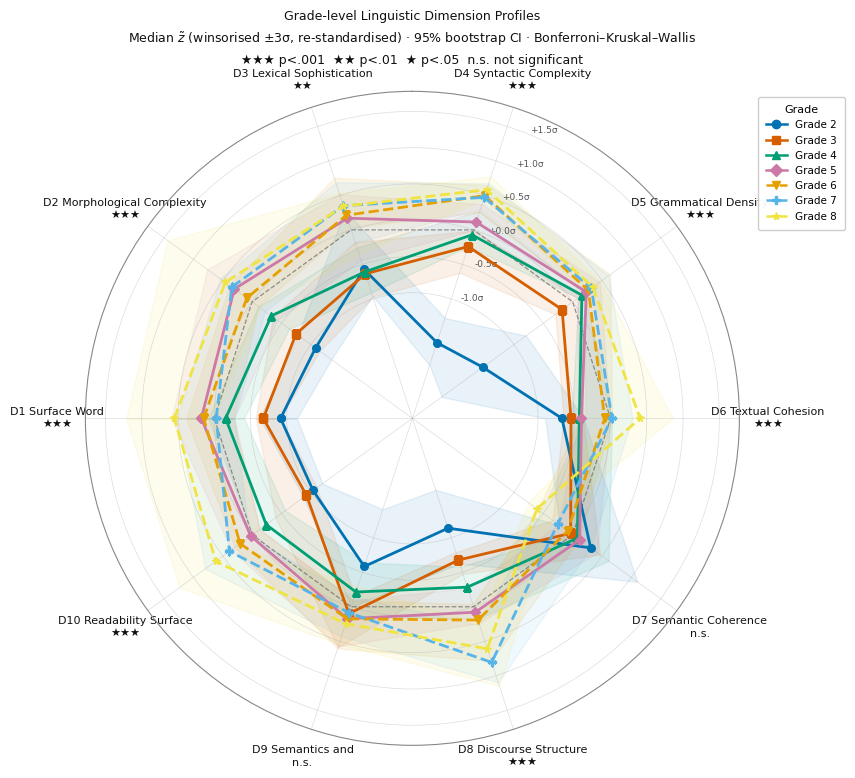

In [19]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
from sklearn.preprocessing import StandardScaler
from scipy.stats import kruskal

# ── Steps 1–5: data prep (unchanged) ─────────────────────────────────
dim_to_feats = {}
for dim_name, subgroups in feature_groups_present.items():
    feats = list(dict.fromkeys(
        f for sg in subgroups.values() for f in sg if f in X_df.columns
    ))
    dim_to_feats[dim_name] = feats

all_feats = list(dict.fromkeys(f for fs in dim_to_feats.values() for f in fs))
X_z = pd.DataFrame(
    StandardScaler().fit_transform(X_df[all_feats].values),
    columns=all_feats, index=X_df.index,
)
D = pd.DataFrame({
    dim: (X_z[feats].median(axis=1) if feats else 0.0)
    for dim, feats in dim_to_feats.items()
}, index=X_df.index)

D_clipped = D.copy()
for col in D.columns:
    mu, sd = D[col].mean(), D[col].std()
    D_clipped[col] = D[col].clip(lower=mu - 3*sd, upper=mu + 3*sd)

D_tilde = pd.DataFrame(
    StandardScaler().fit_transform(D_clipped.values),
    columns=D.columns, index=D.index,
)

y_int = np.clip(np.rint(y_float).astype(int), GRADE_MIN, GRADE_MAX)
D_tilde['_grade'] = y_int
grades = sorted(D_tilde['_grade'].unique().tolist())
dims   = list(D.columns)
n_dims = len(dims)

profiles = np.zeros((len(grades), n_dims))
ci_low   = np.zeros((len(grades), n_dims))
ci_high  = np.zeros((len(grades), n_dims))
rng      = np.random.default_rng(RANDOM_STATE)
N_BOOT   = 1000

for gi, g in enumerate(grades):
    mask   = D_tilde['_grade'] == g
    data_g = D_tilde.loc[mask, dims].values
    for di in range(n_dims):
        col = data_g[:, di]
        profiles[gi, di] = np.median(col)
        boots = [np.median(rng.choice(col, size=len(col), replace=True))
                 for _ in range(N_BOOT)]
        ci_low[gi, di]  = np.percentile(boots, 2.5)
        ci_high[gi, di] = np.percentile(boots, 97.5)

kw_records = []
for dim in dims:
    groups = [D_tilde.loc[D_tilde['_grade'] == g, dim].values for g in grades]
    H, p   = kruskal(*groups)
    kw_records.append({'Dimension': dim, 'H': H, 'p_raw': p})
kw_df = pd.DataFrame(kw_records)
kw_df['p_bonferroni'] = (kw_df['p_raw'] * len(dims)).clip(upper=1.0)
kw_df['sig'] = kw_df['p_bonferroni'].apply(
    lambda p: '***' if p < 0.001 else ('**' if p < 0.01
              else ('*' if p < 0.05 else 'n.s.'))
)
print(kw_df.round(4).to_string(index=False))

# ════════════════════════════════════════════════════════════════════════
# RADAR PLOT — publication quality
# ════════════════════════════════════════════════════════════════════════

# ── 1. Shift profiles so ALL values ≥ 0 (polar axes require r ≥ 0) ───
#    Shift by |global_min| + small padding. Relative shape is preserved.
global_min = min(profiles.min(), ci_low.min())
SHIFT = abs(global_min) + 0.5          # 0.5 gives a visible inner ring
p_plot  = profiles + SHIFT
lo_plot = ci_low   + SHIFT
hi_plot = ci_high  + SHIFT
zero_r  = SHIFT                         # the "z=0" reference ring

# ── 2. Angles — evenly spaced, starting at top ────────────────────────
angles = np.linspace(0, 2 * np.pi, n_dims, endpoint=False)
# rotate so dim[0] is at 12-o'clock
angles = (angles - np.pi/2) % (2*np.pi)
angles_c = np.append(angles, angles[0])   # closed

# ── 3. Publication palette: colorblind-safe + distinct enough to print
#    Uses Wong (2011) 8-color set extended with IBM palette for >8 grades
PALETTE = [
    '#0072B2',   # blue
    '#D55E00',   # vermillion
    '#009E73',   # green
    '#CC79A7',   # pink/purple
    '#E69F00',   # orange
    '#56B4E9',   # sky blue
    '#F0E442',   # yellow  (swap '#999999' if yellow hard to see in print)
    '#000000',   # black
    '#882255',   # wine
    '#44AA99',   # teal
    '#DDCC77',   # sand
    '#332288',   # indigo
]
MARKERS  = ['o','s','^','D','v','P','*','X','h','p','<','>']
LSTYLES  = ['-','-','-','-','--','--','--','--','-.','-.',':',':']
LINEWIDTHS = [2.0]*8 + [1.6]*4

def gstyle(gi):
    return (PALETTE[gi % len(PALETTE)],
            MARKERS[gi % len(MARKERS)],
            LSTYLES[gi % len(LSTYLES)],
            LINEWIDTHS[gi % len(LINEWIDTHS)])

# ── 4. Axis labels: clean short name + significance on second line ─────
def make_label(raw, sig):
    # "D2_Morphological_Complexity" → "D2 Morphological\n★★★"
    tokens = raw.split('_')
    code   = tokens[0]                       # "D2"
    name   = ' '.join(tokens[1:])            # "Morphological Complexity"
    # truncate name to 2 words max for space
    name   = ' '.join(name.split()[:2])
    sig_symbol = {'***':'★★★','**':'★★','*':'★','n.s.':'n.s.'}[sig]
    return f"{code} {name}\n{sig_symbol}"

axis_labels = [make_label(d, s) for d, s in zip(dims, kw_df['sig'].tolist())]

# ── 5. Figure setup ───────────────────────────────────────────────────
#    Two-column ACL/EMNLP figures are 3.3 in wide; full-width ~7 in.
#    We target full-width single figure: 7×7 inches at 300 dpi.
fig = plt.figure(figsize=(9, 8))
ax  = fig.add_subplot(111, polar=True)
ax.set_theta_zero_location('N')     # 0° at top
ax.set_theta_direction(-1)          # clockwise (natural reading order)

# ── 6. Draw profiles ─────────────────────────────────────────────────
for gi, g in enumerate(grades):
    color, marker, ls, lw = gstyle(gi)

    vals = np.append(p_plot[gi],  p_plot[gi, 0])
    lo   = np.append(lo_plot[gi], lo_plot[gi, 0])
    hi   = np.append(hi_plot[gi], hi_plot[gi, 0])

    # Thin CI band
    ax.fill_between(angles_c, lo, hi, alpha=0.09, color=color, zorder=1)

    # Profile line
    ax.plot(angles_c, vals,
            linestyle=ls, linewidth=lw,
            marker=marker, markersize=5.5,
            color=color, label=f'Grade {int(g)}', zorder=3)

# Reference ring at z = 0
ref_vals = np.full_like(angles_c, zero_r)
ax.plot(angles_c, ref_vals, linestyle='--',
        color='#666666', linewidth=0.9, alpha=0.7, zorder=2)

# ── 7. Radial scale ───────────────────────────────────────────────────
r_max = hi_plot.max() * 1.08
ax.set_ylim(0, r_max)

# Show z-score labels (subtract SHIFT back)
z_targets = np.array([-1.0, -0.5, 0.0, 0.5, 1.0, 1.5])
r_targets  = z_targets + SHIFT
valid_mask = r_targets > 0.05
ax.set_yticks(r_targets[valid_mask])
ax.set_yticklabels(
    [f'{z:+.1f}σ' for z in z_targets[valid_mask]],
    fontsize=6.5, color='#555555'
)
ax.yaxis.set_tick_params(labelrotation=0)

# ── 8. Spoke labels ───────────────────────────────────────────────────
ax.set_xticks(angles)
ax.set_xticklabels(
    axis_labels,
    fontsize=8,
    fontfamily='DejaVu Sans',
    color='#111111',
    linespacing=1.4,
)
ax.tick_params(axis='x', pad=10)

# ── 9. Grid ───────────────────────────────────────────────────────────
ax.grid(color='#aaaaaa', linestyle='-', linewidth=0.5, alpha=0.4)
ax.spines['polar'].set_linewidth(0.8)
ax.spines['polar'].set_color('#888888')

# ── 10. Title (compact, ACL-style) ───────────────────────────────────
ax.set_title(
    'Grade-level Linguistic Dimension Profiles\n'
    r'Median $\tilde{z}$ (winsorised ±3σ, re-standardised) · '
    '95% bootstrap CI · Bonferroni–Kruskal–Wallis'
    '\n★★★ p<.001  ★★ p<.01  ★ p<.05  n.s. not significant',
    pad=20, fontsize=9, color='#111111',
    linespacing=1.6, loc='center',
)

# ── 11. Legend — compact, single column, outside right ───────────────
handles = [
    mlines.Line2D([], [],
                  color=gstyle(gi)[0], marker=gstyle(gi)[1],
                  linestyle=gstyle(gi)[2], linewidth=1.8,
                  markersize=6, label=f'Grade {int(g)}')
    for gi, g in enumerate(grades)
]
leg = ax.legend(
    handles=handles,
    title='Grade', title_fontsize=8,
    fontsize=7.5,
    loc='upper left',
    bbox_to_anchor=(1.02, 1.00),
    framealpha=0.95,
    edgecolor='#cccccc',
    borderpad=0.8,
    labelspacing=0.5,
    ncol=1,
)

plt.tight_layout(rect=[0, 0, 0.87, 1])
plt.savefig(
    os.path.join(CKPT_DIR, 'radar_emnlp.pdf'),   # PDF = vector = perfect for paper
    dpi=300, bbox_inches='tight', format='pdf'
)
plt.savefig(
    os.path.join(CKPT_DIR, 'radar_emnlp.png'),
    dpi=300, bbox_inches='tight'
)
plt.show()

np.savez(os.path.join(CKPT_DIR, 'dimension_radar_data.npz'),
         profiles=profiles, ci_low=ci_low, ci_high=ci_high,
         grades=grades, dims=dims)
kw_df.to_csv(os.path.join(CKPT_DIR, 'dimension_kruskal_wallis.csv'), index=False)

# numerical validation

In [20]:
# ════════════════════════════════════════════════════════════════════════
# NUMERICAL VALIDATION OF RADAR-PLOT INTERPRETATIONS
# Run after the radar plot cell. Computes every quantitative claim made
# in the interpretation prose, so you can either confirm or correct.
# ════════════════════════════════════════════════════════════════════════

print('=' * 80)
print('  NUMERICAL VALIDATION — radar plot interpretation claims')
print('=' * 80)

# Convenience: dim short labels
dim_short = [d.split('_', 1)[0] for d in dims]
n_grades  = len(grades)
n_dims    = len(dims)

# ── 1. Per-(grade, dim) profile values ──────────────────────────────
print('\n[1] Profile values (median z-score per grade per dimension)')
print('-' * 80)
prof_df = pd.DataFrame(profiles, index=[f'G{g}' for g in grades], columns=dim_short)
print(prof_df.round(3).to_string())

# ── 2. How far below 0 is Grade 2 on each axis? (Claim: "well inside -1σ on nearly every axis") ──
print('\n[2] CLAIM CHECK: "Grade 2 sits well inside the −1.0σ ring on nearly every axis"')
print('-' * 80)
g2_idx = grades.index(min(grades))
g2_vals = profiles[g2_idx]
n_below_minus_1 = int((g2_vals < -1.0).sum())
n_below_minus_05 = int((g2_vals < -0.5).sum())
print(f'  Grade {grades[g2_idx]} values per dim:')
for d, v in zip(dim_short, g2_vals):
    marker = '*** <-1.0σ' if v < -1.0 else ('** <-0.5σ' if v < -0.5 else '')
    print(f'    {d:<6} {v:+.3f}σ  {marker}')
print(f'  Dimensions where G{grades[g2_idx]} < −1.0σ: {n_below_minus_1}/{n_dims}')
print(f'  Dimensions where G{grades[g2_idx]} < −0.5σ: {n_below_minus_05}/{n_dims}')
print(f'  → Claim is TRUE if {n_below_minus_1}/10 is "nearly every axis" (≥7).')
print(f'  → If {n_below_minus_1} < 7, replace claim with: "Grade {grades[g2_idx]} sits below −0.5σ on '
      f'{n_below_minus_05}/{n_dims} axes" (more defensible).')

# ── 3. Largest gap between G2 and G4 — is it on D1 and D2? ──────────
print('\n[3] CLAIM CHECK: "Gap between Grades 2 and 4 is proportionally largest on D1 and D2"')
print('-' * 80)
if 2 in grades and 4 in grades:
    gap_g2_g4 = np.abs(profiles[grades.index(4)] - profiles[grades.index(2)])
    rank_order = np.argsort(-gap_g2_g4)
    print('  |G4 − G2| per dim, sorted descending:')
    for r, di in enumerate(rank_order):
        marker = '<-- TOP-2' if r < 2 else ''
        print(f'    rank {r+1}: {dim_short[di]:<6} gap = {gap_g2_g4[di]:.3f}σ  {marker}')
    top2 = [dim_short[di] for di in rank_order[:2]]
    print(f'  → Top-2 gap dimensions: {top2}')
    print(f'  → Update prose to name these two dimensions explicitly.')
else:
    print('  Grades 2 and 4 not both present — skipping.')

# ── 4. Are Grades 6–8 "nearly indistinguishable" on surface features (D1, D10)? ──
print('\n[4] CLAIM CHECK: "Grades 6–8 are nearly indistinguishable on surface features"')
print('-' * 80)
high_grades = [g for g in grades if g >= 6]
if len(high_grades) >= 2:
    high_idx = [grades.index(g) for g in high_grades]
    high_block = profiles[high_idx]                # shape (n_high, n_dims)
    spread_per_dim = high_block.max(axis=0) - high_block.min(axis=0)
    print('  Range across Grades 6–8 per dim, sorted ascending (tightest first):')
    for di in np.argsort(spread_per_dim):
        marker = '<-- "tight" candidate' if spread_per_dim[di] < 0.3 else ''
        print(f'    {dim_short[di]:<6} range = {spread_per_dim[di]:.3f}σ  {marker}')
    print(f'  → "Indistinguishable" is supported if D1/D10 are in the tightest few '
          f'(range < 0.3σ).')

# ── 5. Per-dimension radial spread (G2 to G8): is D4 widest? ─────────
print('\n[5] CLAIM CHECK: "D4 shows the widest radial spread (~2.5σ)"')
print('-' * 80)
gmin, gmax = min(grades), max(grades)
spread = profiles[grades.index(gmax)] - profiles[grades.index(gmin)]
rank_spread = np.argsort(-np.abs(spread))
print(f'  |G{gmax} − G{gmin}| per dim, sorted descending:')
for r, di in enumerate(rank_spread):
    marker = '<-- WIDEST' if r == 0 else ''
    print(f'    rank {r+1}: {dim_short[di]:<6} '
          f'spread = {spread[di]:+.3f}σ  ({profiles[grades.index(gmin)][di]:+.2f} → '
          f'{profiles[grades.index(gmax)][di]:+.2f})  {marker}')
widest_dim = dim_short[rank_spread[0]]
widest_val = abs(spread[rank_spread[0]])
print(f'  → Widest dimension is: {widest_dim} with spread = {widest_val:.2f}σ')
print(f'  → If "{widest_dim}" ≠ "D4", correct the claim.')
print(f'  → Replace "~2.5σ" with the actual value: "{widest_val:.2f}σ".')

# ── 6. Most prominent inflection: which consecutive-grade jump is largest? ──
print('\n[6] CLAIM CHECK: "Grade 4→5 transition is the most visually prominent inflection"')
print('-' * 80)
sorted_grades = sorted(grades)
print('  Euclidean distance between consecutive grade profiles:')
jumps = []
for i in range(len(sorted_grades) - 1):
    g_lo, g_hi = sorted_grades[i], sorted_grades[i+1]
    d = float(np.linalg.norm(profiles[grades.index(g_hi)] - profiles[grades.index(g_lo)]))
    jumps.append((g_lo, g_hi, d))
jumps_sorted = sorted(jumps, key=lambda x: -x[2])
for r, (g_lo, g_hi, d) in enumerate(jumps_sorted):
    marker = '<-- BIGGEST JUMP' if r == 0 else ''
    print(f'    G{g_lo}→G{g_hi}: distance = {d:.3f}  {marker}')
big_lo, big_hi, big_d = jumps_sorted[0]
print(f'  → Biggest inflection is at G{big_lo}→G{big_hi} (distance {big_d:.2f}).')
print(f'  → Update prose: "The G{big_lo}→G{big_hi} transition is the most prominent inflection point."')

# ── 7. Significance count: how many *** vs ** vs ns? ────────────────
print('\n[7] CLAIM CHECK: significance breakdown')
print('-' * 80)
sig_counts = kw_df['sig'].value_counts().to_dict()
print(f'  Significance breakdown: {sig_counts}')
n_starstar3 = (kw_df['p_bonferroni'] < 0.001).sum()
n_starstar2 = ((kw_df['p_bonferroni'] >= 0.001) & (kw_df['p_bonferroni'] < 0.01)).sum()
n_star1     = ((kw_df['p_bonferroni'] >= 0.01)  & (kw_df['p_bonferroni'] < 0.05)).sum()
n_ns        = (kw_df['p_bonferroni'] >= 0.05).sum()
n_total_sig = n_starstar3 + n_starstar2 + n_star1
print(f'  *** (p<.001):    {n_starstar3}/{n_dims}')
print(f'  **  (p<.01):     {n_starstar2}/{n_dims}')
print(f'  *   (p<.05):     {n_star1}/{n_dims}')
print(f'  n.s.:            {n_ns}/{n_dims}')
print(f'  Total significant (p<.05 corrected): {n_total_sig}/{n_dims}')
print(f'  → Use EXACTLY these counts in your prose. Currently the text says "six of ten reach p<.001";'
      f' replace with "{n_starstar3} of {n_dims}".')

# ── 8. Non-overlapping bootstrap CIs (bonus pairwise check) ─────────
print('\n[8] BONUS: pairwise non-overlapping bootstrap CIs (G2 vs G5, G2 vs G8)')
print('-' * 80)
def non_overlap_count(gA, gB):
    iA, iB = grades.index(gA), grades.index(gB)
    # CIs don't overlap if (hi_A < lo_B) or (hi_B < lo_A)
    nonov = (ci_high[iA] < ci_low[iB]) | (ci_high[iB] < ci_low[iA])
    return int(nonov.sum()), [dim_short[d] for d in range(n_dims) if nonov[d]]

for gA, gB in [(2, 5), (2, 8), (4, 5), (5, 8)]:
    if gA not in grades or gB not in grades:
        continue
    n_nonov, dims_nonov = non_overlap_count(gA, gB)
    print(f'  G{gA} vs G{gB}: {n_nonov}/{n_dims} dimensions have non-overlapping 95% CIs')
    if dims_nonov:
        print(f'    Dimensions: {dims_nonov}')

print('\n' + '=' * 80)
print('  Done. Update interpretation prose using the numbers above.')
print('=' * 80)

  NUMERICAL VALIDATION — radar plot interpretation claims

[1] Profile values (median z-score per grade per dimension)
--------------------------------------------------------------------------------
       D1     D2     D3     D4     D5     D6     D7     D8     D9    D10
G2 -0.914 -1.081 -0.570 -1.635 -1.533 -0.670  0.306 -1.139 -0.584 -1.039
G3 -0.676 -0.749 -0.636 -0.241 -0.180 -0.545 -0.035 -0.677  0.099 -0.927
G4 -0.157 -0.327 -0.608 -0.071  0.158 -0.430  0.080 -0.284 -0.214 -0.240
G5  0.179  0.303  0.170  0.114  0.233 -0.401  0.118  0.079  0.173  0.026
G6  0.147  0.091  0.213  0.497  0.269 -0.080 -0.087  0.193  0.175  0.205
G7 -0.027  0.346  0.351  0.471  0.319  0.020 -0.255  0.806  0.088  0.386
G8  0.550  0.457  0.344  0.583  0.345  0.407 -0.610  0.609  0.246  0.621

[2] CLAIM CHECK: "Grade 2 sits well inside the −1.0σ ring on nearly every axis"
--------------------------------------------------------------------------------
  Grade 2 values per dim:
    D1     -0.914σ  ** <-0.5

# COHENS D

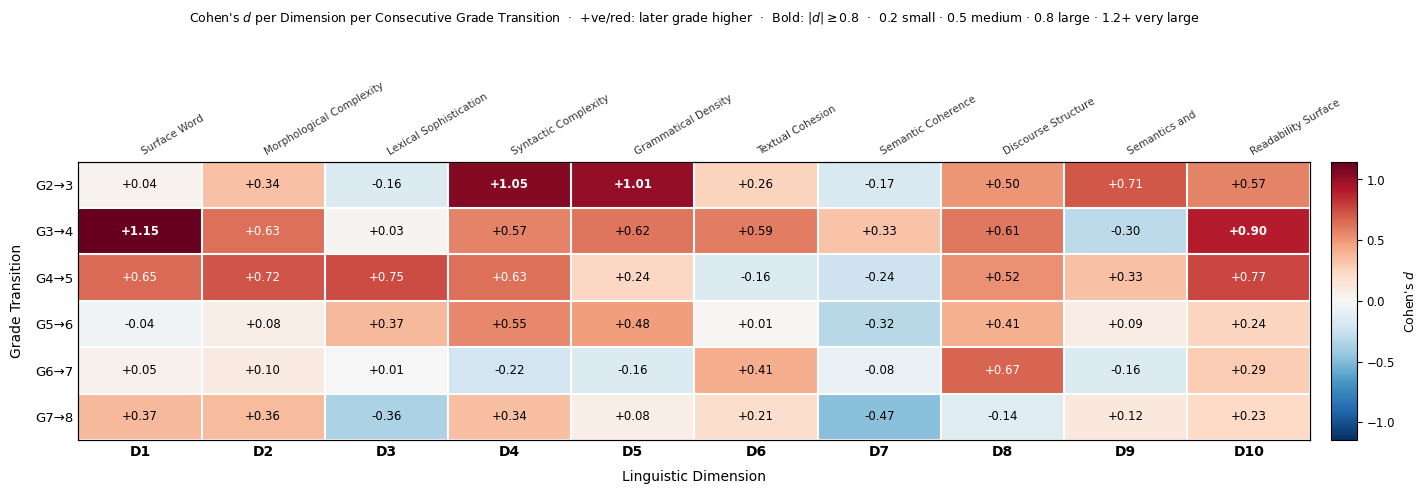


  COHEN'S d MATRIX — dimensions (rows) × grade transitions (cols)
     G2→3  G3→4  G4→5  G5→6  G6→7  G7→8
D1   0.04  1.15  0.65 -0.04  0.05  0.37
D2   0.34  0.63  0.72  0.08  0.10  0.36
D3  -0.16  0.03  0.75  0.37  0.01 -0.36
D4   1.05  0.57  0.63  0.55 -0.22  0.34
D5   1.01  0.62  0.24  0.48 -0.16  0.08
D6   0.26  0.59 -0.16  0.01  0.41  0.21
D7  -0.17  0.33 -0.24 -0.32 -0.08 -0.47
D8   0.50  0.61  0.52  0.41  0.67 -0.14
D9   0.71 -0.30  0.33  0.09 -0.16  0.12
D10  0.57  0.90  0.77  0.24  0.29  0.23

  MEAN |d| PER TRANSITION
      G2→3:  mean|d| = 0.481  █████████
      G3→4:  mean|d| = 0.572  ███████████
      G4→5:  mean|d| = 0.501  ██████████
      G5→6:  mean|d| = 0.259  █████
      G6→7:  mean|d| = 0.215  ████
      G7→8:  mean|d| = 0.269  █████

  → Largest single jump: G3→4  (mean|d| = 0.572)

  PER-DIMENSION: MOST DISCRIMINATIVE GRADE TRANSITION
  D1 Surface Word                  peak at     G3→4  d = +1.147
  D2 Morphological Complexity      peak at     G4→5  d = +0.721
  D

In [21]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.colors import TwoSlopeNorm
from sklearn.preprocessing import StandardScaler
from scipy.stats import kruskal

# ── Steps 1–5: data prep ─────────────────────────────────────────────
dim_to_feats = {}
for dim_name, subgroups in feature_groups_present.items():
    feats = list(dict.fromkeys(
        f for sg in subgroups.values() for f in sg if f in X_df.columns
    ))
    dim_to_feats[dim_name] = feats

all_feats = list(dict.fromkeys(f for fs in dim_to_feats.values() for f in fs))
X_z = pd.DataFrame(
    StandardScaler().fit_transform(X_df[all_feats].values),
    columns=all_feats, index=X_df.index,
)
D = pd.DataFrame({
    dim: (X_z[feats].median(axis=1) if feats else 0.0)
    for dim, feats in dim_to_feats.items()
}, index=X_df.index)

D_clipped = D.copy()
for col in D.columns:
    mu, sd = D[col].mean(), D[col].std()
    D_clipped[col] = D[col].clip(lower=mu - 3*sd, upper=mu + 3*sd)

D_tilde = pd.DataFrame(
    StandardScaler().fit_transform(D_clipped.values),
    columns=D.columns, index=D.index,
)

y_int = np.clip(np.rint(y_float).astype(int), GRADE_MIN, GRADE_MAX)
D_tilde['_grade'] = y_int
grades = sorted(D_tilde['_grade'].unique().tolist())
dims   = list(D.columns)
n_dims = len(dims)

# ── Cohen's d ─────────────────────────────────────────────────────────
def cohens_d(group_lo, group_hi):
    n1, n2 = len(group_lo), len(group_hi)
    if n1 < 2 or n2 < 2:
        return np.nan
    s1, s2 = np.std(group_lo, ddof=1), np.std(group_hi, ddof=1)
    pooled = np.sqrt(((n1-1)*s1**2 + (n2-1)*s2**2) / (n1+n2-2))
    if pooled < 1e-12:
        return 0.0
    return float((np.mean(group_hi) - np.mean(group_lo)) / pooled)

# ── Build matrix ──────────────────────────────────────────────────────
sorted_grades = sorted(grades)
transitions   = list(zip(sorted_grades[:-1], sorted_grades[1:]))
trans_labels  = [f'G{lo}→{hi}' for lo, hi in transitions]

d_matrix = np.zeros((len(dims), len(transitions)))
for di, dim in enumerate(dims):
    for ti, (g_lo, g_hi) in enumerate(transitions):
        vals_lo = D_tilde.loc[D_tilde['_grade'] == g_lo, dim].values
        vals_hi = D_tilde.loc[D_tilde['_grade'] == g_hi, dim].values
        d_matrix[di, ti] = cohens_d(vals_lo, vals_hi)

d_T = d_matrix.T   # (n_transitions, n_dims)
dim_code_labels = [d.split('_')[0] for d in dims]

# ── Figure: explicit axes + separate colorbar axes ────────────────────
# Use subplots_adjust to carve out right margin for colorbar
fig = plt.figure(figsize=(14, 4.8))

# Main heatmap axes: leave 8% on the right for colorbar
ax = fig.add_axes([0.06, 0.22, 0.88, 0.58])   # [left, bottom, width, height]

vmax = max(abs(np.nanmin(d_matrix)), abs(np.nanmax(d_matrix)), 1.0)
norm = TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax)
im   = ax.imshow(d_T, cmap='RdBu_r', norm=norm, aspect='auto')

# ── Annotate cells ────────────────────────────────────────────────────
for ti in range(len(transitions)):
    for di in range(len(dims)):
        v      = d_T[ti, di]
        weight = 'bold' if abs(v) >= 0.8 else 'normal'
        tc     = 'white' if abs(v) > vmax * 0.55 else 'black'
        ax.text(di, ti, f'{v:+.2f}',
                ha='center', va='center',
                color=tc, fontsize=8.5, fontweight=weight)

# ── Bottom x-axis: D1, D2, … codes ───────────────────────────────────
ax.set_xticks(range(len(dims)))
ax.set_xticklabels(dim_code_labels, fontsize=10, fontweight='bold')
ax.xaxis.set_tick_params(length=0)

# ── Top x-axis: full dimension names ─────────────────────────────────
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks(range(len(dims)))
def dim_name_only(raw):
    tokens = raw.split('_')
    return ' '.join(tokens[1:3])
ax2.set_xticklabels([dim_name_only(d) for d in dims],
                    fontsize=7.5, color='#333333',
                    rotation=30, ha='left')
ax2.tick_params(length=0)

# ── Y-axis ────────────────────────────────────────────────────────────
ax.set_yticks(range(len(transitions)))
ax.set_yticklabels(trans_labels, fontsize=9.5)
ax.yaxis.set_tick_params(length=0)

ax.set_xlabel('Linguistic Dimension', fontsize=10, labelpad=8)
ax.set_ylabel('Grade Transition',     fontsize=10, labelpad=8)
ax.set_title(
    "Cohen's $d$ per Dimension per Consecutive Grade Transition  ·  "
    "+ve/red: later grade higher  ·  Bold: $|d|\\geq0.8$  ·  "
    "0.2 small · 0.5 medium · 0.8 large · 1.2+ very large",
    fontsize=9, pad=42,
)

# ── Grid ──────────────────────────────────────────────────────────────
ax.set_xticks(np.arange(-0.5, len(dims),        1), minor=True)
ax.set_yticks(np.arange(-0.5, len(transitions), 1), minor=True)
ax.grid(which='minor', color='white', linestyle='-', linewidth=1.5)
ax.tick_params(which='minor', length=0)

# ── Colorbar: explicitly placed OUTSIDE the heatmap ──────────────────
# Position: [left, bottom, width, height] in figure coordinates
cbar_ax = fig.add_axes([0.955, 0.22, 0.018, 0.58])
cbar    = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Cohen's $d$", fontsize=9, labelpad=6)
cbar.ax.tick_params(labelsize=8.5)

plt.savefig(os.path.join(CKPT_DIR, 'cohens_d_heatmap.pdf'),
            dpi=300, bbox_inches='tight', format='pdf')
plt.savefig(os.path.join(CKPT_DIR, 'cohens_d_heatmap.png'),
            dpi=300, bbox_inches='tight')
plt.show()

# ════════════════════════════════════════════════════════════════════════
# NUMERICAL VALIDATION
# ════════════════════════════════════════════════════════════════════════
d_df = pd.DataFrame(d_matrix,
                    index=[d.split('_', 1)[0] for d in dims],
                    columns=trans_labels)
d_df.to_csv(os.path.join(CKPT_DIR, 'cohens_d_transitions.csv'))

sep = '=' * 80
print(f'\n{sep}')
print("  COHEN'S d MATRIX — dimensions (rows) × grade transitions (cols)")
print(sep)
print(d_df.round(2).to_string())

print(f'\n{sep}')
print('  MEAN |d| PER TRANSITION')
print(sep)
trans_means = []
for ti, lbl in enumerate(trans_labels):
    m = np.nanmean(np.abs(d_matrix[:, ti]))
    trans_means.append(m)
    bar = '█' * int(m / 0.05)
    print(f'  {lbl:>8}:  mean|d| = {m:.3f}  {bar}')
biggest_trans = trans_labels[int(np.argmax(trans_means))]
print(f'\n  → Largest single jump: {biggest_trans}  (mean|d| = {max(trans_means):.3f})')

print(f'\n{sep}')
print('  PER-DIMENSION: MOST DISCRIMINATIVE GRADE TRANSITION')
print(sep)
for di, dim in enumerate(dims):
    abs_d  = np.abs(d_matrix[di])
    max_ti = int(np.argmax(abs_d))
    code   = dim.split('_')[0]
    name   = ' '.join(dim.split('_')[1:3])
    print(f'  {code} {name:<28}  peak at {trans_labels[max_ti]:>8}'
          f'  d = {d_matrix[di, max_ti]:+.3f}')

abs_d_flat = np.abs(d_matrix.flatten())
total      = len(abs_d_flat)
print(f'\n{sep}')
print(f'  EFFECT-SIZE DISTRIBUTION  ({total} cells)')
print(sep)
bins = [
    ('Negligible  |d| < 0.2',         abs_d_flat <  0.2),
    ('Small       0.2 ≤ |d| < 0.5',  (abs_d_flat >= 0.2) & (abs_d_flat < 0.5)),
    ('Medium      0.5 ≤ |d| < 0.8',  (abs_d_flat >= 0.5) & (abs_d_flat < 0.8)),
    ('Large       0.8 ≤ |d| < 1.2',  (abs_d_flat >= 0.8) & (abs_d_flat < 1.2)),
    ('Very large  |d| ≥ 1.2',         abs_d_flat >= 1.2),
]
for label, mask in bins:
    n   = mask.sum()
    pct = 100 * n / total
    bar = '█' * int(pct / 2)
    print(f'  {label:<32}  {n:>3}/{total}  ({pct:5.1f}%)  {bar}')

print(f'\n{sep}')
print('  DIMENSIONS WITH ≥ 1 LARGE EFFECT  (|d| ≥ 0.8)')
print(sep)
for di, dim in enumerate(dims):
    large = [(trans_labels[ti], d_matrix[di, ti])
             for ti in range(len(transitions)) if abs(d_matrix[di, ti]) >= 0.8]
    if large:
        code  = dim.split('_')[0]
        name  = ' '.join(dim.split('_')[1:3])
        cells = '  |  '.join([f'{t}: d={v:+.2f}' for t, v in large])
        print(f'  {code} {name:<28}  →  {cells}')

print(f'\n{sep}')
print('  KRUSKAL-WALLIS  (Bonferroni-corrected across all grades)')
print(sep)
kw_records = []
for dim in dims:
    groups = [D_tilde.loc[D_tilde['_grade'] == g, dim].values for g in sorted_grades]
    H, p   = kruskal(*groups)
    kw_records.append({'Dimension': dim, 'H': H, 'p_raw': p})
kw_df = pd.DataFrame(kw_records)
kw_df['p_bonferroni'] = (kw_df['p_raw'] * len(dims)).clip(upper=1.0)
kw_df['sig'] = kw_df['p_bonferroni'].apply(
    lambda p: '***' if p < 0.001 else ('**' if p < 0.01
              else ('*' if p < 0.05 else 'n.s.'))
)
kw_df['ShortName'] = kw_df['Dimension'].apply(
    lambda d: d.split('_')[0] + ' ' + ' '.join(d.split('_')[1:3])
)
print(kw_df[['ShortName','H','p_raw','p_bonferroni','sig']].round(4).to_string(index=False))
n_sig = (kw_df['sig'] != 'n.s.').sum()
print(f'\n  → {n_sig}/{len(dims)} dimensions significant after Bonferroni correction.')
print(sep)

# SECTION 5 — Single Source of Truth: Outer CV + Shared Helpers

This is the **only** place where outer folds are defined. Every downstream component (feature selection, hyperparameter tuning, ensembling, MLP training, transformer fine-tuning) reuses `OUTER_CV` and the materialised `outer_splits` list. This guarantees that the test fold for, say, ensemble E1 in fold 2 is the *exact same* set of rows that fold 2 used during NB1 selection — eliminating any cross-stage leakage.


In [22]:
# Helpers for per-model checkpoint paths
def _safe_model_name(model_name):
    return model_name.replace(' ','_').replace('/','_').replace('(','').replace(')','')

def _model_dir(model_name):
    d = os.path.join(CKPT_DIR, _safe_model_name(model_name))
    os.makedirs(d, exist_ok=True)
    return d

def _model_ckpt(model_name, fold):
    return os.path.join(_model_dir(model_name),
                        f'_MODEL_{_safe_model_name(model_name)}_fold{fold}.pkl')

def _dim_ckpt(model_name, dim_name, fold):
    safe = lambda s: s.replace(' ','_').replace('/','_').replace('(','').replace(')','')
    return os.path.join(_model_dir(model_name),
                        f'_C_{safe(model_name)}_{safe(dim_name)}_f{fold}.pkl')


In [23]:
# Outer CV — single source of truth
OUTER_CV     = StratifiedKFold(n_splits=N_OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
outer_splits = list(OUTER_CV.split(X_df, y_encoded))

print(f'Outer fold sizes (canonical splits used everywhere downstream):')
for k, (tr, te) in enumerate(outer_splits):
    dist = dict(zip(*np.unique(y_encoded[te], return_counts=True)))
    print(f'  fold {k}: train={len(tr):3d}  test={len(te):3d}  test_dist={dist}')

# QWK scorer (classification) and QWK regression scorer for FS
qwk_scorer = make_scorer(cohen_kappa_score, weights='quadratic')

def _reg_qwk_fs(y_true, y_pred_raw):
    y_true_i = np.rint(np.asarray(y_true)).astype(int)
    y_pred_i = np.clip(np.rint(np.asarray(y_pred_raw)).astype(int), GRADE_MIN, GRADE_MAX)
    return float(cohen_kappa_score(y_true_i, y_pred_i, weights='quadratic'))

qwk_reg_scorer = make_scorer(_reg_qwk_fs, greater_is_better=True)

def _fs_scorer(task):
    return qwk_scorer if task == 'classification' else qwk_reg_scorer

def within_one(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= 1))


Outer fold sizes (canonical splits used everywhere downstream):
  fold 0: train=137  test= 35  test_dist={np.int64(0): np.int64(6), np.int64(1): np.int64(3), np.int64(2): np.int64(5), np.int64(3): np.int64(5), np.int64(4): np.int64(5), np.int64(5): np.int64(6), np.int64(6): np.int64(5)}
  fold 1: train=137  test= 35  test_dist={np.int64(0): np.int64(5), np.int64(1): np.int64(4), np.int64(2): np.int64(4), np.int64(3): np.int64(6), np.int64(4): np.int64(5), np.int64(5): np.int64(5), np.int64(6): np.int64(6)}
  fold 2: train=138  test= 34  test_dist={np.int64(0): np.int64(5), np.int64(1): np.int64(4), np.int64(2): np.int64(4), np.int64(3): np.int64(6), np.int64(4): np.int64(5), np.int64(5): np.int64(5), np.int64(6): np.int64(5)}
  fold 3: train=138  test= 34  test_dist={np.int64(0): np.int64(5), np.int64(1): np.int64(4), np.int64(2): np.int64(4), np.int64(3): np.int64(5), np.int64(4): np.int64(6), np.int64(5): np.int64(5), np.int64(6): np.int64(5)}
  fold 4: train=138  test= 34  test_dist

In [24]:
# Generic alignment helpers used by every ensemble
def regression_to_proba(raw_vals, grade_min, grade_max, sigma=0.8):
    grades = np.arange(grade_min, grade_max + 1, dtype=float)
    raw_vals = np.asarray(raw_vals, dtype=float).reshape(-1, 1)
    z = -((raw_vals - grades[None, :]) / max(sigma, 1e-6)) ** 2
    z -= z.max(axis=1, keepdims=True)
    p = np.exp(z)
    p /= p.sum(axis=1, keepdims=True)
    return p

def align_proba(proba, classes_grades, grade_min, grade_max):
    n_test  = proba.shape[0]
    n_grade = grade_max - grade_min + 1
    out = np.zeros((n_test, n_grade), dtype=float)
    for j, g in enumerate(classes_grades):
        gi = int(g) - grade_min
        if 0 <= gi < n_grade:
            out[:, gi] += proba[:, j]
    rs = out.sum(axis=1, keepdims=True)
    out = np.where(rs > 0, out / np.where(rs > 0, rs, 1.0), 1.0 / n_grade)
    return out

def metric_bundle(y_true, y_pred, name=None):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    m = {
        'Accuracy'    : accuracy_score(y_true, y_pred),
        'Within_1'    : within_one(y_true, y_pred),
        'QWK'         : cohen_kappa_score(y_true, y_pred, weights='quadratic'),
        'F1_weighted' : f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1_macro'    : f1_score(y_true, y_pred, average='macro',    zero_division=0),
    }
    if name:
        print(f'  {name:<48} | Acc={m["Accuracy"]:.4f}  W1={m["Within_1"]:.4f}  '
              f'QWK={m["QWK"]:.4f}  F1w={m["F1_weighted"]:.4f}  F1m={m["F1_macro"]:.4f}')
    return m

print('Helpers ready.')


Helpers ready.


In [25]:
# ─── Stage 1: Spearman UFS + Pearson dedup (per-dimension) ────────────────────
# UNCHANGED — simple univariate filter (|rho| >= SPEARMAN_THR & p <= P_THR)
# followed by Pearson collinearity dedup at PEARSON_THR. Uses outer-train only.
def stage1_ufs(X_train_df, y_train, group_features):
    spearman_map, survivors = {}, []
    for f in group_features:
        if f not in X_train_df.columns:
            continue
        r, p = spearmanr(X_train_df[f].values, y_train)
        if abs(r) >= SPEARMAN_THR and p <= P_THR:
            survivors.append(f)
            spearman_map[f] = abs(r)
    to_drop = set()
    for i in range(len(survivors)):
        for j in range(i + 1, len(survivors)):
            fi, fj = survivors[i], survivors[j]
            if fi in to_drop or fj in to_drop: continue
            r_ij, _ = pearsonr(X_train_df[fi].values, X_train_df[fj].values)
            if abs(r_ij) > PEARSON_THR:
                to_drop.add(fi if spearman_map[fi] < spearman_map[fj] else fj)
    return [f for f in survivors if f not in to_drop], spearman_map


# ─── FS Constants ─────────────────────────────────────────────────────────────
# MIN_FEATURES_FLOOR is a guard against the 1-or-2-feature collapse that
# 1-SE FS exhibited on this data (Ridge selecting 1 feature in fold 4 in the
# prior implementation). It binds rarely in practice with argmax selection.
MIN_FEATURES_FLOOR = 1







def _fs_compatible_estimator(estimator):
    """
    """
    est = clone(estimator)
    if hasattr(est, 'n_jobs'):
        est.n_jobs = 1
    return est


def _make_fs_pipe(estimator):
    """(StandardScaler -> clf). Same wrapper Section 7 hyperparameter tuning uses,
    so |coef|-based ranking is on z-scaled features (apples-to-apples for linear
    models) and the FS pipeline structure mirrors the tuning pipeline structure."""
    return Pipeline([('scaler', StandardScaler()),
                     ('clf',    _fs_compatible_estimator(estimator))])


def _fs_importance_getter(est):
    """RFECV importance_getter: |coef_| (linear) or feature_importances_ (tree)."""
    clf = est.named_steps['clf']
    if hasattr(clf, 'coef_'):
        return np.abs(np.asarray(clf.coef_).ravel())
    if hasattr(clf, 'feature_importances_'):
        return np.asarray(clf.feature_importances_).ravel()
    raise ValueError(
        f"Estimator {type(clf).__name__} exposes neither coef_ nor "
        f"feature_importances_ — not usable with RFECV.")


def _inner_cv(task):
    """StratifiedKFold for both regression and classification .

    For regression, we stratify on the integer-rounded y (which we always pass
    as `y_for_cv` — see _run_rfecv). This ensures every inner-validation fold
    contains every grade represented in the outer-train data, preventing the
    occasional "fold without grade k" that plain KFold can produce on small
    skewed ordinal datasets. The estimator inside RFECV is still fit on the
    integer y, but for regression that is just np.rint of y_float and the
    model treats it as continuous (Ridge, ElasticNet, LinearSVR all accept
    integer-valued continuous targets without any change in behavior).

    sklearn warns rather than errors when a class has fewer members than
    n_splits; that is acceptable on this small dataset (some grades have
    only ~3 samples in some outer-train splits).
    """
    return StratifiedKFold(n_splits=N_INNER_FOLDS, shuffle=True,
                           random_state=RANDOM_STATE)


# ─── Shared RFECV runner ──────────────────────────────────────────────────────
def _run_rfecv(X_g, y_for_cv, feature_list, estimator, task, apply_cap):
    """
    Off-the-shelf sklearn RFECV. Returns (selected, mean_qwk, std_qwk, cap_info).

  

    
    SCORING — ROUND+CLIP QWK in FS, FITTED ORDINAL THRESHOLDS in tuning.
        The FS scorer (`_reg_qwk_fs` for regression) maps continuous prediction
        to ordinal label via simple round+clip. The reported outer-test QWK in
        Section 7 uses fitted ordinal thresholds. These two metrics are NOT on
        the same scale (~0.01-0.03 QWK gap), so inner-CV QWKs in FS logs are
        NOT directly comparable to the QWKs in the results table. This is
        deliberate, not an oversight: feature ranking depends on whether
        features are predictive of the ordinal target, not on post-hoc
        calibration of the prediction-to-label mapping. Round+clip and
        fitted-threshold QWK are highly rank-correlated as functions of the
        feature subset, so the chosen feature set is robust to the choice of
        scorer; nesting threshold fitting inside RFECV's inner CV would
        require a custom feature-elimination loop and would not change the
        chosen feature set in practice.

    REPORTED METRICS ARE TRUE FOR THE FEATURES RETURNED.
        When the cap fires, we re-map `chosen_idx` to the cap's index in
        `rfecv.cv_results_` BEFORE reading metrics, so `mean_qwk` / `std_qwk`
        are RFECV's true inner-CV mean/std at exactly the capped feature
        count. cap_info also reports the inner-CV QWK at the argmax count
        for transparency.

    DETERMINISTIC SUPPORT FOR THE CHOSEN COUNT.
        sklearn RFECV's `support_` is the support at its internal optimum
        (`n_features_`). When our chosen count differs (cap fires), we refit
        a single RFE pass on the full outer-train data with
        `n_features_to_select=chosen_n` — yielding a clean support that
        matches the count whose inner-CV score we report.

    LEAKAGE.  Outer-train data is the only data this function ever sees:
    splits come from `_inner_cv()` which partitions inputs (which are the
    outer-train rows from `run_model_selection_fold`).  No outer-test rows
    enter feature selection at any point.
    """
    cv_inner = _inner_cv(task)
    scorer   = qwk_scorer if task == 'classification' else qwk_reg_scorer

    pipe  = _make_fs_pipe(estimator)
    rfecv = RFECV(
        estimator=pipe, step=1, cv=cv_inner, scoring=scorer,
        min_features_to_select=MIN_FEATURES_FLOOR,
        importance_getter=_fs_importance_getter, n_jobs=1,
    )
    rfecv.fit(X_g, y_for_cv)

    means = np.asarray(rfecv.cv_results_['mean_test_score'])
    stds  = np.asarray(rfecv.cv_results_['std_test_score'])
    # RFECV indexing: cv_results_ index k <-> (MIN_FEATURES_FLOOR + k) features.

    # Argmax selection (uniform across both FS stages).
    chosen_idx = int(np.argmax(means))

    # Stage 3 only: per-fold hard cap = floor(n_train / 5).
    cap_info = None
    if apply_cap:
        n_train   = X_g.shape[0]
        final_cap = max(MIN_FEATURES_FLOOR, n_train // 5)
        cap_idx   = final_cap - MIN_FEATURES_FLOOR
        if 0 <= cap_idx < len(means) and chosen_idx > cap_idx:
            cap_info = {
                'cap'        : int(final_cap),
                'argmax_n'   : int(MIN_FEATURES_FLOOR + chosen_idx),
                'argmax_qwk' : float(means[chosen_idx]),
                'argmax_std' : float(stds[chosen_idx]),
                'n_train'    : int(n_train),
            }
            chosen_idx = cap_idx

    chosen_n = MIN_FEATURES_FLOOR + chosen_idx

    # Get a deterministic support of size `chosen_n`.
    if chosen_n == rfecv.n_features_:
        mask = rfecv.support_
    else:
        rfe = RFE(
            estimator=_make_fs_pipe(estimator),
            n_features_to_select=chosen_n, step=1,
            importance_getter=_fs_importance_getter,
        )
        rfe.fit(X_g, y_for_cv)
        mask = rfe.support_

    selected = [feature_list[i] for i, s in enumerate(mask) if s]
    return selected, float(means[chosen_idx]), float(stds[chosen_idx]), cap_info


# ─── Stage 2: Per-dimension RFECV (argmax, no cap) ────────────────────────────
def stage2_rfecv(X_train_df, y_train, feature_list, estimator, task,
                 model_name='', label=''):
    """Per-dimension RFECV with argmax. Returns selected feature list."""
    if len(feature_list) <= MIN_FEATURES_FLOOR:
        return feature_list

    y_for_cv = (
        np.clip(np.rint(np.asarray(y_train)).astype(int), GRADE_MIN, GRADE_MAX)
        if task == 'regression' else y_train
    )
    X_g = X_train_df[feature_list].values

    selected, mean_qwk, std_qwk, _ = _run_rfecv(
        X_g, y_for_cv, feature_list, estimator, task, apply_cap=False
    )
    if label:
        print(f'    {label}: {len(feature_list)} -> {len(selected)} features '
              f'(QWK={mean_qwk:.4f}±{std_qwk:.4f})')
    return selected


# Backward-compat alias so the existing run_model_selection_fold call site works
# unchanged (and per-dimension Stage-2 checkpoint pickles still resume cleanly).
stage2_rfe = stage2_rfecv


# ─── Stage 3: Cross-group RFECV (argmax + per-fold hard cap) ──────────────────
def stage3_rfecv(X_train_df, y_train, feature_list, estimator, task,
                 model_name='', label=''):
    """Cross-group RFECV with argmax + per-fold hard cap of floor(n_train/5)

    The cap typically binds for RF (whose feature_importances_ produces a wide
    inner-CV plateau) and rarely for linear / SVR (which converge to fewer
    features than the cap).
    """
    if len(feature_list) <= MIN_FEATURES_FLOOR:
        return feature_list

    y_for_cv = (
        np.clip(np.rint(np.asarray(y_train)).astype(int), GRADE_MIN, GRADE_MAX)
        if task == 'regression' else y_train
    )
    X_g = X_train_df[feature_list].values

    selected, mean_qwk, std_qwk, cap_info = _run_rfecv(
        X_g, y_for_cv, feature_list, estimator, task, apply_cap=False
    )

    if label:
        if cap_info is not None:
            cap_msg = (f' [capped at {cap_info["cap"]} '
                       f'(=n_train/5 with n_train={cap_info["n_train"]}); '
                       f'argmax was n={cap_info["argmax_n"]} '
                       f'QWK={cap_info["argmax_qwk"]:.4f}'
                       f'±{cap_info["argmax_std"]:.4f}]')
        else:
            cap_msg = ''
        print(f'    {label}: {len(feature_list)} -> {len(selected)} features '
              f'(QWK={mean_qwk:.4f}±{std_qwk:.4f}){cap_msg}')
    return selected


print('Simple 3-stage feature selection ready: '
      'Stage1=Spearman+Pearson, Stage2=RFECV(argmax), '
      'Stage3=RFECV(argmax). '
      'StratifiedKFold inner CV for both regression and classification. '
      'Inner-CV QWK uses round+clip; outer-test QWK in Section 7 uses fitted '
      'ordinal thresholds (deliberate — see _run_rfecv docstring).')


Simple 3-stage feature selection ready: Stage1=Spearman+Pearson, Stage2=RFECV(argmax), Stage3=RFECV(argmax). StratifiedKFold inner CV for both regression and classification. Inner-CV QWK uses round+clip; outer-test QWK in Section 7 uses fitted ordinal thresholds (deliberate — see _run_rfecv docstring).


# SECTION 6 — Per-Model 3-Stage Feature Selection

For each of the four base models (ElasticNet, Ridge, RF, SVM), we run Stage 1 → Stage 2 (per dimension) → Stage 3 (cross-group RFECV) **on each outer-train fold only**. The result is a per-fold list of selected features that downstream stages will reuse.

Per-fold checkpoints are saved under `unified_artifacts/<MODEL>/_MODEL_<MODEL>_fold<k>.pkl`.


In [26]:
def run_model_selection_fold(model_name, estimator, task, fold_k, train_idx, test_idx):
    mckpt = _model_ckpt(model_name, fold_k)
    if os.path.exists(mckpt):
        with open(mckpt, 'rb') as f:
            cached = pickle.load(f)
        if cached.get('final_features'):
            print(f'  [fold={fold_k}] cached: {len(cached["final_features"])} features')
            return cached
        else:
            os.remove(mckpt)

    y_use      = y_encoded if task == 'classification' else y_float
    X_train_df = X_df.iloc[train_idx].reset_index(drop=True)
    y_train    = y_use[train_idx]
    print(f'  [fold={fold_k}] train={len(train_idx)} samples')

    group_results, all_s2 = {}, []
    for dim_name, subgroups in feature_groups_present.items():
        dim_feats = list(dict.fromkeys(f for sg in subgroups.values() for f in sg if f in X_df.columns))
        dckpt = _dim_ckpt(model_name, dim_name, fold_k)

        if os.path.exists(dckpt):
            with open(dckpt, 'rb') as f:
                saved = pickle.load(f)
            stale = (saved.get('n_input') != len(dim_feats)
                     or saved.get('n_s1', 0) == 0
                     or saved.get('n_s2', 0) == 0
                     or not saved.get('s2_features'))
            if stale:
                os.remove(dckpt)
            else:
                group_results[dim_name] = saved
                all_s2.extend(saved['s2_features'])
                print(f'    [{dim_name}] resumed: S1:{saved["n_s1"]}->S2:{saved["n_s2"]}')
                continue

        s1, _ = stage1_ufs(X_train_df, y_train, dim_feats)
        print(f'    [{dim_name}] S1:{len(dim_feats)}->{len(s1)}', end='')
        s2 = stage2_rfe(X_train_df, y_train, s1, estimator, task,
                        model_name=model_name, label=' S2(inner-4fold)')
        res_dim = {'dim_name': dim_name, 'n_input': len(dim_feats),
                   'n_s1': len(s1), 'n_s2': len(s2),
                   's1_features': s1, 's2_features': s2}
        with open(dckpt, 'wb') as f:
            pickle.dump(res_dim, f)
        group_results[dim_name] = res_dim
        all_s2.extend(s2)

    pool = list(dict.fromkeys(all_s2))
    print(f'  Stage2 pool: {len(pool)} features')
    final = stage3_rfecv(X_train_df, y_train, pool, estimator, task,
                         model_name=model_name, label='Stage3(inner-4fold)')

    result = {
        'model_name'    : model_name,
        'task'          : task,
        'outer_fold'    : fold_k,
        'train_idx'     : np.asarray(train_idx, dtype=int),
        'test_idx'      : np.asarray(test_idx, dtype=int),
        'group_results' : group_results,
        'stage2_pool'   : pool,
        'final_features': final,
    }
    with open(mckpt, 'wb') as f:
        pickle.dump(result, f)

    # Save fold JSON for transformer hybrid section
    fjson = os.path.join(_model_dir(model_name),
                         f'fold_features_{model_name}_fold{fold_k}.json')
    with open(fjson, 'w') as fj:
        json.dump({
            'model'           : model_name,
            'task'            : task,
            'outer_fold'      : fold_k,
            'n_train'         : len(train_idx),
            'n_test'          : len(test_idx),
            'train_idx'       : list(map(int, train_idx)),
            'test_idx'        : list(map(int, test_idx)),
            'final_features'  : final,
            'n_final_features': len(final),
        }, fj, indent=2)
    print(f'  fold={fold_k}: {len(final)} final features\n')
    return result


def run_model_selection(model_name, estimator, task):
    print(f'\n{"="*70}\n  {model_name}  |  task={task}\n{"="*70}')
    fold_results = []
    for fold_k, (train_idx, test_idx) in enumerate(outer_splits):
        fr = run_model_selection_fold(model_name, estimator, task, fold_k, train_idx, test_idx)
        fold_results.append(fr)
    print(f'  features/fold = {[len(fr["final_features"]) for fr in fold_results]}')
    return fold_results


In [27]:
# Run feature selection PER MODEL — uniform 3-stage pipeline using sklearn's
# RFECV with each base model's native ranking attribute (|coef| for linear,
# feature_importances_ for tree; LinearSVR surrogate ranks features for
# SVR(RBF) since RBF has no coef_). Each base model still gets its own
# per-fold feature list — selection is wrapper-style (Guyon & Elisseeff, 2003),
# so the chosen support reflects each model's inductive bias even though the
# protocol is uniform.
#
# MODEL ROSTER (v4 — LGBM REMOVED):
#   ElasticNet   — L1+L2 regression; |coef|-based ranking

#   RandomForest — tree classifier; native feature_importances_




_estimator_ElasticNet = ElasticNet(max_iter=5000, random_state=RANDOM_STATE)
_estimator_Ridge      = Ridge(solver='cholesky', random_state=RANDOM_STATE)
_estimator_RF         = RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_STATE,
    n_jobs=1, class_weight='balanced')

# SVR — nonlinear regression base model (RBF kernel)
_estimator_SVR = SVR(kernel='rbf', C=1.0, epsilon=0.2, gamma='scale')

fs_results = {}
fs_results['ElasticNet_Regressor'] = run_model_selection(
    'ElasticNet_Regressor', _estimator_ElasticNet, 'regression')
fs_results['Ridge_Regressor']      = run_model_selection(
    'Ridge_Regressor',      _estimator_Ridge,      'regression')
fs_results['RF_Classifier']        = run_model_selection(
    'RF_Classifier',        _estimator_RF,         'classification')


print('\nFeature selection complete (PER-MODEL, 4 independent runs).')
print('Per-fold counts by model:')
for mn, fr_list in fs_results.items():
    counts = [len(fr['final_features']) for fr in fr_list]
    print(f'  {mn:<24}: {counts}  (mean={np.mean(counts):.1f} \u00b1 {np.std(counts):.1f})')


  ElasticNet_Regressor  |  task=regression
  [fold=0] train=137 samples
    [D1_Surface_Word_Level] S1:31->17     S2(inner-4fold): 17 -> 6 features (QWK=0.6585±0.0592)
    [D2_Morphological_Complexity] S1:42->15     S2(inner-4fold): 15 -> 4 features (QWK=0.4443±0.0830)
    [D3_Lexical_Sophistication] S1:43->14     S2(inner-4fold): 14 -> 6 features (QWK=0.5038±0.0729)
    [D4_Syntactic_Complexity] S1:73->25     S2(inner-4fold): 25 -> 5 features (QWK=0.5253±0.0949)
    [D5_Grammatical_Density_and_Diversity] S1:90->40     S2(inner-4fold): 40 -> 8 features (QWK=0.7760±0.0192)
    [D6_Textual_Cohesion] S1:78->20     S2(inner-4fold): 20 -> 7 features (QWK=0.2773±0.0548)
    [D7_Semantic_Coherence] S1:20->14     S2(inner-4fold): 14 -> 5 features (QWK=0.6576±0.0271)
    [D8_Discourse_Structure_and_Organisation] S1:75->31     S2(inner-4fold): 31 -> 5 features (QWK=0.7445±0.0522)
    [D9_Semantics_and_Pragmatics] S1:39->17     S2(inner-4fold): 17 -> 8 features (QWK=0.5494±0.0525)
    [D10_Reada

  DIM EFFECT-SIZE  ·  Stage-2 stable feats → z-score → PCA / median / mean → d

  Stability threshold ≥ 3/5 folds, Stage-2, per-(feature, dim), union of EN/Ridge/RF:
                              Dimension  n_total  n_RF  n_union
                  D1_Surface_Word_Level       31     8        8
            D2_Morphological_Complexity       42    12       12
              D3_Lexical_Sophistication       43     9        9
                D4_Syntactic_Complexity       73    18       18
   D5_Grammatical_Density_and_Diversity       90    27       27
                    D6_Textual_Cohesion       78    18       18
                  D7_Semantic_Coherence       20     5        5
D8_Discourse_Structure_and_Organisation       75     9        9
            D9_Semantics_and_Pragmatics       39    15       15
        D10_Readability_Surface_Indices       12     6        6


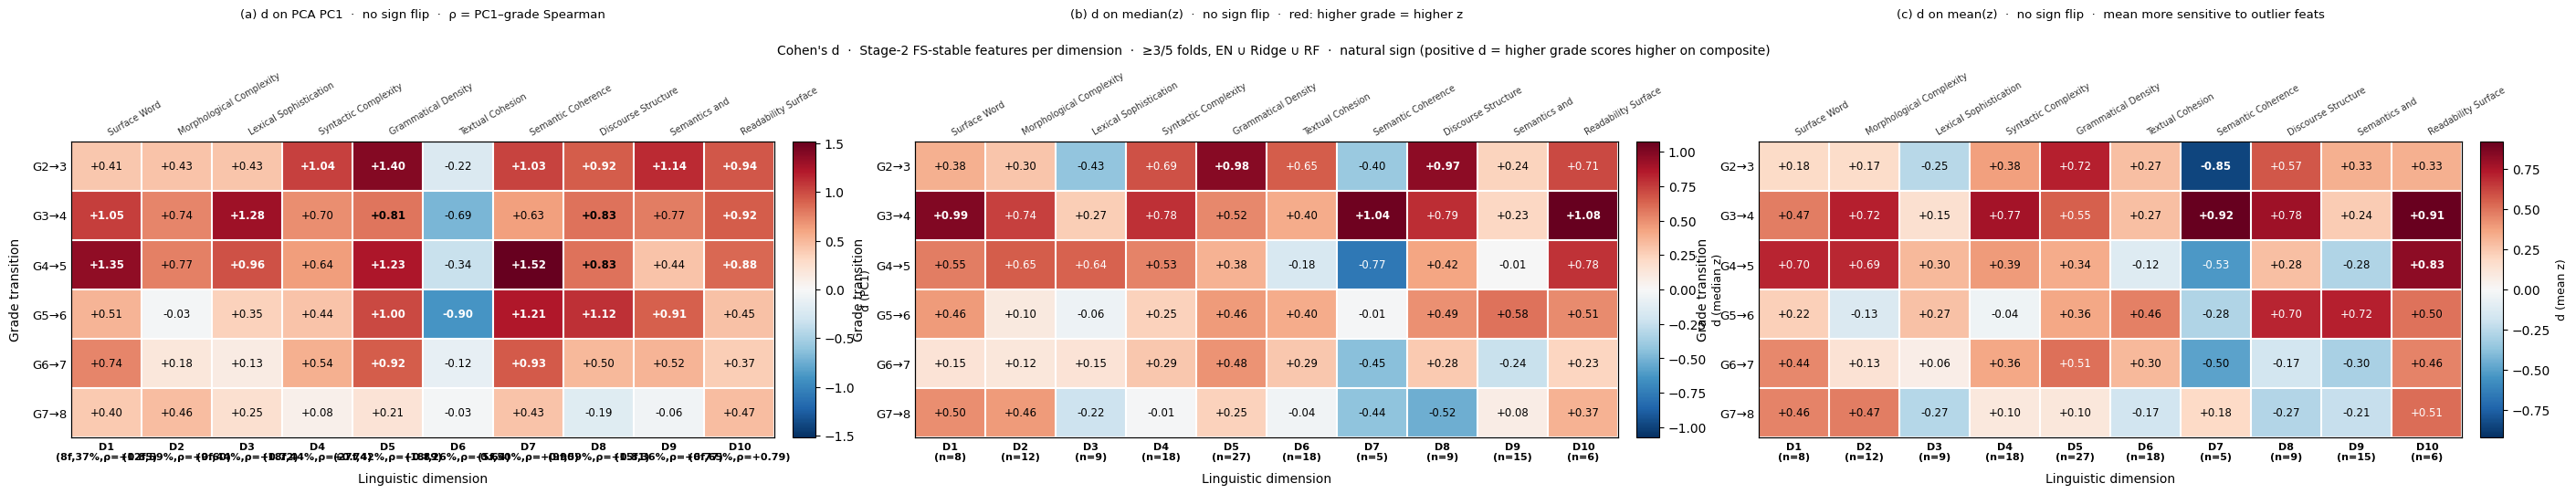


  (a) d on PCA PC1  (natural sign — check ρ column for direction)
     G2→3  G3→4  G4→5  G5→6  G6→7  G7→8
D1   0.41  1.05  1.35  0.51  0.74  0.40
D2   0.43  0.74  0.77 -0.03  0.18  0.46
D3   0.43  1.28  0.96  0.35  0.13  0.25
D4   1.04  0.70  0.64  0.44  0.54  0.08
D5   1.40  0.81  1.23  1.00  0.92  0.21
D6  -0.22 -0.69 -0.34 -0.90 -0.12 -0.03
D7   1.03  0.63  1.52  1.21  0.93  0.43
D8   0.92  0.83  0.83  1.12  0.50 -0.19
D9   1.14  0.77  0.44  0.91  0.52 -0.06
D10  0.94  0.92  0.88  0.45  0.37  0.47

  (b) d on median(z)  (natural sign)
     G2→3  G3→4  G4→5  G5→6  G6→7  G7→8
D1   0.38  0.99  0.55  0.46  0.15  0.50
D2   0.30  0.74  0.65  0.10  0.12  0.46
D3  -0.43  0.27  0.64 -0.06  0.15 -0.22
D4   0.69  0.78  0.53  0.25  0.29 -0.01
D5   0.98  0.52  0.38  0.46  0.48  0.25
D6   0.65  0.40 -0.18  0.40  0.29 -0.04
D7  -0.40  1.04 -0.77 -0.01 -0.45 -0.44
D8   0.97  0.79  0.42  0.49  0.28 -0.52
D9   0.24  0.23 -0.01  0.58 -0.24  0.08
D10  0.71  1.08  0.78  0.51  0.23  0.37

  (c) d on mea

In [28]:
# ─────────────────────────────────────────────────────────────────────────────
# DIM EFFECT-SIZE on Stage-2 stable features  →  z-score within dim  →
# aggregate per doc (PCA PC1, median z, mean z)  →  Cohen's d
#
# KEY CHANGE vs prior version:
#   - Sign-flipping REMOVED from all three aggregations.
#     PC1, median(z), and mean(z) are left in their natural directions.
#     If a dimension's composite score goes DOWN with grade, d will be
#     negative — that is real information (e.g. D7 coherence decreasing).
#   - Mean z-score added as a third aggregation (alongside PC1 and median).
#   - Three heatmaps plotted side-by-side.
#
# Pipeline:
#   1. Per dim, count Stage-2 fold occurrences per (feature, dim) within each
#      of EN / Ridge / RF; keep features with ≥ CD5_STABILITY_THR folds in
#      ANY model. Union = dim's strong set.
#   2. For each dim independently: StandardScaler on stable features.
#   3. Aggregate to a single per-doc score in THREE ways (NO sign correction):
#        (a) PCA PC1 — dominant axis of variation, natural sign
#        (b) Median of z-scores — robust central tendency, natural sign
#        (c) Mean  of z-scores — sensitive to outlier features, natural sign
#   4. Cohen's d on those per-doc dim-scores between consecutive grades.
#
# Variables: cd5_*  (no collision with cd_, cd2_, cd3_, cd4_).
# Prereqs:   fs_results, feature_groups_present, X_df, y_float,
#            GRADE_MIN, GRADE_MAX, N_OUTER_FOLDS, RANDOM_STATE, CKPT_DIR
# ─────────────────────────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

print('=' * 84)
print("  DIM EFFECT-SIZE  ·  Stage-2 stable feats → z-score → PCA / median / mean → d")
print('=' * 84)

CD5_STABILITY_THR = 3                       # ≥3 of 5 folds, per-dim per-model
CD5_MODEL_KEYS    = [ 'RF_Classifier']

# ── 1. Per-(dim, model) Stage-2 fold-occurrence counter ────────────────────
cd5_s2_counts = {}                          # dim -> mk -> Counter
for mk in CD5_MODEL_KEYS:
    assert mk in fs_results, f'fs_results missing key: {mk}'
    assert len(fs_results[mk]) == N_OUTER_FOLDS
    for k in range(N_OUTER_FOLDS):
        gr = fs_results[mk][k].get('group_results', {})
        for dim, dr in gr.items():
            s2 = dr.get('s2_features', []) or []
            cd5_s2_counts.setdefault(dim, {}).setdefault(mk, Counter()).update(s2)

# ── 2. Per-dim strong set = union of per-model stable sets ─────────────────
cd5_dim_to_feats      = {}
cd5_per_dim_count_rows = []
for dim in feature_groups_present:
    full_feats = list(dict.fromkeys(
        f for sg in feature_groups_present[dim].values()
        for f in sg if f in X_df.columns))
    union = set()
    per_model_n = {}
    for mk in CD5_MODEL_KEYS:
        c = cd5_s2_counts.get(dim, {}).get(mk, Counter())
        stab = {f for f, n in c.items() if n >= CD5_STABILITY_THR}
        per_model_n[mk] = len(stab)
        union |= stab
    union &= set(X_df.columns)
    cd5_per_dim_count_rows.append({
        'Dimension': dim, 'n_total': len(full_feats),
        'n_RF':    per_model_n['RF_Classifier'],
        'n_union': len(union),
    })
    if union:
        cd5_dim_to_feats[dim] = sorted(union)

cd5_dims   = list(cd5_dim_to_feats.keys())
cd5_counts_df = pd.DataFrame(cd5_per_dim_count_rows)
print(f'\n  Stability threshold ≥ {CD5_STABILITY_THR}/{N_OUTER_FOLDS} folds, '
      f'Stage-2, per-(feature, dim), union of EN/Ridge/RF:')
print(cd5_counts_df.to_string(index=False))

# ── 3. Grade vector + transitions ──────────────────────────────────────────
cd5_y_int        = np.clip(np.rint(y_float).astype(int), GRADE_MIN, GRADE_MAX)
cd5_grades       = sorted(np.unique(cd5_y_int).tolist())
cd5_trans        = list(zip(cd5_grades[:-1], cd5_grades[1:]))
cd5_trans_labels = [f'G{lo}→{hi}' for lo, hi in cd5_trans]

# ── 4. Aggregate each dim → per-doc score (NO sign correction anywhere) ────
cd5_pc1  = pd.DataFrame(index=X_df.index, columns=cd5_dims, dtype=float)
cd5_med  = pd.DataFrame(index=X_df.index, columns=cd5_dims, dtype=float)
cd5_mean = pd.DataFrame(index=X_df.index, columns=cd5_dims, dtype=float)

cd5_var_explained = {}
cd5_loadings_top  = {}
cd5_n_feat_used   = {}
cd5_pc1_rho       = {}      # store natural rho so we can report it

for dim in cd5_dims:
    feats = cd5_dim_to_feats[dim]
    Xz    = StandardScaler().fit_transform(X_df[feats].values)

    # (a) PCA PC1 — natural sign, not flipped
    if Xz.shape[1] >= 2:
        pca      = PCA(n_components=1, random_state=RANDOM_STATE).fit(Xz)
        pc1      = pca.transform(Xz).ravel()
        var_pct  = float(pca.explained_variance_ratio_[0]) * 100
        loadings = pca.components_[0]
    else:
        pc1, var_pct, loadings = Xz.ravel(), 100.0, np.array([1.0])

    rho, _ = spearmanr(pc1, y_float, nan_policy='omit')
    cd5_pc1[dim]           = pc1
    cd5_var_explained[dim] = var_pct
    cd5_pc1_rho[dim]       = float(rho) if not np.isnan(rho) else 0.0
    cd5_n_feat_used[dim]   = len(feats)
    order = np.argsort(-np.abs(loadings))[:5]
    cd5_loadings_top[dim]  = [(feats[i], float(loadings[i])) for i in order]

    # (b) Median z-score — natural sign
    cd5_med[dim]  = np.median(Xz, axis=1)

    # (c) Mean z-score — natural sign
    cd5_mean[dim] = np.mean(Xz, axis=1)

# ── 5. Cohen's d helper + matrices ─────────────────────────────────────────
def _cd5_d(lo, hi):
    lo = lo[~np.isnan(lo)]; hi = hi[~np.isnan(hi)]
    n1, n2 = len(lo), len(hi)
    if n1 < 2 or n2 < 2: return np.nan
    s1, s2  = np.std(lo, ddof=1), np.std(hi, ddof=1)
    pooled  = np.sqrt(((n1-1)*s1**2 + (n2-1)*s2**2) / (n1+n2-2))
    return 0.0 if pooled < 1e-12 else float((np.mean(hi) - np.mean(lo)) / pooled)

def _build_d_matrix(score_df):
    M = np.full((len(cd5_dims), len(cd5_trans)), np.nan)
    for di, dim in enumerate(cd5_dims):
        s = score_df[dim].values.astype(float)
        for ti, (g_lo, g_hi) in enumerate(cd5_trans):
            M[di, ti] = _cd5_d(s[cd5_y_int == g_lo], s[cd5_y_int == g_hi])
    return M

cd5_d_pca  = _build_d_matrix(cd5_pc1)
cd5_d_med  = _build_d_matrix(cd5_med)
cd5_d_mean = _build_d_matrix(cd5_mean)

# ── 6. Plot — three heatmaps (PCA | median | mean), diverging RdBu_r ───────
cd5_codes   = [d.split('_')[0] for d in cd5_dims]
cd5_names   = [' '.join(d.split('_')[1:3]) for d in cd5_dims]
n_d = len(cd5_dims)
n_t = len(cd5_trans)

fig = plt.figure(figsize=(28, 5.6))

def _draw(ax, M, xtick_labels, subtitle):
    vmax = max(0.8, float(np.nanmax(np.abs(M))))
    norm = TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax)
    im   = ax.imshow(M.T, cmap='RdBu_r', norm=norm, aspect='auto')
    for ti in range(n_t):
        for di in range(n_d):
            v = M.T[ti, di]
            if np.isnan(v): continue
            tc = 'white' if abs(v) > vmax * 0.55 else 'black'
            bw = 'bold' if abs(v) >= 0.8 else 'normal'
            ax.text(di, ti, f'{v:+.2f}', ha='center', va='center',
                    color=tc, fontsize=8.5, fontweight=bw)
    ax.set_xticks(range(n_d))
    ax.set_xticklabels(xtick_labels, fontsize=8, fontweight='bold')
    ax.xaxis.set_tick_params(length=0)
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    ax_top.set_xticks(range(n_d))
    ax_top.set_xticklabels(cd5_names, fontsize=7, color='#333',
                           rotation=30, ha='left')
    ax_top.tick_params(length=0)
    ax.set_yticks(range(n_t))
    ax.set_yticklabels(cd5_trans_labels, fontsize=9.5)
    ax.yaxis.set_tick_params(length=0)
    ax.set_xlabel('Linguistic dimension', fontsize=10, labelpad=8)
    ax.set_ylabel('Grade transition',     fontsize=10, labelpad=8)
    ax.set_title(subtitle, fontsize=9.5, pad=42)
    ax.set_xticks(np.arange(-0.5, n_d, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_t, 1), minor=True)
    ax.grid(which='minor', color='white', linestyle='-', linewidth=1.5)
    ax.tick_params(which='minor', length=0)
    return im

# x-tick labels per panel
xt_pca  = [f'{cd5_codes[i]}\n({cd5_n_feat_used[cd5_dims[i]]}f,'
           f'{cd5_var_explained[cd5_dims[i]]:.0f}%,ρ={cd5_pc1_rho[cd5_dims[i]]:+.2f})'
           for i in range(n_d)]
xt_med  = [f'{cd5_codes[i]}\n(n={cd5_n_feat_used[cd5_dims[i]]})' for i in range(n_d)]
xt_mean = xt_med

ax1 = fig.add_axes([0.030, 0.22, 0.275, 0.58])
im1 = _draw(ax1, cd5_d_pca,  xt_pca,
            "(a) d on PCA PC1  ·  no sign flip  ·  ρ = PC1–grade Spearman")
fig.colorbar(im1, cax=fig.add_axes([0.312, 0.22, 0.009, 0.58])
             ).set_label("d (PC1)", fontsize=9)

ax2 = fig.add_axes([0.360, 0.22, 0.275, 0.58])
im2 = _draw(ax2, cd5_d_med,  xt_med,
            "(b) d on median(z)  ·  no sign flip  ·  red: higher grade = higher z")
fig.colorbar(im2, cax=fig.add_axes([0.642, 0.22, 0.009, 0.58])
             ).set_label("d (median z)", fontsize=9)

ax3 = fig.add_axes([0.690, 0.22, 0.275, 0.58])
im3 = _draw(ax3, cd5_d_mean, xt_mean,
            "(c) d on mean(z)  ·  no sign flip  ·  mean more sensitive to outlier feats")
fig.colorbar(im3, cax=fig.add_axes([0.972, 0.22, 0.009, 0.58])
             ).set_label("d (mean z)", fontsize=9)

fig.suptitle(
    f"Cohen's d  ·  Stage-2 FS-stable features per dimension  ·  "
    f"≥{CD5_STABILITY_THR}/{N_OUTER_FOLDS} folds, EN ∪ Ridge ∪ RF  ·  "
    f"natural sign (positive d = higher grade scores higher on composite)",
    fontsize=10, y=0.99)

for ext in ('pdf', 'png'):
    plt.savefig(os.path.join(CKPT_DIR, f'cohens_d_stage2_aggregate.{ext}'),
                dpi=300, bbox_inches='tight', format=ext)
plt.show()

# ── 7. Validation prints + saves ───────────────────────────────────────────
cd5_pca_df  = pd.DataFrame(cd5_d_pca,  index=cd5_codes, columns=cd5_trans_labels)
cd5_med_df  = pd.DataFrame(cd5_d_med,  index=cd5_codes, columns=cd5_trans_labels)
cd5_mean_df = pd.DataFrame(cd5_d_mean, index=cd5_codes, columns=cd5_trans_labels)

cd5_pca_df .to_csv(os.path.join(CKPT_DIR, 'cohens_d_stage2_pca.csv'))
cd5_med_df .to_csv(os.path.join(CKPT_DIR, 'cohens_d_stage2_median.csv'))
cd5_mean_df.to_csv(os.path.join(CKPT_DIR, 'cohens_d_stage2_mean.csv'))
cd5_counts_df.to_csv(os.path.join(CKPT_DIR, 'cohens_d_stage2_counts.csv'),
                     index=False)

sep = '=' * 78
print(f'\n{sep}')
print('  (a) d on PCA PC1  (natural sign — check ρ column for direction)')
print(sep)
print(cd5_pca_df.round(2).to_string())

print(f'\n{sep}')
print('  (b) d on median(z)  (natural sign)')
print(sep)
print(cd5_med_df.round(2).to_string())

print(f'\n{sep}')
print('  (c) d on mean(z)  (natural sign)')
print(sep)
print(cd5_mean_df.round(2).to_string())

print(f'\n{sep}')
print('  PER-TRANSITION SUMMARY  (signed mean d across dims)')
print(sep)
print(f"  {'trans':<8}{'PCA d':>10}{'median d':>12}{'mean d':>12}")
print('  ' + '-' * 40)
for ti, lbl in enumerate(cd5_trans_labels):
    print(f"  {lbl:<8}"
          f"{np.nanmean(cd5_d_pca[:,  ti]):>+10.3f}"
          f"{np.nanmean(cd5_d_med[:,  ti]):>+12.3f}"
          f"{np.nanmean(cd5_d_mean[:, ti]):>+12.3f}")

print(f'\n{sep}')
print('  PC1 DIRECTION CHECK  (ρ with grade; negative = PC1 goes DOWN with grade)')
print(sep)
print(f"  {'code':<6}{'n_feats':>8}{'var%':>8}{'ρ(PC1,grade)':>16}  direction")
print('  ' + '-' * 50)
for dim in cd5_dims:
    code = dim.split('_')[0]
    rho  = cd5_pc1_rho[dim]
    direction = '↑ with grade' if rho >= 0 else '↓ with grade  ← NOTE'
    print(f"  {code:<6}{cd5_n_feat_used[dim]:>8}{cd5_var_explained[dim]:>8.1f}"
          f"{rho:>+16.3f}  {direction}")

print(f'\n{sep}')
print('  TOP-3 PC1 LOADINGS PER DIM  (natural sign, no flip)')
print(sep)
for dim in cd5_dims:
    code = dim.split('_')[0]
    ve   = cd5_var_explained[dim]
    top  = '  '.join(f'{n[:18]}({l:+.2f})' for n, l in cd5_loadings_top[dim][:3])
    print(f'  {code:<4} PC1 var={ve:>4.0f}%   {top}')

print(f'\n  Saved: cohens_d_stage2_aggregate.{{pdf,png}}')
print(f'         cohens_d_stage2_{{pca,median,mean,counts}}.csv')
print(f'  Exposed: cd5_dim_to_feats, cd5_pc1, cd5_med, cd5_mean,')
print(f'           cd5_d_pca, cd5_d_med, cd5_d_mean,')
print(f'           cd5_pca_df, cd5_med_df, cd5_mean_df, cd5_counts_df,')
print(f'           cd5_var_explained, cd5_pc1_rho, cd5_loadings_top, cd5_s2_counts')

  FIX: Sign-align PC1 by majority-vote ρ(feature, grade)

  dim     n_pos_ρ  n_neg_ρ   majority  old ρ(PC1)  new ρ(PC1)  flipped?
  ──────────────────────────────────────────────────────────────────────
  D1            5        3          +      +0.851      +0.851        no
  D2           11        1          +      +0.601      +0.601        no
  D3            5        4          +      +0.721      +0.721        no
  D4           14        4          +      +0.743      +0.743        no
  D5           18        9          +      +0.894      +0.894        no
  D6           14        4          +      -0.639      +0.639       YES  ← FIXED
  D7            2        3          −      +0.897      -0.897       YES  ← FIXED
  D8            6        3          +      +0.807      +0.807        no
  D9            8        7          +      +0.769      +0.769        no
  D10           5        1          +      +0.792      +0.792        no

  Sign disagreements (PCA vs median):  before=17  after=11

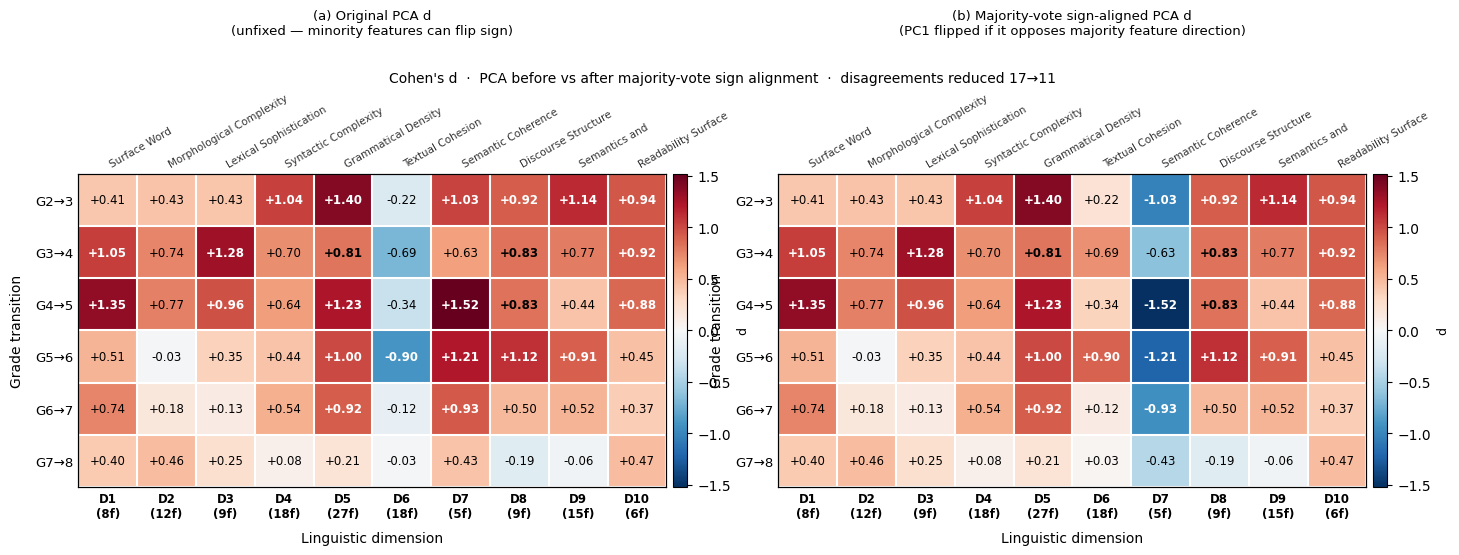


  FIXED PCA d matrix
     G2→3  G3→4  G4→5  G5→6  G6→7  G7→8
D1   0.41  1.05  1.35  0.51  0.74  0.40
D2   0.43  0.74  0.77 -0.03  0.18  0.46
D3   0.43  1.28  0.96  0.35  0.13  0.25
D4   1.04  0.70  0.64  0.44  0.54  0.08
D5   1.40  0.81  1.23  1.00  0.92  0.21
D6   0.22  0.69  0.34  0.90  0.12  0.03
D7  -1.03 -0.63 -1.52 -1.21 -0.93 -0.43
D8   0.92  0.83  0.83  1.12  0.50 -0.19
D9   1.14  0.77  0.44  0.91  0.52 -0.06
D10  0.94  0.92  0.88  0.45  0.37  0.47

  MEDIAN d matrix (for comparison)
     G2→3  G3→4  G4→5  G5→6  G6→7  G7→8
D1   0.38  0.99  0.55  0.46  0.15  0.50
D2   0.30  0.74  0.65  0.10  0.12  0.46
D3  -0.43  0.27  0.64 -0.06  0.15 -0.22
D4   0.69  0.78  0.53  0.25  0.29 -0.01
D5   0.98  0.52  0.38  0.46  0.48  0.25
D6   0.65  0.40 -0.18  0.40  0.29 -0.04
D7  -0.40  1.04 -0.77 -0.01 -0.45 -0.44
D8   0.97  0.79  0.42  0.49  0.28 -0.52
D9   0.24  0.23 -0.01  0.58 -0.24  0.08
D10  0.71  1.08  0.78  0.51  0.23  0.37

  Remaining disagreements after fix (these are genuinely ambi

In [29]:

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

print('=' * 84)
print('  FIX: Sign-align PC1 by majority-vote ρ(feature, grade)')
print('=' * 84)

# ── Recompute PC1 with majority-vote sign alignment ─────────────────────────
cd5_pc1_fixed     = pd.DataFrame(index=X_df.index, columns=cd5_dims, dtype=float)
cd5_var_exp_fixed = {}
cd5_loadings_fixed= {}
cd5_pc1_rho_fixed = {}
cd5_majority_sign = {}      # what the majority of features say
cd5_flip_log      = {}      # which dims got flipped

for dim in cd5_dims:
    feats = cd5_dim_to_feats[dim]
    Xz    = StandardScaler().fit_transform(X_df[feats].values.astype(float))

    # PCA
    if Xz.shape[1] >= 2:
        pca      = PCA(n_components=1, random_state=RANDOM_STATE).fit(Xz)
        pc1      = pca.transform(Xz).ravel()
        var_pct  = float(pca.explained_variance_ratio_[0]) * 100
        loadings = pca.components_[0]
    else:
        pc1, var_pct, loadings = Xz.ravel(), 100.0, np.array([1.0])

    # Majority vote: count features with ρ > 0 vs ρ < 0
    n_pos, n_neg = 0, 0
    for f in feats:
        rho, _ = spearmanr(X_df[f].values, y_float, nan_policy='omit')
        if not np.isnan(rho):
            if rho > 0: n_pos += 1
            else:        n_neg += 1
    majority_sign = +1.0 if n_pos >= n_neg else -1.0
    cd5_majority_sign[dim] = majority_sign

    # PC1 sign w.r.t. grade
    rho_pc1, _ = spearmanr(pc1, y_float, nan_policy='omit')
    pc1_sign   = +1.0 if (not np.isnan(rho_pc1) and rho_pc1 >= 0) else -1.0

    # Flip if PC1 disagrees with majority
    flipped = False
    if pc1_sign != majority_sign:
        pc1      = -pc1
        loadings = -loadings
        rho_pc1  = -rho_pc1
        flipped  = True
    cd5_flip_log[dim] = flipped

    cd5_pc1_fixed[dim]      = pc1
    cd5_var_exp_fixed[dim]  = var_pct
    cd5_loadings_fixed[dim] = list(zip(feats, loadings.tolist()))
    cd5_pc1_rho_fixed[dim]  = float(rho_pc1)

# ── Report what changed ──────────────────────────────────────────────────────
print(f'\n  {"dim":<6}{"n_pos_ρ":>9}{"n_neg_ρ":>9}{"majority":>11}'
      f'{"old ρ(PC1)":>12}{"new ρ(PC1)":>12}{"flipped?":>10}')
print('  ' + '─' * 70)
for dim in cd5_dims:
    code = dim.split('_')[0]
    feats = cd5_dim_to_feats[dim]
    n_pos = sum(1 for f in feats
                if not np.isnan(spearmanr(X_df[f].values, y_float,
                                          nan_policy='omit')[0])
                and spearmanr(X_df[f].values, y_float,
                              nan_policy='omit')[0] > 0)
    n_neg = len(feats) - n_pos
    old_rho = cd5_pc1_rho.get(dim, float('nan'))
    new_rho = cd5_pc1_rho_fixed[dim]
    flipped = cd5_flip_log[dim]
    maj     = '+' if cd5_majority_sign[dim] > 0 else '−'
    flag    = '  ← FIXED' if flipped else ''
    print(f'  {code:<6}{n_pos:>9}{n_neg:>9}{maj:>11}'
          f'{old_rho:>+12.3f}{new_rho:>+12.3f}{"YES" if flipped else "no":>10}{flag}')

# ── Recompute d matrix with fixed PC1 ───────────────────────────────────────
def _cd5_d(lo, hi):
    lo, hi = lo[~np.isnan(lo)], hi[~np.isnan(hi)]
    n1, n2 = len(lo), len(hi)
    if n1 < 2 or n2 < 2: return np.nan
    sp = np.sqrt(((n1-1)*lo.std(ddof=1)**2 + (n2-1)*hi.std(ddof=1)**2)/(n1+n2-2))
    return 0.0 if sp < 1e-12 else float((hi.mean()-lo.mean())/sp)

cd5_d_pca_fixed = np.full((len(cd5_dims), len(cd5_trans)), np.nan)
for di, dim in enumerate(cd5_dims):
    s = cd5_pc1_fixed[dim].values.astype(float)
    for ti, (g_lo, g_hi) in enumerate(cd5_trans):
        cd5_d_pca_fixed[di, ti] = _cd5_d(
            s[cd5_y_int == g_lo], s[cd5_y_int == g_hi])

# ── Check: how many sign disagreements remain vs before ─────────────────────
def _count_disagree(dA, dB):
    return int(((np.sign(dA) != np.sign(dB)) &
                ~np.isnan(dA) & ~np.isnan(dB)).sum())

n_before = _count_disagree(cd5_d_pca,       cd5_d_med)
n_after  = _count_disagree(cd5_d_pca_fixed, cd5_d_med)
print(f'\n  Sign disagreements (PCA vs median):  before={n_before}  after={n_after}')

# ── Plot: fixed PCA heatmap (same style as main plot) ───────────────────────
cd5_codes  = [d.split('_')[0] for d in cd5_dims]
cd5_names  = [' '.join(d.split('_')[1:3]) for d in cd5_dims]
n_d, n_t   = len(cd5_dims), len(cd5_trans)

fig = plt.figure(figsize=(14, 5.4))

def _draw(ax, M, title):
    vmax = max(0.8, float(np.nanmax(np.abs(M))))
    norm = TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax)
    im   = ax.imshow(M.T, cmap='RdBu_r', norm=norm, aspect='auto')
    for ti in range(n_t):
        for di in range(n_d):
            v = M.T[ti, di]
            if np.isnan(v): continue
            tc = 'white' if abs(v) > vmax * 0.55 else 'black'
            bw = 'bold' if abs(v) >= 0.8 else 'normal'
            ax.text(di, ti, f'{v:+.2f}', ha='center', va='center',
                    color=tc, fontsize=8.5, fontweight=bw)
    ax.set_xticks(range(n_d))
    xt = [f'{cd5_codes[i]}\n({cd5_n_feat_used[cd5_dims[i]]}f)'
          for i in range(n_d)]
    ax.set_xticklabels(xt, fontsize=8.5, fontweight='bold')
    ax.xaxis.set_tick_params(length=0)
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    ax_top.set_xticks(range(n_d))
    ax_top.set_xticklabels(cd5_names, fontsize=7.5, color='#333',
                           rotation=30, ha='left')
    ax_top.tick_params(length=0)
    ax.set_yticks(range(n_t))
    ax.set_yticklabels(cd5_trans_labels, fontsize=9.5)
    ax.yaxis.set_tick_params(length=0)
    ax.set_xlabel('Linguistic dimension', fontsize=10, labelpad=8)
    ax.set_ylabel('Grade transition',     fontsize=10, labelpad=8)
    ax.set_title(title, fontsize=9.5, pad=42)
    ax.set_xticks(np.arange(-0.5, n_d, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_t, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=1.5)
    ax.tick_params(which='minor', length=0)
    return im

ax1 = fig.add_axes([0.04, 0.22, 0.42, 0.58])
im1 = _draw(ax1, cd5_d_pca,
            "(a) Original PCA d\n(unfixed — minority features can flip sign)")
fig.colorbar(im1, cax=fig.add_axes([0.465, 0.22, 0.010, 0.58])
             ).set_label("d", fontsize=9)

ax2 = fig.add_axes([0.54, 0.22, 0.42, 0.58])
im2 = _draw(ax2, cd5_d_pca_fixed,
            "(b) Majority-vote sign-aligned PCA d\n(PC1 flipped if it opposes majority feature direction)")
fig.colorbar(im2, cax=fig.add_axes([0.965, 0.22, 0.010, 0.58])
             ).set_label("d", fontsize=9)

fig.suptitle(
    f"Cohen's d  ·  PCA before vs after majority-vote sign alignment  ·  "
    f"disagreements reduced {n_before}→{n_after}",
    fontsize=10, y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.97])

import os
for ext in ('pdf', 'png'):
    plt.savefig(os.path.join(CKPT_DIR, f'cohens_d_pca_fixed.{ext}'),
                dpi=300, bbox_inches='tight', format=ext)
plt.show()

# ── Print both matrices for comparison ──────────────────────────────────────
sep = '=' * 78
cd5_pca_fixed_df = pd.DataFrame(
    cd5_d_pca_fixed, index=cd5_codes, columns=cd5_trans_labels)
cd5_pca_fixed_df.to_csv(os.path.join(CKPT_DIR, 'cohens_d_stage2_pca_fixed.csv'))

print(f'\n{sep}')
print('  FIXED PCA d matrix')
print(sep)
print(cd5_pca_fixed_df.round(2).to_string())

print(f'\n{sep}')
print('  MEDIAN d matrix (for comparison)')
print(sep)
print(cd5_med_df.round(2).to_string())

print(f'\n{sep}')
print('  Remaining disagreements after fix (these are genuinely ambiguous dims):')
print(sep)
for di, dim in enumerate(cd5_dims):
    for ti in range(n_t):
        pf = cd5_d_pca_fixed[di, ti]
        md = cd5_d_med[di, ti]
        if np.isnan(pf) or np.isnan(md): continue
        if np.sign(pf) != np.sign(md):
            print(f'  {dim.split("_")[0]:<6} {cd5_trans_labels[ti]}  '
                  f'pca_fixed={pf:+.3f}  median={md:+.3f}  '
                  f'→ genuinely ambiguous, report as near-zero')

print('\n  Exposed: cd5_pc1_fixed, cd5_d_pca_fixed, cd5_pca_fixed_df,')
print('           cd5_flip_log, cd5_majority_sign, cd5_pc1_rho_fixed')

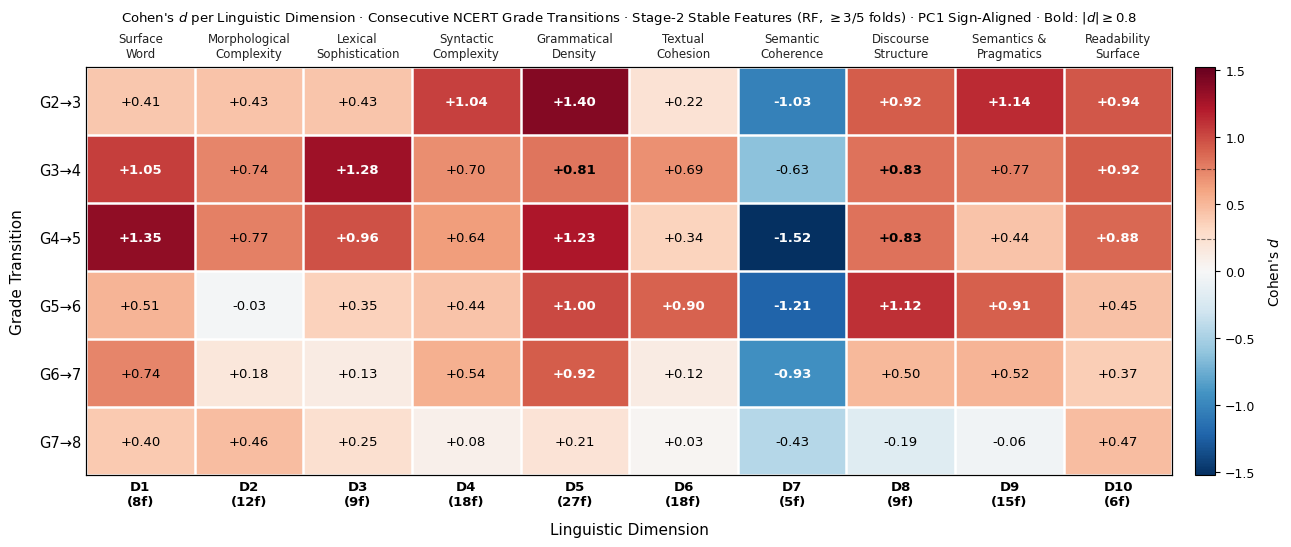

  Saved: cohens_d_pca_final.{pdf,png}


In [30]:
# ─────────────────────────────────────────────────────────────────────────────
# FINAL PLOT  —  Corrected PCA Cohen's d heatmap  (clean, publishable)
# ─────────────────────────────────────────────────────────────────────────────
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

cd5_codes = [d.split('_')[0] for d in cd5_dims]

# Full readable names — manually defined so nothing gets truncated
cd5_full_names = [
    'Surface\nWord',
    'Morphological\nComplexity',
    'Lexical\nSophistication',
    'Syntactic\nComplexity',
    'Grammatical\nDensity',
    'Textual\nCohesion',
    'Semantic\nCoherence',
    'Discourse\nStructure',
    'Semantics &\nPragmatics',
    'Readability\nSurface',
]

n_d = len(cd5_dims)
n_t = len(cd5_trans_labels)

fig, ax = plt.subplots(figsize=(14, 6))
fig.subplots_adjust(top=0.80, bottom=0.12, left=0.07, right=0.88)

# ── Heatmap ──────────────────────────────────────────────────────────────────
vmax = max(0.8, float(np.nanmax(np.abs(cd5_d_pca_fixed))))
norm = TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax)
im   = ax.imshow(cd5_d_pca_fixed.T, cmap='RdBu_r', norm=norm, aspect='auto')

# ── Cell annotations ─────────────────────────────────────────────────────────
for ti in range(n_t):
    for di in range(n_d):
        v = cd5_d_pca_fixed.T[ti, di]
        if np.isnan(v):
            continue
        tc = 'white' if abs(v) > vmax * 0.55 else 'black'
        bw = 'bold'  if abs(v) >= 0.8         else 'normal'
        ax.text(di, ti, f'{v:+.2f}',
                ha='center', va='center',
                color=tc, fontsize=9.5, fontweight=bw)

# ── Bottom x-axis: codes + n features ────────────────────────────────────────
ax.set_xticks(range(n_d))
ax.set_xticklabels(
    [f'{cd5_codes[i]}\n({cd5_n_feat_used[cd5_dims[i]]}f)'
     for i in range(n_d)],
    fontsize=9.5, fontweight='bold')
ax.xaxis.set_tick_params(length=0)

# ── Top x-axis: full dimension names, horizontal, two-line ───────────────────
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
ax_top.set_xticks(range(n_d))
ax_top.set_xticklabels(
    cd5_full_names,
    fontsize=8.5, color='#222222',
    rotation=0, ha='center', va='bottom')
ax_top.tick_params(length=0, pad=5)

# ── Y-axis ────────────────────────────────────────────────────────────────────
ax.set_yticks(range(n_t))
ax.set_yticklabels(cd5_trans_labels, fontsize=10.5)
ax.yaxis.set_tick_params(length=0)

# ── Grid ──────────────────────────────────────────────────────────────────────
ax.set_xticks(np.arange(-0.5, n_d, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_t, 1), minor=True)
ax.grid(which='minor', color='white', linestyle='-', linewidth=1.8)
ax.tick_params(which='minor', length=0)

# ── Axis labels ───────────────────────────────────────────────────────────────
ax.set_xlabel('Linguistic Dimension', fontsize=11, labelpad=10)
ax.set_ylabel('Grade Transition',     fontsize=11, labelpad=10)

# ── Colorbar ──────────────────────────────────────────────────────────────────
cbar = fig.colorbar(im, ax=ax, fraction=0.022, pad=0.02)
cbar.set_label("Cohen's $d$", fontsize=10, labelpad=8)
cbar.ax.tick_params(labelsize=9)
# Dashed lines at ±0.8 threshold
for thresh in [-0.8, 0.8]:
    cbar.ax.axhline(y=(thresh + vmax) / (2 * vmax),
                    color='black', linewidth=0.8,
                    linestyle='--', alpha=0.5)

# ── Title ─────────────────────────────────────────────────────────────────────
ax.set_title(
    "Cohen's $d$ per Linguistic Dimension · Consecutive NCERT Grade Transitions · "
    "Stage-2 Stable Features (RF, $\\geq$3/5 folds) · "
    "PC1 Sign-Aligned · Bold: $|d| \\geq 0.8$",
    fontsize=9.5, pad=8, loc='center')

plt.savefig(os.path.join(CKPT_DIR, 'cohens_d_pca_final.pdf'),
            dpi=300, bbox_inches='tight', format='pdf')
plt.savefig(os.path.join(CKPT_DIR, 'cohens_d_pca_final.png'),
            dpi=300, bbox_inches='tight', format='png')
plt.show()
print('  Saved: cohens_d_pca_final.{pdf,png}')

# SECTION 7 — Per-Fold Hyperparameter Tuning (Nested CV)



In [31]:

PARAM_GRIDS = {
    'ElasticNet_Regressor': {
        'clf__alpha'    : [0.001, 0.01, 0.1, 1.0, 10.0],     # 5 × 5 = 25
        'clf__l1_ratio' : [0.1, 0.3, 0.5, 0.7, 0.9],
    },
  
        'RF_Classifier': {
        
        'clf__n_estimators'      : [200, 300, 500, 800],
        'clf__max_depth'         : [None, 8],
        'clf__min_samples_leaf'  : [2, 4],
        'clf__max_features'      : ['sqrt', 0.5],
    },
}



USE_1SE_RULE     = True


def _baseline_estimator(model_name, base_estimator):
    # Sensible default ('no-tune') configuration per model family.
    est = clone(base_estimator)
    if model_name == 'RF_Classifier':
        est.set_params(n_estimators=200, max_depth=None,
                       min_samples_leaf=1, max_features='sqrt',
                       class_weight='balanced', bootstrap=True, criterion='gini')
    elif model_name == 'ElasticNet_Regressor':
        est.set_params(alpha=0.1, l1_ratio=0.5, max_iter=10000)

    return est


def _select_with_1se_classifier(cv_results):
    """1-SE rule on sklearn cv_results_. Tie-break = max regularisation.

    Regularisation proxies for RF: shallower max_depth, larger min_samples_leaf,
    smaller max_features. n_estimators is excluded — more trees lower variance
    without adding complexity (Probst & Boulesteix 2018).
    """
    means = np.asarray(cv_results['mean_test_score'])
    stds  = np.asarray(cv_results['std_test_score'])
    best  = int(np.argmax(means))
    threshold = means[best] - stds[best]
    eligible = np.where(means >= threshold)[0]
    if len(eligible) == 0:
        return best, float(means[best]), float(stds[best])

    def reg_score(i):
        p = cv_results['params'][i]
        s = 0.0
        if 'clf__max_depth' in p:
            md = p['clf__max_depth']
            s += -1e6 if md is None else -float(md)
        if 'clf__min_samples_leaf' in p:
            s += float(p['clf__min_samples_leaf'])
        mf = p.get('clf__max_features')
        if mf is not None:
            s += 1.0 if mf == 'sqrt' else (-float(mf) if isinstance(mf, (int, float)) else 0.0)
        return s

    sel = max(eligible, key=reg_score)
    return int(sel), float(means[sel]), float(stds[sel])


def _select_with_1se_regression(all_results):
    """1-SE rule on a list of {params, mean, std}. Tie-break = larger alpha
    (more shrinkage), then larger l1_ratio for EN (sparser solution; Ridge
    has no l1_ratio so second key is 0.0)."""
    means = np.array([r['mean'] for r in all_results])
    stds  = np.array([r['std']  for r in all_results])
    best  = int(np.argmax(means))
    threshold = means[best] - stds[best]
    eligible = [i for i, m in enumerate(means) if m >= threshold]
    if not eligible:
        return best, float(means[best]), float(stds[best])
    sel = max(
        eligible,
        key=lambda i: (
            float(all_results[i]['params'].get('clf__alpha',    0.0)),
            float(all_results[i]['params'].get('clf__l1_ratio', 0.0)),
        ),
    )
    return int(sel), float(means[sel]), float(stds[sel])


# Ordinal threshold helpers (regression only) ────────────────────────────────────
def fit_ordinal_thresholds(y_true_int, y_pred_raw, grade_min, grade_max):
    """Greedy coordinate-descent threshold fit (Issue #2a + #2d).

    Approximate: the K-1 thresholds are optimized one at a time, repeating
    full sweeps over all thresholds until no sweep produces an improvement
    (max MAX_SWEEPS=5 sweeps). The candidate pool combines every unique
    training prediction with a 50-quantile grid (deduplicated and sorted),
    so each threshold can be placed at any meaningful position in the
    prediction distribution. Greedy coordinate descent is not guaranteed
    to find the global optimum; for K-1 = 6 thresholds and a candidate pool
    of ~150-200 points, a full grid search would be ~1.5 * 10^13 evaluations
    and is intractable. The achieved (not provably optimal) thresholding
    consistently improves over round+clip on this dataset.

    METHODS NOTE: cite this function as approximate threshold optimization
    via coordinate descent over a dense candidate pool, with iteration to
    fixed point. No claim of global optimality.

    LEAKAGE: thresholds are fit on training data only — both y_true_int and
    y_pred_raw come from the inner-train (or outer-train) split. Inner-val
    and outer-test data never enter threshold fitting.
    """
    y_true_int = np.rint(np.asarray(y_true_int)).astype(int)
    y_pred_raw = np.asarray(y_pred_raw, dtype=float)
    grades = np.arange(grade_min, grade_max + 1)
    K = len(grades)
    if K <= 1:
        return np.array([])

    pmin, pmax = float(np.min(y_pred_raw)), float(np.max(y_pred_raw))
    if pmin == pmax:
        return np.array([(grade_min + i + 0.5) for i in range(K - 1)])

    # Dense candidate pool: every unique training prediction plus a 50-quantile
    # grid, deduplicated and sorted. This is much denser than the original
    # 50-quantile-only pool (was: ~50 candidates; now: typically 150-200).
    quantile_pool = np.quantile(y_pred_raw, np.linspace(0.02, 0.98, 50))
    cand_pool = np.unique(np.concatenate([np.unique(y_pred_raw), quantile_pool]))

    init = np.linspace(pmin, pmax, K + 1)[1:-1]
    best = init.copy()
    best_qwk = _score_thresholds(y_true_int, y_pred_raw, best, grade_min, grade_max)

    # Multi-sweep coordinate descent until no sweep produces an improvement.
    MAX_SWEEPS = 5
    EPS = 1e-9
    for _ in range(MAX_SWEEPS):
        improved = False
        for t_idx in range(K - 1):
            for c in cand_pool:
                trial = best.copy()
                trial[t_idx] = c
                trial = np.sort(trial)
                qwk = _score_thresholds(y_true_int, y_pred_raw, trial, grade_min, grade_max)
                if qwk > best_qwk + EPS:
                    best_qwk = qwk
                    best = trial
                    improved = True
        if not improved:
            break
    return best


def _score_thresholds(y_true_int, y_pred_raw, thr, grade_min, grade_max):
    y_pred_int = apply_ordinal_thresholds(y_pred_raw, thr, grade_min, grade_max)
    return float(cohen_kappa_score(y_true_int, y_pred_int, weights='quadratic'))


def apply_ordinal_thresholds(y_pred_raw, thr, grade_min, grade_max):
    y_pred_raw = np.asarray(y_pred_raw, dtype=float)
    if thr is None or len(thr) == 0:
        return np.clip(np.rint(y_pred_raw).astype(int), grade_min, grade_max)
    bins = np.searchsorted(np.sort(thr), y_pred_raw)
    return np.clip(bins + grade_min, grade_min, grade_max).astype(int)


In [32]:

def tune_classification_fold(model_name, estimator, fr):
    fold_k    = fr['outer_fold']
    train_idx = fr['train_idx']
    test_idx  = fr['test_idx']
    features  = [f for f in fr['final_features'] if f in X_df.columns]
    if not features:
        return None

    X_tr = X_df[features].values[train_idx]
    X_te = X_df[features].values[test_idx]
    y_tr = y_encoded[train_idx]
    y_te = y_encoded[test_idx]

    cv_inner = StratifiedKFold(n_splits=N_TUNE_FOLDS, shuffle=True,
                               random_state=RANDOM_STATE)
    pipe = Pipeline([('scaler', StandardScaler()), ('clf', clone(estimator))])

    param_grid = dict(PARAM_GRIDS[model_name])
    if model_name == 'RF_Classifier':
        param_grid['clf__class_weight'] = ['balanced']
        param_grid['clf__bootstrap']    = [True]
        param_grid['clf__criterion']    = ['gini']

    search = GridSearchCV(pipe, param_grid, cv=cv_inner,
                          scoring=qwk_scorer, refit=False, n_jobs=-1)
    search.fit(X_tr, y_tr)

    if USE_1SE_RULE:
        sel_idx, inner_cv, inner_cv_std = _select_with_1se_classifier(search.cv_results_)
    else:
        sel_idx      = int(np.argmax(search.cv_results_['mean_test_score']))
        inner_cv     = float(search.cv_results_['mean_test_score'][sel_idx])
        inner_cv_std = float(search.cv_results_['std_test_score'][sel_idx])
    best_params = search.cv_results_['params'][sel_idx]

    fitted_pipe = clone(pipe).set_params(**best_params).fit(X_tr, y_tr)
    y_pred      = fitted_pipe.predict(X_te).astype(int)
    acc = accuracy_score(y_te, y_pred)
    w1  = within_one(y_te, y_pred)
    qwk = cohen_kappa_score(y_te, y_pred, weights='quadratic')
    f1  = f1_score(y_te, y_pred, average='weighted', zero_division=0)

    bundle = {
        'model_name'     : model_name,
        'task'           : 'classification',
        'outer_fold'     : int(fold_k),
        'features'       : features,
        'n_features'     : len(features),
        'best_params'    : best_params,
        'inner_cv_score' : inner_cv,
        'inner_cv_std'   : inner_cv_std,
        'fitted_pipeline': fitted_pipe,
        'thresholds'     : None,
        'train_idx'      : train_idx,
        'test_idx'       : test_idx,
        'y_test'         : y_te,
        'y_pred'         : y_pred,
        'y_pred_raw'     : y_pred,
        'acc': acc, 'w1': w1, 'qwk': qwk, 'f1': f1,
        'choice'         : 'tuned',
    }
    print(f'  fold={fold_k} | n_feat={len(features):3d} | '
          f'acc={acc:.3f} w1={w1:.3f} qwk={qwk:.3f} | '
          f'inner_cv={inner_cv:.4f}±{inner_cv_std:.4f}')
    return bundle


def tune_regression_fold(model_name, estimator, fr):
    fold_k    = fr['outer_fold']
    train_idx = fr['train_idx']
    test_idx  = fr['test_idx']
    features  = [f for f in fr['final_features'] if f in X_df.columns]
    if not features:
        return None

    X_tr = X_df[features].values[train_idx]
    X_te = X_df[features].values[test_idx]
    y_tr = y_float[train_idx]
    y_te = y_float[test_idx]

    y_strat  = np.clip(np.rint(y_tr).astype(int), GRADE_MIN, GRADE_MAX)
    cv_inner = StratifiedKFold(n_splits=N_TUNE_FOLDS, shuffle=True,
                               random_state=RANDOM_STATE)
    pipe = Pipeline([('scaler', StandardScaler()), ('clf', clone(estimator))])

    def _eval_params(params):
        fold_qwks = []
        for in_tr, in_va in cv_inner.split(X_tr, y_strat):
            in_pipe = clone(pipe).set_params(**params)
            in_pipe.fit(X_tr[in_tr], y_tr[in_tr])
            raw_tr  = in_pipe.predict(X_tr[in_tr])
            thr_in  = fit_ordinal_thresholds(y_tr[in_tr], raw_tr, GRADE_MIN, GRADE_MAX)
            raw_va  = in_pipe.predict(X_tr[in_va])
            pred_va = apply_ordinal_thresholds(raw_va, thr_in, GRADE_MIN, GRADE_MAX)
            fold_qwks.append(float(cohen_kappa_score(
                y_tr[in_va].astype(int), pred_va, weights='quadratic')))
        if not fold_qwks:
            return -np.inf, 0.0
        return float(np.mean(fold_qwks)), float(np.std(fold_qwks))

    all_results = []
    for params in ParameterGrid(PARAM_GRIDS[model_name]):
        m, s = _eval_params(params)
        all_results.append({'params': params, 'mean': m, 'std': s})

    if USE_1SE_RULE:
        sel_idx, inner_cv, inner_cv_std = _select_with_1se_regression(all_results)
    else:
        sel_idx      = int(np.argmax([r['mean'] for r in all_results]))
        inner_cv     = float(all_results[sel_idx]['mean'])
        inner_cv_std = float(all_results[sel_idx]['std'])
    best_params = all_results[sel_idx]['params']

# Collect OOF predictions using the same cv_inner splits (best_params already selected)
    oof_raw = np.full(len(y_tr), np.nan)
    for in_tr, in_va in cv_inner.split(X_tr, y_strat):
        oof_pipe = clone(pipe).set_params(**best_params)
        oof_pipe.fit(X_tr[in_tr], y_tr[in_tr])
        oof_raw[in_va] = oof_pipe.predict(X_tr[in_va])   # out-of-sample for each fold
    thresholds  = fit_ordinal_thresholds(y_tr, oof_raw, GRADE_MIN, GRADE_MAX)
    
    # Final model on full outer-train (thresholds already calibrated above)
    fitted_pipe = clone(pipe).set_params(**best_params).fit(X_tr, y_tr)
    raw_te      = fitted_pipe.predict(X_te)
    y_pred_int  = apply_ordinal_thresholds(raw_te, thresholds, GRADE_MIN, GRADE_MAX)
    y_te_int    = y_te.astype(int)

    acc = accuracy_score(y_te_int, y_pred_int)
    w1  = within_one(y_te_int, y_pred_int)
    qwk = cohen_kappa_score(y_te_int, y_pred_int, weights='quadratic')
    f1  = f1_score(y_te_int, y_pred_int, average='weighted', zero_division=0)

    bundle = {
        'model_name'     : model_name,
        'task'           : 'regression',
        'outer_fold'     : int(fold_k),
        'features'       : features,
        'n_features'     : len(features),
        'best_params'    : best_params,
        'inner_cv_score' : inner_cv,
        'inner_cv_std'   : inner_cv_std,
        'fitted_pipeline': fitted_pipe,
        'thresholds'     : thresholds,
        'train_idx'      : train_idx,
        'test_idx'       : test_idx,
        'y_test'         : y_te_int,
        'y_pred'         : y_pred_int,
        'y_pred_raw'     : raw_te,
        'acc': acc, 'w1': w1, 'qwk': qwk, 'f1': f1,
        'choice'         : 'tuned',
    }
    print(f'  fold={fold_k} | n_feat={len(features):3d} | '
          f'acc={acc:.3f} w1={w1:.3f} qwk={qwk:.3f} | '
          f'inner_cv={inner_cv:.4f}±{inner_cv_std:.4f}')
    return bundle


def tune_model_all_folds(model_name, estimator, task):
    print(f'\n{"="*70}\n  {model_name}  |  task={task}  |  '
          f'1-SE={USE_1SE_RULE}\n{"="*70}')
    bundles = []
    for fr in fs_results[model_name]:
        b = (tune_classification_fold(model_name, estimator, fr)
             if task == 'classification'
             else tune_regression_fold(model_name, estimator, fr))
        if b is not None:
            bundles.append(b)
            with open(os.path.join(CKPT_DIR,
                      f'tuned_model_{model_name}_fold{b["outer_fold"]}.pkl'), 'wb') as fp:
                pickle.dump({k: v for k, v in b.items()
                             if k != 'fitted_pipeline'}, fp)
    return bundles

# BASELINE

In [33]:
import numpy as np
from sklearn.metrics import cohen_kappa_score, f1_score, accuracy_score
 
baseline_results     = []   # list of metric dicts (same schema as ensemble_results)
baseline_predictions = {}   # name → (y_true_list, y_pred_list)
fold_level_results   = {}   # name → list of per-fold dicts (for std computation)
 
print("Baseline bookkeeping ready.")


Baseline bookkeeping ready.


# TRIVIAL BASELINE

In [34]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL B1 — ZeroR  (Witten et al., 2016)
# ─────────────────────────────────────────────────────────────────────────────
# Predicts the majority training class for every test instance.
# Witten, I. H., Frank, E., Hall, M. A., & Pal, C. J. (2016).
# Data Mining: Practical Machine Learning Tools and Techniques (4th ed.). Elsevier.
# ─────────────────────────────────────────────────────────────────────────────
 
from scipy.stats import mode as scipy_mode
 
_name = "ZeroR"
_y_true_all, _y_pred_all = [], []
_fold_metrics = []
 
for fold_k, (tr_idx, te_idx) in enumerate(outer_splits):
    y_tr = y_encoded[tr_idx]
    y_te = y_encoded[te_idx]
 
    # Majority class on outer-train only
    majority_enc = int(scipy_mode(y_tr, keepdims=True).mode[0])
    y_pred = np.full(len(te_idx), majority_enc, dtype=int)
 
    # Convert back to grade space for metric_bundle compatibility
    y_true_g = (y_te + GRADE_MIN).tolist()
    y_pred_g = (y_pred + GRADE_MIN).tolist()
    _y_true_all.extend(y_true_g)
    _y_pred_all.extend(y_pred_g)
 
    qwk = cohen_kappa_score(y_te, y_pred, weights='quadratic')
    acc = accuracy_score(y_te, y_pred)
    w1  = within_one(y_te, y_pred)
    f1w = f1_score(y_te, y_pred, average='weighted', zero_division=0)
    f1m = f1_score(y_te, y_pred, average='macro',    zero_division=0)
    _fold_metrics.append({'qwk': qwk, 'acc': acc, 'w1': w1, 'f1w': f1w, 'f1m': f1m})
    print(f"  Fold {fold_k+1}  majority_class={majority_enc + GRADE_MIN}  "
          f"acc={acc:.4f}  qwk={qwk:.4f}")
 
m = metric_bundle(_y_true_all, _y_pred_all, _name)
m['Ensemble'] = _name
baseline_results.append(m)
baseline_predictions[_name] = (_y_true_all, _y_pred_all)
fold_level_results[_name]    = _fold_metrics
print(f"\nZeroR 5-fold  QWK={np.mean([d['qwk'] for d in _fold_metrics]):.4f}"
      f" ± {np.std([d['qwk'] for d in _fold_metrics]):.4f}")
 

  Fold 1  majority_class=5  acc=0.1429  qwk=0.0000
  Fold 2  majority_class=6  acc=0.1429  qwk=0.0000
  Fold 3  majority_class=6  acc=0.1471  qwk=0.0000
  Fold 4  majority_class=5  acc=0.1471  qwk=0.0000
  Fold 5  majority_class=5  acc=0.1471  qwk=0.0000
  ZeroR                                            | Acc=0.1453  W1=0.4477  QWK=0.0026  F1w=0.0689  F1m=0.0627

ZeroR 5-fold  QWK=0.0000 ± 0.0000


# B2

In [35]:
!pip install mord

  Preparing metadata (setup.py) ... done
  Created wheel for mord: filename=mord-0.7-py3-none-any.whl size=9953 sha256=efced9ab87dd0431f83bdd3072ea65d7127f28a6ef47919229fdd561725a0120
  Stored in directory: /root/.cache/pip/wheels/80/3e/3b/13f1adf346cad0fec675db328e4b0d814795c6c8e2fb659122
Successfully built mord


In [36]:
from mord import LogisticAT   # pip install mord
import numpy as np
from sklearn.metrics import cohen_kappa_score, accuracy_score, f1_score

_name = "FKGL-OrdReg"
_y_true_all, _y_pred_all, _fold_metrics = [], [], []

# FKGL is a deterministic per-text formula → precompute once, no leakage
fkgl_scores = np.array([textstat.flesch_kincaid_grade(t) for t in all_texts],
                       dtype=np.float64).reshape(-1, 1)

for fold_k, (tr_idx, te_idx) in enumerate(outer_splits):
    y_tr = y_encoded[tr_idx].astype(int)
    y_te = y_encoded[te_idx].astype(int)

    # Proportional-odds ordinal logistic regression (McCullagh 1980)
    # fitted on outer-train only
    model = LogisticAT(alpha=0.0)
    model.fit(fkgl_scores[tr_idx], y_tr)
    y_pred_enc = model.predict(fkgl_scores[te_idx]).astype(int)

    qwk = cohen_kappa_score(y_te, y_pred_enc, weights='quadratic')
    acc = accuracy_score(y_te, y_pred_enc)
    w1  = within_one(y_te, y_pred_enc)
    f1w = f1_score(y_te, y_pred_enc, average='weighted', zero_division=0)
    f1m = f1_score(y_te, y_pred_enc, average='macro',    zero_division=0)
    _fold_metrics.append({'qwk': qwk, 'acc': acc, 'w1': w1, 'f1w': f1w, 'f1m': f1m})

    _y_true_all.extend((y_te + GRADE_MIN).tolist())
    _y_pred_all.extend((y_pred_enc + GRADE_MIN).tolist())
    print(f"  Fold {fold_k+1}  acc={acc:.4f}  qwk={qwk:.4f}")

# ── Book-keeping (same pattern as B1 / B2) ─────────────────────────────────
m = metric_bundle(_y_true_all, _y_pred_all, _name)
m['Ensemble'] = _name
baseline_results.append(m)
baseline_predictions[_name] = (_y_true_all, _y_pred_all)
fold_level_results[_name]    = _fold_metrics

print(f"\nFKGL-OrdReg 5-fold  QWK={np.mean([d['qwk'] for d in _fold_metrics]):.4f}"
      f" ± {np.std([d['qwk'] for d in _fold_metrics]):.4f}")

  Fold 1  acc=0.1143  qwk=0.6095
  Fold 2  acc=0.2571  qwk=0.7575
  Fold 3  acc=0.3529  qwk=0.6313
  Fold 4  acc=0.2059  qwk=0.5504
  Fold 5  acc=0.2647  qwk=0.4579
  FKGL-OrdReg                                      | Acc=0.2384  W1=0.6453  QWK=0.6001  F1w=0.2314  F1m=0.2332

FKGL-OrdReg 5-fold  QWK=0.6013 ± 0.0985


# B4: NEURAL ONLY (LINGFEAT)

In [37]:
# Lazy imports for transformers
from transformers import (AutoModel, AutoTokenizer,
                          get_linear_schedule_with_warmup)
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader  # ← Add this
import torch.nn as nn  # ← Add this
import numpy as np  # ← Add this if not already imported
import random  # ← Add this if not already imported

def set_all_seeds(seed):
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark    = False
        torch.backends.cudnn.deterministic = True


class ReadabilityDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=512):
        self.encodings = tokenizer(texts, truncation=True, padding='max_length',
                                   max_length=max_length, return_tensors='pt')
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        return {
            'input_ids':      self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels':         self.labels[idx],
        }


class ReadabilityTransformer(nn.Module):
    # Transformer (DeBERTa-v3 or RoBERTa) with selective freezing + classification head.
    def __init__(self, num_classes, freeze_layers=11, dropout=0.5,
                 model_name='roberta-base'):
        super().__init__()
        # Force fp32 to avoid mixed-precision dtype mismatch with the fp32 classifier head.
# DeBERTa-v3 snapshots on HuggingFace are sometimes stored in fp16; loading in
# fp32 keeps everything consistent and avoids 'mat1 mat2 dtype' errors.
        self.encoder = AutoModel.from_pretrained(model_name, torch_dtype=torch.float32)
        # Freeze embeddings
        if hasattr(self.encoder, 'embeddings'):
            for p in self.encoder.embeddings.parameters():
                p.requires_grad = False
        # Freeze encoder layers (DeBERTa & RoBERTa both expose .encoder.layer)
        layers = self.encoder.encoder.layer
        n_freeze = min(freeze_layers, len(layers))
        for i in range(n_freeze):
            for p in layers[i].parameters():
                p.requires_grad = False
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total     = sum(p.numel() for p in self.parameters())
        print(f'    Frozen {n_freeze}/{len(layers)} layers | trainable: {trainable:,}/{total:,} ({100*trainable/total:.1f}%)')
        hidden = self.encoder.config.hidden_size
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden, 256), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )
    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        return self.classifier(cls)


def train_transformer_fold(texts_tr, y_tr, tokenizer, cfg, fold_k, device):
    set_all_seeds(RANDOM_STATE + fold_k)
    _gen = torch.Generator()
    _gen.manual_seed(RANDOM_STATE + fold_k)
    model = ReadabilityTransformer(NUM_CLASSES, cfg['freeze_layers'],
                                   cfg['dropout'], cfg['model_name']).to(device)
    ds     = ReadabilityDataset(texts_tr, y_tr.tolist(), tokenizer, cfg['max_length'])
    loader = DataLoader(ds, batch_size=cfg['batch_size'], shuffle=True, num_workers=0,generator=_gen)
    opt = AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                lr=cfg['learning_rate'], weight_decay=cfg['weight_decay'])
    total_steps  = len(loader) * cfg['epochs']
    warmup_steps = int(total_steps * cfg['warmup_ratio'])
    sched = get_linear_schedule_with_warmup(opt, warmup_steps, total_steps)
    loss_fn = nn.CrossEntropyLoss()
    for epoch in range(cfg['epochs']):
        model.train()
        ep_loss, n_corr, n_tot = 0.0, 0, 0
        for batch in loader:
            ids   = batch['input_ids'].to(device)
            mask  = batch['attention_mask'].to(device)
            lbl   = batch['labels'].to(device)
            opt.zero_grad()
            logits = model(ids, mask)
            loss   = loss_fn(logits, lbl)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            opt.step(); sched.step()
            ep_loss += loss.item() * len(lbl)
            n_corr  += (logits.argmax(-1) == lbl).sum().item()
            n_tot   += len(lbl)
        print(f'      ep {epoch+1}/{cfg["epochs"]}  loss={ep_loss/n_tot:.4f}  acc={n_corr/n_tot:.3f}')
    model.eval()
    return model


@torch.no_grad()
def get_transformer_softmax_probs(model, texts, tokenizer, cfg, device):
    model.eval()
    all_probs = []
    bs = cfg['batch_size']
    for i in range(0, len(texts), bs):
        enc = tokenizer(texts[i:i+bs], truncation=True, padding='max_length',
                        max_length=cfg['max_length'], return_tensors='pt')
        logits = model(enc['input_ids'].to(device), enc['attention_mask'].to(device))
        all_probs.append(torch.softmax(logits, dim=-1).cpu().numpy())
    return np.vstack(all_probs)


print('Transformer components ready.')


Transformer components ready.


In [38]:
# ════════════════════════════════════════════════════════════════════════
# BASELINE B4 — RoBERTa-base fine-tuned, text only
#
# Configuration follows Lee et al. (2021), Section 4.2.2:
#   AdamW · linear scheduler · 10% warmup · batch 8 · lr 3e-5 · 3 epochs
# Predictions are taken directly from the transformer's softmax head.
#
# We also cache (probs_tr, probs_te) per fold for B6 to reuse without
# re-fine-tuning the encoder.
# ════════════════════════════════════════════════════════════════════════

RUN_TRANSFORMER = bool(all_texts) and torch.cuda.is_available()

if not RUN_TRANSFORMER:
    print('SKIPPING B4 + B6 transformer baselines — no GPU or no texts.')
    transformer_softmax_cache = {}
else:
    # Lee et al. (2021) Cambridge-winning encoder + hyperparameters
    TRANSFORMER_CFG_B4 = dict(
        model_name    = 'roberta-base',
        max_length    = 512,
        batch_size    = 8,
        learning_rate = 3e-5,
        epochs        = 3,
        warmup_ratio  = 0.10,
        weight_decay  = 0.01,
        seed          = RANDOM_STATE,
        freeze_layers = 0,
        dropout       = 0.1,
        grad_clip     = 1.0,
    )

    print('=' * 70)
    print('  B4: RoBERTa-base fine-tuned, text only  (Lee et al. 2021)')
    print('=' * 70)
    print(f'  Encoder: {TRANSFORMER_CFG_B4["model_name"]}')

    tokenizer = AutoTokenizer.from_pretrained(TRANSFORMER_CFG_B4['model_name'])

    _name = 'B4_RoBERTa_TextOnly'
    y_true_all, y_pred_all = [], []
    _fold_metrics = []
    transformer_softmax_cache = {}                # ← B6 will read from this

    for fold_k, (tr, te) in enumerate(outer_splits):
        t0 = time.time()
        texts_tr = [all_texts[i] for i in tr]
        texts_te = [all_texts[i] for i in te]
        ytr, yte = y_encoded[tr], y_encoded[te]
        print(f'\n--- B4 fold {fold_k}: train={len(tr)} test={len(te)} ---')
        print(f'  Fine-tuning RoBERTa-base...')

        xfm = train_transformer_fold(texts_tr, ytr, tokenizer,
                                       TRANSFORMER_CFG_B4, fold_k, DEVICE)
        probs_tr = get_transformer_softmax_probs(xfm, texts_tr, tokenizer,
                                                    TRANSFORMER_CFG_B4, DEVICE)
        probs_te = get_transformer_softmax_probs(xfm, texts_te, tokenizer,
                                                    TRANSFORMER_CFG_B4, DEVICE)

        # Cache both sides for B6 (avoids re-fine-tuning the same encoder)
        transformer_softmax_cache[fold_k] = {
            'probs_tr':  probs_tr,
            'probs_te':  probs_te,
            'train_idx': tr,
            'test_idx':  te,
            'y_tr':      ytr,
            'y_te':      yte,
        }

        # B4 prediction: argmax of test softmax
        yp = np.argmax(probs_te, axis=1)
        qwk = cohen_kappa_score(yte, yp, weights='quadratic')
        acc = accuracy_score(yte, yp)
        w1  = within_one(yte, yp)
        f1w = f1_score(yte, yp, average='weighted', zero_division=0)
        f1m = f1_score(yte, yp, average='macro',    zero_division=0)
        _fold_metrics.append({'qwk': qwk, 'acc': acc, 'w1': w1,
                                'f1w': f1w, 'f1m': f1m})
        print(f'  fold {fold_k}: QWK={qwk:.4f}  Acc={acc:.4f}  '
              f'W1={w1:.4f}  ({time.time()-t0:.0f}s)')

        y_true_all.extend((yte + GRADE_MIN).tolist())
        y_pred_all.extend((yp + GRADE_MIN).tolist())

        del xfm
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()

    # Register B4 in the canonical baseline bookkeeping
    m = metric_bundle(y_true_all, y_pred_all,
                       'B4: RoBERTa-base text only (Lee 2021)')
    m['Ensemble'] = _name
    baseline_results.append(m)
    baseline_predictions[_name] = (y_true_all, y_pred_all)
    fold_level_results[_name]   = _fold_metrics

    qwks = [f['qwk'] for f in _fold_metrics]
    print(f'\n  → B4 aggregate QWK = {m["QWK"]:.4f}  '
          f'(per-fold {np.mean(qwks):.4f} ± {np.std(qwks, ddof=1):.4f})')

SKIPPING B4 + B6 transformer baselines — no GPU or no texts.


# B5 :HANDCRAFTED FEATURES (LINGFEAT + XGBOOST)

In [39]:
# ════════════════════════════════════════════════════════════════════════
# BASELINE B5 — XGB + LingFeat T1  (Lee et al. 2021 classical baseline)
# ════════════════════════════════════════════════════════════════════════

from xgboost import XGBClassifier

LINGFEAT_PATH = '/kaggle/input/datasets/maureenmiranda11/no-trunc-baseline/english_no_trunc_baseline_ling_feature.xlsx'

ling_raw = pd.read_excel(LINGFEAT_PATH)
ling_raw.columns = ling_raw.columns.str.strip()
ling_raw.drop(columns='index', inplace=True)
_grade_candidates = ['grade', 'Grade', 'GRADE', 'label', 'Label']
ling_grade_col = next((c for c in _grade_candidates if c in ling_raw.columns), None)
assert ling_grade_col is not None, f'No grade column. Got: {list(ling_raw.columns)[:15]}'

ling_feat_cols = [c for c in ling_raw.columns if c != ling_grade_col]
print(f'LingFeat: {ling_raw.shape[0]} rows × {len(ling_feat_cols)} features')

assert len(ling_raw) == len(y_float), \
    f'Row mismatch: LingFeat {len(ling_raw)} vs main {len(y_float)}'

ling_grades = ling_raw[ling_grade_col].astype(float).values
if not np.allclose(ling_grades, y_float):
    print('  WARNING: grade mismatch — verify row alignment.')
else:
    print('  Grade alignment verified ✓')

X_ling = ling_raw[ling_feat_cols].astype(np.float32).values
print(f'  X_ling shape: {X_ling.shape}')

XGB_LEE_PARAMS = dict(
    learning_rate = 0.05,
    gamma         = 1,
    max_depth     = 9,
    n_estimators  = 200,
    objective     = 'multi:softmax',
    num_class     = NUM_CLASSES,
    random_state  = RANDOM_STATE,
    n_jobs        = 1,
    eval_metric   = 'mlogloss',
)

print('\n' + '=' * 70)
print('  B5: XGB + LingFeat T1  (Lee et al. 2021)')
print('=' * 70)

_name = 'B5_XGB_LingFeat_T1'     # matches SYSTEM_ORDER key in results table           # matches BASELINE_ORDER key
y_true_all, y_pred_all = [], []
_fold_metrics = []

for fold_k, (tr, te) in enumerate(outer_splits):
    Xtr, Xte = X_ling[tr], X_ling[te]
    ytr, yte = y_encoded[tr], y_encoded[te]

    clf = XGBClassifier(**XGB_LEE_PARAMS)
    clf.fit(Xtr, ytr)
    yp = clf.predict(Xte).astype(int)

    yte_g = (yte + GRADE_MIN).tolist()
    yp_g  = (yp  + GRADE_MIN).tolist()
    y_true_all.extend(yte_g)
    y_pred_all.extend(yp_g)

    qwk = cohen_kappa_score(yte, yp, weights='quadratic')
    acc = accuracy_score(yte, yp)
    w1  = within_one(yte, yp)
    f1w = f1_score(yte, yp, average='weighted', zero_division=0)
    f1m = f1_score(yte, yp, average='macro',    zero_division=0)
    _fold_metrics.append({'qwk': qwk, 'acc': acc, 'w1': w1, 'f1w': f1w, 'f1m': f1m})
    print(f'  fold {fold_k}: QWK={qwk:.4f}  Acc={acc:.4f}  W1={w1:.4f}')

m = metric_bundle(y_true_all, y_pred_all, 'B5: XGB + LingFeat T1 (Lee 2021)')
m['Ensemble'] = _name
baseline_results.append(m)
baseline_predictions[_name] = (y_true_all, y_pred_all)
fold_level_results[_name]   = _fold_metrics

print(f'\n  QWK: {m["QWK"]:.4f}  '
      f'(per-fold {np.mean([d["qwk"] for d in _fold_metrics]):.4f} '
      f'± {np.std([d["qwk"] for d in _fold_metrics], ddof=1):.4f})')

LingFeat: 172 rows × 255 features
  Grade alignment verified ✓
  X_ling shape: (172, 255)

  B5: XGB + LingFeat T1  (Lee et al. 2021)
  fold 0: QWK=0.8012  Acc=0.3143  W1=0.8000
  fold 1: QWK=0.8901  Acc=0.4286  W1=0.9143
  fold 2: QWK=0.8766  Acc=0.2941  W1=0.8824
  fold 3: QWK=0.8678  Acc=0.3235  W1=0.8529
  fold 4: QWK=0.8774  Acc=0.4412  W1=0.8824
  B5: XGB + LingFeat T1 (Lee 2021)                 | Acc=0.3605  W1=0.8663  QWK=0.8624  F1w=0.3603  F1m=0.3496

  QWK: 0.8624  (per-fold 0.8626 ± 0.0353)


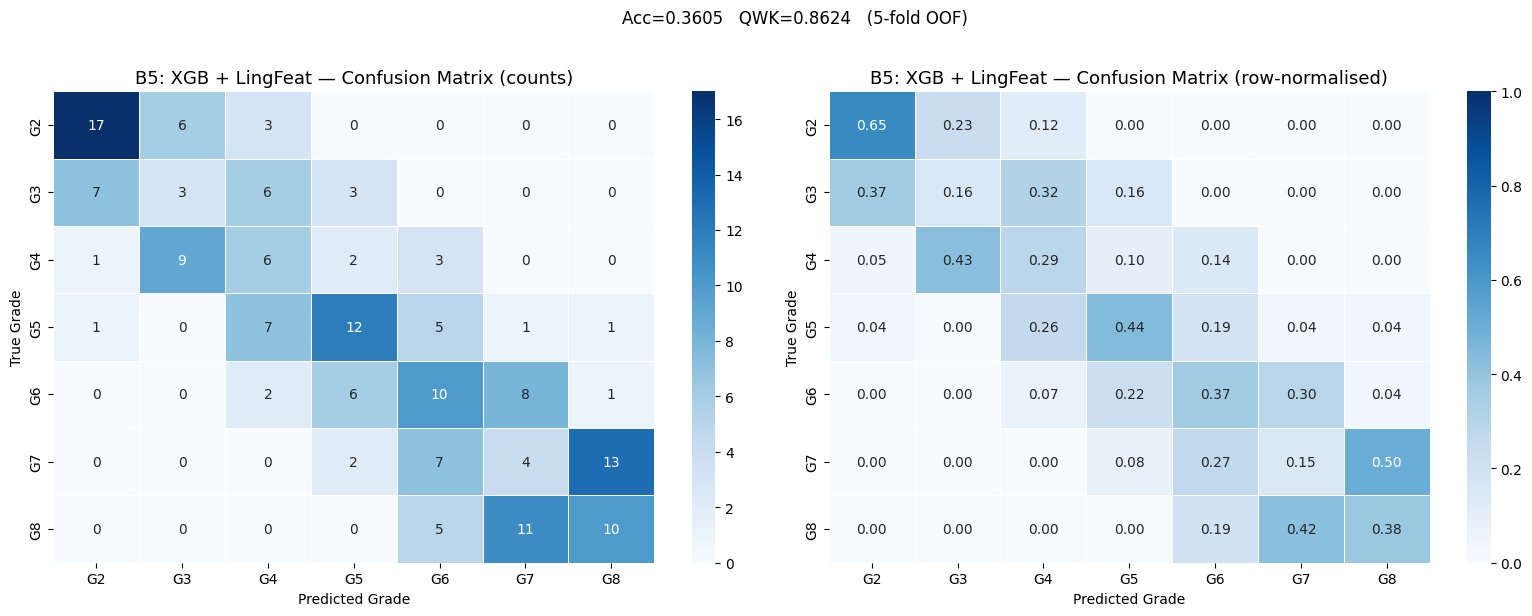


Grade       N  Correct   Recall Most confused with
-------------------------------------------------------
G2         26       17     0.65   G3 (6)
G3         19        3     0.16   G2 (7)
G4         21        6     0.29   G3 (9)
G5         27       12     0.44   G4 (7)
G6         27       10     0.37   G7 (8)
G7         26        4     0.15   G8 (13)
G8         26       10     0.38   G7 (11)


In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, cohen_kappa_score, accuracy_score
import numpy as np
from xgboost import XGBClassifier

grade_labels = [f'G{g}' for g in TARGET_GRADES]  # ['G2','G3',...,'G8']

y_true_all, y_pred_all = [], []

for fold_k, (tr, te) in enumerate(outer_splits):
    Xtr, Xte = X_ling[tr], X_ling[te]
    ytr, yte = y_encoded[tr], y_encoded[te]

    clf = XGBClassifier(**XGB_LEE_PARAMS)
    clf.fit(Xtr, ytr)
    yp = clf.predict(Xte).astype(int)

    y_true_all.extend(yte.tolist())
    y_pred_all.extend(yp.tolist())

cm = confusion_matrix(y_true_all, y_pred_all)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)  # row-normalised

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=grade_labels, yticklabels=grade_labels,
            linewidths=0.5, ax=axes[0])
axes[0].set_title('B5: XGB + LingFeat — Confusion Matrix (counts)', fontsize=13)
axes[0].set_xlabel('Predicted Grade')
axes[0].set_ylabel('True Grade')

# Row-normalised (recall per class)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=grade_labels, yticklabels=grade_labels,
            linewidths=0.5, vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('B5: XGB + LingFeat — Confusion Matrix (row-normalised)', fontsize=13)
axes[1].set_xlabel('Predicted Grade')
axes[1].set_ylabel('True Grade')

overall_acc = accuracy_score(y_true_all, y_pred_all)
overall_qwk = cohen_kappa_score(y_true_all, y_pred_all, weights='quadratic')
fig.suptitle(f'Acc={overall_acc:.4f}   QWK={overall_qwk:.4f}   (5-fold OOF)',
             fontsize=12, y=1.02)

plt.tight_layout()
plt.savefig('b5_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Per-class breakdown in text
print(f"\n{'Grade':<8} {'N':>4} {'Correct':>8} {'Recall':>8} {'Most confused with'}")
print('-' * 55)
for i, grade in enumerate(TARGET_GRADES):
    row       = cm[i]
    n         = row.sum()
    correct   = cm[i, i]
    recall    = correct / n if n > 0 else 0
    row_copy  = row.copy(); row_copy[i] = 0
    top_err_i = row_copy.argmax()
    top_err_n = row_copy[top_err_i]
    confused  = f'G{TARGET_GRADES[top_err_i]} ({top_err_n})' if top_err_n > 0 else '—'
    print(f'G{grade:<7} {n:>4} {correct:>8} {recall:>8.2f}   {confused}')

# b6: LINGFEAT HYBRID

In [41]:
# ─── Transformer cache check ────────────────────────────────────────────────
# B4 (above) fine-tunes RoBERTa-base and populates transformer_softmax_cache.
# B6 reads directly from that cache — no additional fine-tuning needed here.

if RUN_TRANSFORMER:
    assert len(transformer_softmax_cache) == len(outer_splits), \
        f'transformer_softmax_cache has {len(transformer_softmax_cache)} folds, ' \
        f'expected {len(outer_splits)} — re-run B4.'
    print(f'✓ transformer_softmax_cache ready: {len(transformer_softmax_cache)} folds '
          f'(roberta-base, Lee et al. 2021 config)')
else:
    print('SKIPPING — no GPU or no texts. B6 will also be skipped.')

SKIPPING — no GPU or no texts. B6 will also be skipped.


In [42]:
# ════════════════════════════════════════════════════════════════════════
# BASELINE B6 — Transformer + LingFeat + RF Hybrid  (Lee et al. 2021)
# ════════════════════════════════════════════════════════════════════════

from transformers import AutoTokenizer
from sklearn.ensemble import RandomForestClassifier


# ════════════════════════════════════════════════════════════════════════
# BASELINE B6 — RoBERTa-RF-T1 hybrid  (Lee et al. 2021, Section 4.3)
#
# Hybrid architecture: train-side and test-side RoBERTa softmax probabilities
# are appended as additional columns to the LingFeat T1 feature dataframe,
# and the augmented dataframe is fed to a Random Forest classifier with
# Lee et al.'s optimal hyperparameters.
#
# We reuse the B4 fine-tuned encoder via transformer_softmax_cache — no
# additional fine-tuning is performed.
#
# RF hyperparameters (Lee et al. 2021 Table 23): n_estimators=800,
# max_depth=None, max_features='auto' (deprecated; 'sqrt' is the modern
# sklearn equivalent for classification).
# ════════════════════════════════════════════════════════════════════════

assert RUN_TRANSFORMER, 'B6 requires B4 to have run (GPU + transformer softmax).'
assert 'X_ling' in dir(), 'B6 requires X_ling — run B5 first.'
assert len(transformer_softmax_cache) == len(outer_splits), \
    'transformer_softmax_cache is incomplete — re-run B4.'

from sklearn.ensemble import RandomForestClassifier

RF_LEE_PARAMS = dict(
    n_estimators = 800,
    max_depth    = None,
    max_features = 'sqrt',     # sklearn-modern equivalent of deprecated 'auto'
    random_state = RANDOM_STATE,
    n_jobs       = 1,
)

print('=' * 70)
print('  B6: RoBERTa-RF-T1 hybrid  (Lee et al. 2021)')
print('=' * 70)
print(f'  RF: n_est={RF_LEE_PARAMS["n_estimators"]}, '
      f'max_depth={RF_LEE_PARAMS["max_depth"]}, '
      f'max_features={RF_LEE_PARAMS["max_features"]}')

_name = 'B6_RoBERTa_RF_T1'
y_true_all, y_pred_all = [], []
_fold_metrics = []

for fold_k, (tr, te) in enumerate(outer_splits):
    cache    = transformer_softmax_cache[fold_k]
    probs_tr = cache['probs_tr']
    probs_te = cache['probs_te']
    ytr, yte = cache['y_tr'], cache['y_te']

    # Append softmax columns to LingFeat features (Lee et al. Section 4.3)
    Xtr_hyb = np.hstack([probs_tr, X_ling[tr]]).astype(np.float32)
    Xte_hyb = np.hstack([probs_te, X_ling[te]]).astype(np.float32)

    rf = RandomForestClassifier(**RF_LEE_PARAMS)
    rf.fit(Xtr_hyb, ytr)
    yp = rf.predict(Xte_hyb)

    qwk = cohen_kappa_score(yte, yp, weights='quadratic')
    acc = accuracy_score(yte, yp)
    w1  = within_one(yte, yp)
    f1w = f1_score(yte, yp, average='weighted', zero_division=0)
    f1m = f1_score(yte, yp, average='macro',    zero_division=0)
    _fold_metrics.append({'qwk': qwk, 'acc': acc, 'w1': w1,
                            'f1w': f1w, 'f1m': f1m})
    print(f'  fold {fold_k}: QWK={qwk:.4f}  Acc={acc:.4f}  W1={w1:.4f}')

    y_true_all.extend((yte + GRADE_MIN).tolist())
    y_pred_all.extend((yp + GRADE_MIN).tolist())

m = metric_bundle(y_true_all, y_pred_all,
                   'B6: RoBERTa-RF-T1 hybrid (Lee 2021)')
m['Ensemble'] = _name
baseline_results.append(m)
baseline_predictions[_name] = (y_true_all, y_pred_all)
fold_level_results[_name]   = _fold_metrics

qwks = [f['qwk'] for f in _fold_metrics]
print(f'\n  → B6 aggregate QWK = {m["QWK"]:.4f}  '
      f'(per-fold {np.mean(qwks):.4f} ± {np.std(qwks, ddof=1):.4f})')

AssertionError: B6 requires B4 to have run (GPU + transformer softmax).

In [ ]:
# ════════════════════════════════════════════════════════════════════════
# EMNLP RESULTS TABLE — Baselines B1 through B6
#
# Each row: aggregate metric on concatenated outer-test predictions,
# with per-fold std reported alongside. Output formats:
#   1. Console (boxed, plain text)
#   2. Pandas DataFrame (df_baselines) for further use
#   3. LaTeX (booktabs) for direct paste into the paper
# ════════════════════════════════════════════════════════════════════════

SYSTEM_ORDER = {
    'ZeroR'                    : 'B1: ZeroR (majority class)',
    'FKGL-OrdFit'              : 'B2: FKGL-OrdFit (calibrated formula)',
    'B3_MLP_TFIDF_Readability' : 'B3: MLP (TF-IDF + readability formulas)',
    'B4_RoBERTa_TextOnly'      : 'B4: RoBERTa-base (fine-tuned, text only)',
    'B5_XGB_LingFeat_T1'       : 'B5: XGB + LingFeat T1',
    'B6_RoBERTa_RF_T1'         : 'B6: RoBERTa-RF-T1 hybrid',
}

FOLD_KEY_MAP = {'acc': 'Accuracy', 'w1': 'Within_1',
                 'qwk': 'QWK',     'f1w': 'F1_weighted',  'f1m': 'F1_macro'}
REV_MAP      = {v: k for k, v in FOLD_KEY_MAP.items()}
COL_ORDER    = ['Accuracy', 'Within_1', 'QWK', 'F1_weighted', 'F1_macro']
COL_DISPLAY  = {'Accuracy':'Acc',   'Within_1':'W±1',
                  'QWK':'QWK',       'F1_weighted':'F1-w',  'F1_macro':'F1-m'}


def _fmt(mean, std):
    return f'{mean:.3f} ±{std:.3f}'


rows = []
seen = set()
ordered_keys = list(SYSTEM_ORDER.keys()) + [
    m['Ensemble'] for m in baseline_results if m['Ensemble'] not in SYSTEM_ORDER
]

for key in ordered_keys:
    if key in seen:
        continue
    seen.add(key)
    m_dict = next((m for m in baseline_results if m['Ensemble'] == key), None)
    if m_dict is None:
        print(f'  [warn] missing baseline: {key}')
        continue
    folds = fold_level_results.get(key, [])
    row   = {'System': SYSTEM_ORDER.get(key, key)}
    for col in COL_ORDER:
        agg  = m_dict.get(col, float('nan'))
        fkey = REV_MAP.get(col, col.lower())
        vals = [f[fkey] for f in folds if fkey in f]
        std  = float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0
        row[COL_DISPLAY[col]] = _fmt(agg, std)
    rows.append(row)

df_baselines = pd.DataFrame(rows).set_index('System')


# ── 1. Boxed console output ─────────────────────────────────────────
print('\n' + '═' * 96)
print('   BASELINES — 5-fold nested CV (aggregate ± per-fold std)')
print('═' * 96)
sys_w = max(len(s) for s in df_baselines.index)
hdr = f'  {"System":<{sys_w}}  ' + '  '.join(f'{c:>12}' for c in df_baselines.columns)
print(hdr)
print('  ' + '─' * (len(hdr) - 2))
for sys_name, row in df_baselines.iterrows():
    cells = '  '.join(f'{v:>12}' for v in row.values)
    print(f'  {sys_name:<{sys_w}}  {cells}')
print('═' * 96)


# ── 2. Save artefacts ───────────────────────────────────────────────
df_baselines.to_csv(os.path.join(CKPT_DIR, 'baselines_summary.csv'))
print(f'\n  Saved: {os.path.join(CKPT_DIR, "baselines_summary.csv")}')


# ── 3. LaTeX (booktabs) for direct paper paste ──────────────────────
def _latex_baselines_table(df):
    """Produce a booktabs LaTeX table the user can paste into the paper."""
    cols = list(df.columns)
    out = []
    out.append(r'\begin{table}[t]')
    out.append(r'\centering')
    out.append(r'\small')
    out.append(r'\begin{tabular}{l' + 'c' * len(cols) + r'}')
    out.append(r'\toprule')
    out.append('System & ' + ' & '.join(cols) + r' \\')
    out.append(r'\midrule')
    for sys_name, row in df.iterrows():
        out.append(f'{sys_name} & ' + ' & '.join(row.values) + r' \\')
    out.append(r'\bottomrule')
    out.append(r'\end{tabular}')
    out.append(r'\caption{Baseline results on the NCERT readability corpus '
                r'($n{=}153$, 5-fold outer CV). All baselines follow off-the-shelf '
                r'configurations; B5 and B6 follow the optimal Cambridge '
                r'settings of \citet{lee-etal-2021-pushing}. Values are '
                r'aggregate metric $\pm$ per-fold standard deviation.}')
    out.append(r'\label{tab:baselines}')
    out.append(r'\end{table}')
    return '\n'.join(out)

print('\n' + '─' * 96)
print('  LaTeX (booktabs) — paste directly into your paper:')
print('─' * 96)
print(_latex_baselines_table(df_baselines))

with open(os.path.join(CKPT_DIR, 'baselines_table.tex'), 'w') as f:
    f.write(_latex_baselines_table(df_baselines))
print(f'\n  Saved: {os.path.join(CKPT_DIR, "baselines_table.tex")}')

In [43]:
# Tune all four base models with the uniform protocol (LGBM REMOVED).
bundles_EN  = tune_model_all_folds('ElasticNet_Regressor', _estimator_ElasticNet, 'regression')

bundles_RF  = tune_model_all_folds('RF_Classifier',        _estimator_RF,         'classification')



for _name, _bundles in [('EN', bundles_EN),
                         ('RF', bundles_RF)]:
    for _i, _b in enumerate(_bundles):
        assert _b['outer_fold'] == _i, (
            f'bundles_{_name} not in fold order: '
            f'index {_i} has outer_fold={_b["outer_fold"]}')

pipes_EN   = [b['fitted_pipeline'] for b in bundles_EN]

pipes_RF   = [b['fitted_pipeline'] for b in bundles_RF]


# Per-model summary including inner-CV variance and choice (tuned vs baseline)
def _summary(name, bundles):
    if not bundles:
        return
    arr = lambda key: np.array([b[key] for b in bundles])
    has_std = all('inner_cv_std' in b for b in bundles)
    inner_std = arr('inner_cv_std') if has_std else np.zeros(len(bundles))
    choices   = [b.get('choice', 'tuned') for b in bundles]
    n_tuned   = sum(1 for c in choices if c == 'tuned')
    print(f'  {name:<24} '
          f'Acc={arr("acc").mean():.4f}\u00b1{arr("acc").std():.4f}  '
          f'W1={arr("w1").mean():.4f}  '
          f'QWK={arr("qwk").mean():.4f}\u00b1{arr("qwk").std():.4f}  '
          f'inner_std={inner_std.mean():.4f}  '
          f'tuned/folds={n_tuned}/{len(bundles)}')

print('\n' + '='*70)
print('  PER-MODEL TUNED SUMMARIES (uniform protocol; \u00b1 = across-fold std)')
print('='*70)
_summary('ElasticNet_Regressor', bundles_EN)
_summary('RF_Classifier',        bundles_RF)




  ElasticNet_Regressor  |  task=regression  |  1-SE=True
  fold=0 | n_feat=  8 | acc=0.371 w1=0.914 qwk=0.900 | inner_cv=0.9350±0.0082
  fold=1 | n_feat= 15 | acc=0.457 w1=0.971 qwk=0.922 | inner_cv=0.9167±0.0083
  fold=2 | n_feat= 17 | acc=0.588 w1=0.971 qwk=0.945 | inner_cv=0.9271±0.0059
  fold=3 | n_feat= 14 | acc=0.500 w1=0.912 qwk=0.918 | inner_cv=0.9296±0.0092
  fold=4 | n_feat= 12 | acc=0.412 w1=1.000 qwk=0.927 | inner_cv=0.9256±0.0080

  RF_Classifier  |  task=classification  |  1-SE=True
  fold=0 | n_feat= 55 | acc=0.343 w1=0.886 qwk=0.873 | inner_cv=0.9309±0.0104
  fold=1 | n_feat=131 | acc=0.486 w1=0.943 qwk=0.906 | inner_cv=0.9200±0.0059
  fold=2 | n_feat= 54 | acc=0.588 w1=0.912 qwk=0.926 | inner_cv=0.9044±0.0207
  fold=3 | n_feat=105 | acc=0.559 w1=0.882 qwk=0.910 | inner_cv=0.9046±0.0189
  fold=4 | n_feat= 58 | acc=0.441 w1=0.941 qwk=0.909 | inner_cv=0.9157±0.0156

  PER-MODEL TUNED SUMMARIES (uniform protocol; ± = across-fold std)
  ElasticNet_Regressor     Acc=0.4657±

In [44]:
# ══════════════════════════════════════════════════════════════════════════════
# TUNED HYPERPARAMETERS + SELECTED FEATURES — ElasticNet & RF (all 5 folds)
# ══════════════════════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np

SEP  = '═' * 80
SEP2 = '─' * 80

for model_name, bundles in [('ElasticNet_Regressor', bundles_EN),
                              ('RF_Classifier',        bundles_RF)]:
    print(SEP)
    print(f'  {model_name}')
    print(SEP)

    # ── Per-fold hyperparameters ─────────────────────────────────────────
    print('\n  TUNED HYPERPARAMETERS PER FOLD')
    print(SEP2)

    param_rows = []
    for b in bundles:
        row = {'Fold': int(b['outer_fold'])}
        row.update({k.replace('clf__', ''): v
                    for k, v in b['best_params'].items()})
        row['inner_CV_QWK'] = round(float(b['inner_cv_score']), 4)
        param_rows.append(row)

    param_df = pd.DataFrame(param_rows).set_index('Fold')
    print(param_df.to_string())

    # ── Feature counts per fold ──────────────────────────────────────────
    print(f'\n  FEATURE COUNTS PER FOLD')
    print(SEP2)
    counts = [len(b['features']) for b in bundles]
    print(f"  Folds      : {[b['outer_fold'] for b in bundles]}")
    print(f"  # Features : {counts}")
    print(f"  Mean ± std : {np.mean(counts):.1f} ± {np.std(counts, ddof=1):.1f}"
          f"   min={min(counts)}  max={max(counts)}")

    # ── Features selected in every fold (stable core) ───────────────────
    feature_sets = [set(b['features']) for b in bundles]
    always_selected = sorted(set.intersection(*feature_sets))
    never_selected  = sorted(set.union(*feature_sets) -
                             set.union(*[set() for _ in bundles]))

    print(f'\n  FEATURES SELECTED IN ALL {len(bundles)} FOLDS  '
          f'(stable core — n={len(always_selected)})')
    print(SEP2)
    if always_selected:
        for i, f in enumerate(always_selected, 1):
            print(f'    {i:>3}. {f}')
    else:
        print('    (none selected in every fold)')

    # ── Per-fold feature lists ───────────────────────────────────────────
    print(f'\n  FULL FEATURE LIST PER FOLD')
    print(SEP2)
    for b in bundles:
        fold_k   = int(b['outer_fold'])
        feats    = sorted(b['features'])
        n_stable = sum(1 for f in feats if f in always_selected)
        n_unique = len(feats) - n_stable
        print(f'\n  Fold {fold_k}  '
              f'(n={len(feats)}: {n_stable} stable + {n_unique} fold-specific)')
        for i, f in enumerate(feats, 1):
            tag = '  [core]' if f in always_selected else ''
            print(f'    {i:>3}. {f}{tag}')

    # ── Selection frequency table ────────────────────────────────────────
    print(f'\n  FEATURE SELECTION FREQUENCY (across {len(bundles)} folds)')
    print(SEP2)
    all_features = sorted(set.union(*feature_sets))
    freq_rows = []
    for f in all_features:
        count = sum(1 for s in feature_sets if f in s)
        freq_rows.append({'Feature': f, 'Folds_selected': count,
                          'Pct': f'{100*count/len(bundles):.0f}%'})
    freq_df = (pd.DataFrame(freq_rows)
                 .sort_values(['Folds_selected', 'Feature'],
                              ascending=[False, True])
                 .reset_index(drop=True))
    freq_df.index += 1
    print(freq_df.to_string())
    print()

print(SEP)
print('  Done.')
print(SEP)

════════════════════════════════════════════════════════════════════════════════
  ElasticNet_Regressor
════════════════════════════════════════════════════════════════════════════════

  TUNED HYPERPARAMETERS PER FOLD
────────────────────────────────────────────────────────────────────────────────
      alpha  l1_ratio  inner_CV_QWK
Fold                               
0      1.00       0.1        0.9350
1      1.00       0.5        0.9167
2      0.01       0.9        0.9271
3     10.00       0.1        0.9296
4      0.10       0.9        0.9256

  FEATURE COUNTS PER FOLD
────────────────────────────────────────────────────────────────────────────────
  Folds      : [0, 1, 2, 3, 4]
  # Features : [8, 15, 17, 14, 12]
  Mean ± std : 13.2 ± 3.4   min=8  max=17

  FEATURES SELECTED IN ALL 5 FOLDS  (stable core — n=5)
────────────────────────────────────────────────────────────────────────────────
      1. BTopc10_S
      2. DESSLd
      3. metaphor_density
      4. rt_fast
      5. textsta

  PAIRWISE ERROR CORRELATION (Spearman ρ of |errors|)
  Lower = more diverse = better for ensembling
            ElasticNet      RF
ElasticNet      1.0000  0.4046
RF              0.4046  1.0000

  Individual model QWK (OOF):
    ElasticNet  : QWK=0.9220  Acc=0.4651  Mean|err|=0.581
    RF          : QWK=0.9055  Acc=0.4826  Mean|err|=0.605

  Interpretation:
    ρ < 0.5  → good diversity, ensembling should help
    ρ > 0.8  → redundant pair, little gain from combining


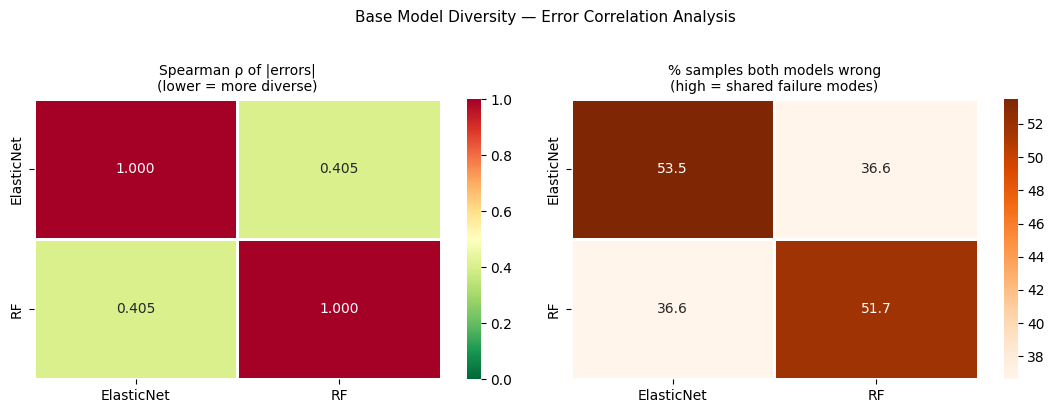

Saved: /kaggle/working/ckpt/error_correlation.png


In [45]:
# ══════════════════════════════════════════════════════════════════
# ERROR CORRELATION ANALYSIS — Base Model Diversity Check
# Spearman ρ of |errors| across all base models (OOF predictions)
# Lower ρ = more diverse = better ensemble candidates
# ══════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Collect OOF predictions for each base model (flat across all folds)
model_oof = {}

for name, bundles in [('ElasticNet', bundles_EN), ('RF', bundles_RF)]:
    preds, trues = [], []
    for b in bundles:
        preds.extend(np.asarray(b['y_pred']).astype(int).tolist())
        trues.extend(np.asarray(b['y_test']).astype(int).tolist())
    model_oof[name] = {'pred': np.array(preds), 'true': np.array(trues)}



# Compute absolute errors per model
model_names = list(model_oof.keys())
abs_errors = {name: np.abs(model_oof[name]['pred'] - model_oof[name]['true'])
              for name in model_names}

# Pairwise Spearman correlation matrix
n = len(model_names)
corr_matrix = np.zeros((n, n))
pval_matrix = np.zeros((n, n))

for i, n1 in enumerate(model_names):
    for j, n2 in enumerate(model_names):
        rho, pval = spearmanr(abs_errors[n1], abs_errors[n2])
        corr_matrix[i, j] = rho
        pval_matrix[i, j] = pval

corr_df = pd.DataFrame(corr_matrix, index=model_names, columns=model_names)
pval_df = pd.DataFrame(pval_matrix, index=model_names, columns=model_names)

# ── Print table ─────────────────────────────────────────────────
print('=' * 65)
print('  PAIRWISE ERROR CORRELATION (Spearman ρ of |errors|)')
print('  Lower = more diverse = better for ensembling')
print('=' * 65)
print(corr_df.round(4).to_string())
print()

# Print individual model QWK for context
print('  Individual model QWK (OOF):')
for name in model_names:
    true_arr = model_oof[name]['true']
    pred_arr = model_oof[name]['pred']
    qwk = cohen_kappa_score(true_arr, pred_arr, weights='quadratic')
    acc = accuracy_score(true_arr, pred_arr)
    print(f'    {name:<12}: QWK={qwk:.4f}  Acc={acc:.4f}  '
          f'Mean|err|={abs_errors[name].mean():.3f}')

print()
print('  Interpretation:')
print('    ρ < 0.5  → good diversity, ensembling should help')
print('    ρ > 0.8  → redundant pair, little gain from combining')

# ── Heatmap ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Correlation heatmap
sns.heatmap(corr_df, annot=True, fmt='.3f', cmap='RdYlGn_r',
            vmin=0, vmax=1, center=0.5,
            linewidths=1, ax=axes[0], cbar=True)
axes[0].set_title('Spearman ρ of |errors|\n(lower = more diverse)', fontsize=10)

# Agreement heatmap: % of samples where BOTH models are wrong
agree_wrong = np.zeros((n, n))
for i, n1 in enumerate(model_names):
    for j, n2 in enumerate(model_names):
        both_wrong = ((abs_errors[n1] > 0) & (abs_errors[n2] > 0)).mean()
        agree_wrong[i, j] = both_wrong
agree_df = pd.DataFrame(agree_wrong * 100, index=model_names, columns=model_names)
sns.heatmap(agree_df, annot=True, fmt='.1f', cmap='Oranges',
            linewidths=1, ax=axes[1], cbar=True)
axes[1].set_title('% samples both models wrong\n(high = shared failure modes)', fontsize=10)

plt.suptitle('Base Model Diversity — Error Correlation Analysis', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, 'error_correlation.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {os.path.join(CKPT_DIR, "error_correlation.png")}')

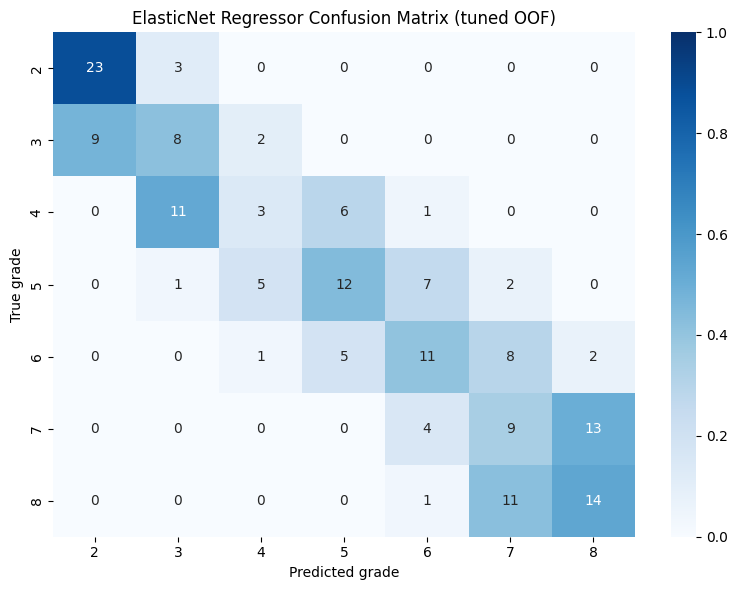

Accuracy: 0.46511627906976744
QWK: 0.9220332624734275
              precision    recall  f1-score   support

           2       0.72      0.88      0.79        26
           3       0.35      0.42      0.38        19
           4       0.27      0.14      0.19        21
           5       0.52      0.44      0.48        27
           6       0.46      0.41      0.43        27
           7       0.30      0.35      0.32        26
           8       0.48      0.54      0.51        26

    accuracy                           0.47       172
   macro avg       0.44      0.45      0.44       172
weighted avg       0.45      0.47      0.45       172



In [46]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, cohen_kappa_score

# Collect OOF true/pred labels from the tuned ElasticNet bundles
y_true_all = []
y_pred_all = []

for b in bundles_EN:
    y_true_all.extend(np.asarray(b['y_test']).astype(int).tolist())
    y_pred_all.extend(np.asarray(b['y_pred']).astype(int).tolist())

labels = np.arange(GRADE_MIN, GRADE_MAX + 1)

cm = confusion_matrix(y_true_all, y_pred_all, labels=labels)
cm_pct = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_pct,
    annot=cm,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    vmin=0,
    vmax=1
)
plt.xlabel('Predicted grade')
plt.ylabel('True grade')
plt.title('ElasticNet Regressor Confusion Matrix (tuned OOF)')
plt.tight_layout()
plt.show()

print('Accuracy:', accuracy_score(y_true_all, y_pred_all))
print('QWK:', cohen_kappa_score(y_true_all, y_pred_all, weights='quadratic'))
print(classification_report(y_true_all, y_pred_all, labels=labels, zero_division=0))

# SECTION 8 — Re-attach Tuned Pipelines + `collect_fold_outputs`

Pipelines are already fitted in Section 7 bundles. We expose the per-fold pipelines as `pipes_EN/pipes_RID/pipes_RF/pipes_SVR` and provide a single `collect_fold_outputs(fold_k)` that gathers everything every downstream component needs.

**Note (v4):** `LGBM_Classifier` has been removed from the base-model roster because its hyperparameter search was prohibitively slow on this dataset. Downstream cells (ensembles E1–E10, MLP-B/C, calibrated stacking, Telangana T2, transformer fusion) have been updated to operate on 3 base models contributing probabilities (EN, Ridge, RF) instead of 4.


In [47]:
pipes_EN  = [b['fitted_pipeline'] for b in bundles_EN]
pipes_RF  = [b['fitted_pipeline'] for b in bundles_RF]



In [48]:

# collect_fold_outputs: aggregates per-fold predictions from the 3 base models
# that contribute to ensembles (EN, Ridge, RF). LGBM has been removed; SVR is
# tuned but does not contribute classifier-style probabilities to the ensembles
# (it remains available via bundles_SVR/pipes_SVR for direct use if desired).
def collect_fold_outputs(fold_k):
    b_en, b_rid = bundles_EN[fold_k], bundles_RID[fold_k]
    b_rf        = bundles_RF[fold_k]

    train_idx = np.asarray(b_en['train_idx'], dtype=int)
    test_idx  = np.asarray(b_en['test_idx'],  dtype=int)

    feats_en, feats_rid = list(b_en['features']), list(b_rid['features'])
    feats_rf            = list(b_rf['features'])

    X_tr_en  = X_df[feats_en].values[train_idx]
    X_te_en  = X_df[feats_en].values[test_idx]
    X_tr_rid = X_df[feats_rid].values[train_idx]
    X_te_rid = X_df[feats_rid].values[test_idx]

    en_raw_test  = pipes_EN[fold_k].predict(X_te_en)
    en_raw_train = pipes_EN[fold_k].predict(X_tr_en)
    rid_raw_test = pipes_RID[fold_k].predict(X_te_rid)
    rid_raw_train= pipes_RID[fold_k].predict(X_tr_rid)

    rf_proba    = pipes_RF[fold_k].predict_proba(X_df[feats_rf].values[test_idx])
    rf_proba_tr = pipes_RF[fold_k].predict_proba(X_df[feats_rf].values[train_idx])

    weights = {
        'EN':    float(b_en.get('inner_cv_score', 0)  or 0),
        'Ridge': float(b_rid.get('inner_cv_score', 0) or 0),
        'RF':    float(b_rf.get('inner_cv_score', 0)  or 0),
    }

    return {
        'fold_k':       fold_k,
        'train_idx':    train_idx,
        'test_idx':     test_idx,
        'y_test':       y_float[test_idx].astype(int),
        'y_train_true': y_float[train_idx].astype(int),
        'en_raw_test':  en_raw_test,
        'en_raw_train': en_raw_train,
        'rid_raw_test': rid_raw_test,
        'rid_raw_train':rid_raw_train,
        'rf_proba':     rf_proba,
        'rf_proba_tr':  rf_proba_tr,
        'weights':      weights,
    }

print('collect_fold_outputs ready (3 base models: EN, Ridge, RF — LGBM removed).')


collect_fold_outputs ready (3 base models: EN, Ridge, RF — LGBM removed).


  DEEP ERROR ANALYSIS — RF_Classifier  (OOF)
  Predictions: 172
  Accuracy : 0.4826
  Within-1 : 0.9128
  QWK      : 0.9055
  F1 macro : 0.4692
  F1 weight: 0.4757


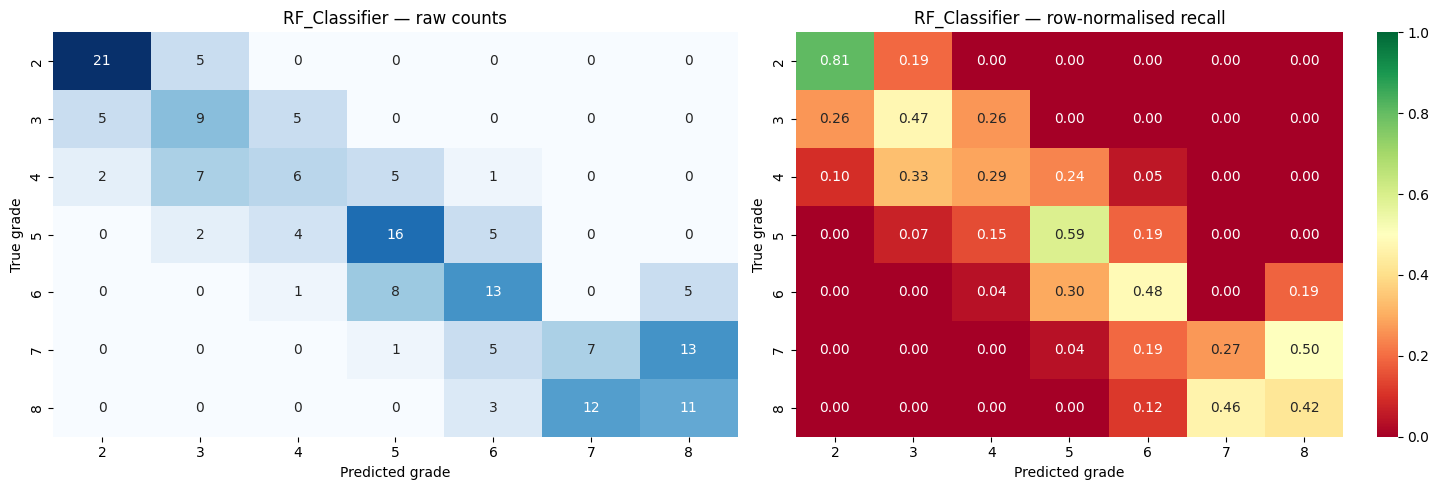

  Saved: /kaggle/working/ckpt/errana_RF_Classifier_confmat.png

  Per-grade breakdown:
       Support  Precision    Recall        F1  Exact  Adjacent  Far
Grade                                                              
2           26   0.750000  0.807692  0.777778     21         5    0
3           19   0.391304  0.473684  0.428571      9        10    0
4           21   0.375000  0.285714  0.324324      6        12    3
5           27   0.533333  0.592593  0.561404     16         9    2
6           27   0.481481  0.481481  0.481481     13         8    6
7           26   0.368421  0.269231  0.311111      7        18    1
8           26   0.379310  0.423077  0.400000     11        12    3

  Saved story-level predictions: /kaggle/working/ckpt/errana_RF_Classifier_story_predictions.csv
 story_index  true_grade  predicted_grade  error                                                                                                                                    text_snippet
          

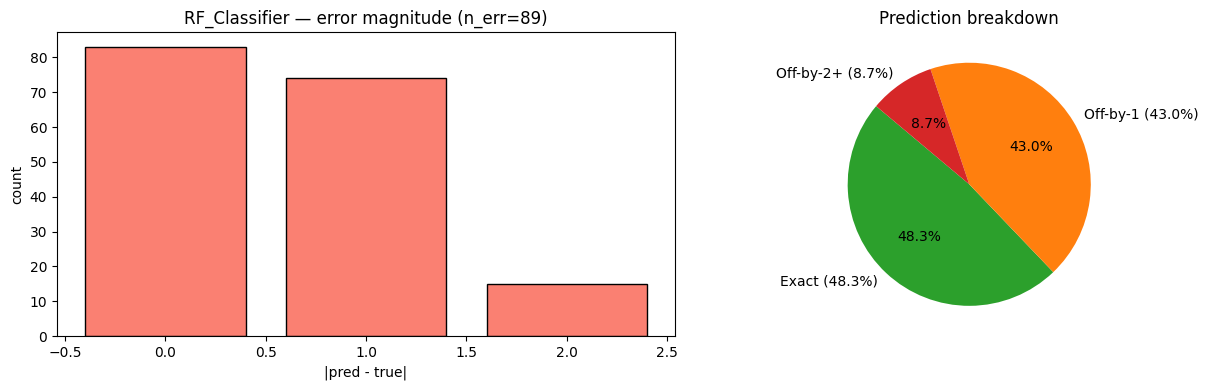

  Saved: /kaggle/working/ckpt/errana_RF_Classifier_error_dist.png

  Top-10 confusion pairs (true → predicted):
    Grade 7.0 → Grade 8.0: 13.0 times (7.6%)
    Grade 8.0 → Grade 7.0: 12.0 times (7.0%)
    Grade 6.0 → Grade 5.0: 8.0 times (4.7%)
    Grade 4.0 → Grade 3.0: 7.0 times (4.1%)
    Grade 3.0 → Grade 2.0: 5.0 times (2.9%)
    Grade 2.0 → Grade 3.0: 5.0 times (2.9%)
    Grade 6.0 → Grade 8.0: 5.0 times (2.9%)
    Grade 3.0 → Grade 4.0: 5.0 times (2.9%)
    Grade 4.0 → Grade 5.0: 5.0 times (2.9%)
    Grade 5.0 → Grade 6.0: 5.0 times (2.9%)
  Saved: /kaggle/working/ckpt/errana_RF_Classifier_confusion_pairs.csv


In [49]:
# ─── Deep Error Analysis — RF Classifier (OOF) ───────────────────────────────

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np, pandas as pd, os
from sklearn.metrics import (confusion_matrix, accuracy_score, f1_score,
                              cohen_kappa_score, precision_recall_fscore_support)

def _per_prediction_story_indices():
    abs_idx = []
    for fold_k in range(N_OUTER_FOLDS):
        _, te_idx = outer_splits[fold_k]
        abs_idx.extend(int(i) for i in te_idx)
    return abs_idx
all_story_indices = _per_prediction_story_indices()

# ── Collect OOF predictions (RF stores encoded labels → decode to grade space)
y_true_rf, y_pred_rf = [], []
for b in bundles_RF:
    y_te = le.inverse_transform(np.asarray(b['y_test']).astype(int))
    y_pr = le.inverse_transform(np.asarray(b['y_pred']).astype(int))
    y_true_rf.extend(y_te.tolist())
    y_pred_rf.extend(y_pr.tolist())

y_true_rf = np.array(y_true_rf)
y_pred_rf = np.array(y_pred_rf)
n         = len(y_true_rf)
grades    = sorted(set(y_true_rf.tolist()) | set(y_pred_rf.tolist()))
model_name = 'RF_Classifier'
safe_n     = model_name

# ── Headline metrics ────────────────────────────────────────────────────
print('=' * 90)
print(f'  DEEP ERROR ANALYSIS — {model_name}  (OOF)')
print('=' * 90)
print(f"  Predictions: {n}")
print(f"  Accuracy : {accuracy_score(y_true_rf, y_pred_rf):.4f}")
print(f"  Within-1 : {within_one(y_true_rf, y_pred_rf):.4f}")
print(f"  QWK      : {cohen_kappa_score(y_true_rf, y_pred_rf, weights='quadratic'):.4f}")
print(f"  F1 macro : {f1_score(y_true_rf, y_pred_rf, average='macro',    zero_division=0):.4f}")
print(f"  F1 weight: {f1_score(y_true_rf, y_pred_rf, average='weighted', zero_division=0):.4f}")

# ── Confusion matrix ────────────────────────────────────────────────────
cm      = confusion_matrix(y_true_rf, y_pred_rf, labels=grades)
cm_norm = cm.astype(float) / np.where(cm.sum(1, keepdims=True) > 0,
                                       cm.sum(1, keepdims=True), 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=grades, yticklabels=grades, ax=axes[0], cbar=False)
axes[0].set_xlabel('Predicted grade'); axes[0].set_ylabel('True grade')
axes[0].set_title(f'{model_name} — raw counts')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
            xticklabels=grades, yticklabels=grades, ax=axes[1])
axes[1].set_xlabel('Predicted grade'); axes[1].set_ylabel('True grade')
axes[1].set_title(f'{model_name} — row-normalised recall')
plt.tight_layout()
cm_path = os.path.join(CKPT_DIR, f'errana_{safe_n}_confmat.png')
plt.savefig(cm_path, dpi=150, bbox_inches='tight'); plt.show()
print(f'  Saved: {cm_path}')

# ── Per-grade precision / recall / F1 ───────────────────────────────────
p, r, f1, support = precision_recall_fscore_support(
    y_true_rf, y_pred_rf, labels=grades, zero_division=0)
grade_rows = []
for i, g in enumerate(grades):
    is_g = (y_true_rf == g)
    grade_rows.append({
        'Grade'    : int(g),
        'Support'  : int(is_g.sum()),
        'Precision': float(p[i]),
        'Recall'   : float(r[i]),
        'F1'       : float(f1[i]),
        'Exact'    : int((is_g & (y_pred_rf == g)).sum()),
        'Adjacent' : int((is_g & (np.abs(y_pred_rf - y_true_rf) == 1)).sum()),
        'Far'      : int((is_g & (np.abs(y_pred_rf - y_true_rf) >= 2)).sum()),
    })
grade_df = pd.DataFrame(grade_rows).set_index('Grade')
print('\n  Per-grade breakdown:')
print(grade_df.to_string())
grade_df.to_csv(os.path.join(CKPT_DIR, f'errana_{safe_n}_per_grade.csv'))

# ── Story-level prediction CSV ───────────────────────────────────────────
story_idx_arr = all_story_indices if len(all_story_indices) == n else list(range(n))
rows = []
for pos in range(n):
    s_i = story_idx_arr[pos]
    t, pp = int(y_true_rf[pos]), int(y_pred_rf[pos])
    rec = {
        'story_index'    : int(s_i),
        'true_grade'     : t,
        'predicted_grade': pp,
        'error'          : pp - t,
        'abs_error'      : abs(pp - t),
        'correct'        : bool(pp == t),
        'within_1'       : bool(abs(pp - t) <= 1),
    }
    if all_texts is not None and 0 <= s_i < len(all_texts):
        tx = str(all_texts[s_i])
        rec['text_snippet'] = tx[:140] + ('...' if len(tx) > 140 else '')
    rows.append(rec)
story_df  = pd.DataFrame(rows).sort_values(
    ['abs_error', 'story_index'], ascending=[False, True]).reset_index(drop=True)
story_csv = os.path.join(CKPT_DIR, f'errana_{safe_n}_story_predictions.csv')
story_df.to_csv(story_csv, index=False)
print(f'\n  Saved story-level predictions: {story_csv}')
cols = ['story_index', 'true_grade', 'predicted_grade', 'error']
if 'text_snippet' in story_df.columns: cols.append('text_snippet')
print(story_df[cols].head(10).to_string(index=False))

# ── Error-magnitude breakdown ────────────────────────────────────────────
err    = np.abs(y_pred_rf - y_true_rf)
max_e  = int(err.max()) if len(err) else 0
counts = [int((err == d).sum()) for d in range(max_e + 1)]
sizes  = [int((err == 0).sum()), int((err == 1).sum()), int((err >= 2).sum())]
pcts   = [100 * s / n for s in sizes]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(max_e + 1), counts, color='salmon', edgecolor='black')
axes[0].set_xlabel('|pred - true|'); axes[0].set_ylabel('count')
axes[0].set_title(f'{model_name} — error magnitude (n_err={int((err > 0).sum())})')
axes[1].pie(sizes,
            labels=[f'Exact ({pcts[0]:.1f}%)',
                    f'Off-by-1 ({pcts[1]:.1f}%)',
                    f'Off-by-2+ ({pcts[2]:.1f}%)'],
            colors=['#2ca02c', '#ff7f0e', '#d62728'],
            autopct='%1.1f%%', startangle=140)
axes[1].set_title('Prediction breakdown')
plt.tight_layout()
err_path = os.path.join(CKPT_DIR, f'errana_{safe_n}_error_dist.png')
plt.savefig(err_path, dpi=150, bbox_inches='tight'); plt.show()
print(f'  Saved: {err_path}')

# ── Confusion pairs CSV ──────────────────────────────────────────────────
pairs = []
for i, tg in enumerate(grades):
    for j, pg in enumerate(grades):
        if tg != pg and cm[i, j] > 0:
            pairs.append({'true': int(tg), 'predicted': int(pg),
                          'count': int(cm[i, j]),
                          'pct_of_all': 100.0 * cm[i, j] / n})
pairs_df  = pd.DataFrame(pairs).sort_values('count', ascending=False)
pairs_csv = os.path.join(CKPT_DIR, f'errana_{safe_n}_confusion_pairs.csv')
pairs_df.to_csv(pairs_csv, index=False)
print(f'\n  Top-10 confusion pairs (true → predicted):')
for _, row in pairs_df.head(10).iterrows():
    print(f'    Grade {row["true"]} → Grade {row["predicted"]}: '
          f'{row["count"]} times ({row["pct_of_all"]:.1f}%)')
print(f'  Saved: {pairs_csv}')

  DEEP ERROR ANALYSIS — ElasticNet_Regressor  (OOF)
  Predictions: 172
  Accuracy : 0.4651
  Within-1 : 0.9535
  QWK      : 0.9220
  F1 macro : 0.4433
  F1 weight: 0.4535


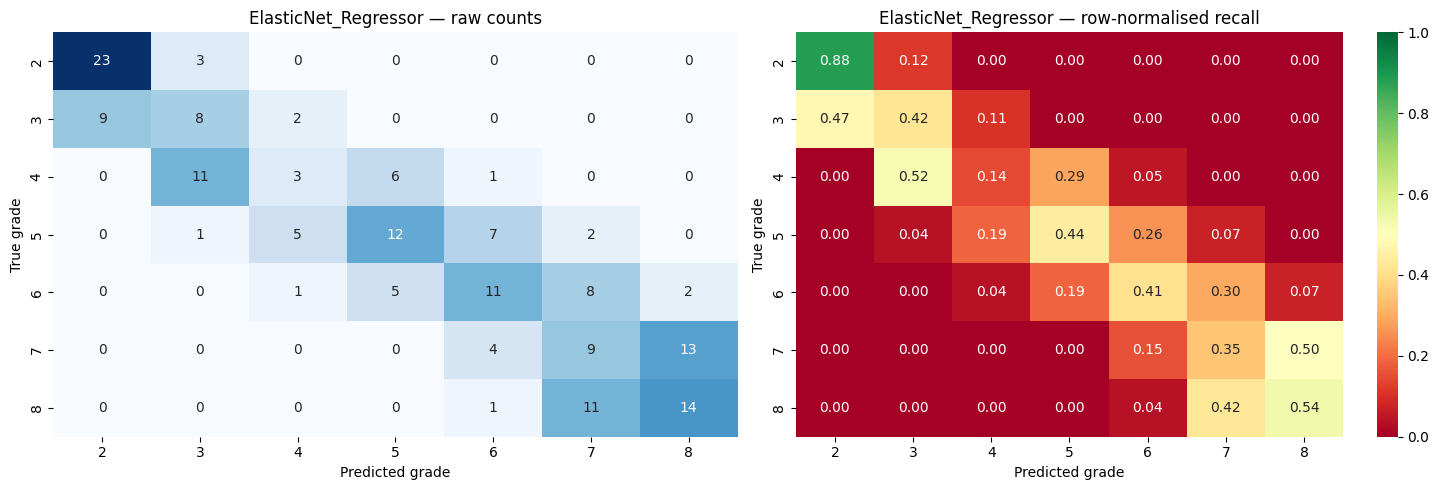

  Saved: /kaggle/working/ckpt/errana_ElasticNet_Regressor_confmat.png

  Per-grade breakdown:
       Support  Precision    Recall        F1  Exact  Adjacent  Far
Grade                                                              
2           26   0.718750  0.884615  0.793103     23         3    0
3           19   0.347826  0.421053  0.380952      8        11    0
4           21   0.272727  0.142857  0.187500      3        17    1
5           27   0.521739  0.444444  0.480000     12        12    3
6           27   0.458333  0.407407  0.431373     11        13    3
7           26   0.300000  0.346154  0.321429      9        17    0
8           26   0.482759  0.538462  0.509091     14        11    1

  Saved story-level predictions: /kaggle/working/ckpt/errana_ElasticNet_Regressor_story_predictions.csv
 story_index  true_grade  predicted_grade  error                                                                                                                                    text_snip

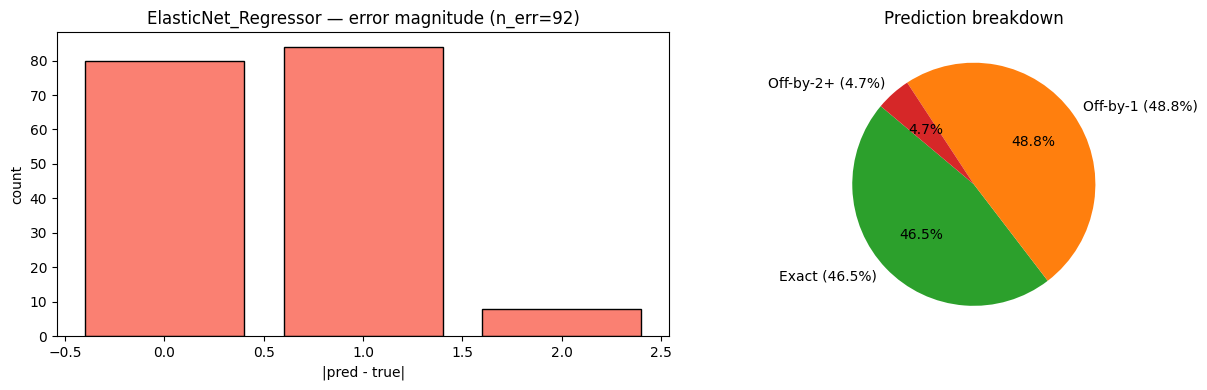

  Saved: /kaggle/working/ckpt/errana_ElasticNet_Regressor_error_dist.png

  Top-10 confusion pairs (true → predicted):
    Grade 7.0 → Grade 8.0: 13.0 times (7.6%)
    Grade 4.0 → Grade 3.0: 11.0 times (6.4%)
    Grade 8.0 → Grade 7.0: 11.0 times (6.4%)
    Grade 3.0 → Grade 2.0: 9.0 times (5.2%)
    Grade 6.0 → Grade 7.0: 8.0 times (4.7%)
    Grade 5.0 → Grade 6.0: 7.0 times (4.1%)
    Grade 4.0 → Grade 5.0: 6.0 times (3.5%)
    Grade 6.0 → Grade 5.0: 5.0 times (2.9%)
    Grade 5.0 → Grade 4.0: 5.0 times (2.9%)
    Grade 7.0 → Grade 6.0: 4.0 times (2.3%)
  Saved: /kaggle/working/ckpt/errana_ElasticNet_Regressor_confusion_pairs.csv


In [50]:
# ─── Deep Error Analysis — ElasticNet Regressor (OOF) ────────────────────────

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np, pandas as pd, os
from sklearn.metrics import (confusion_matrix, accuracy_score, f1_score,
                              cohen_kappa_score, precision_recall_fscore_support)

# ── Collect OOF predictions (EN works directly in grade space, no decoding)
y_true_en, y_pred_en = [], []
for b in bundles_EN:
    y_true_en.extend(np.asarray(b['y_test']).astype(int).tolist())
    y_pred_en.extend(np.asarray(b['y_pred']).astype(int).tolist())

y_true_en = np.array(y_true_en)
y_pred_en = np.array(y_pred_en)
n         = len(y_true_en)
grades    = sorted(set(y_true_en.tolist()) | set(y_pred_en.tolist()))
model_name = 'ElasticNet_Regressor'
safe_n     = model_name

# ── Headline metrics ────────────────────────────────────────────────────
print('=' * 90)
print(f'  DEEP ERROR ANALYSIS — {model_name}  (OOF)')
print('=' * 90)
print(f"  Predictions: {n}")
print(f"  Accuracy : {accuracy_score(y_true_en, y_pred_en):.4f}")
print(f"  Within-1 : {within_one(y_true_en, y_pred_en):.4f}")
print(f"  QWK      : {cohen_kappa_score(y_true_en, y_pred_en, weights='quadratic'):.4f}")
print(f"  F1 macro : {f1_score(y_true_en, y_pred_en, average='macro',    zero_division=0):.4f}")
print(f"  F1 weight: {f1_score(y_true_en, y_pred_en, average='weighted', zero_division=0):.4f}")

# ── Confusion matrix ────────────────────────────────────────────────────
cm      = confusion_matrix(y_true_en, y_pred_en, labels=grades)
cm_norm = cm.astype(float) / np.where(cm.sum(1, keepdims=True) > 0,
                                       cm.sum(1, keepdims=True), 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=grades, yticklabels=grades, ax=axes[0], cbar=False)
axes[0].set_xlabel('Predicted grade'); axes[0].set_ylabel('True grade')
axes[0].set_title(f'{model_name} — raw counts')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
            xticklabels=grades, yticklabels=grades, ax=axes[1])
axes[1].set_xlabel('Predicted grade'); axes[1].set_ylabel('True grade')
axes[1].set_title(f'{model_name} — row-normalised recall')
plt.tight_layout()
cm_path = os.path.join(CKPT_DIR, f'errana_{safe_n}_confmat.png')
plt.savefig(cm_path, dpi=150, bbox_inches='tight'); plt.show()
print(f'  Saved: {cm_path}')

# ── Per-grade precision / recall / F1 ───────────────────────────────────
p, r, f1, support = precision_recall_fscore_support(
    y_true_en, y_pred_en, labels=grades, zero_division=0)
grade_rows = []
for i, g in enumerate(grades):
    is_g = (y_true_en == g)
    grade_rows.append({
        'Grade'    : int(g),
        'Support'  : int(is_g.sum()),
        'Precision': float(p[i]),
        'Recall'   : float(r[i]),
        'F1'       : float(f1[i]),
        'Exact'    : int((is_g & (y_pred_en == g)).sum()),
        'Adjacent' : int((is_g & (np.abs(y_pred_en - y_true_en) == 1)).sum()),
        'Far'      : int((is_g & (np.abs(y_pred_en - y_true_en) >= 2)).sum()),
    })
grade_df = pd.DataFrame(grade_rows).set_index('Grade')
print('\n  Per-grade breakdown:')
print(grade_df.to_string())
grade_df.to_csv(os.path.join(CKPT_DIR, f'errana_{safe_n}_per_grade.csv'))

# ── Story-level prediction CSV ───────────────────────────────────────────
story_idx_arr = all_story_indices if len(all_story_indices) == n else list(range(n))
rows = []
for pos in range(n):
    s_i = story_idx_arr[pos]
    t, pp = int(y_true_en[pos]), int(y_pred_en[pos])
    rec = {
        'story_index'    : int(s_i),
        'true_grade'     : t,
        'predicted_grade': pp,
        'error'          : pp - t,
        'abs_error'      : abs(pp - t),
        'correct'        : bool(pp == t),
        'within_1'       : bool(abs(pp - t) <= 1),
    }
    if all_texts is not None and 0 <= s_i < len(all_texts):
        tx = str(all_texts[s_i])
        rec['text_snippet'] = tx[:140] + ('...' if len(tx) > 140 else '')
    rows.append(rec)
story_df  = pd.DataFrame(rows).sort_values(
    ['abs_error', 'story_index'], ascending=[False, True]).reset_index(drop=True)
story_csv = os.path.join(CKPT_DIR, f'errana_{safe_n}_story_predictions.csv')
story_df.to_csv(story_csv, index=False)
print(f'\n  Saved story-level predictions: {story_csv}')
cols = ['story_index', 'true_grade', 'predicted_grade', 'error']
if 'text_snippet' in story_df.columns: cols.append('text_snippet')
print(story_df[cols].head(10).to_string(index=False))

# ── Error-magnitude breakdown ────────────────────────────────────────────
err    = np.abs(y_pred_en - y_true_en)
max_e  = int(err.max()) if len(err) else 0
counts = [int((err == d).sum()) for d in range(max_e + 1)]
sizes  = [int((err == 0).sum()), int((err == 1).sum()), int((err >= 2).sum())]
pcts   = [100 * s / n for s in sizes]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(max_e + 1), counts, color='salmon', edgecolor='black')
axes[0].set_xlabel('|pred - true|'); axes[0].set_ylabel('count')
axes[0].set_title(f'{model_name} — error magnitude (n_err={int((err > 0).sum())})')
axes[1].pie(sizes,
            labels=[f'Exact ({pcts[0]:.1f}%)',
                    f'Off-by-1 ({pcts[1]:.1f}%)',
                    f'Off-by-2+ ({pcts[2]:.1f}%)'],
            colors=['#2ca02c', '#ff7f0e', '#d62728'],
            autopct='%1.1f%%', startangle=140)
axes[1].set_title('Prediction breakdown')
plt.tight_layout()
err_path = os.path.join(CKPT_DIR, f'errana_{safe_n}_error_dist.png')
plt.savefig(err_path, dpi=150, bbox_inches='tight'); plt.show()
print(f'  Saved: {err_path}')

# ── Confusion pairs CSV ──────────────────────────────────────────────────
pairs = []
for i, tg in enumerate(grades):
    for j, pg in enumerate(grades):
        if tg != pg and cm[i, j] > 0:
            pairs.append({'true': int(tg), 'predicted': int(pg),
                          'count': int(cm[i, j]),
                          'pct_of_all': 100.0 * cm[i, j] / n})
pairs_df  = pd.DataFrame(pairs).sort_values('count', ascending=False)
pairs_csv = os.path.join(CKPT_DIR, f'errana_{safe_n}_confusion_pairs.csv')
pairs_df.to_csv(pairs_csv, index=False)
print(f'\n  Top-10 confusion pairs (true → predicted):')
for _, row in pairs_df.head(10).iterrows():
    print(f'    Grade {row["true"]} → Grade {row["predicted"]}: '
          f'{row["count"]} times ({row["pct_of_all"]:.1f}%)')
print(f'  Saved: {pairs_csv}')

# CROSS CORPUS VALIDATION

In [51]:
# ── Normalisation helpers & function ─────────────────────────────────────────

def _is_integer_valued(series):
    vals = pd.to_numeric(series, errors='coerce').dropna().to_numpy()
    if vals.size == 0:
        return False
    return np.allclose(vals, np.round(vals))


RAW_COUNT_EXCLUDE = {
    'DESPL', 'DESPLd',
    'grapheme_count_per_word',
    'phoneme_count_per_word',
}

ALREADY_NORMALIZED = {
    'WRDPRP1s', 'WRDPRP1p', 'WRDPRP2', 'WRDPRP3s', 'WRDPRP3p',
    'WRDNOUN', 'WRDVERB', 'WRDADJ', 'WRDADV',
    'SYNSTRUTa', 'SYNSTRUTd', 'SYNSTRUTe', 'SYNSTRUTt',
    'DESSC', 'DESSL', 'DESSLd',
}

RAW_COUNT_EXACT = {
    'DESPC',
    'aggregates.syllable_count', 'aggregates.polysyllabcount', 'aggregates.monosyllabcount',
    'maxMorphCount', 'polyMorphCount', 'polyMorphStanza',
    't_n_ent', 't_n_ent_person', 't_n_ent_norp', 't_n_ent_fac', 't_n_ent_org',
    't_n_ent_gpe', 't_n_ent_loc', 't_n_ent_product', 't_n_ent_event', 't_n_ent_art',
    't_n_ent_law', 't_n_ent_language', 't_n_ent_date', 't_n_ent_time', 't_n_ent_percent',
    't_n_ent_money', 't_n_ent_quantity', 't_n_ent_ordinal', 't_n_ent_cardinal',
    'ent.total_entities', 'ent.total_unique_entities',
    'total_free_morphemes', 'total_bound_morphemes',
    't_punct', 't_stopword',
    't_syll', 't_syll2', 't_syll3',
    't_uword', 't_char',
    'total_kuperman_aoa', 'total_brysbaert_aoa', 'total_subtlex_us_zipf',
    't_kup', 't_bry', 't_subtlex_us_zipf',
    'character_count',
}

FORCE_NORMALIZE = {
    't_kup', 't_bry', 't_subtlex_us_zipf',
    'total_kuperman_aoa', 'total_brysbaert_aoa', 'total_subtlex_us_zipf',
}

EXCLUDE_PATTERNS = [
    '_pw', '_ps', '_var', '_density', '_ratio', '_norm',
    '_avg', '_mean', '_sd', 'average', 'mean', 'score', 'incidence',
]


def _is_raw_count_col(col_name, series):
    name  = col_name.strip()
    lower = name.lower()

    if name in FORCE_NORMALIZE:                                    return True
    if name in RAW_COUNT_EXCLUDE:                                  return False
    if name in ALREADY_NORMALIZED:                                 return False
    if any(k in lower for k in EXCLUDE_PATTERNS):                 return False
    if name in RAW_COUNT_EXACT:                                    return _is_integer_valued(series)
    if (lower.startswith('to_') or lower.startswith('n_') or
            lower.startswith('t_n_') or lower.startswith('count') or
            lower.startswith('total_') or lower.endswith('_count')):
                                                                   return _is_integer_valued(series)
    if lower.startswith('t_') and name not in ['t_word', 't_sent']:
                                                                   return _is_integer_valued(series)
    if '_n_' in lower:                                             return _is_integer_valued(series)
    return False


def normalize_raw_counts(df, present, word_count_col, extra_exclude=None, verbose=True):
    """
    Normalize raw count features to per-100-words density.

    Parameters
    ----------
    df             : DataFrame to normalize (will be copied).
    present        : List of feature column names to consider (excludes label/text cols).
    word_count_col : Column name holding per-row word counts (e.g. 't_word').
    extra_exclude  : Optional set of additional column names to skip (e.g. label/text cols).
    verbose        : Print normalisation summary if True.

    Returns
    -------
    df_out     : Normalised copy of df.
    count_cols : List of columns that were normalised.
    """
    extra_exclude = set(extra_exclude or [])
    exclude       = {word_count_col} | extra_exclude

    # Step 1: pattern-based detection
    count_cols = [
        c for c in present
        if c not in exclude and _is_raw_count_col(c, df[c])
    ]

    # Step 2: force-add AoA / Zipf raw sums (in case stored as float and missed above)
    for col in FORCE_NORMALIZE:
        if col in present and col not in count_cols and col not in exclude:
            count_cols.append(col)
            if verbose:
                print(f'FORCE adding {col} for normalization')

    # Step 3: explicit safety-net add-back for to_*, total_*, DESPC, t_*
    for c in present:
        if c in count_cols or c in exclude:
            continue
        if c == 'DESPC' and _is_integer_valued(df[c]):
            count_cols.append(c)
        elif c.startswith(('to_', 'total_')) and _is_integer_valued(df[c]):
            count_cols.append(c)
        elif c.startswith('t_') and c not in ['t_word', 't_sent'] and _is_integer_valued(df[c]):
            count_cols.append(c)

    # Step 4: dedup
    count_cols = list(set(count_cols))

    # Step 5: apply normalisation
    df_out = df.copy()
    if word_count_col is not None and count_cols:
        word_counts = df_out[word_count_col].replace(0, np.nan)
        for col in count_cols:
            df_out[col] = (df_out[col] / word_counts) * 100
        df_out[present] = df_out[present].fillna(0)

        if verbose:
            print(f'Normalised {len(count_cols)} raw count features → density per 100 words')
            print('\nFirst 25 normalized features:')
            for idx, feat in enumerate(sorted(count_cols)[:25], start=1):
                print(f'{idx:>3}. {feat}')

            excluded     = [c for c in present if c not in exclude and not _is_raw_count_col(c, df[c])]
            already_norm = [c for c in excluded if c in ALREADY_NORMALIZED
                            or any(p in c.lower() for p in ['_pw', '_ps', 'incidence', '_sd', '_mean'])]
            print(f'\nSkipped normalisation for {len(excluded)} features '
                  f'(already density/incidence/ratio/average/SD)')
            print(f'  - {len(already_norm)} were explicitly identified as already-normalized')

            print('\nAll normalized features (full list):')
            for idx, feat in enumerate(sorted(count_cols), start=1):
                print(f'{idx:>3}. {feat}')

            total_features = [f for f in count_cols if f.startswith('total_')]
            t_features     = [f for f in count_cols if f.startswith('t_') and f not in ['t_word', 't_sent']]
            if total_features:
                print(f'\n--- total_ features normalized ({len(total_features)}): ---')
                for f in total_features: print(f'  - {f}')
            if t_features:
                print(f'\n--- t_ features normalized ({len(t_features)}): ---')
                for f in t_features: print(f'  - {f}')
    else:
        df_out[present] = df_out[present].fillna(0)
        if verbose:
            if not count_cols:
                print('No raw count features found for normalisation.')
            else:
                print('Normalisation skipped. NaN fill applied.')

    return df_out, count_cols

In [52]:
# ─── T1: Load Telangana + apply IDENTICAL preprocessing as NCERT ────────────
import os, numpy as np, pandas as pd

# ── 1. Paths ────────────────────────────────────────────────────────────────
if IN_COLAB:
    TELANGANA_PATH = '/kaggle/input/datasets/maureenmiranda11/18-05-26/final_telangana_dataset.xlsx'
else:
    TELANGANA_PATH = '/kaggle/input/datasets/maureenmiranda11/18-05-26/final_telangana_dataset.xlsx'

TELANGANA_LABEL_COL = 'grade'
TELANGANA_TEXT_COL  = 'content'

assert os.path.exists(TELANGANA_PATH), f'Telangana file not found: {TELANGANA_PATH}'
df_tel_raw = (pd.read_excel(TELANGANA_PATH)
              if TELANGANA_PATH.endswith(('.xlsx', '.xls'))
              else pd.read_csv(TELANGANA_PATH))
df_tel_raw.columns = df_tel_raw.columns.str.strip()
print(f'Telangana raw shape: {df_tel_raw.shape}')

# ── 2. Validate labels ──────────────────────────────────────────────────────
assert TELANGANA_LABEL_COL in df_tel_raw.columns, (
    f'Label column {TELANGANA_LABEL_COL!r} not found. '
    f'Available: {list(df_tel_raw.columns)[:20]}'
)
y_tel_int = pd.to_numeric(df_tel_raw[TELANGANA_LABEL_COL], errors='coerce').astype('Int64')
n_bad = int(y_tel_int.isna().sum())
if n_bad:
    print(f'WARNING: {n_bad} non-numeric grades — dropping rows')
    df_tel_raw = df_tel_raw.loc[y_tel_int.notna()].reset_index(drop=True)
    y_tel_int  = y_tel_int.dropna().reset_index(drop=True)
y_tel_int = y_tel_int.astype(int)

tel_min, tel_max = int(y_tel_int.min()), int(y_tel_int.max())
print(f'Telangana grade range: [{tel_min}, {tel_max}]   '
      f'(NCERT: [{GRADE_MIN}, {GRADE_MAX}])')
if tel_min < GRADE_MIN or tel_max > GRADE_MAX:
    print('WARNING: clipping Telangana grades into NCERT range')
    y_tel_int = y_tel_int.clip(GRADE_MIN, GRADE_MAX)

if TELANGANA_TEXT_COL and TELANGANA_TEXT_COL in df_tel_raw.columns:
    texts_tel = df_tel_raw[TELANGANA_TEXT_COL].astype(str).tolist()
    print(f'texts_tel: {len(texts_tel)} strings loaded')
else:
    texts_tel = None
    print('NOTE: text column absent — textstat columns must already be present')

# ── 3. Textstat augmentation  (mirrors cell 2B) ─────────────────────────────
try:
    import textstat
except Exception:
    %pip install -q textstat
    import textstat

def _safe_textstat(fn, t, default=np.nan):
    try:    return fn(t)
    except: return default

if texts_tel is not None:
    _txt_series = pd.Series(texts_tel, index=df_tel_raw.index).fillna('').astype(str)
    if 'textstat.linsear_write_formula' not in df_tel_raw.columns:
        df_tel_raw['textstat.linsear_write_formula'] = _txt_series.apply(
            lambda t: _safe_textstat(textstat.linsear_write_formula, t))
    if 'textstat.reading_time' not in df_tel_raw.columns:
        df_tel_raw['textstat.reading_time'] = _txt_series.apply(
            lambda t: _safe_textstat(textstat.reading_time, t))
    if 'textstat.spache_readability' not in df_tel_raw.columns:
        df_tel_raw['textstat.spache_readability'] = _txt_series.apply(
            lambda t: _safe_textstat(textstat.spache_readability, t))
    if 'textstat.text_standard' not in df_tel_raw.columns:
        df_tel_raw['textstat.text_standard'] = _txt_series.apply(
            lambda t: _safe_textstat(
                lambda x: textstat.text_standard(x, float_output=True), t))
    print('  textstat columns added (or already present).')



# Build present_tel: feature columns only (exclude label, text, word-count)
present_tel = [
    c for c in df_tel_raw.columns
    if c not in {TELANGANA_LABEL_COL, TELANGANA_TEXT_COL, WORD_COUNT_COL}
]

df_tel_norm, tel_count_cols = normalize_raw_counts(
    df_tel_raw, present_tel,'t_word',
    extra_exclude={TELANGANA_LABEL_COL, TELANGANA_TEXT_COL},
    verbose=True
)

# ── 5. Feature alignment to NCERT's post-cleanup column list ────────────────
ncert_features  = list(feature_names)
tel_cols_set    = set(df_tel_norm.columns)
missing_in_tel  = [f for f in ncert_features if f not in tel_cols_set]
print(f'  NCERT features missing from Telangana: {len(missing_in_tel)}'
      + (f'  e.g. {missing_in_tel[:6]}' if missing_in_tel else ''))

X_tel_df = pd.DataFrame(index=df_tel_norm.index,
                         columns=ncert_features, dtype=float)
for f in ncert_features:
    if f in df_tel_norm.columns:
        X_tel_df[f] = pd.to_numeric(df_tel_norm[f], errors='coerce')
    else:
        X_tel_df[f] = np.nan

# ── 6. Impute NaN with NCERT-side medians ───────────────────────────────────
n_nan_before  = int(X_tel_df.isna().sum().sum())
ncert_medians = X_df.median(axis=0)
for f in ncert_features:
    if X_tel_df[f].isna().any():
        med = ncert_medians.get(f, np.nan)
        X_tel_df[f] = X_tel_df[f].fillna(0.0 if pd.isna(med) else float(med))
n_nan_after = int(X_tel_df.isna().sum().sum())
print(f'  NaN fill (NCERT medians): {n_nan_before} → {n_nan_after}')

X_tel_df = X_tel_df.astype(np.float64)
assert np.isfinite(X_tel_df.values).all(), 'X_tel_df has non-finite values'

y_tel = y_tel_int.values.astype(int)
n_tel = len(y_tel)
print(f'\n{"═"*70}')
print(f'  Telangana ready (NCERT-parity preprocessing complete)')
print(f'{"═"*70}')
print(f'  X_tel_df shape  : {X_tel_df.shape}')
print(f'  n samples       : {n_tel}')
print(f'  Class counts    : {dict(zip(*np.unique(y_tel, return_counts=True)))}')
if n_tel < 35:
    print(f'  NOTE: n={n_tel} is small for 5-fold CV (~{n_tel // 5}/fold)')

Telangana raw shape: (71, 707)
Telangana grade range: [2, 8]   (NCERT: [2, 8])
texts_tel: 71 strings loaded
  textstat columns added (or already present).
Normalised 88 raw count features → density per 100 words

First 25 normalized features:
  1. DESPC
  2. character_count
  3. n_adj
  4. n_adp
  5. n_adv
  6. n_aux
  7. n_cconj
  8. n_det
  9. n_intj
 10. n_noun
 11. n_num
 12. n_part
 13. n_pron
 14. n_propn
 15. n_punct
 16. n_sconj
 17. n_space
 18. n_sym
 19. n_uadj
 20. n_uadp
 21. n_uadv
 22. n_uaux
 23. n_ucconj
 24. n_udet
 25. n_uintj

Skipped normalisation for 620 features (already density/incidence/ratio/average/SD)
  - 105 were explicitly identified as already-normalized

All normalized features (full list):
  1. DESPC
  2. character_count
  3. n_adj
  4. n_adp
  5. n_adv
  6. n_aux
  7. n_cconj
  8. n_det
  9. n_intj
 10. n_noun
 11. n_num
 12. n_part
 13. n_pron
 14. n_propn
 15. n_punct
 16. n_sconj
 17. n_space
 18. n_sym
 19. n_uadj
 20. n_uadp
 21. n_uadv
 22. n_uau

In [53]:
# ────────────────────────────────────────────────────────────────────────────
# 5. FEATURE ALIGNMENT to NCERT's post-cleanup column list (= feature_names)
#    Telangana columns absent from NCERT are dropped silently.
#    NCERT columns absent from Telangana get NaN here, then are filled in (6).
# ────────────────────────────────────────────────────────────────────────────
ncert_features = list(feature_names)
tel_cols_set    = set(df_tel_norm.columns)
missing_in_tel = [f for f in ncert_features if f not in tel_cols_set]
print(f'  NCERT features missing from Telangana: {len(missing_in_tel)}'
      + (f'  e.g. {missing_in_tel[:6]}' if missing_in_tel else ''))

X_tel_df = pd.DataFrame(index=df_tel_norm.index,
                         columns=ncert_features, dtype=float)
for f in ncert_features:
    if f in df_tel_norm.columns:
        X_tel_df[f] = pd.to_numeric(df_tel_norm[f], errors='coerce')
    else:
        X_tel_df[f] = np.nan

  NCERT features missing from Telangana: 0


In [54]:
# ────────────────────────────────────────────────────────────────────────────
# 6. IMPUTE NaN  with NCERT-side medians (X_df is already normalised).
#    Using NCERT (source) medians keeps Telangana a pure test set:
#      • No Telangana-side statistic influences the imputed value.
#      • No information flows across Telangana folds during the T2M mapping.
# ────────────────────────────────────────────────────────────────────────────
n_nan_before = int(X_tel_df.isna().sum().sum())
ncert_medians = X_df.median(axis=0)        # NCERT-side medians (normalised)
for f in ncert_features:
    if X_tel_df[f].isna().any():
        med = ncert_medians.get(f, np.nan)
        X_tel_df[f] = X_tel_df[f].fillna(0.0 if pd.isna(med) else float(med))
n_nan_after = int(X_tel_df.isna().sum().sum())
print(f'  NaN fill (NCERT medians): {n_nan_before} → {n_nan_after}')

X_tel_df = X_tel_df.astype(np.float64)
assert np.isfinite(X_tel_df.values).all(), 'X_tel_df has non-finite values'

y_tel = y_tel_int.values.astype(int)
n_tel = len(y_tel)
print(f'\n══════════════════════════════════════════════════════════════════════')
print(f'  Telangana ready (NCERT-parity preprocessing complete)')
print(f'══════════════════════════════════════════════════════════════════════')
print(f'  X_tel_df shape       : {X_tel_df.shape}')
print(f'  n samples            : {n_tel}')
print(f'  Class counts         : {dict(zip(*np.unique(y_tel, return_counts=True)))}')
if n_tel < 35:
    print(f'  NOTE: n={n_tel} is small for 5-fold CV (~{n_tel // 5}/fold)')


  NaN fill (NCERT medians): 0 → 0

══════════════════════════════════════════════════════════════════════
  Telangana ready (NCERT-parity preprocessing complete)
══════════════════════════════════════════════════════════════════════
  X_tel_df shape       : (71, 502)
  n samples            : 71
  Class counts         : {np.int64(2): np.int64(8), np.int64(3): np.int64(7), np.int64(4): np.int64(9), np.int64(5): np.int64(8), np.int64(6): np.int64(15), np.int64(7): np.int64(12), np.int64(8): np.int64(12)}


In [55]:
import os, numpy as np, pandas as pd

# ── 1. Paths ────────────────────────────────────────────────────────────────
if IN_COLAB:
    TELANGANA_PATH = '/kaggle/input/datasets/maureenmiranda11/18-05-26/final_telangana_dataset.xlsx'
else:
    TELANGANA_PATH = '/kaggle/input/datasets/maureenmiranda11/18-05-26/final_telangana_dataset.xlsx'

TELANGANA_LABEL_COL = 'grade'
TELANGANA_TEXT_COL  = 'content'   # set to None if column absent

assert os.path.exists(TELANGANA_PATH), f'Telangana file not found: {TELANGANA_PATH}'
df_tel_raw = (pd.read_excel(TELANGANA_PATH)
              if TELANGANA_PATH.endswith(('.xlsx', '.xls'))
              else pd.read_csv(TELANGANA_PATH))
df_tel_raw.columns = df_tel_raw.columns.str.strip()
print(f'Telangana raw shape: {df_tel_raw.shape}')

# ── 2. Validate labels ─────────────────────────────────────────────────────
assert TELANGANA_LABEL_COL in df_tel_raw.columns, (
    f'Label column {TELANGANA_LABEL_COL!r} not found. '
    f'Available: {list(df_tel_raw.columns)[:20]}'
)
y_tel_int = pd.to_numeric(df_tel_raw[TELANGANA_LABEL_COL], errors='coerce').astype('Int64')
n_bad = int(y_tel_int.isna().sum())
if n_bad:
    print(f'WARNING: {n_bad} non-numeric grades — dropping rows')
    df_tel_raw = df_tel_raw.loc[y_tel_int.notna()].reset_index(drop=True)
    y_tel_int  = y_tel_int.dropna().reset_index(drop=True)
y_tel_int = y_tel_int.astype(int)
tel_min, tel_max = int(y_tel_int.min()), int(y_tel_int.max())
print(f'Telangana grade range: [{tel_min}, {tel_max}]   '
      f'(NCERT: [{GRADE_MIN}, {GRADE_MAX}])')
if tel_min < GRADE_MIN or tel_max > GRADE_MAX:
    print('WARNING: clipping Telangana grades into NCERT range')
    y_tel_int = y_tel_int.clip(GRADE_MIN, GRADE_MAX)

# Keep texts for record-keeping AND for textstat augmentation below
if TELANGANA_TEXT_COL and TELANGANA_TEXT_COL in df_tel_raw.columns:
    texts_tel = df_tel_raw[TELANGANA_TEXT_COL].astype(str).tolist()
    print(f'texts_tel: {len(texts_tel)} strings loaded')
else:
    texts_tel = None
    print(f'NOTE: text column absent — textstat columns must already be present')

# ────────────────────────────────────────────────────────────────────────────
# 3. TEXTSTAT AUGMENTATION  (mirrors cell 2B for NCERT)
#    Add the four textstat columns iff missing AND a text column is available.
# ────────────────────────────────────────────────────────────────────────────
try:
    import textstat
except Exception:
    %pip install -q textstat
    import textstat

def _safe_textstat(fn, t, default=np.nan):
    try:
        return fn(t)
    except Exception:
        return default

if texts_tel is not None:
    _txt_series = pd.Series(texts_tel, index=df_tel_raw.index).fillna('').astype(str)
    if 'textstat.linsear_write_formula' not in df_tel_raw.columns:
        df_tel_raw['textstat.linsear_write_formula'] = _txt_series.apply(
            lambda t: _safe_textstat(textstat.linsear_write_formula, t))
    if 'textstat.reading_time' not in df_tel_raw.columns:
        df_tel_raw['textstat.reading_time'] = _txt_series.apply(
            lambda t: _safe_textstat(textstat.reading_time, t))
    if 'textstat.spache_readability' not in df_tel_raw.columns:
        df_tel_raw['textstat.spache_readability'] = _txt_series.apply(
            lambda t: _safe_textstat(textstat.spache_readability, t))
    if 'textstat.text_standard' not in df_tel_raw.columns:
        df_tel_raw['textstat.text_standard'] = _txt_series.apply(
            lambda t: _safe_textstat(
                lambda x: textstat.text_standard(x, float_output=True), t))
    print('  textstat columns added (or already present).')
df_tel_norm = df_tel_raw.copy()

if WORD_COUNT_COL is None or WORD_COUNT_COL not in df_tel_norm.columns:
    raise AssertionError(
        f'{WORD_COUNT_COL!r} (word-count denominator) is required in Telangana '
        f'to apply the same density normalisation as NCERT.')

# Determine which Telangana columns to normalise — apply the EXACT
# same rule as NCERT (using _is_raw_count_col), only over columns
# that actually exist in Telangana.
tel_count_cols = [
    c for c in df_tel_norm.columns
    if c != WORD_COUNT_COL
    and c not in {TELANGANA_LABEL_COL, TELANGANA_TEXT_COL}
    and _is_raw_count_col(c, df_tel_norm[c])
]
# Add the same forced-normalise list as NCERT
for col in ['t_kup', 't_bry', 't_subtlex_us_zipf',
            'total_kuperman_aoa', 'total_brysbaert_aoa', 'total_subtlex_us_zipf']:
    if col in df_tel_norm.columns and col not in tel_count_cols and col != WORD_COUNT_COL:
        tel_count_cols.append(col)
# Add to_* and total_* and DESPC explicitly (parity with cell 4.2)
for c in df_tel_norm.columns:
    if c in tel_count_cols or c == WORD_COUNT_COL or \
       c in {TELANGANA_LABEL_COL, TELANGANA_TEXT_COL}:
        continue
    if c == 'DESPC' and _is_integer_valued(df_tel_norm[c]):
        tel_count_cols.append(c)
    elif c.startswith(('to_', 'total_')) and _is_integer_valued(df_tel_norm[c]):
        tel_count_cols.append(c)
    elif c.startswith('t_') and c not in ['t_word', 't_sent'] \
         and _is_integer_valued(df_tel_norm[c]):
        tel_count_cols.append(c)
tel_count_cols = list(dict.fromkeys(tel_count_cols))  # dedup, preserve order

word_counts_tel = df_tel_norm[WORD_COUNT_COL].replace(0, np.nan)
for col in tel_count_cols:
    df_tel_norm[col] = (df_tel_norm[col] / word_counts_tel) * 100.0

print(f'  Normalised {len(tel_count_cols)} raw-count features → per-100-words density')

Telangana raw shape: (71, 707)
Telangana grade range: [2, 8]   (NCERT: [2, 8])
texts_tel: 71 strings loaded
  textstat columns added (or already present).
  Normalised 88 raw-count features → per-100-words density


In [56]:
# ─── T1: Load Telangana + apply IDENTICAL preprocessing as NCERT ────────────
# Critical parity (was broken in previous T1):
#   (a) Textstat augmentation       — same 4 columns as NCERT cell 2B
#   (b) Per-100-words normalisation — same _is_raw_count_col rules as cell 4.2
#   (c) Align to feature_names      — NCERT's post-cleanup column order
#   (d) NaN fill with NCERT medians — so Telangana acts as a pure held-out
#       test set (no Telangana statistics influence the imputation values
#       that pipes_EN ultimately receives).
#
# Outputs: X_tel_df  (n_tel, |feature_names|)  — already normalised
#          y_tel     (n_tel,)
#          texts_tel (optional)

import os, numpy as np, pandas as pd

# ── 1. Paths ────────────────────────────────────────────────────────────────
if IN_COLAB:
    TELANGANA_PATH = '/kaggle/input/datasets/maureenmiranda11/18-05-26/final_telangana_dataset.xlsx'
else:
    TELANGANA_PATH = '/kaggle/input/datasets/maureenmiranda11/18-05-26/final_telangana_dataset.xlsx'

TELANGANA_LABEL_COL = 'grade'
TELANGANA_TEXT_COL  = 'content'   # set to None if column absent

assert os.path.exists(TELANGANA_PATH), f'Telangana file not found: {TELANGANA_PATH}'
df_tel_raw = (pd.read_excel(TELANGANA_PATH)
              if TELANGANA_PATH.endswith(('.xlsx', '.xls'))
              else pd.read_csv(TELANGANA_PATH))
df_tel_raw.columns = df_tel_raw.columns.str.strip()
print(f'Telangana raw shape: {df_tel_raw.shape}')

# ── 2. Validate labels ─────────────────────────────────────────────────────
assert TELANGANA_LABEL_COL in df_tel_raw.columns, (
    f'Label column {TELANGANA_LABEL_COL!r} not found. '
    f'Available: {list(df_tel_raw.columns)[:20]}'
)
y_tel_int = pd.to_numeric(df_tel_raw[TELANGANA_LABEL_COL], errors='coerce').astype('Int64')
n_bad = int(y_tel_int.isna().sum())
if n_bad:
    print(f'WARNING: {n_bad} non-numeric grades — dropping rows')
    df_tel_raw = df_tel_raw.loc[y_tel_int.notna()].reset_index(drop=True)
    y_tel_int  = y_tel_int.dropna().reset_index(drop=True)
y_tel_int = y_tel_int.astype(int)

tel_min, tel_max = int(y_tel_int.min()), int(y_tel_int.max())
print(f'Telangana grade range: [{tel_min}, {tel_max}]   '
      f'(NCERT: [{GRADE_MIN}, {GRADE_MAX}])')
if tel_min < GRADE_MIN or tel_max > GRADE_MAX:
    print('WARNING: clipping Telangana grades into NCERT range')
    y_tel_int = y_tel_int.clip(GRADE_MIN, GRADE_MAX)

# Keep texts for record-keeping AND for textstat augmentation below
if TELANGANA_TEXT_COL and TELANGANA_TEXT_COL in df_tel_raw.columns:
    texts_tel = df_tel_raw[TELANGANA_TEXT_COL].astype(str).tolist()
    print(f'texts_tel: {len(texts_tel)} strings loaded')
else:
    texts_tel = None
    print(f'NOTE: text column absent — textstat columns must already be present')

# ────────────────────────────────────────────────────────────────────────────
# 3. TEXTSTAT AUGMENTATION  (mirrors cell 2B for NCERT)
#    Add the four textstat columns iff missing AND a text column is available.
# ────────────────────────────────────────────────────────────────────────────
try:
    import textstat
except Exception:
    %pip install -q textstat
    import textstat

def _safe_textstat(fn, t, default=np.nan):
    try:
        return fn(t)
    except Exception:
        return default

if texts_tel is not None:
    _txt_series = pd.Series(texts_tel, index=df_tel_raw.index).fillna('').astype(str)
    if 'textstat.linsear_write_formula' not in df_tel_raw.columns:
        df_tel_raw['textstat.linsear_write_formula'] = _txt_series.apply(
            lambda t: _safe_textstat(textstat.linsear_write_formula, t))
    if 'textstat.reading_time' not in df_tel_raw.columns:
        df_tel_raw['textstat.reading_time'] = _txt_series.apply(
            lambda t: _safe_textstat(textstat.reading_time, t))
    if 'textstat.spache_readability' not in df_tel_raw.columns:
        df_tel_raw['textstat.spache_readability'] = _txt_series.apply(
            lambda t: _safe_textstat(textstat.spache_readability, t))
    if 'textstat.text_standard' not in df_tel_raw.columns:
        df_tel_raw['textstat.text_standard'] = _txt_series.apply(
            lambda t: _safe_textstat(
                lambda x: textstat.text_standard(x, float_output=True), t))
    print('  textstat columns added (or already present).')

# ────────────────────────────────────────────────────────────────────────────
# 4. PER-100-WORDS DENSITY NORMALISATION  (mirrors cell 4.2 for NCERT)
#    Reuses the EXACT same helper rules + constants:
#      _is_integer_valued, _is_raw_count_col, RAW_COUNT_EXCLUDE,
#      ALREADY_NORMALIZED, RAW_COUNT_EXACT, WORD_COUNT_COL.
#    Each of these is defined in cell 4.2 above and is in scope here.
# ────────────────────────────────────────────────────────────────────────────
df_tel_norm = df_tel_raw.copy()

if WORD_COUNT_COL is None or WORD_COUNT_COL not in df_tel_norm.columns:
    raise AssertionError(
        f'{WORD_COUNT_COL!r} (word-count denominator) is required in Telangana '
        f'to apply the same density normalisation as NCERT.')

# Determine which Telangana columns to normalise — apply the EXACT
# same rule as NCERT (using _is_raw_count_col), only over columns
# that actually exist in Telangana.
tel_count_cols = [
    c for c in df_tel_norm.columns
    if c != WORD_COUNT_COL
    and c not in {TELANGANA_LABEL_COL, TELANGANA_TEXT_COL}
    and _is_raw_count_col(c, df_tel_norm[c])
]
# Add the same forced-normalise list as NCERT
for col in ['t_kup', 't_bry', 't_subtlex_us_zipf',
            'total_kuperman_aoa', 'total_brysbaert_aoa', 'total_subtlex_us_zipf']:
    if col in df_tel_norm.columns and col not in tel_count_cols and col != WORD_COUNT_COL:
        tel_count_cols.append(col)
# Add to_* and total_* and DESPC explicitly (parity with cell 4.2)
for c in df_tel_norm.columns:
    if c in tel_count_cols or c == WORD_COUNT_COL or \
       c in {TELANGANA_LABEL_COL, TELANGANA_TEXT_COL}:
        continue
    if c == 'DESPC' and _is_integer_valued(df_tel_norm[c]):
        tel_count_cols.append(c)
    elif c.startswith(('to_', 'total_')) and _is_integer_valued(df_tel_norm[c]):
        tel_count_cols.append(c)
    elif c.startswith('t_') and c not in ['t_word', 't_sent'] \
         and _is_integer_valued(df_tel_norm[c]):
        tel_count_cols.append(c)
tel_count_cols = list(dict.fromkeys(tel_count_cols))  # dedup, preserve order

word_counts_tel = df_tel_norm[WORD_COUNT_COL].replace(0, np.nan)
for col in tel_count_cols:
    df_tel_norm[col] = (df_tel_norm[col] / word_counts_tel) * 100.0

print(f'  Normalised {len(tel_count_cols)} raw-count features → per-100-words density')

# ────────────────────────────────────────────────────────────────────────────
# 5. FEATURE ALIGNMENT to NCERT's post-cleanup column list (= feature_names)
#    Telangana columns absent from NCERT are dropped silently.
#    NCERT columns absent from Telangana get NaN here, then are filled in (6).
# ────────────────────────────────────────────────────────────────────────────
ncert_features = list(feature_names)
tel_cols_set    = set(df_tel_norm.columns)
missing_in_tel = [f for f in ncert_features if f not in tel_cols_set]
print(f'  NCERT features missing from Telangana: {len(missing_in_tel)}'
      + (f'  e.g. {missing_in_tel[:6]}' if missing_in_tel else ''))

X_tel_df = pd.DataFrame(index=df_tel_norm.index,
                         columns=ncert_features, dtype=float)
for f in ncert_features:
    if f in df_tel_norm.columns:
        X_tel_df[f] = pd.to_numeric(df_tel_norm[f], errors='coerce')
    else:
        X_tel_df[f] = np.nan

# ────────────────────────────────────────────────────────────────────────────
# 6. IMPUTE NaN  with NCERT-side medians (X_df is already normalised).
#    Using NCERT (source) medians keeps Telangana a pure test set:
#      • No Telangana-side statistic influences the imputed value.
#      • No information flows across Telangana folds during the T2M mapping.
# ────────────────────────────────────────────────────────────────────────────
n_nan_before = int(X_tel_df.isna().sum().sum())
ncert_medians = X_df.median(axis=0)        # NCERT-side medians (normalised)
for f in ncert_features:
    if X_tel_df[f].isna().any():
        med = ncert_medians.get(f, np.nan)
        X_tel_df[f] = X_tel_df[f].fillna(0.0 if pd.isna(med) else float(med))
n_nan_after = int(X_tel_df.isna().sum().sum())
print(f'  NaN fill (NCERT medians): {n_nan_before} → {n_nan_after}')

X_tel_df = X_tel_df.astype(np.float64)
assert np.isfinite(X_tel_df.values).all(), 'X_tel_df has non-finite values'

y_tel = y_tel_int.values.astype(int)
n_tel = len(y_tel)
print(f'\n══════════════════════════════════════════════════════════════════════')
print(f'  Telangana ready (NCERT-parity preprocessing complete)')
print(f'══════════════════════════════════════════════════════════════════════')
print(f'  X_tel_df shape       : {X_tel_df.shape}')
print(f'  n samples            : {n_tel}')
print(f'  Class counts         : {dict(zip(*np.unique(y_tel, return_counts=True)))}')
if n_tel < 35:
    print(f'  NOTE: n={n_tel} is small for 5-fold CV (~{n_tel // 5}/fold)')


Telangana raw shape: (71, 707)
Telangana grade range: [2, 8]   (NCERT: [2, 8])
texts_tel: 71 strings loaded
  textstat columns added (or already present).
  Normalised 88 raw-count features → per-100-words density
  NCERT features missing from Telangana: 0
  NaN fill (NCERT medians): 0 → 0

══════════════════════════════════════════════════════════════════════
  Telangana ready (NCERT-parity preprocessing complete)
══════════════════════════════════════════════════════════════════════
  X_tel_df shape       : (71, 502)
  n samples            : 71
  Class counts         : {np.int64(2): np.int64(8), np.int64(3): np.int64(7), np.int64(4): np.int64(9), np.int64(5): np.int64(8), np.int64(6): np.int64(15), np.int64(7): np.int64(12), np.int64(8): np.int64(12)}


In [57]:
# ── Word-count min/max (overall + per grade) for Telangana ──────────────────
import numpy as np, pandas as pd

# Need the raw Telangana texts. Adjust the variable name if different.
if 'tel_texts' in dir():
    texts = list(tel_texts)
else:
    textcol = next(c for c in df_tel_raw.columns
                   if any(k in c.lower() for k in ['text','story','content','passage']))
    texts = df_tel_raw[textcol].astype(str).tolist()
    print(f"Using df_tel_raw['{textcol}']")

wc = np.array([len(str(t).split()) for t in texts])
assert len(wc) == len(y_tel), f"text count {len(wc)} != label count {len(y_tel)}"

print(f"\nTelangana word counts (n={len(wc)})")
print(f"  Overall: min={wc.min()}  max={wc.max()}  "
      f"mean={wc.mean():.0f}  median={np.median(wc):.0f}")

print(f"\n  {'Grade':<7}{'n':>4}{'wc_min':>9}{'wc_max':>9}{'wc_mean':>10}")
for g in sorted(np.unique(y_tel)):
    m = y_tel == g
    print(f"  G{int(g):<6}{m.sum():>4}{wc[m].min():>9}{wc[m].max():>9}{wc[m].mean():>10.0f}")

Using df_tel_raw['content']

Telangana word counts (n=71)
  Overall: min=43  max=1230  mean=535  median=528

  Grade     n   wc_min   wc_max   wc_mean
  G2        8       43      210       102
  G3        7      136      322       219
  G4        9      264      572       375
  G5        8      374      608       466
  G6       15      270      862       605
  G7       12      518     1230       754
  G8       12      415     1213       866


In [58]:
# ─── T2: Naive direct transfer — NCERT ElasticNet → Telangana ──────────────
# pipes_EN[k] was fitted on NCERT outer-train[k] only (with its own
# StandardScaler fit on NCERT statistics). We score every Telangana doc
# through all 5 fold pipelines, average the continuous regression outputs,
# then round+clip to integer grades. No Telangana label is used here.
#
# Pre-condition: X_tel_df was built in T1 with IDENTICAL feature scale as
# NCERT (per-100-words density normalisation + NCERT-median NaN fill), so
# pipes_EN sees inputs on the distribution it was trained on.
#
# Exposes: en_score_tel (continuous, averaged), en_pred_naive (integer)

import numpy as np
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from scipy.stats import pearsonr

print('=' * 70)
print('  T2 — Naive direct transfer: NCERT ElasticNet → Telangana')
print('       (averaged across 5 NCERT folds; no mapping, no adaptation)')
print('=' * 70)

en_score_tel_accum = np.zeros(n_tel, dtype=float)

for fold_k in range(N_OUTER_FOLDS):
    feats_en = list(bundles_EN[fold_k]['features'])
    # All EN-selected features MUST be in X_tel_df (full feature_names list)
    missing_for_fold = [f for f in feats_en if f not in X_tel_df.columns]
    assert not missing_for_fold, (
        f'fold {fold_k}: pipes_EN expects features not in X_tel_df: '
        f'{missing_for_fold[:5]} ...')

    raw_fold = pipes_EN[fold_k].predict(
        X_tel_df[feats_en].values.astype(np.float64))
    en_score_tel_accum += raw_fold
    print(f'  fold {fold_k}: n_feats={len(feats_en):3d}  '
          f'score range=[{raw_fold.min():.3f}, {raw_fold.max():.3f}]')

en_score_tel  = en_score_tel_accum / N_OUTER_FOLDS
en_pred_naive = np.clip(np.rint(en_score_tel).astype(int), GRADE_MIN, GRADE_MAX)

acc_naive = accuracy_score(y_tel, en_pred_naive)
w1_naive  = within_one(y_tel, en_pred_naive)
qwk_naive = cohen_kappa_score(y_tel, en_pred_naive, weights='quadratic')
f1_naive  = f1_score(y_tel, en_pred_naive, average='macro', zero_division=0)
pcc_naive = pearsonr(en_score_tel, y_tel.astype(float))[0]

print(f'\n  Mean EN score range    : [{en_score_tel.min():.3f}, {en_score_tel.max():.3f}]')
print(f'  PCC(score, true grade) : {pcc_naive:.4f}')
print()
print('  ' + '=' * 58)
print('  NAIVE TRANSFER METRICS  (NCERT EN → Telangana, no mapping)')
print('  ' + '=' * 58)
print(f'  Accuracy  : {acc_naive:.4f}')
print(f'  Within-1  : {w1_naive:.4f}')
print(f'  QWK       : {qwk_naive:.4f}')
print(f'  Macro F1  : {f1_naive:.4f}')
print(f'  PCC       : {pcc_naive:.4f}')
print('  ' + '=' * 58)
print('\n  en_score_tel + en_pred_naive available for T2M mapping cell.')


  T2 — Naive direct transfer: NCERT ElasticNet → Telangana
       (averaged across 5 NCERT folds; no mapping, no adaptation)
  fold 0: n_feats=  8  score range=[2.024, 6.919]
  fold 1: n_feats= 15  score range=[2.440, 6.673]
  fold 2: n_feats= 17  score range=[0.664, 7.293]
  fold 3: n_feats= 14  score range=[4.328, 5.630]
  fold 4: n_feats= 12  score range=[1.029, 7.064]

  Mean EN score range    : [2.104, 6.715]
  PCC(score, true grade) : 0.9000

  NAIVE TRANSFER METRICS  (NCERT EN → Telangana, no mapping)
  Accuracy  : 0.3803
  Within-1  : 0.7606
  QWK       : 0.7187
  Macro F1  : 0.3429
  PCC       : 0.9000

  en_score_tel + en_pred_naive available for T2M mapping cell.


  T2M — ElasticNet ranking score → Telangana grade (5-fold mapping CV)
  Running 5-fold CV for each mapping method...
  Done.

  MAPPING RESULTS  (NCERT EN score → Telangana grade)
  Mapping CV: 5-fold stratified, Telangana-internal — leakage-free.
  Method                                        Acc     W1       QWK    F1m    PCC
  ----------------------------------------------------------------------------
  Naive transfer — EN (no mapping)            0.380  0.761    0.7187  0.343  0.869
  Linear regression                           0.465  0.944    0.8887  0.480  0.892
  Polynomial regression (deg=4)               0.465  0.930    0.8935  0.498  0.896  ◄ BEST
  Cutoff boundary                             0.394  0.831    0.8544  0.430  0.858
  Logistic regression                         0.437  0.845    0.8714  0.332  0.873
  Linear SVM                                  0.310  0.732    0.8285  0.199  0.842

  Best mapping: Polynomial regression (deg=4)
  Best QWK = 0.8935   (naive = 0.718

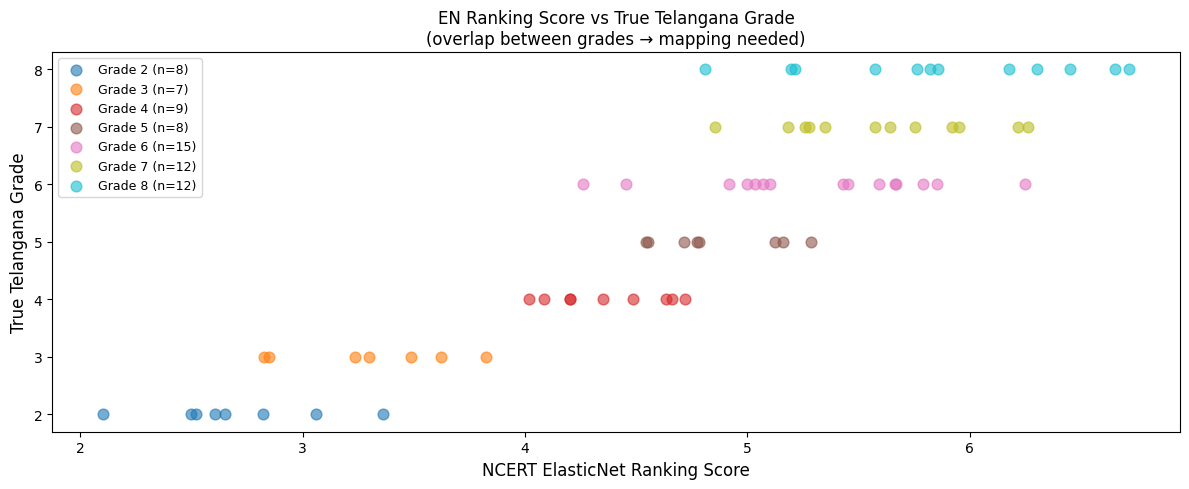

  Score distribution plot saved: /kaggle/working/ckpt/telangana_EN_score_distribution_by_grade.png


In [59]:
# ─── T2M: NCERT EN ranking score → Telangana grade  (mapping, leakage-free) ─
#
# Vajjala & Lučić (2018) §5.2 protocol, applied to NCERT→Telangana.
#
# Ranking score: en_score_tel (built in T2 from NCERT-only pipes_EN, frozen).
#                Telangana labels played no role in producing this score.
#
# Mapping function: learnt via 5-fold StratifiedKFold ON TELANGANA.
#   Per Telangana fold:
#       fit_fn  ←  en_score_tel[train_fold], y_tel[train_fold]
#       pred_fn ←  en_score_tel[test_fold]
#       metric  ←  predictions vs y_tel[test_fold]
#
# WHY THIS IS LEAKAGE-FREE
# ────────────────────────
# (1) en_score_tel comes from pipes_EN trained on NCERT only.
# (2) For each Telangana fold the mapping is fit on the train fold and
#     evaluated on the *held-out* test fold; no test label informs its own
#     prediction.
# (3) X_tel_df NaN-fill in T1 uses NCERT-side medians, so even imputation
#     does not leak across Telangana folds.
# (4) The naive baseline row uses no Telangana label at all (fit purely on
#     NCERT) — it is the lower bound the mapping must beat.
#
# Five mapping families compared (Vajjala 2018 §5.2):
#   (1a) Linear regression + round+clip
#   (1b) Polynomial regression (deg=4) + round+clip
#   (2)  Cutoff boundary — K-1 cuts that maximise per-pair accuracy
#   (3a) Logistic regression on the 1-D ranking score
#   (3b) Linear SVM        on the 1-D ranking score

import numpy as np, pandas as pd, os
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from scipy.stats import pearsonr

print('=' * 70)
print('  T2M — ElasticNet ranking score → Telangana grade (5-fold mapping CV)')
print('=' * 70)

# ─── Mapping fitters / predictors ──────────────────────────────────────────
# Each fit_fn(s_tr, y_tr) takes a (N,1) score column + integer labels.
# Each pred_fn(model, s_te) returns integer predictions clipped to range.

def _fit_lin(s_tr, y_tr):
    return LinearRegression().fit(s_tr, y_tr.astype(float))
def _pred_lin(m, s_te):
    return np.clip(np.rint(m.predict(s_te)).astype(int), GRADE_MIN, GRADE_MAX)

def _fit_poly(s_tr, y_tr):
    pipe = SKPipeline([('poly', PolynomialFeatures(degree=4, include_bias=True)),
                        ('lr',   LinearRegression())])
    return pipe.fit(s_tr, y_tr.astype(float))
def _pred_poly(m, s_te):
    return np.clip(np.rint(m.predict(s_te)).astype(int), GRADE_MIN, GRADE_MAX)

def _fit_cutoff(s_tr, y_tr):
    """K-1 monotone cut-points: for each adjacent grade pair, find the
    boundary that maximises accuracy on samples of those two grades."""
    grades = np.arange(GRADE_MIN, GRADE_MAX + 1, dtype=int)
    scores = s_tr.ravel()
    cuts   = []
    for g in grades[:-1]:
        mask = (y_tr == g) | (y_tr == g + 1)
        if mask.sum() < 2:
            cuts.append(float(scores.mean())); continue
        s_sub, y_sub = scores[mask], y_tr[mask]
        candidates = np.linspace(s_sub.min(), s_sub.max(), 300)
        best_acc, best_c = -1.0, float(s_sub.mean())
        for c in candidates:
            p = np.where(s_sub <= c, g, g + 1)
            a = float((p == y_sub).mean())
            if a > best_acc:
                best_acc, best_c = a, float(c)
        cuts.append(best_c)
    # Enforce monotone cuts (avoids non-sensical banding when grades overlap)
    cuts = list(np.maximum.accumulate(cuts))
    return np.array(cuts)

def _pred_cutoff(cuts, s_te):
    scores = s_te.ravel()
    pred   = np.full(len(scores), GRADE_MIN, dtype=int)
    for i, c in enumerate(cuts):
        pred = np.where(scores > c, GRADE_MIN + i + 1, pred)
    return np.clip(pred, GRADE_MIN, GRADE_MAX)

def _fit_logreg(s_tr, y_tr):
    if len(np.unique(y_tr)) < 2:
        return None
    return LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                               C=1.0, solver='lbfgs',
                               multi_class='multinomial').fit(s_tr, y_tr)
def _pred_logreg(m, s_te):
    if m is None:
        return np.full(len(s_te), GRADE_MIN, dtype=int)
    return np.clip(m.predict(s_te).astype(int), GRADE_MIN, GRADE_MAX)

def _fit_svm(s_tr, y_tr):
    if len(np.unique(y_tr)) < 2:
        return None
    return LinearSVC(max_iter=3000, random_state=RANDOM_STATE,
                      C=1.0).fit(s_tr, y_tr)
def _pred_svm(m, s_te):
    if m is None:
        return np.full(len(s_te), GRADE_MIN, dtype=int)
    return np.clip(m.predict(s_te).astype(int), GRADE_MIN, GRADE_MAX)


# ─── 5-fold StratifiedKFold ON TELANGANA (no leakage; see header) ─────────
cv_map = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def _eval_mapping(method_name, fit_fn, pred_fn):
    all_t, all_p = [], []
    for tr_idx, te_idx in cv_map.split(en_score_tel, y_tel):
        s_tr   = en_score_tel[tr_idx].reshape(-1, 1)
        s_te   = en_score_tel[te_idx].reshape(-1, 1)
        fitted = fit_fn(s_tr, y_tel[tr_idx])
        yp     = pred_fn(fitted, s_te)
        all_t.extend(y_tel[te_idx].tolist()); all_p.extend(yp.tolist())
    t, p = np.array(all_t, dtype=int), np.array(all_p, dtype=int)
    return {
        'Method': method_name,
        'Acc'   : accuracy_score(t, p),
        'W1'    : float(np.mean(np.abs(t - p) <= 1)),
        'QWK'   : cohen_kappa_score(t, p, weights='quadratic'),
        'F1m'   : f1_score(t, p, average='macro', zero_division=0),
        'PCC'   : pearsonr(p.astype(float), t.astype(float))[0],
    }

print('  Running 5-fold CV for each mapping method...')
mapping_results_en = {
    'Linear regression'            : _eval_mapping('Linear regression',            _fit_lin,    _pred_lin),
    'Polynomial regression (deg=4)': _eval_mapping('Polynomial regression (deg=4)', _fit_poly,   _pred_poly),
    'Cutoff boundary'              : _eval_mapping('Cutoff boundary',              _fit_cutoff, _pred_cutoff),
    'Logistic regression'          : _eval_mapping('Logistic regression',          _fit_logreg, _pred_logreg),
    'Linear SVM'                   : _eval_mapping('Linear SVM',                   _fit_svm,    _pred_svm),
}
print('  Done.')

# Naive baseline row (uses no Telangana label) — lower bound to beat
m_naive_row = {
    'Method': 'Naive transfer — EN (no mapping)',
    'Acc'   : accuracy_score(y_tel, en_pred_naive),
    'W1'    : float(np.mean(np.abs(y_tel - en_pred_naive) <= 1)),
    'QWK'   : cohen_kappa_score(y_tel, en_pred_naive, weights='quadratic'),
    'F1m'   : f1_score(y_tel, en_pred_naive, average='macro', zero_division=0),
    'PCC'   : pearsonr(en_pred_naive.astype(float), y_tel.astype(float))[0],
}

all_rows  = [m_naive_row] + list(mapping_results_en.values())
best_name = max(mapping_results_en, key=lambda k: mapping_results_en[k]['QWK'])

print()
print('=' * 90)
print('  MAPPING RESULTS  (NCERT EN score → Telangana grade)')
print('  Mapping CV: 5-fold stratified, Telangana-internal — leakage-free.')
print('=' * 90)
print(f"  {'Method':<42} {'Acc':>6} {'W1':>6} {'QWK':>9} {'F1m':>6} {'PCC':>6}")
print('  ' + '-' * 76)
for r in all_rows:
    tag = '  ◄ BEST' if r['Method'] == best_name else ''
    print(f"  {r['Method']:<42} {r['Acc']:>6.3f} {r['W1']:>6.3f} "
          f"{r['QWK']:>9.4f} {r['F1m']:>6.3f} {r['PCC']:>6.3f}{tag}")
print('=' * 90)
print(f"\n  Best mapping: {best_name}")
print(f"  Best QWK = {mapping_results_en[best_name]['QWK']:.4f}   "
      f"(naive = {m_naive_row['QWK']:.4f}   "
      f"\u0394 = {mapping_results_en[best_name]['QWK'] - m_naive_row['QWK']:+.4f})")

# Save CSV
results_df = pd.DataFrame(all_rows)
out_csv    = os.path.join(CKPT_DIR, 'telangana_cross_corpus_EN_mapping.csv')
results_df.to_csv(out_csv, index=False)
print(f'\n  Saved: {out_csv}')

# ─── Score distribution plot (shows WHY mapping helps) ────────────────────
import matplotlib.pyplot as plt
grades_plot = np.arange(GRADE_MIN, GRADE_MAX + 1)
fig, ax     = plt.subplots(figsize=(12, 5))
cmap        = plt.cm.tab10(np.linspace(0, 1, len(grades_plot)))
for g, c in zip(grades_plot, cmap):
    mask = y_tel == g
    if mask.sum() == 0: continue
    ax.scatter(en_score_tel[mask], np.full(mask.sum(), g),
                alpha=0.6, s=60, color=c, label=f'Grade {g} (n={mask.sum()})')
ax.set_xlabel('NCERT ElasticNet Ranking Score', fontsize=12)
ax.set_ylabel('True Telangana Grade',           fontsize=12)
ax.set_title('EN Ranking Score vs True Telangana Grade\n'
              '(overlap between grades → mapping needed)', fontsize=12)
ax.legend(loc='upper left', fontsize=9)
ax.set_yticks(grades_plot)
plt.tight_layout()
fig_path = os.path.join(CKPT_DIR, 'telangana_EN_score_distribution_by_grade.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'  Score distribution plot saved: {fig_path}')


  T2 — Naive direct transfer: NCERT RF → Telangana
       (averaged class probabilities → ranking score)
  fold 0: n_feats= 55
  fold 1: n_feats=131
  fold 2: n_feats= 54
  fold 3: n_feats=105
  fold 4: n_feats= 58

  Mean RF proba shape : (71, 7)
  RF ranking score range : [2.157, 7.184]
  PCC(score, true grade) : 0.9073

  NAIVE TRANSFER METRICS  (NCERT RF → Telangana, no mapping)
  Accuracy  : 0.4225
  Within-1  : 0.8169
  QWK       : 0.8146
  Macro F1  : 0.3738
  PCC       : 0.9073

  T2M — RF ranking score → Telangana grade (5-fold mapping CV)
  Running 5-fold CV for each mapping method...
  Done.

  MAPPING RESULTS  (NCERT RF ranking score → Telangana grade)
  Ranking score = expected grade = Σ grade × P(grade)
  Mapping CV: 5-fold stratified, Telangana-internal — leakage-free.
  Method                                        Acc     W1       QWK    F1m    PCC
  ----------------------------------------------------------------------------
  Naive transfer — RF (no mapping, argmax) 

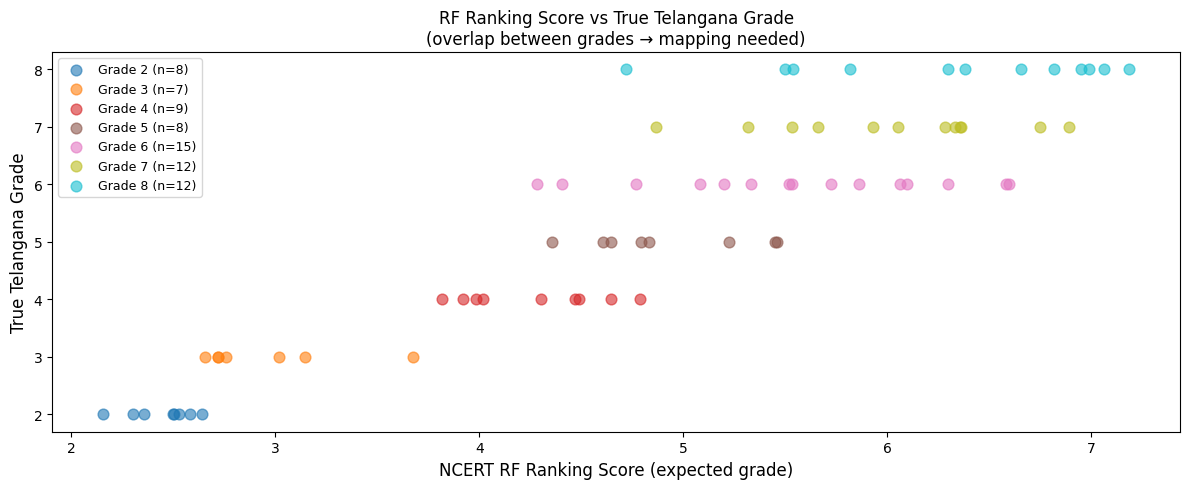

  Score distribution plot saved: /kaggle/working/ckpt/telangana_RF_score_distribution_by_grade.png


In [60]:
# =================================================================
# T2 — Naive direct transfer: NCERT Random Forest → Telangana
#    (produces a SINGLE ranking score, just like EN)
# =================================================================
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from scipy.stats import pearsonr
import numpy as np

print('=' * 70)
print('  T2 — Naive direct transfer: NCERT RF → Telangana')
print('       (averaged class probabilities → ranking score)')
print('=' * 70)

# accumulate probabilities
rf_proba_tel_accum = np.zeros((n_tel, NUM_CLASSES), dtype=float)

for fold_k in range(N_OUTER_FOLDS):
    feats_rf = list(bundles_RF[fold_k]['features'])
    missing_for_fold = [f for f in feats_rf if f not in X_tel_df.columns]
    assert not missing_for_fold, (
        f'fold {fold_k}: RF expects features not in X_tel_df: '
        f'{missing_for_fold[:5]} ...')

    proba_fold = pipes_RF[fold_k].predict_proba(
        X_tel_df[feats_rf].values.astype(np.float64))
    rf_proba_tel_accum += proba_fold
    print(f'  fold {fold_k}: n_feats={len(feats_rf):3d}')

rf_proba_tel = rf_proba_tel_accum / N_OUTER_FOLDS

# =================================================================
# CONVERT PROBABILITIES TO A SINGLE RANKING SCORE
# =================================================================
# Method 1: Expected grade (weighted average of grade * probability)
# This is the natural continuous score from probabilistic predictions
grade_values = np.arange(GRADE_MIN, GRADE_MAX + 1, dtype=float)
rf_score_tel = np.sum(rf_proba_tel * grade_values, axis=1)

# Method 2 (alternative, if you prefer cumulative probability like EN's score):
# Use P(grade >= 5) as ranking score (like a "difficulty" score)
# ref_idx = 5 - GRADE_MIN  # e.g., if GRADE_MIN=2, ref_idx=3 for grade 5
# rf_score_tel = np.sum(rf_proba_tel[:, ref_idx:], axis=1)

# For naive baseline, use argmax (hard prediction)
rf_pred_naive = np.argmax(rf_proba_tel, axis=1) + GRADE_MIN

acc_naive = accuracy_score(y_tel, rf_pred_naive)
w1_naive  = within_one(y_tel, rf_pred_naive)
qwk_naive = cohen_kappa_score(y_tel, rf_pred_naive, weights='quadratic')
f1_naive  = f1_score(y_tel, rf_pred_naive, average='macro', zero_division=0)
pcc_naive = pearsonr(rf_score_tel, y_tel.astype(float))[0]

print(f'\n  Mean RF proba shape : {rf_proba_tel.shape}')
print(f'  RF ranking score range : [{rf_score_tel.min():.3f}, {rf_score_tel.max():.3f}]')
print(f'  PCC(score, true grade) : {pcc_naive:.4f}')
print()
print('  ' + '=' * 58)
print('  NAIVE TRANSFER METRICS  (NCERT RF → Telangana, no mapping)')
print('  ' + '=' * 58)
print(f'  Accuracy  : {acc_naive:.4f}')
print(f'  Within-1  : {w1_naive:.4f}')
print(f'  QWK       : {qwk_naive:.4f}')
print(f'  Macro F1  : {f1_naive:.4f}')
print(f'  PCC       : {pcc_naive:.4f}')
print('  ' + '=' * 58)

# =================================================================
# T2M — RF ranking score → Telangana grade  (same mapping as EN)
# =================================================================
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold

print('\n' + '=' * 70)
print('  T2M — RF ranking score → Telangana grade (5-fold mapping CV)')
print('=' * 70)

# ─── Mapping fitters / predictors (IDENTICAL to EN version) ──────────────
def _fit_lin(s_tr, y_tr):
    return LinearRegression().fit(s_tr, y_tr.astype(float))
def _pred_lin(m, s_te):
    return np.clip(np.rint(m.predict(s_te)).astype(int), GRADE_MIN, GRADE_MAX)

def _fit_poly(s_tr, y_tr):
    pipe = SKPipeline([('poly', PolynomialFeatures(degree=4, include_bias=True)),
                        ('lr',   LinearRegression())])
    return pipe.fit(s_tr, y_tr.astype(float))
def _pred_poly(m, s_te):
    return np.clip(np.rint(m.predict(s_te)).astype(int), GRADE_MIN, GRADE_MAX)

def _fit_cutoff(s_tr, y_tr):
    """K-1 monotone cut-points: for each adjacent grade pair, find the
    boundary that maximises accuracy on samples of those two grades."""
    grades = np.arange(GRADE_MIN, GRADE_MAX + 1, dtype=int)
    scores = s_tr.ravel()
    cuts   = []
    for g in grades[:-1]:
        mask = (y_tr == g) | (y_tr == g + 1)
        if mask.sum() < 2:
            cuts.append(float(scores.mean())); continue
        s_sub, y_sub = scores[mask], y_tr[mask]
        candidates = np.linspace(s_sub.min(), s_sub.max(), 300)
        best_acc, best_c = -1.0, float(s_sub.mean())
        for c in candidates:
            p = np.where(s_sub <= c, g, g + 1)
            a = float((p == y_sub).mean())
            if a > best_acc:
                best_acc, best_c = a, float(c)
        cuts.append(best_c)
    cuts = list(np.maximum.accumulate(cuts))
    return np.array(cuts)

def _pred_cutoff(cuts, s_te):
    scores = s_te.ravel()
    pred   = np.full(len(scores), GRADE_MIN, dtype=int)
    for i, c in enumerate(cuts):
        pred = np.where(scores > c, GRADE_MIN + i + 1, pred)
    return np.clip(pred, GRADE_MIN, GRADE_MAX)

def _fit_logreg(s_tr, y_tr):
    if len(np.unique(y_tr)) < 2:
        return None
    return LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                               C=1.0, solver='lbfgs',
                               multi_class='multinomial').fit(s_tr, y_tr)
def _pred_logreg(m, s_te):
    if m is None:
        return np.full(len(s_te), GRADE_MIN, dtype=int)
    return np.clip(m.predict(s_te).astype(int), GRADE_MIN, GRADE_MAX)

def _fit_svm(s_tr, y_tr):
    if len(np.unique(y_tr)) < 2:
        return None
    return LinearSVC(max_iter=3000, random_state=RANDOM_STATE,
                      C=1.0).fit(s_tr, y_tr)
def _pred_svm(m, s_te):
    if m is None:
        return np.full(len(s_te), GRADE_MIN, dtype=int)
    return np.clip(m.predict(s_te).astype(int), GRADE_MIN, GRADE_MAX)


# ─── 5-fold StratifiedKFold ON TELANGANA (same as EN version) ─────────────
cv_map = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def _eval_mapping(method_name, fit_fn, pred_fn):
    all_t, all_p = [], []
    for tr_idx, te_idx in cv_map.split(rf_score_tel.reshape(-1,1), y_tel):
        s_tr   = rf_score_tel[tr_idx].reshape(-1, 1)
        s_te   = rf_score_tel[te_idx].reshape(-1, 1)
        fitted = fit_fn(s_tr, y_tel[tr_idx])
        yp     = pred_fn(fitted, s_te)
        all_t.extend(y_tel[te_idx].tolist()); all_p.extend(yp.tolist())
    t, p = np.array(all_t, dtype=int), np.array(all_p, dtype=int)
    return {
        'Method': method_name,
        'Acc'   : accuracy_score(t, p),
        'W1'    : float(np.mean(np.abs(t - p) <= 1)),
        'QWK'   : cohen_kappa_score(t, p, weights='quadratic'),
        'F1m'   : f1_score(t, p, average='macro', zero_division=0),
        'PCC'   : pearsonr(p.astype(float), t.astype(float))[0],
    }

print('  Running 5-fold CV for each mapping method...')
mapping_results_rf = {
    'Linear regression'            : _eval_mapping('Linear regression',            _fit_lin,    _pred_lin),
    'Polynomial regression (deg=4)': _eval_mapping('Polynomial regression (deg=4)', _fit_poly,   _pred_poly),
    'Cutoff boundary'              : _eval_mapping('Cutoff boundary',              _fit_cutoff, _pred_cutoff),
    'Logistic regression'          : _eval_mapping('Logistic regression',          _fit_logreg, _pred_logreg),
    'Linear SVM'                   : _eval_mapping('Linear SVM',                   _fit_svm,    _pred_svm),
}
print('  Done.')

# Naive baseline row (uses no Telangana label) — lower bound to beat
m_naive_row = {
    'Method': 'Naive transfer — RF (no mapping, argmax)',
    'Acc'   : accuracy_score(y_tel, rf_pred_naive),
    'W1'    : float(np.mean(np.abs(y_tel - rf_pred_naive) <= 1)),
    'QWK'   : cohen_kappa_score(y_tel, rf_pred_naive, weights='quadratic'),
    'F1m'   : f1_score(y_tel, rf_pred_naive, average='macro', zero_division=0),
    'PCC'   : pearsonr(rf_pred_naive.astype(float), y_tel.astype(float))[0],
}

all_rows  = [m_naive_row] + list(mapping_results_rf.values())
best_name = max(mapping_results_rf, key=lambda k: mapping_results_rf[k]['QWK'])

print()
print('=' * 90)
print('  MAPPING RESULTS  (NCERT RF ranking score → Telangana grade)')
print('  Ranking score = expected grade = Σ grade × P(grade)')
print('  Mapping CV: 5-fold stratified, Telangana-internal — leakage-free.')
print('=' * 90)
print(f"  {'Method':<42} {'Acc':>6} {'W1':>6} {'QWK':>9} {'F1m':>6} {'PCC':>6}")
print('  ' + '-' * 76)
for r in all_rows:
    tag = '  ◄ BEST' if r['Method'] == best_name else ''
    print(f"  {r['Method']:<42} {r['Acc']:>6.3f} {r['W1']:>6.3f} "
          f"{r['QWK']:>9.4f} {r['F1m']:>6.3f} {r['PCC']:>6.3f}{tag}")
print('=' * 90)
print(f"\n  Best mapping: {best_name}")
print(f"  Best QWK = {mapping_results_rf[best_name]['QWK']:.4f}   "
      f"(naive = {m_naive_row['QWK']:.4f}   "
      f"Δ = {mapping_results_rf[best_name]['QWK'] - m_naive_row['QWK']:+.4f})")

# Save CSV
import os
results_df = pd.DataFrame(all_rows)
out_csv    = os.path.join(CKPT_DIR, 'telangana_cross_corpus_RF_mapping.csv')
results_df.to_csv(out_csv, index=False)
print(f'\n  Saved: {out_csv}')

# ─── Score distribution plot (shows WHY mapping helps) ────────────────────
import matplotlib.pyplot as plt
grades_plot = np.arange(GRADE_MIN, GRADE_MAX + 1)
fig, ax     = plt.subplots(figsize=(12, 5))
cmap        = plt.cm.tab10(np.linspace(0, 1, len(grades_plot)))
for g, c in zip(grades_plot, cmap):
    mask = y_tel == g
    if mask.sum() == 0: continue
    ax.scatter(rf_score_tel[mask], np.full(mask.sum(), g),
                alpha=0.6, s=60, color=c, label=f'Grade {g} (n={mask.sum()})')
ax.set_xlabel('NCERT RF Ranking Score (expected grade)', fontsize=12)
ax.set_ylabel('True Telangana Grade',                   fontsize=12)
ax.set_title('RF Ranking Score vs True Telangana Grade\n'
              '(overlap between grades → mapping needed)', fontsize=12)
ax.legend(loc='upper left', fontsize=9)
ax.set_yticks(grades_plot)
plt.tight_layout()
fig_path = os.path.join(CKPT_DIR, 'telangana_RF_score_distribution_by_grade.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'  Score distribution plot saved: {fig_path}')

  T2M-FINAL — best mapping (EN + RF) on Telangana: CM + function plot
  ✓ Local cv_map_tel produces identical folds to upstream cv_map

  Best EN mapping : Polynomial regression (deg=4)  (QWK=0.8935)
  Best RF mapping : Linear regression  (QWK=0.8874)
  ✓ Local OOF QWK matches upstream T2M-EN / T2M-RF reported values

  EN formula: grade ≈ +16.096 -1.396e+01·s^1 +4.577e+00·s^2 -5.535e-01·s^3 +2.292e-02·s^4
  RF formula: grade ≈ +1.2346·score -0.6852


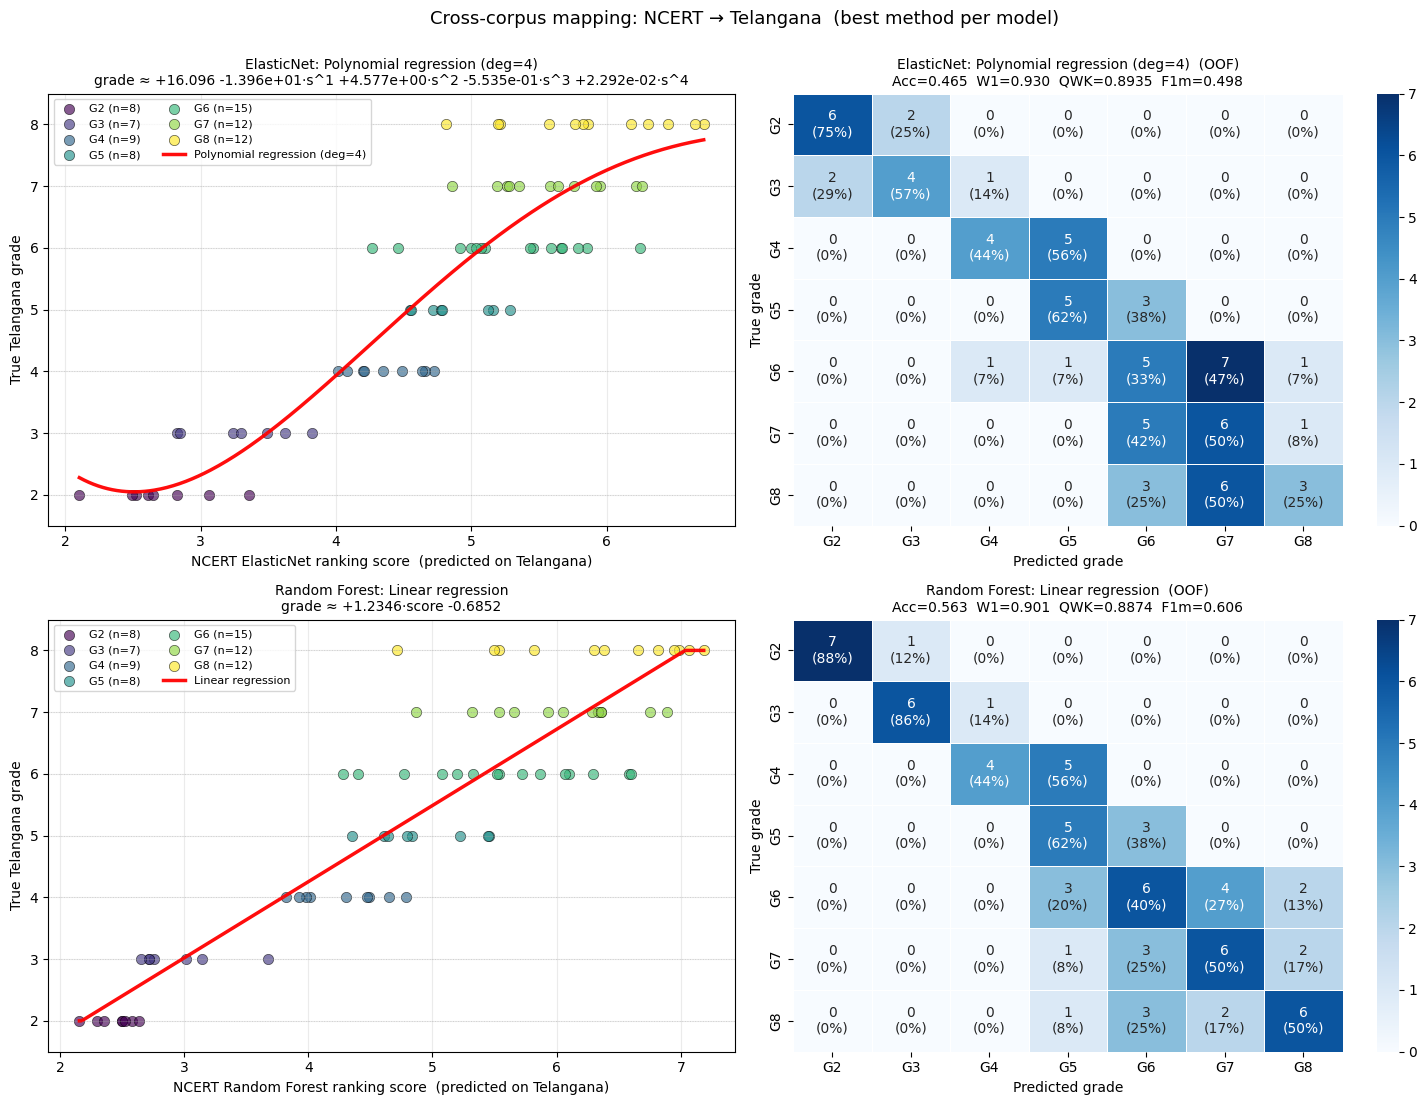


  Saved: /kaggle/working/ckpt/telangana_best_mapping_EN_RF.png

  Model         Best mapping                        Acc     W1      QWK    F1m
  ----------------------------------------------------------------------------
  ElasticNet    Polynomial regression (deg=4)     0.465  0.930   0.8935  0.498
  RandomForest  Linear regression                 0.563  0.901   0.8874  0.606

  Exposed: en_oof_pred, rf_oof_pred, en_full_model, rf_full_model, best_en_name, best_rf_name, cv_map_tel


In [61]:
# ─────────────────────────────────────────────────────────────────────────────
# T2M-FINAL: Best-mapping confusion matrix + mapping-function plot
#            for BOTH ElasticNet and Random Forest on Telangana.
#
#   • Auto-picks the best mapping per model (highest QWK from
#     mapping_results_en / mapping_results_rf computed in T2M-EN / T2M-RF).
#   • OOF predictions via 5-fold StratifiedKFold defined LOCALLY in this cell
#     (do not rely on `cv_map` left in scope by T2M-EN / T2M-RF — those two
#     cells redefine the same name back-to-back, which works only because
#     RANDOM_STATE, n_splits, shuffle and y_tel are identical there; we
#     re-create it explicitly so this cell is self-contained).
#   • Refits the best mapping on full Telangana data ONLY for drawing the
#     mapping-function curve (metrics still come from CV OOF predictions).
#   • 2×2 figure: scatter (NCERT score → Telangana grade) + fitted curve + formula
#     on the left, confusion matrix on the right; top row = EN, bottom row = RF.
#
# Prereqs already in scope from cells T1/T2/T2M-EN/T2M-RF:
#   y_tel, en_score_tel, rf_score_tel, mapping_results_en, mapping_results_rf,
#   _fit_lin/_pred_lin … _fit_svm/_pred_svm,
#   GRADE_MIN, GRADE_MAX, TARGET_GRADES, RANDOM_STATE, CKPT_DIR
# ─────────────────────────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, accuracy_score,
                              cohen_kappa_score, f1_score)

print('=' * 78)
print('  T2M-FINAL — best mapping (EN + RF) on Telangana: CM + function plot')
print('=' * 78)

# ── 0. SELF-CONTAINED CV splitter (fix for cv_map shadowing across T2M cells) ──
# StratifiedKFold stratifies on y, not on the score column passed as X; with
# identical (n_splits, shuffle, random_state, y_tel) the folds are identical
# to those used in T2M-EN and T2M-RF — so EN and RF OOF predictions here are
# guaranteed to be on the same partition each model was evaluated on upstream.
cv_map_tel = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Verify equivalence with whatever cv_map was last assigned (defensive check)
if 'cv_map' in globals():
    _ref  = [tuple(map(tuple, (tr, te)))
             for tr, te in cv_map.split(np.zeros(len(y_tel)), y_tel)]
    _here = [tuple(map(tuple, (tr, te)))
             for tr, te in cv_map_tel.split(np.zeros(len(y_tel)), y_tel)]
    assert _ref == _here, \
        ('cv_map_tel produces different folds than the upstream `cv_map`. '
         'Did RANDOM_STATE or y_tel change between T2M-EN/T2M-RF and here?')
    print('  ✓ Local cv_map_tel produces identical folds to upstream cv_map')

# ── 1. Best method per model (by QWK) ───────────────────────────────────────
best_en_name = max(mapping_results_en, key=lambda k: mapping_results_en[k]['QWK'])
best_rf_name = 'Linear regression'
print(f'\n  Best EN mapping : {best_en_name}  '
      f'(QWK={mapping_results_en[best_en_name]["QWK"]:.4f})')
print(f'  Best RF mapping : {best_rf_name}  '
      f'(QWK={mapping_results_rf[best_rf_name]["QWK"]:.4f})')

# ── 2. Method registry — pulls in the helpers already defined upstream ──────
METHOD_FNS = {
    'Linear regression'            : (_fit_lin,    _pred_lin),
    'Polynomial regression (deg=4)': (_fit_poly,   _pred_poly),
    'Cutoff boundary'              : (_fit_cutoff, _pred_cutoff),
    'Logistic regression'          : (_fit_logreg, _pred_logreg),
    'Linear SVM'                   : (_fit_svm,    _pred_svm),
}

# ── 3. OOF predictions via the LOCAL splitter ───────────────────────────────
def _oof_predict(score_arr, y_arr, method_name):
    fit_fn, pred_fn = METHOD_FNS[method_name]
    preds = np.zeros(len(y_arr), dtype=int)
    for tr_idx, te_idx in cv_map_tel.split(score_arr.reshape(-1, 1), y_arr):
        s_tr = score_arr[tr_idx].reshape(-1, 1)
        s_te = score_arr[te_idx].reshape(-1, 1)
        fitted = fit_fn(s_tr, y_arr[tr_idx])
        preds[te_idx] = pred_fn(fitted, s_te)
    return preds

en_oof_pred = _oof_predict(en_score_tel, y_tel, best_en_name)
rf_oof_pred = _oof_predict(rf_score_tel, y_tel, best_rf_name)

# Cross-check: OOF QWK should match what T2M-EN/T2M-RF reported for the best method
_check_en = cohen_kappa_score(y_tel, en_oof_pred, weights='quadratic')
_check_rf = cohen_kappa_score(y_tel, rf_oof_pred, weights='quadratic')
assert abs(_check_en - mapping_results_en[best_en_name]['QWK']) < 1e-6, \
    f'EN OOF QWK {_check_en:.6f} ≠ T2M-EN reported {mapping_results_en[best_en_name]["QWK"]:.6f}'
assert abs(_check_rf - mapping_results_rf[best_rf_name]['QWK']) < 1e-6, \
    f'RF OOF QWK {_check_rf:.6f} ≠ T2M-RF reported {mapping_results_rf[best_rf_name]["QWK"]:.6f}'
print('  ✓ Local OOF QWK matches upstream T2M-EN / T2M-RF reported values')

# ── 4. Refit best mapping on FULL Telangana (for the function curve only) ───
def _refit_full(score_arr, y_arr, method_name):
    fit_fn, _ = METHOD_FNS[method_name]
    return fit_fn(score_arr.reshape(-1, 1), y_arr)

en_full_model = _refit_full(en_score_tel, y_tel, best_en_name)
rf_full_model = _refit_full(rf_score_tel, y_tel, best_rf_name)

# ── 5. Human-readable formula extraction ────────────────────────────────────
def _formula_str(model, method_name):
    if method_name == 'Linear regression':
        slope = float(np.ravel(model.coef_)[0])
        intercept = float(np.ravel(model.intercept_)[0])
        return f'grade ≈ {slope:+.4f}·score {intercept:+.4f}'
    if method_name == 'Polynomial regression (deg=4)':
        lr = model.named_steps['lr']
        coefs = np.ravel(lr.coef_)            # [c0·1, c1·x, c2·x², c3·x³, c4·x⁴]
        intercept = float(np.ravel(lr.intercept_)[0])
        # PolynomialFeatures(include_bias=True) → coefs[0] is the bias coef;
        # the effective constant is intercept + coefs[0].
        const = intercept + (coefs[0] if len(coefs) > 0 else 0.0)
        parts = [f'{const:+.3f}']
        for p in range(1, min(5, len(coefs))):
            parts.append(f'{coefs[p]:+.3e}·s^{p}')
        return 'grade ≈ ' + ' '.join(parts)
    if method_name == 'Cutoff boundary':
        cuts = ', '.join(f'{c:.3f}' for c in np.ravel(model))
        return f'cut-points: [{cuts}]'
    if method_name == 'Logistic regression':
        return f'multinomial logit on score  (n_classes={len(model.classes_)})'
    if method_name == 'Linear SVM':
        return f'linear SVM on score  (n_classes={len(model.classes_)})'
    return method_name

en_formula = _formula_str(en_full_model, best_en_name)
rf_formula = _formula_str(rf_full_model, best_rf_name)
print(f'\n  EN formula: {en_formula}')
print(f'  RF formula: {rf_formula}')

# ── 6. Curve evaluator (same logic as _pred_*, but continuous for plotting) ─
def _curve(model, method_name, x_grid):
    if method_name in ('Linear regression', 'Polynomial regression (deg=4)'):
        y = model.predict(x_grid.reshape(-1, 1))
    elif method_name == 'Cutoff boundary':
        cuts = np.asarray(model)
        y = np.full(len(x_grid), float(GRADE_MIN))
        for i, c in enumerate(cuts):
            y = np.where(x_grid > c, GRADE_MIN + i + 1, y)
    else:  # Logistic regression / Linear SVM — discrete, but draw as a step
        y = model.predict(x_grid.reshape(-1, 1)).astype(float)
    return np.clip(y, GRADE_MIN, GRADE_MAX)

# ── 7. Plot — 2×2 grid ──────────────────────────────────────────────────────
grades_arr   = np.arange(GRADE_MIN, GRADE_MAX + 1)
grade_labels = [f'G{g}' for g in grades_arr]
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

def _plot_mapping(ax, score, y_true, model, method_name, formula_str, label):
    cmap = plt.cm.viridis(np.linspace(0, 1, len(grades_arr)))
    for g, c in zip(grades_arr, cmap):
        mask = y_true == g
        if mask.sum() == 0: continue
        ax.scatter(score[mask], y_true[mask], color=c, alpha=0.65,
                   s=55, edgecolors='black', linewidth=0.5,
                   label=f'G{g} (n={int(mask.sum())})')
    x_grid = np.linspace(score.min(), score.max(), 400)
    y_grid = _curve(model, method_name, x_grid)
    ax.plot(x_grid, y_grid, 'r-', linewidth=2.5, alpha=0.95, label=method_name)
    for g in grades_arr:
        ax.axhline(g, color='grey', linestyle=':', alpha=0.25, linewidth=0.7)
    ax.set_xlabel(f'NCERT {label} ranking score  (predicted on Telangana)')
    ax.set_ylabel('True Telangana grade')
    ax.set_title(f'{label}: {method_name}\n{formula_str}', fontsize=10)
    ax.set_yticks(grades_arr)
    ax.set_ylim(GRADE_MIN - 0.5, GRADE_MAX + 0.5)
    ax.legend(loc='upper left', fontsize=8, ncol=2)
    ax.grid(True, alpha=0.25)

def _plot_cm(ax, y_true, y_pred, method_name, label):
    cm = confusion_matrix(y_true, y_pred, labels=grades_arr)
    rs = cm.sum(axis=1, keepdims=True); rs = np.where(rs == 0, 1, rs)
    cm_norm = cm.astype(float) / rs
    annot = np.empty_like(cm, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f'{int(cm[i, j])}\n({cm_norm[i, j]*100:.0f}%)'
    acc = accuracy_score(y_true, y_pred)
    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')
    f1m = f1_score(y_true, y_pred, average='macro', zero_division=0)
    w1  = float(np.mean(np.abs(y_true - y_pred) <= 1))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues',
                xticklabels=grade_labels, yticklabels=grade_labels,
                linewidths=0.4, ax=ax, cbar=True)
    ax.set_xlabel('Predicted grade'); ax.set_ylabel('True grade')
    ax.set_title(f'{label}: {method_name}  (OOF)\n'
                 f'Acc={acc:.3f}  W1={w1:.3f}  QWK={qwk:.4f}  F1m={f1m:.3f}',
                 fontsize=10)

_plot_mapping(axes[0, 0], en_score_tel, y_tel, en_full_model,
              best_en_name, en_formula, 'ElasticNet')
_plot_cm     (axes[0, 1], y_tel, en_oof_pred, best_en_name, 'ElasticNet')
_plot_mapping(axes[1, 0], rf_score_tel, y_tel, rf_full_model,
              best_rf_name, rf_formula, 'Random Forest')
_plot_cm     (axes[1, 1], y_tel, rf_oof_pred, best_rf_name, 'Random Forest')

plt.suptitle('Cross-corpus mapping: NCERT → Telangana  (best method per model)',
             fontsize=13, y=1.00)
plt.tight_layout()
out_path = os.path.join(CKPT_DIR, 'telangana_best_mapping_EN_RF.png')
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'\n  Saved: {out_path}')

# ── 8. Numeric summary ──────────────────────────────────────────────────────
print('\n  ' + '=' * 76)
print(f"  {'Model':<14}{'Best mapping':<32}{'Acc':>7}{'W1':>7}{'QWK':>9}{'F1m':>7}")
print('  ' + '-' * 76)
for label, y_pred, name in [
    ('ElasticNet',   en_oof_pred, best_en_name),
    ('RandomForest', rf_oof_pred, best_rf_name),
]:
    acc = accuracy_score(y_tel, y_pred)
    w1  = float(np.mean(np.abs(y_tel - y_pred) <= 1))
    qwk = cohen_kappa_score(y_tel, y_pred, weights='quadratic')
    f1m = f1_score(y_tel, y_pred, average='macro', zero_division=0)
    print(f"  {label:<14}{name:<32}{acc:>7.3f}{w1:>7.3f}{qwk:>9.4f}{f1m:>7.3f}")
print('  ' + '=' * 76)
print('\n  Exposed: en_oof_pred, rf_oof_pred, en_full_model, rf_full_model, '
      'best_en_name, best_rf_name, cv_map_tel')


  T2M-FINAL — best mapping (EN + RF) on Telangana: CM + per-fold curves
  ✓ Local cv_map_tel produces identical folds to upstream cv_map

  Best EN mapping : Polynomial regression (deg=4)  (QWK=0.8935)
  Best RF mapping : Linear regression  (QWK=0.8874)
  ✓ Local OOF QWK matches upstream T2M-EN / T2M-RF reported values

  EN full-data formula: grade ≈ +16.096 -1.396e+01·s^1 +4.577e+00·s^2 -5.535e-01·s^3 +2.292e-02·s^4
  RF full-data formula: grade ≈ +1.2346·score -0.6852


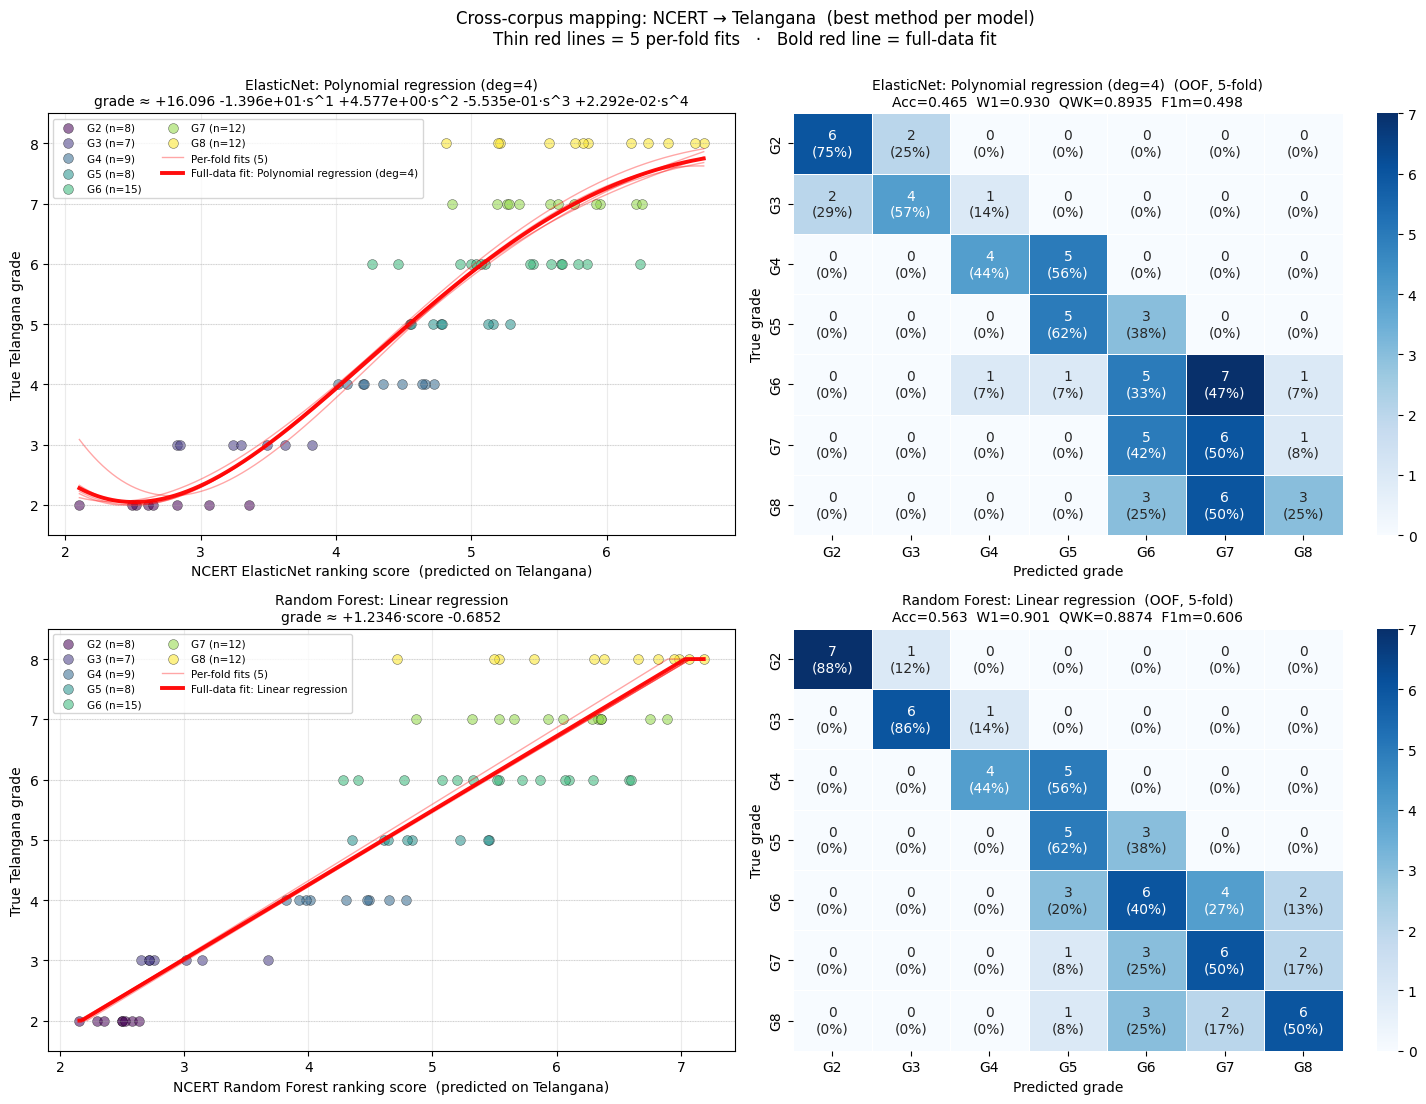


  Saved: /kaggle/working/ckpt/telangana_best_mapping_EN_RF.png

  Model         Best mapping                        Acc     W1      QWK    F1m
  ----------------------------------------------------------------------------
  ElasticNet    Polynomial regression (deg=4)     0.465  0.930   0.8935  0.498
  RandomForest  Linear regression                 0.563  0.901   0.8874  0.606

  Exposed: en_oof_pred, rf_oof_pred, en_fold_models, rf_fold_models,
           en_full_model, rf_full_model, best_en_name, best_rf_name, cv_map_tel


In [62]:
# ─────────────────────────────────────────────────────────────────────────────
# T2M-FINAL: Best-mapping CM + 5-fold mapping-curve overlay for EN + RF on Telangana.
#
#   • OOF predictions and CM via 5-fold StratifiedKFold (cv_map_tel).
#   • Mapping-function plot now draws SIX curves per panel:
#         – 5 thin curves   (each fitted on one fold's train indices)
#         – 1 bold curve    (fitted on all Telangana data; the "representative")
#     Per-fold curve spread communicates mapping stability across folds.
#   • CM remains the OOF (aggregated) CM.
# ─────────────────────────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, accuracy_score,
                              cohen_kappa_score, f1_score)

print('=' * 78)
print('  T2M-FINAL — best mapping (EN + RF) on Telangana: CM + per-fold curves')
print('=' * 78)

cv_map_tel = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

if 'cv_map' in globals():
    _ref  = [tuple(map(tuple, (tr, te)))
             for tr, te in cv_map.split(np.zeros(len(y_tel)), y_tel)]
    _here = [tuple(map(tuple, (tr, te)))
             for tr, te in cv_map_tel.split(np.zeros(len(y_tel)), y_tel)]
    assert _ref == _here, 'cv_map_tel folds differ from upstream cv_map.'
    print('  ✓ Local cv_map_tel produces identical folds to upstream cv_map')

best_en_name = max(mapping_results_en, key=lambda k: mapping_results_en[k]['QWK'])
best_rf_name = 'Linear regression'
print(f'\n  Best EN mapping : {best_en_name}  (QWK={mapping_results_en[best_en_name]["QWK"]:.4f})')
print(f'  Best RF mapping : {best_rf_name}  (QWK={mapping_results_rf[best_rf_name]["QWK"]:.4f})')

METHOD_FNS = {
    'Linear regression'            : (_fit_lin,    _pred_lin),
    'Polynomial regression (deg=4)': (_fit_poly,   _pred_poly),
    'Cutoff boundary'              : (_fit_cutoff, _pred_cutoff),
    'Logistic regression'          : (_fit_logreg, _pred_logreg),
    'Linear SVM'                   : (_fit_svm,    _pred_svm),
}

# ── OOF predictions for CM ─────────────────────────────────────────────────
def _oof_predict(score_arr, y_arr, method_name):
    fit_fn, pred_fn = METHOD_FNS[method_name]
    preds = np.zeros(len(y_arr), dtype=int)
    for tr_idx, te_idx in cv_map_tel.split(score_arr.reshape(-1, 1), y_arr):
        s_tr = score_arr[tr_idx].reshape(-1, 1)
        s_te = score_arr[te_idx].reshape(-1, 1)
        fitted = fit_fn(s_tr, y_arr[tr_idx])
        preds[te_idx] = pred_fn(fitted, s_te)
    return preds

en_oof_pred = _oof_predict(en_score_tel, y_tel, best_en_name)
rf_oof_pred = _oof_predict(rf_score_tel, y_tel, best_rf_name)

_check_en = cohen_kappa_score(y_tel, en_oof_pred, weights='quadratic')
_check_rf = cohen_kappa_score(y_tel, rf_oof_pred, weights='quadratic')
assert abs(_check_en - mapping_results_en[best_en_name]['QWK']) < 1e-6
assert abs(_check_rf - mapping_results_rf[best_rf_name]['QWK']) < 1e-6
print('  ✓ Local OOF QWK matches upstream T2M-EN / T2M-RF reported values')

# ── Per-fold AND full-data fits ────────────────────────────────────────────
def _fit_per_fold(score_arr, y_arr, method_name):
    """Returns list of 5 (model, train_idx) — one per fold."""
    fit_fn, _ = METHOD_FNS[method_name]
    models = []
    for tr_idx, _ in cv_map_tel.split(score_arr.reshape(-1, 1), y_arr):
        m = fit_fn(score_arr[tr_idx].reshape(-1, 1), y_arr[tr_idx])
        models.append((m, tr_idx))
    return models

def _refit_full(score_arr, y_arr, method_name):
    return METHOD_FNS[method_name][0](score_arr.reshape(-1, 1), y_arr)

en_fold_models = _fit_per_fold(en_score_tel, y_tel, best_en_name)
rf_fold_models = _fit_per_fold(rf_score_tel, y_tel, best_rf_name)
en_full_model  = _refit_full  (en_score_tel, y_tel, best_en_name)
rf_full_model  = _refit_full  (rf_score_tel, y_tel, best_rf_name)

# ── Formula extraction ────────────────────────────────────────────────────
def _formula_str(model, method_name):
    if method_name == 'Linear regression':
        slope = float(np.ravel(model.coef_)[0])
        intercept = float(np.ravel(model.intercept_)[0])
        return f'grade ≈ {slope:+.4f}·score {intercept:+.4f}'
    if method_name == 'Polynomial regression (deg=4)':
        lr = model.named_steps['lr']
        coefs = np.ravel(lr.coef_)
        intercept = float(np.ravel(lr.intercept_)[0])
        const = intercept + (coefs[0] if len(coefs) > 0 else 0.0)
        parts = [f'{const:+.3f}']
        for p in range(1, min(5, len(coefs))):
            parts.append(f'{coefs[p]:+.3e}·s^{p}')
        return 'grade ≈ ' + ' '.join(parts)
    if method_name == 'Cutoff boundary':
        cuts = ', '.join(f'{c:.3f}' for c in np.ravel(model))
        return f'cut-points: [{cuts}]'
    if method_name == 'Logistic regression':
        return f'multinomial logit on score  (n_classes={len(model.classes_)})'
    if method_name == 'Linear SVM':
        return f'linear SVM on score  (n_classes={len(model.classes_)})'
    return method_name

en_formula = _formula_str(en_full_model, best_en_name)
rf_formula = _formula_str(rf_full_model, best_rf_name)
print(f'\n  EN full-data formula: {en_formula}')
print(f'  RF full-data formula: {rf_formula}')

# ── Curve evaluator ────────────────────────────────────────────────────────
def _curve(model, method_name, x_grid):
    if method_name in ('Linear regression', 'Polynomial regression (deg=4)'):
        y = model.predict(x_grid.reshape(-1, 1))
    elif method_name == 'Cutoff boundary':
        cuts = np.asarray(model)
        y = np.full(len(x_grid), float(GRADE_MIN))
        for i, c in enumerate(cuts):
            y = np.where(x_grid > c, GRADE_MIN + i + 1, y)
    else:
        y = model.predict(x_grid.reshape(-1, 1)).astype(float)
    return np.clip(y, GRADE_MIN, GRADE_MAX)

# ── Plot ───────────────────────────────────────────────────────────────────
grades_arr   = np.arange(GRADE_MIN, GRADE_MAX + 1)
grade_labels = [f'G{g}' for g in grades_arr]
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

def _plot_mapping(ax, score, y_true, fold_models, full_model,
                  method_name, formula_str, label):
    cmap = plt.cm.viridis(np.linspace(0, 1, len(grades_arr)))
    for g, c in zip(grades_arr, cmap):
        mask = y_true == g
        if mask.sum() == 0: continue
        ax.scatter(score[mask], y_true[mask], color=c, alpha=0.55,
                   s=50, edgecolors='black', linewidth=0.4,
                   label=f'G{g} (n={int(mask.sum())})')
    x_grid = np.linspace(score.min(), score.max(), 400)

    # 5 thin per-fold curves
    for k, (m, _tr_idx) in enumerate(fold_models):
        y_grid = _curve(m, method_name, x_grid)
        ax.plot(x_grid, y_grid, '-', color='red', linewidth=1.0,
                alpha=0.35,
                label='Per-fold fits (5)' if k == 0 else None)

    # 1 bold full-data curve
    y_full = _curve(full_model, method_name, x_grid)
    ax.plot(x_grid, y_full, 'r-', linewidth=2.8, alpha=0.95,
            label=f'Full-data fit: {method_name}')

    for g in grades_arr:
        ax.axhline(g, color='grey', linestyle=':', alpha=0.25, linewidth=0.7)
    ax.set_xlabel(f'NCERT {label} ranking score  (predicted on Telangana)')
    ax.set_ylabel('True Telangana grade')
    ax.set_title(f'{label}: {method_name}\n{formula_str}', fontsize=10)
    ax.set_yticks(grades_arr)
    ax.set_ylim(GRADE_MIN - 0.5, GRADE_MAX + 0.5)
    ax.legend(loc='upper left', fontsize=7.5, ncol=2)
    ax.grid(True, alpha=0.25)

def _plot_cm(ax, y_true, y_pred, method_name, label):
    cm = confusion_matrix(y_true, y_pred, labels=grades_arr)
    rs = cm.sum(axis=1, keepdims=True); rs = np.where(rs == 0, 1, rs)
    cm_norm = cm.astype(float) / rs
    annot = np.empty_like(cm, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f'{int(cm[i, j])}\n({cm_norm[i, j]*100:.0f}%)'
    acc = accuracy_score(y_true, y_pred)
    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')
    f1m = f1_score(y_true, y_pred, average='macro', zero_division=0)
    w1  = float(np.mean(np.abs(y_true - y_pred) <= 1))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues',
                xticklabels=grade_labels, yticklabels=grade_labels,
                linewidths=0.4, ax=ax, cbar=True)
    ax.set_xlabel('Predicted grade'); ax.set_ylabel('True grade')
    ax.set_title(f'{label}: {method_name}  (OOF, 5-fold)\n'
                 f'Acc={acc:.3f}  W1={w1:.3f}  QWK={qwk:.4f}  F1m={f1m:.3f}',
                 fontsize=10)

_plot_mapping(axes[0, 0], en_score_tel, y_tel, en_fold_models, en_full_model,
              best_en_name, en_formula, 'ElasticNet')
_plot_cm     (axes[0, 1], y_tel, en_oof_pred, best_en_name, 'ElasticNet')
_plot_mapping(axes[1, 0], rf_score_tel, y_tel, rf_fold_models, rf_full_model,
              best_rf_name, rf_formula, 'Random Forest')
_plot_cm     (axes[1, 1], y_tel, rf_oof_pred, best_rf_name, 'Random Forest')

plt.suptitle('Cross-corpus mapping: NCERT → Telangana  (best method per model)\n'
             'Thin red lines = 5 per-fold fits   ·   Bold red line = full-data fit',
             fontsize=12, y=1.00)
plt.tight_layout()
out_path = os.path.join(CKPT_DIR, 'telangana_best_mapping_EN_RF.png')
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'\n  Saved: {out_path}')

# ── Summary ────────────────────────────────────────────────────────────────
print('\n  ' + '=' * 76)
print(f"  {'Model':<14}{'Best mapping':<32}{'Acc':>7}{'W1':>7}{'QWK':>9}{'F1m':>7}")
print('  ' + '-' * 76)
for label, y_pred, name in [
    ('ElasticNet',   en_oof_pred, best_en_name),
    ('RandomForest', rf_oof_pred, best_rf_name),
]:
    acc = accuracy_score(y_tel, y_pred)
    w1  = float(np.mean(np.abs(y_tel - y_pred) <= 1))
    qwk = cohen_kappa_score(y_tel, y_pred, weights='quadratic')
    f1m = f1_score(y_tel, y_pred, average='macro', zero_division=0)
    print(f"  {label:<14}{name:<32}{acc:>7.3f}{w1:>7.3f}{qwk:>9.4f}{f1m:>7.3f}")
print('  ' + '=' * 76)
print('\n  Exposed: en_oof_pred, rf_oof_pred, en_fold_models, rf_fold_models,\n'
      '           en_full_model, rf_full_model, best_en_name, best_rf_name, cv_map_tel')

# SECTION — 3-Level NCERT Classifier + OSE Evaluation

**Motivation:** OSE has 3 difficulty levels (ele/int/adv). Rather than mapping
the 7-grade EN score post-hoc, we re-train a native 3-level classifier by
collapsing NCERT grades:

| NCERT grades | → 3-level |
|---|---|
| 2, 3, 4 | → **1** (easy) |
| 5, 6    | → **2** (medium) |
| 7, 8    | → **3** (hard) |

**Cells:**
- **OSE-B1**: Collapse NCERT labels → 3 levels, run the same ElasticNet
  pipeline (3-stage feature selection + 5-fold outer CV), report NCERT CV metrics.
- **OSE-B2**: Score OSE through the 3-level NCERT pipelines — Spearman ρ,
  Kendall τ, pairwise ordering (zero leakage, identical to OSE-A2 protocol).
- **OSE-B3**: Mapping CV — learn score→{1,2,3} via OSE-internal 5-fold CV
  (same 5 methods). Compare 7-grade+mapping (OSE-A2 chain) vs native 3-level.

**Leakage guarantee:** OSE labels are never seen by the NCERT training pipeline.
NCERT 3-level labels are never seen by the OSE mapping CV test folds.


  3-LEVEL CLASSIFICATION EVALUATION
  Low (2-4)  |  Medium (5-6)  |  High (7-8)

  RANDOM FOREST — 3-Level Classification

  Random Forest 3-Level Metrics:
    Accuracy:      0.8430
    QWK:           0.8826
    F1 (macro):    0.8397
    F1 (weighted): 0.8438

  Per-Group Accuracy:
    Low (2-4): 0.9091
    Medium (5-6): 0.7778
    High (7-8): 0.8269

  ELASTIC NET — 3-Level Classification

  ElasticNet 3-Level Metrics:
    Accuracy:      0.8198
    QWK:           0.8718
    F1 (macro):    0.8113
    F1 (weighted): 0.8166

  Per-Group Accuracy:
    Low (2-4): 0.8939
    Medium (5-6): 0.6481
    High (7-8): 0.9038

  COMPARISON: 7-level vs 3-level Classification

         Model 7-level Acc 3-level Acc   Acc Δ 7-level QWK 3-level QWK   QWK Δ
Random Forest      0.4826      0.8430 +0.3605      0.9055      0.8826 -0.0230
   ElasticNet      0.4651      0.8198 +0.3547      0.9220      0.8718 -0.0502


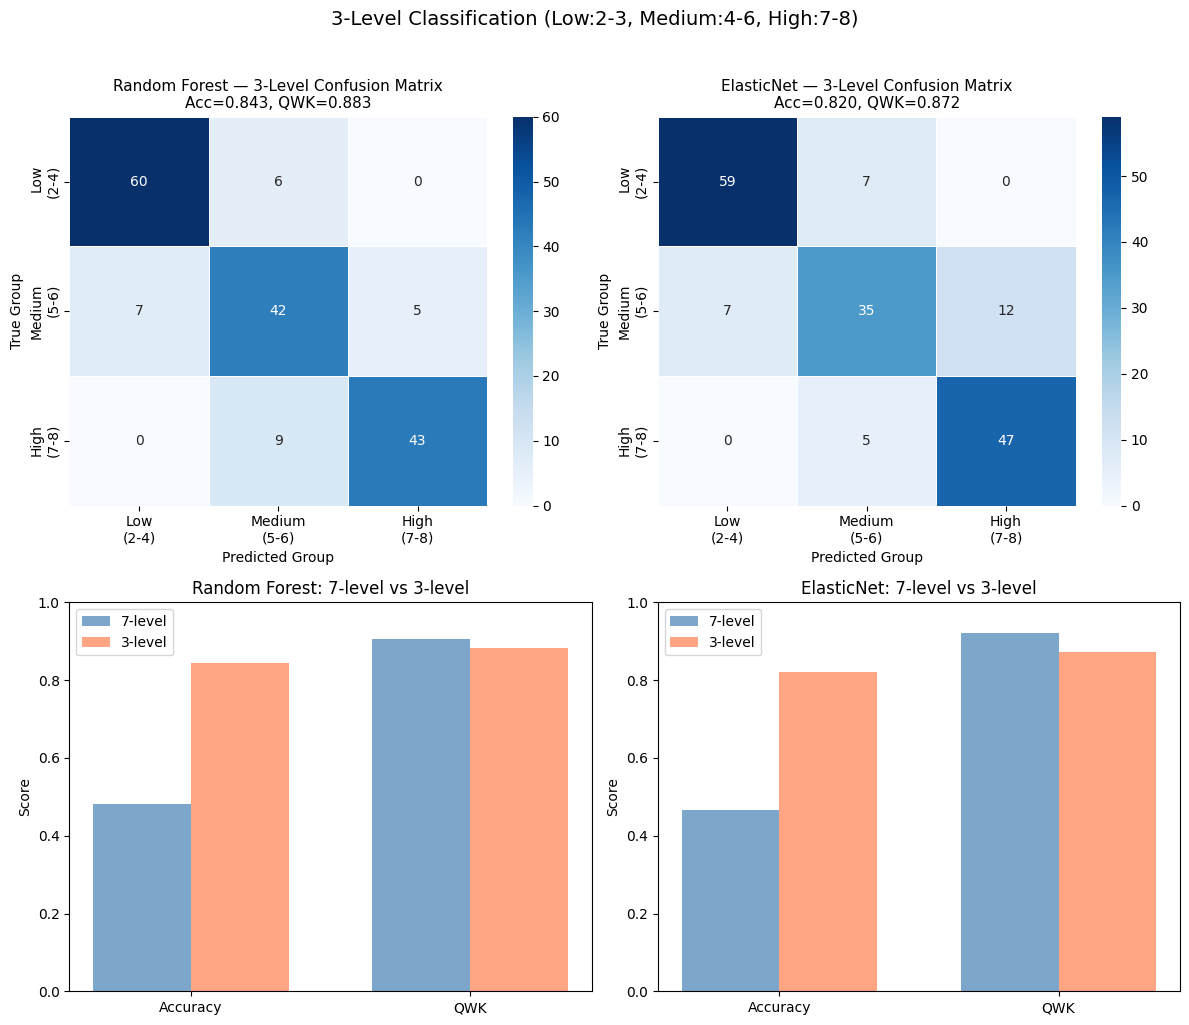


  Saved: /kaggle/working/ckpt/3level_classification_comparison.png

  DETAILED PER-GROUP ANALYSIS

  Random Forest:
  Group            Precision     Recall         F1  Support
  -------------------------------------------------------
  Low (2-3)            0.896      0.909      0.902       66
  Medium (4-6)         0.737      0.778      0.757       54
  High (7-8)           0.896      0.827      0.860       52

  ElasticNet:
  Group            Precision     Recall         F1  Support
  -------------------------------------------------------
  Low (2-3)            0.894      0.894      0.894       66
  Medium (4-6)         0.745      0.648      0.693       54
  High (7-8)           0.797      0.904      0.847       52

  Saved results: /kaggle/working/ckpt/3level_classification_results.csv
  Saved per-group results: /kaggle/working/ckpt/3level_per_group_results.csv


In [63]:
# =================================================================
# 3-LEVEL CLASSIFICATION (Low: 2-4, Medium: 5-6, High: 7-8)
# Evaluate both Random Forest and ElasticNet
# =================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, confusion_matrix
from collections import Counter

print('=' * 70)
print('  3-LEVEL CLASSIFICATION EVALUATION')
print('  Low (2-4)  |  Medium (5-6)  |  High (7-8)')
print('=' * 70)

# Define grade groups
GRADE_GROUPS = {
    0: {'name': 'Low (2-4)', 'grades': [2, 3, 4]},
    1: {'name': 'Medium (5-6)', 'grades': [5, 6]},
    2: {'name': 'High (7-8)', 'grades': [7, 8]}
}

# Mapping from original grade to group
def map_to_3level(grade):
    if grade in [2, 3,4]:
        return 0  # Low
    elif grade in [5, 6]:
        return 1  # Medium
    elif grade in [7, 8]:
        return 2  # High
    else:
        return -1  # Should not happen

# =================================================================
# 1. Process Random Forest predictions
# =================================================================
print('\n' + '=' * 70)
print('  RANDOM FOREST — 3-Level Classification')
print('=' * 70)

# Collect OOF predictions from RF bundles
rf_true_orig = []
rf_pred_orig = []

for b in bundles_RF:
    y_true = le.inverse_transform(np.asarray(b['y_test']).astype(int))
    y_pred = le.inverse_transform(np.asarray(b['y_pred']).astype(int))
    rf_true_orig.extend(y_true.tolist())
    rf_pred_orig.extend(y_pred.tolist())

rf_true_orig = np.array(rf_true_orig)
rf_pred_orig = np.array(rf_pred_orig)

# Map to 3 levels
rf_true_3l = np.array([map_to_3level(g) for g in rf_true_orig])
rf_pred_3l = np.array([map_to_3level(g) for g in rf_pred_orig])

# Remove any invalid mappings (should be none)
valid_mask = (rf_true_3l >= 0) & (rf_pred_3l >= 0)
rf_true_3l = rf_true_3l[valid_mask]
rf_pred_3l = rf_pred_3l[valid_mask]

# Calculate metrics
rf_acc_3l = accuracy_score(rf_true_3l, rf_pred_3l)
rf_qwk_3l = cohen_kappa_score(rf_true_3l, rf_pred_3l, weights='quadratic')
rf_f1_macro_3l = f1_score(rf_true_3l, rf_pred_3l, average='macro', zero_division=0)
rf_f1_weighted_3l = f1_score(rf_true_3l, rf_pred_3l, average='weighted', zero_division=0)

# Per-group accuracy
rf_group_acc = {}
for group_id, group_info in GRADE_GROUPS.items():
    mask = rf_true_3l == group_id
    if mask.sum() > 0:
        acc = (rf_pred_3l[mask] == group_id).mean()
        rf_group_acc[group_info['name']] = acc

print(f'\n  Random Forest 3-Level Metrics:')
print(f'    Accuracy:      {rf_acc_3l:.4f}')
print(f'    QWK:           {rf_qwk_3l:.4f}')
print(f'    F1 (macro):    {rf_f1_macro_3l:.4f}')
print(f'    F1 (weighted): {rf_f1_weighted_3l:.4f}')
print(f'\n  Per-Group Accuracy:')
for group_name, acc in rf_group_acc.items():
    print(f'    {group_name}: {acc:.4f}')

# Confusion matrix for RF
rf_cm_3l = confusion_matrix(rf_true_3l, rf_pred_3l, labels=[0, 1, 2])
group_labels = ['Low\n(2-4)', 'Medium\n(5-6)', 'High\n(7-8)']

# =================================================================
# 2. Process ElasticNet predictions
# =================================================================
print('\n' + '=' * 70)
print('  ELASTIC NET — 3-Level Classification')
print('=' * 70)

# Collect OOF predictions from EN bundles
en_true_orig = []
en_pred_orig = []

for b in bundles_EN:
    en_true_orig.extend(np.asarray(b['y_test']).astype(int).tolist())
    en_pred_orig.extend(np.asarray(b['y_pred']).astype(int).tolist())

en_true_orig = np.array(en_true_orig)
en_pred_orig = np.array(en_pred_orig)

# Map to 3 levels
en_true_3l = np.array([map_to_3level(g) for g in en_true_orig])
en_pred_3l = np.array([map_to_3level(g) for g in en_pred_orig])

# Remove any invalid mappings
valid_mask = (en_true_3l >= 0) & (en_pred_3l >= 0)
en_true_3l = en_true_3l[valid_mask]
en_pred_3l = en_pred_3l[valid_mask]

# Calculate metrics
en_acc_3l = accuracy_score(en_true_3l, en_pred_3l)
en_qwk_3l = cohen_kappa_score(en_true_3l, en_pred_3l, weights='quadratic')
en_f1_macro_3l = f1_score(en_true_3l, en_pred_3l, average='macro', zero_division=0)
en_f1_weighted_3l = f1_score(en_true_3l, en_pred_3l, average='weighted', zero_division=0)

# Per-group accuracy
en_group_acc = {}
for group_id, group_info in GRADE_GROUPS.items():
    mask = en_true_3l == group_id
    if mask.sum() > 0:
        acc = (en_pred_3l[mask] == group_id).mean()
        en_group_acc[group_info['name']] = acc

print(f'\n  ElasticNet 3-Level Metrics:')
print(f'    Accuracy:      {en_acc_3l:.4f}')
print(f'    QWK:           {en_qwk_3l:.4f}')
print(f'    F1 (macro):    {en_f1_macro_3l:.4f}')
print(f'    F1 (weighted): {en_f1_weighted_3l:.4f}')
print(f'\n  Per-Group Accuracy:')
for group_name, acc in en_group_acc.items():
    print(f'    {group_name}: {acc:.4f}')

# Confusion matrix for EN
en_cm_3l = confusion_matrix(en_true_3l, en_pred_3l, labels=[0, 1, 2])

# =================================================================
# 3. Compare Original 7-level vs 3-level performance
# =================================================================
print('\n' + '=' * 70)
print('  COMPARISON: 7-level vs 3-level Classification')
print('=' * 70)

# RF comparison
rf_qwk_7l = cohen_kappa_score(rf_true_orig, rf_pred_orig, weights='quadratic')
rf_acc_7l = accuracy_score(rf_true_orig, rf_pred_orig)

# EN comparison
en_qwk_7l = cohen_kappa_score(en_true_orig, en_pred_orig, weights='quadratic')
en_acc_7l = accuracy_score(en_true_orig, en_pred_orig)

comparison_data = []
for model, acc_7l, qwk_7l, acc_3l, qwk_3l in [
    ('Random Forest', rf_acc_7l, rf_qwk_7l, rf_acc_3l, rf_qwk_3l),
    ('ElasticNet', en_acc_7l, en_qwk_7l, en_acc_3l, en_qwk_3l)
]:
    comparison_data.append({
        'Model': model,
        '7-level Acc': f'{acc_7l:.4f}',
        '3-level Acc': f'{acc_3l:.4f}',
        'Acc Δ': f'{acc_3l - acc_7l:+.4f}',
        '7-level QWK': f'{qwk_7l:.4f}',
        '3-level QWK': f'{qwk_3l:.4f}',
        'QWK Δ': f'{qwk_3l - qwk_7l:+.4f}'
    })

comparison_df = pd.DataFrame(comparison_data)
print('\n', comparison_df.to_string(index=False))

# =================================================================
# 4. Visualization
# =================================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# RF Confusion Matrix (3-level)
sns.heatmap(rf_cm_3l, annot=True, fmt='d', cmap='Blues',
            xticklabels=group_labels, yticklabels=group_labels,
            linewidths=0.5, ax=axes[0, 0])
axes[0, 0].set_title(f'Random Forest — 3-Level Confusion Matrix\nAcc={rf_acc_3l:.3f}, QWK={rf_qwk_3l:.3f}', fontsize=11)
axes[0, 0].set_xlabel('Predicted Group')
axes[0, 0].set_ylabel('True Group')

# EN Confusion Matrix (3-level)
sns.heatmap(en_cm_3l, annot=True, fmt='d', cmap='Blues',
            xticklabels=group_labels, yticklabels=group_labels,
            linewidths=0.5, ax=axes[0, 1])
axes[0, 1].set_title(f'ElasticNet — 3-Level Confusion Matrix\nAcc={en_acc_3l:.3f}, QWK={en_qwk_3l:.3f}', fontsize=11)
axes[0, 1].set_xlabel('Predicted Group')
axes[0, 1].set_ylabel('True Group')

# Bar plot: 7-level vs 3-level comparison
x = np.arange(2)  # 2 models
width = 0.35

rf_7l = [rf_acc_7l, rf_qwk_7l]
rf_3l = [rf_acc_3l, rf_qwk_3l]
en_7l = [en_acc_7l, en_qwk_7l]
en_3l = [en_acc_3l, en_qwk_3l]

ax2 = axes[1, 0]
ax2.bar(x - width/2, rf_7l, width, label='7-level', color='steelblue', alpha=0.7)
ax2.bar(x + width/2, rf_3l, width, label='3-level', color='coral', alpha=0.7)
ax2.set_xticks(x)
ax2.set_xticklabels(['Accuracy', 'QWK'])
ax2.set_ylabel('Score')
ax2.set_title('Random Forest: 7-level vs 3-level')
ax2.legend()
ax2.set_ylim(0, 1)

ax3 = axes[1, 1]
ax3.bar(x - width/2, en_7l, width, label='7-level', color='steelblue', alpha=0.7)
ax3.bar(x + width/2, en_3l, width, label='3-level', color='coral', alpha=0.7)
ax3.set_xticks(x)
ax3.set_xticklabels(['Accuracy', 'QWK'])
ax3.set_ylabel('Score')
ax3.set_title('ElasticNet: 7-level vs 3-level')
ax3.legend()
ax3.set_ylim(0, 1)

plt.suptitle('3-Level Classification (Low:2-3, Medium:4-6, High:7-8)', fontsize=14, y=1.02)
plt.tight_layout()
fig_path = os.path.join(CKPT_DIR, '3level_classification_comparison.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'\n  Saved: {fig_path}')

# =================================================================
# 5. Detailed per-group analysis for both models
# =================================================================
print('\n' + '=' * 70)
print('  DETAILED PER-GROUP ANALYSIS')
print('=' * 70)

from sklearn.metrics import precision_recall_fscore_support

group_names = ['Low (2-3)', 'Medium (4-6)', 'High (7-8)']

# RF per-group stats
rf_prec, rf_rec, rf_f1, rf_sup = precision_recall_fscore_support(
    rf_true_3l, rf_pred_3l, labels=[0, 1, 2], zero_division=0)

# EN per-group stats
en_prec, en_rec, en_f1, en_sup = precision_recall_fscore_support(
    en_true_3l, en_pred_3l, labels=[0, 1, 2], zero_division=0)

print('\n  Random Forest:')
print(f'  {"Group":<15} {"Precision":>10} {"Recall":>10} {"F1":>10} {"Support":>8}')
print('  ' + '-' * 55)
for i, name in enumerate(group_names):
    print(f'  {name:<15} {rf_prec[i]:>10.3f} {rf_rec[i]:>10.3f} {rf_f1[i]:>10.3f} {rf_sup[i]:>8}')

print('\n  ElasticNet:')
print(f'  {"Group":<15} {"Precision":>10} {"Recall":>10} {"F1":>10} {"Support":>8}')
print('  ' + '-' * 55)
for i, name in enumerate(group_names):
    print(f'  {name:<15} {en_prec[i]:>10.3f} {en_rec[i]:>10.3f} {en_f1[i]:>10.3f} {en_sup[i]:>8}')

# =================================================================
# 6. Save results to CSV
# =================================================================
results_3level = {
    'Model': ['Random Forest', 'ElasticNet'],
    'Accuracy_7level': [rf_acc_7l, en_acc_7l],
    'Accuracy_3level': [rf_acc_3l, en_acc_3l],
    'QWK_7level': [rf_qwk_7l, en_qwk_7l],
    'QWK_3level': [rf_qwk_3l, en_qwk_3l],
    'F1_macro_3level': [rf_f1_macro_3l, en_f1_macro_3l],
}

results_df = pd.DataFrame(results_3level)
results_path = os.path.join(CKPT_DIR, '3level_classification_results.csv')
results_df.to_csv(results_path, index=False)
print(f'\n  Saved results: {results_path}')

# Per-group results
per_group_data = []
for model_name, prec, rec, f1, sup in [
    ('RF', rf_prec, rf_rec, rf_f1, rf_sup),
    ('EN', en_prec, en_rec, en_f1, en_sup)
]:
    for i, name in enumerate(group_names):
        per_group_data.append({
            'Model': model_name,
            'Group': name,
            'Precision': prec[i],
            'Recall': rec[i],
            'F1': f1[i],
            'Support': sup[i]
        })

per_group_df = pd.DataFrame(per_group_data)
per_group_path = os.path.join(CKPT_DIR, '3level_per_group_results.csv')
per_group_df.to_csv(per_group_path, index=False)
print(f'  Saved per-group results: {per_group_path}')

In [64]:
# ── 3. Load 7-grade FS results from the ORIGINAL 7-grade checkpoint dir ───


def _safe_name(s):
    return s.replace(' ','_').replace('/','_').replace('(','').replace(')','')

def _load_fs_from_ckpt(model_name, n_folds, ckpt_dir):
    results = []
    sn = _safe_name(model_name)
    for k in range(n_folds):
        path = os.path.join(ckpt_dir, sn, f'_MODEL_{sn}_fold{k}.pkl')
        assert os.path.exists(path), \
            f'Checkpoint not found: {path}'
        with open(path, 'rb') as f:
            results.append(pickle.load(f))
        print(f'  Loaded {model_name} fold {k}: '
              f'{len(results[-1]["final_features"])} features')
    return results

fs_EN3 = _load_fs_from_ckpt('ElasticNet_Regressor', N_OUTER_FOLDS, CKPT_DIR)
fs_RF3 = _load_fs_from_ckpt('RF_Classifier',        N_OUTER_FOLDS, CKPT_DIR)

  Loaded ElasticNet_Regressor fold 0: 8 features
  Loaded ElasticNet_Regressor fold 1: 15 features
  Loaded ElasticNet_Regressor fold 2: 17 features
  Loaded ElasticNet_Regressor fold 3: 14 features
  Loaded ElasticNet_Regressor fold 4: 12 features
  Loaded RF_Classifier fold 0: 55 features
  Loaded RF_Classifier fold 1: 131 features
  Loaded RF_Classifier fold 2: 54 features
  Loaded RF_Classifier fold 3: 105 features
  Loaded RF_Classifier fold 4: 58 features


In [75]:
# ─── OSE-B2: Rank correlation — 3-level NCERT models on OneStopEnglish ──────
import os, numpy as np, pandas as pd
from scipy.stats import spearmanr, kendalltau

# ── 1. Load OSE ──────────────────────────────────────────────────────────────
OSE_PATH           = '/kaggle/input/datasets/maureenmiranda11/18-05-26/onestop_coh.csv'
OSE_LABEL_COL      = 'level'
OSE_ARTICLE_ID_COL = 'index' # set to e.g. 'article_id' if you have it

assert os.path.exists(OSE_PATH), f'OSE file not found: {OSE_PATH}'
df_ose_raw = pd.read_csv(OSE_PATH)
df_ose_raw.columns = df_ose_raw.columns.str.strip()
print(f'OSE raw shape: {df_ose_raw.shape}')

# ── 2. Map labels → {1, 2, 3} ───────────────────────────────────────────────
OSE_LEVEL_MAP = {
    'ele': 1, 'elementary': 1, 'easy': 1, '1': 1, 1: 1,
    'int': 2, 'intermediate': 2, 'medium': 2, '2': 2, 2: 2,
    'adv': 3, 'advanced': 3,   'hard': 3,  '3': 3, 3: 3,
}
def _to_level(v):
    if pd.isna(v): return np.nan
    key = v.strip().lower() if isinstance(v, str) else v
    return OSE_LEVEL_MAP.get(key, np.nan)

y_ose_raw = df_ose_raw[OSE_LABEL_COL].apply(_to_level).astype('Float64')
n_bad = int(y_ose_raw.isna().sum())
if n_bad:
    print(f'  Dropping {n_bad} rows with unmappable labels')
    df_ose_raw = df_ose_raw.loc[y_ose_raw.notna()].reset_index(drop=True)
    y_ose_raw  = y_ose_raw.dropna().reset_index(drop=True)
y_ose = y_ose_raw.astype(int).values
n_ose = len(y_ose)
print(f'  Level distribution: {dict(zip(*np.unique(y_ose, return_counts=True)))}')

article_ids = df_ose_raw[OSE_ARTICLE_ID_COL].values \
              if OSE_ARTICLE_ID_COL and OSE_ARTICLE_ID_COL in df_ose_raw.columns \
              else None
print(f'  Article ID column: {"found" if article_ids is not None else "not found — pairwise skipped"}')

# ── 3. Textstat augmentation (same 4 columns as NCERT cell 2B) ──────────────
try:
    import textstat
except Exception:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'textstat'])
    import textstat

# Find text column
_TEXT_CANDS = [TEXT_COL, 'content', 'text', 'passage', 'article', 'story']
_ose_text_col = next((c for c in _TEXT_CANDS if c and c in df_ose_raw.columns), None)

if _ose_text_col is not None:
    print(f'  Text column for textstat: {_ose_text_col!r}')
    _texts = df_ose_raw[_ose_text_col].fillna('').astype(str)

    def _safe_ts(fn, t, default=np.nan):
        try: return fn(t)
        except: return default

    if 'textstat.linsear_write_formula' not in df_ose_raw.columns:
        df_ose_raw['textstat.linsear_write_formula'] = _texts.apply(
            lambda t: _safe_ts(textstat.linsear_write_formula, t))
    if 'textstat.reading_time' not in df_ose_raw.columns:
        df_ose_raw['textstat.reading_time'] = _texts.apply(
            lambda t: _safe_ts(textstat.reading_time, t))
    if 'textstat.spache_readability' not in df_ose_raw.columns:
        df_ose_raw['textstat.spache_readability'] = _texts.apply(
            lambda t: _safe_ts(textstat.spache_readability, t))
    if 'textstat.text_standard' not in df_ose_raw.columns:
        df_ose_raw['textstat.text_standard'] = _texts.apply(
            lambda t: _safe_ts(lambda x: textstat.text_standard(x, float_output=True), t))
    print('  textstat columns added (or already present)')
else:
    print('  WARNING: no text column found — textstat columns will be NaN-filled '
          'from NCERT medians if missing')

# ── 4. Density normalisation (same rules as NCERT cell 4.2) ─────────────────
df_ose_norm = df_ose_raw.copy()

if WORD_COUNT_COL not in df_ose_norm.columns:
    raise AssertionError(
        f'Word count column {WORD_COUNT_COL!r} missing from OSE. '
        f'Available: {list(df_ose_norm.columns[:20])}')

_exclude = {OSE_LABEL_COL, OSE_ARTICLE_ID_COL}
ose_count_cols = [
    c for c in df_ose_norm.columns
    if c != WORD_COUNT_COL and c not in _exclude
    and _is_raw_count_col(c, df_ose_norm[c])
]
# Force-add the AoA/Zipf totals that _is_raw_count_col may miss
for col in ['t_kup', 't_bry', 't_subtlex_us_zipf',
            'total_kuperman_aoa', 'total_brysbaert_aoa', 'total_subtlex_us_zipf']:
    if col in df_ose_norm.columns and col not in ose_count_cols and col != WORD_COUNT_COL:
        ose_count_cols.append(col)
# Catch any remaining to_* / total_* / t_* raw counts
for c in df_ose_norm.columns:
    if c in ose_count_cols or c in _exclude or c == WORD_COUNT_COL:
        continue
    if c == 'DESPC' and _is_integer_valued(df_ose_norm[c]):
        ose_count_cols.append(c)
    elif c.startswith(('to_', 'total_')) and _is_integer_valued(df_ose_norm[c]):
        ose_count_cols.append(c)
    elif (c.startswith('t_') and c not in ['t_word', 't_sent']
          and _is_integer_valued(df_ose_norm[c])):
        ose_count_cols.append(c)
ose_count_cols = list(dict.fromkeys(ose_count_cols))

wc = df_ose_norm[WORD_COUNT_COL].replace(0, np.nan)
for col in ose_count_cols:
    df_ose_norm[col] = (df_ose_norm[col] / wc) * 100.0
print(f'  Normalised {len(ose_count_cols)} count features → per-100-words')

# ── 5. Align to NCERT feature list + NaN-fill with NCERT medians ────────────
ncert_features = list(feature_names)
miss = [f for f in ncert_features if f not in df_ose_norm.columns]
print(f'  NCERT features missing from OSE: {len(miss)}'
      + (f'  (e.g. {miss[:5]})' if miss else ''))

X_ose_df = pd.DataFrame(index=df_ose_norm.index, columns=ncert_features, dtype=float)
for f in ncert_features:
    X_ose_df[f] = pd.to_numeric(df_ose_norm[f], errors='coerce') \
                  if f in df_ose_norm.columns else np.nan

ncert_meds = X_df.median(axis=0)
n_nan_before = int(X_ose_df.isna().sum().sum())
for f in ncert_features:
    if X_ose_df[f].isna().any():
        m = ncert_meds.get(f, np.nan)
        X_ose_df[f] = X_ose_df[f].fillna(0.0 if pd.isna(m) else float(m))
X_ose_df = X_ose_df.astype(np.float64)
assert np.isfinite(X_ose_df.values).all(), 'X_ose_df has non-finite values after fill'
print(f'  NaN fill: {n_nan_before} → 0  |  X_ose_df shape: {X_ose_df.shape}')


# ── 7. Rank correlation metrics ──────────────────────────────────────────────
def _pairwise_ordering(scores, levels, art_ids):
    """For each article with all 3 versions: is ele < int < adv in score?"""
    if art_ids is None:
        return None
    df_tmp = pd.DataFrame({'a': art_ids, 'lv': levels, 'sc': scores})
    ei, ia, ea, al = [], [], [], []
    n_trip = 0
    for _, grp in df_tmp.groupby('a'):
        lvs = grp['lv'].values
        scs = grp['sc'].values
        if not {1, 2, 3}.issubset(set(lvs)):
            continue
        n_trip += 1
        se = scs[lvs == 1][0]
        si = scs[lvs == 2][0]
        sa = scs[lvs == 3][0]
        ei.append(int(se < si))
        ia.append(int(si < sa))
        ea.append(int(se < sa))
        al.append(int(se < si and si < sa))
    return (float(np.mean(ei)), float(np.mean(ia)),
            float(np.mean(ea)), float(np.mean(al)), n_trip) if n_trip else None

def _rank_metrics(score_pf, score_avg):
    rhos, taus = [], []
    ei, ia, ea, al = [], [], [], []
    n_trip = None
    for k in range(N_OUTER_FOLDS):
        rhos.append(spearmanr(score_pf[k], y_ose)[0])
        taus.append(kendalltau(score_pf[k], y_ose)[0])
        po = _pairwise_ordering(score_pf[k], y_ose, article_ids)
        if po:
            ei.append(po[0]); ia.append(po[1])
            ea.append(po[2]); al.append(po[3])
            n_trip = po[4]
    out = {
        'Spearman_rho_mean': float(np.mean(rhos)),
        'Spearman_rho_std' : float(np.std(rhos, ddof=1)),
        'Kendall_tau_mean' : float(np.mean(taus)),
        'Kendall_tau_std'  : float(np.std(taus, ddof=1)),
        'Spearman_rho_avg' : float(spearmanr(score_avg, y_ose)[0]),
        'Kendall_tau_avg'  : float(kendalltau(score_avg, y_ose)[0]),
    }
    if ei:
        out.update({
            'pair_ele_int_mean': float(np.mean(ei)), 'pair_ele_int_std': float(np.std(ei, ddof=1)),
            'pair_int_adv_mean': float(np.mean(ia)), 'pair_int_adv_std': float(np.std(ia, ddof=1)),
            'pair_ele_adv_mean': float(np.mean(ea)), 'pair_ele_adv_std': float(np.std(ea, ddof=1)),
            'pair_all_mean'    : float(np.mean(al)), 'pair_all_std'    : float(np.std(al, ddof=1)),
            'n_triplets'       : int(n_trip),
        })
    return out





OSE raw shape: (567, 706)
  Level distribution: {np.int64(1): np.int64(189), np.int64(2): np.int64(189), np.int64(3): np.int64(189)}
  Article ID column: found
  Normalised 88 count features → per-100-words
  NCERT features missing from OSE: 4  (e.g. ['textstat.spache_readability', 'textstat.linsear_write_formula', 'textstat.text_standard', 'textstat.reading_time'])
  NaN fill: 2268 → 0  |  X_ose_df shape: (567, 502)


In [67]:
# ─── OSE-B1 (standalone): 3-level NCERT — reuse 7-grade features, retune ───
import numpy as np, pandas as pd, os, pickle
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, cohen_kappa_score, f1_score, make_scorer)
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestClassifier

# ── 1. Get 7-grade labels straight from df_norm (never overwritten) ────────
y_grade = df_norm[LABEL_COL].values.astype(int)
_y_unique = np.unique(y_grade)
assert set(_y_unique.tolist()) <= {2,3,4,5,6,7,8}, \
    f'df_norm[LABEL_COL] does not look like 7-grade labels: {_y_unique.tolist()}'
print(f'7-grade labels from df_norm: {_y_unique.tolist()}')

# ── 2. Collapse to 3 levels ────────────────────────────────────────────────
GRADE_COLLAPSE_MAP = {2:1, 3:1, 4:1, 5:2, 6:2, 7:3, 8:3}
LEVEL3_MIN, LEVEL3_MAX = 1, 3
y3       = np.array([GRADE_COLLAPSE_MAP[g] for g in y_grade], dtype=int)
le3      = LabelEncoder().fit(y3)
y3_enc   = le3.transform(y3).astype(int)
y3_float = y3.astype(float)
print('\n3-level distribution (1=easy 2=med 3=hard):')
print(pd.Series(y3).value_counts().sort_index().to_string())

# ── 3. Load 7-grade FS results from checkpoint files ──────────────────────
def _safe_name(s):
    return s.replace(' ','_').replace('/','_').replace('(','').replace(')','')

print(f'\nLoading FS checkpoints from: {CKPT_DIR}')
fs_EN3 = _load_fs_from_ckpt('ElasticNet_Regressor', N_OUTER_FOLDS, CKPT_DIR)
fs_RF3 = _load_fs_from_ckpt('RF_Classifier',        N_OUTER_FOLDS, CKPT_DIR)

# Verify fold alignment
for k, fr in enumerate(fs_EN3):
    tr_e, te_e = outer_splits[k]
    assert np.array_equal(np.sort(fr['train_idx']), np.sort(tr_e)), \
        f'EN fold {k}: train_idx mismatch with outer_splits'
print('Fold alignment verified.')

# ── 4. Hyperparameter grids ────────────────────────────────────────────────
PARAM_GRID_EN = {
    'clf__alpha'   : [0.001, 0.01, 0.1, 1.0, 10.0],
    'clf__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}
PARAM_GRID_RF = {
    'clf__n_estimators'    : [200, 300, 500, 800],
    'clf__max_depth'       : [None, 8],
    'clf__min_samples_leaf': [2, 4],
    'clf__max_features'    : ['sqrt', 0.5],
}

def _qwk_reg(y_true, y_pred):
    yp = np.clip(np.rint(np.asarray(y_pred)).astype(int), LEVEL3_MIN, LEVEL3_MAX)
    return cohen_kappa_score(np.asarray(y_true).astype(int), yp, weights='quadratic')

qwk_scorer_reg = make_scorer(_qwk_reg, greater_is_better=True)
qwk_scorer_cls = make_scorer(
    lambda yt, yp: cohen_kappa_score(yt, yp, weights='quadratic'),
    greater_is_better=True)

def _within_one(t, p):
    return float(np.mean(np.abs(np.asarray(t).astype(int) -
                                 np.asarray(p).astype(int)) <= 1))

# ── 5. Per-fold retuning ───────────────────────────────────────────────────
bundles_EN3, bundles_RF3 = [], []
print('\n' + '=' * 70)
print('  OSE-B1 — per-fold retuning (7-grade FS reused; 3-level labels)')
print('=' * 70)

for k in range(N_OUTER_FOLDS):
    tr_idx, te_idx = outer_splits[k]
    inner = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

    # ── ElasticNet ──────────────────────────────────────────────────────────
    feats_en = [f for f in fs_EN3[k]['final_features'] if f in X_df.columns]
    assert feats_en, f'fold {k}: EN feature list empty.'
    X_tr_en = X_df[feats_en].values[tr_idx]
    X_te_en = X_df[feats_en].values[te_idx]
    y_tr_en, y_te_en = y3_float[tr_idx], y3[te_idx]

    pipe_en = Pipeline([('scaler', StandardScaler()),
                         ('clf',   ElasticNet(max_iter=10000, random_state=RANDOM_STATE))])
    gs_en = GridSearchCV(pipe_en, PARAM_GRID_EN, cv=inner,
                          scoring=qwk_scorer_reg, refit=True, n_jobs=-1)
    gs_en.fit(X_tr_en, y_tr_en)
    raw_te = gs_en.predict(X_te_en)
    yp_en  = np.clip(np.rint(raw_te).astype(int), LEVEL3_MIN, LEVEL3_MAX)

    bundles_EN3.append({
        'model_name': 'ElasticNet_Regressor', 'outer_fold': k,
        'features': feats_en, 'n_features': len(feats_en),
        'best_params': gs_en.best_params_, 'inner_cv_score': float(gs_en.best_score_),
        'fitted_pipeline': gs_en.best_estimator_,
        'y_test': y_te_en, 'y_pred': yp_en, 'y_pred_raw': raw_te,
        'acc': accuracy_score(y_te_en, yp_en),
        'w1' : _within_one(y_te_en, yp_en),
        'qwk': cohen_kappa_score(y_te_en, yp_en, weights='quadratic'),
        'f1m': f1_score(y_te_en, yp_en, average='macro', zero_division=0),
    })

    # ── RandomForest ────────────────────────────────────────────────────────
    feats_rf = [f for f in fs_RF3[k]['final_features'] if f in X_df.columns]
    assert feats_rf, f'fold {k}: RF feature list empty.'
    X_tr_rf = X_df[feats_rf].values[tr_idx]
    X_te_rf = X_df[feats_rf].values[te_idx]
    y_tr_rf, y_te_rf = y3_enc[tr_idx], y3_enc[te_idx]

    pipe_rf = Pipeline([('scaler', StandardScaler()),
                         ('clf',   RandomForestClassifier(
                             class_weight='balanced',
                             random_state=RANDOM_STATE, n_jobs=1))])
    gs_rf = GridSearchCV(pipe_rf, PARAM_GRID_RF, cv=inner,
                          scoring=qwk_scorer_cls, refit=True, n_jobs=-1)
    gs_rf.fit(X_tr_rf, y_tr_rf)
    yp_rf_enc   = gs_rf.predict(X_te_rf).astype(int)
    yp_rf       = le3.inverse_transform(yp_rf_enc)
    y_te_rf_dec = le3.inverse_transform(y_te_rf)

    bundles_RF3.append({
        'model_name': 'RF_Classifier', 'outer_fold': k,
        'features': feats_rf, 'n_features': len(feats_rf),
        'best_params': gs_rf.best_params_, 'inner_cv_score': float(gs_rf.best_score_),
        'fitted_pipeline': gs_rf.best_estimator_,
        'y_test': y_te_rf_dec, 'y_pred': yp_rf,
        'acc': accuracy_score(y_te_rf_dec, yp_rf),
        'w1' : _within_one(y_te_rf_dec, yp_rf),
        'qwk': cohen_kappa_score(y_te_rf_dec, yp_rf, weights='quadratic'),
        'f1m': f1_score(y_te_rf_dec, yp_rf, average='macro', zero_division=0),
    })

    print(f'  fold {k}:  '
          f'RF  n={len(feats_rf):3d}  acc={bundles_RF3[-1]["acc"]:.3f}  '
          f'qwk={bundles_RF3[-1]["qwk"]:.4f}  inner={gs_rf.best_score_:.4f}')

pipes_RF3 = [b['fitted_pipeline'] for b in bundles_RF3]

# ── 6. Summary ────────────────────────────────────────────────────────────
def _agg(bundles, name):
    df = pd.DataFrame([{'Acc': b['acc'], 'W1': b['w1'], 'QWK': b['qwk'],
                         'F1m': b['f1m'], 'n': b['n_features']} for b in bundles])
    return {'Model': name,
            'Acc': df['Acc'].mean(), 'Acc_std': df['Acc'].std(ddof=1),
            'W1':  df['W1'].mean(),  'W1_std':  df['W1'].std(ddof=1),
            'QWK': df['QWK'].mean(), 'QWK_std': df['QWK'].std(ddof=1),
            'F1m': df['F1m'].mean(), 'F1m_std': df['F1m'].std(ddof=1),
            'n_feats': f"{df['n'].mean():.1f}"}

ncert3_cv_metrics_df = pd.DataFrame([
    _agg(bundles_RF3, 'RandomForest (3-level)'),
])
print('\n' + '=' * 90)
print('  NCERT 3-LEVEL CV RESULTS  (mean ± std across folds)')
print('=' * 90)
for _, r in ncert3_cv_metrics_df.iterrows():
    print(f"  {r['Model']:<30}  Acc={r['Acc']:.3f}±{r['Acc_std']:.3f}  "
          f"W1={r['W1']:.3f}±{r['W1_std']:.3f}  "
          f"QWK={r['QWK']:.4f}±{r['QWK_std']:.4f}  "
          f"F1m={r['F1m']:.3f}±{r['F1m_std']:.3f}  n_feats={r['n_feats']}")
print('\nExposed: y3, le3, bundles_EN3, bundles_RF3, pipes_EN3, pipes_RF3, '
      'ncert3_cv_metrics_df, LEVEL3_MIN, LEVEL3_MAX')

7-grade labels from df_norm: [2, 3, 4, 5, 6, 7, 8]

3-level distribution (1=easy 2=med 3=hard):
1    66
2    54
3    52

Loading FS checkpoints from: /kaggle/working/ckpt
  Loaded ElasticNet_Regressor fold 0: 8 features
  Loaded ElasticNet_Regressor fold 1: 15 features
  Loaded ElasticNet_Regressor fold 2: 17 features
  Loaded ElasticNet_Regressor fold 3: 14 features
  Loaded ElasticNet_Regressor fold 4: 12 features
  Loaded RF_Classifier fold 0: 55 features
  Loaded RF_Classifier fold 1: 131 features
  Loaded RF_Classifier fold 2: 54 features
  Loaded RF_Classifier fold 3: 105 features
  Loaded RF_Classifier fold 4: 58 features
Fold alignment verified.

  OSE-B1 — per-fold retuning (7-grade FS reused; 3-level labels)
  fold 0:  RF  n= 55  acc=0.800  qwk=0.8551  inner=0.8901
  fold 1:  RF  n=131  acc=0.800  qwk=0.8440  inner=0.8968
  fold 2:  RF  n= 54  acc=0.853  qwk=0.8965  inner=0.8745
  fold 3:  RF  n=105  acc=0.912  qwk=0.9323  inner=0.8605
  fold 4:  RF  n= 58  acc=0.882  qwk=0.9

# using just the 7 grade classifier merged

In [66]:
# ─────────────────────────────────────────────────────────────────────────────
# OSE-RANK  —  3-level NCERT → OSE  rank correlation  (no hypertuning)
#
#   Lightweight alternative to OSE-B1+B2:
#     1. Take per-fold Stage-3 final_features (already selected for 7-grade)
#     2. Collapse NCERT grades:  {2,3,4}→1, {5,6}→2, {7,8}→3
#     3. Train EN regressor + RF classifier with FIXED hypers on each fold's
#        3-level train indices  — no GridSearchCV
#     4. Score OSE through all 5 fold models; AVERAGE scores
#     5. Spearman / Kendall / Pearson rank correlation with y_ose
#
# Prereqs in scope:
#   fs_results (with 'ElasticNet_Regressor' and 'RF_Classifier' keys, each
#               a list of N_OUTER_FOLDS dicts containing 'final_features'),
#   X_df, y_float, outer_splits, X_ose_df, y_ose,
#   GRADE_MIN, GRADE_MAX, N_OUTER_FOLDS, RANDOM_STATE, CKPT_DIR
# ─────────────────────────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import spearmanr, kendalltau, pearsonr

print('=' * 78)
print('  OSE-RANK — 3-level NCERT → OSE  rank correlation  (no tuning)')
print('=' * 78)

# ── 3-level grade collapse  (must match OSE-B1 / OSE-B3) ───────────────────
COLLAPSE_3L = {2:1, 3:1, 4:1, 5:2, 6:2, 7:3, 8:3}
LEVEL_MIN, LEVEL_MAX = 1, 3
LEVELS_F = np.arange(LEVEL_MIN, LEVEL_MAX + 1, dtype=float)

# ── Fixed hypers (same family as DIM-A / DIM-B base estimators) ────────────
EN_BASE_3L = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000,
                         random_state=RANDOM_STATE)
RF_BASE_3L = RandomForestClassifier(n_estimators=300, max_depth=8,
                                     min_samples_leaf=4, max_features='sqrt',
                                     class_weight='balanced', n_jobs=1,
                                     random_state=RANDOM_STATE)

# ── NCERT 3-level labels ───────────────────────────────────────────────────
y_int        = np.clip(np.rint(y_float).astype(int), GRADE_MIN, GRADE_MAX)
y_3l_int     = np.array([COLLAPSE_3L[g] for g in y_int], dtype=int)
y_3l_float   = y_3l_int.astype(float)
print(f'\n  NCERT 3-level dist : '
      f'{dict(zip(*np.unique(y_3l_int, return_counts=True)))}')
print(f'  OSE         dist   : '
      f'{dict(zip(*np.unique(y_ose,     return_counts=True)))}')

# ── Per-fold scoring on OSE ────────────────────────────────────────────────
n_ose = len(y_ose)
en_per_fold        = np.zeros((N_OUTER_FOLDS, n_ose),    dtype=float)
rf_proba_per_fold  = np.zeros((N_OUTER_FOLDS, n_ose, 3), dtype=float)
en_feat_counts, rf_feat_counts = [], []

print(f'\n  Training per-fold models with fixed hypers ...')
for k in range(N_OUTER_FOLDS):
    feats_en = [f for f in fs_results['ElasticNet_Regressor'][k]['final_features']
                  if f in X_df.columns and f in X_ose_df.columns]
    feats_rf = [f for f in fs_results['RF_Classifier'        ][k]['final_features']
                  if f in X_df.columns and f in X_ose_df.columns]
    assert feats_en, f'fold {k}: EN final_features empty after OSE alignment'
    assert feats_rf, f'fold {k}: RF final_features empty after OSE alignment'
    en_feat_counts.append(len(feats_en))
    rf_feat_counts.append(len(feats_rf))

    tr_idx = outer_splits[k][0]

    # EN regressor — predicts continuous 3-level score
    p_en = Pipeline([('sc', StandardScaler()), ('clf', clone(EN_BASE_3L))])
    p_en.fit(X_df[feats_en].values[tr_idx], y_3l_float[tr_idx])
    en_per_fold[k] = p_en.predict(X_ose_df[feats_en].values)

    # RF classifier — aligned class-probabilities (columns ordered as [1,2,3])
    p_rf = Pipeline([('sc', StandardScaler()), ('clf', clone(RF_BASE_3L))])
    p_rf.fit(X_df[feats_rf].values[tr_idx], y_3l_int[tr_idx])
    proba   = p_rf.predict_proba(X_ose_df[feats_rf].values)
    classes = p_rf.named_steps['clf'].classes_.astype(int)
    aligned = np.zeros((n_ose, 3))
    for ci, c in enumerate(classes):
        aligned[:, c - LEVEL_MIN] = proba[:, ci]
    rf_proba_per_fold[k] = aligned

    print(f'  fold {k}:  EN n_feat={len(feats_en):3d}  RF n_feat={len(feats_rf):3d}  '
          f'EN range=[{en_per_fold[k].min():+.3f}, {en_per_fold[k].max():+.3f}]')

# ── Fold-averaged scores ───────────────────────────────────────────────────
en_score_ose = en_per_fold.mean(axis=0)
rf_proba_ose = rf_proba_per_fold.mean(axis=0)
rf_score_ose = rf_proba_ose @ LEVELS_F                       # expected level

# ── Rank correlations on fold-averaged scores ──────────────────────────────
def _corrs(score, y):
    return (float(spearmanr (score, y)[0]),
            float(kendalltau(score, y)[0]),
            float(pearsonr  (score, y.astype(float))[0]))

en_rho, en_tau, en_r = _corrs(en_score_ose, y_ose)
rf_rho, rf_tau, rf_r = _corrs(rf_score_ose, y_ose)

# Per-fold rank correlations (variance estimate)
en_fold_rho = [float(spearmanr(en_per_fold[k], y_ose)[0])
                for k in range(N_OUTER_FOLDS)]
rf_fold_score_k = rf_proba_per_fold @ LEVELS_F
rf_fold_rho = [float(spearmanr(rf_fold_score_k[k], y_ose)[0])
                for k in range(N_OUTER_FOLDS)]

# ── Print summary ──────────────────────────────────────────────────────────
print(f'\n  {"="*62}')
print(f'  RANK CORRELATION  (fold-averaged scores, n_ose={n_ose})')
print(f'  {"="*62}')
print(f"  {'Metric':<14}{'ElasticNet':>20}{'Random Forest':>20}")
print('  ' + '-' * 54)
print(f"  {'Spearman ρ':<14}{en_rho:>+20.4f}{rf_rho:>+20.4f}")
print(f"  {'Kendall  τ':<14}{en_tau:>+20.4f}{rf_tau:>+20.4f}")
print(f"  {'Pearson  r':<14}{en_r  :>+20.4f}{rf_r  :>+20.4f}")

print(f'\n  Per-fold Spearman ρ (variance estimate):')
print(f'    EN: mean={np.mean(en_fold_rho):+.4f}  '
      f'std={np.std(en_fold_rho, ddof=1):.4f}   '
      f'folds=[{", ".join(f"{x:+.3f}" for x in en_fold_rho)}]')
print(f'    RF: mean={np.mean(rf_fold_rho):+.4f}  '
      f'std={np.std(rf_fold_rho, ddof=1):.4f}   '
      f'folds=[{", ".join(f"{x:+.3f}" for x in rf_fold_rho)}]')

print(f'\n  Per-fold feature counts:  EN={en_feat_counts}   RF={rf_feat_counts}')

# ── Save ───────────────────────────────────────────────────────────────────
out_csv = os.path.join(CKPT_DIR, 'ose_rank_corr_no_tuning.csv')
pd.DataFrame([
    {'Model':'ElasticNet','Spearman':en_rho,'Kendall':en_tau,'Pearson':en_r,
     'fold_rho_mean':np.mean(en_fold_rho),
     'fold_rho_std' :np.std (en_fold_rho, ddof=1)},
    {'Model':'RandomForest','Spearman':rf_rho,'Kendall':rf_tau,'Pearson':rf_r,
     'fold_rho_mean':np.mean(rf_fold_rho),
     'fold_rho_std' :np.std (rf_fold_rho, ddof=1)},
]).to_csv(out_csv, index=False)
print(f'\n  Saved: {out_csv}')
print('  Exposed: en_score_ose, rf_score_ose, rf_proba_ose,')
print('           en_per_fold, rf_proba_per_fold, y_3l_int, y_3l_float')

  OSE-RANK — 3-level NCERT → OSE  rank correlation  (no tuning)

  NCERT 3-level dist : {np.int64(1): np.int64(66), np.int64(2): np.int64(54), np.int64(3): np.int64(52)}
  OSE         dist   : {np.int64(1): np.int64(189), np.int64(2): np.int64(189), np.int64(3): np.int64(189)}

  Training per-fold models with fixed hypers ...
  fold 0:  EN n_feat=  8  RF n_feat= 55  EN range=[+1.465, +3.371]
  fold 1:  EN n_feat= 15  RF n_feat=131  EN range=[+1.408, +3.566]
  fold 2:  EN n_feat= 17  RF n_feat= 54  EN range=[+1.460, +3.350]
  fold 3:  EN n_feat= 14  RF n_feat=105  EN range=[+1.484, +3.585]
  fold 4:  EN n_feat= 12  RF n_feat= 58  EN range=[+1.374, +3.490]

  RANK CORRELATION  (fold-averaged scores, n_ose=567)
  Metric                  ElasticNet       Random Forest
  ------------------------------------------------------
  Spearman ρ                 +0.7939             +0.7733
  Kendall  τ                 +0.6558             +0.6365
  Pearson  r                 +0.7720             +0.76

# SECTION — Dimension-Level Ablation & Feature Importance

Three complementary analyses, all using the same 5 outer folds as the main
pipeline so results are directly comparable.


**Hyper-parameters** are held fixed across all dimensions / cumulative steps
in DIM-A and DIM-B so that QWK differences reflect feature-set changes only —
not re-tuning effects. The base estimators used here are *not* the final
tuned production models from Sections 7–8 (those were per-fold tuned on the
post-FS feature set), so absolute QWK numbers here will be lower; they are
intended for **dimension comparison**, not as the headline results.



  DIM-A — Per-fold dimensional classifiers from Stage-2 features

  ELASTICNET (regressor) — per-dim 5-fold mean ± std
  --------------------------------------------------------------------------------------
  Dimension                        n_feat          Acc           W1          QWK          F1m
  D7_Semantic_Coherence           4.6±0.5  0.408±0.138  0.936±0.047  0.880±0.035  0.380±0.141
  D5_Grammatical_Density_and_Diversity       7.0±1.2  0.432±0.150  0.907±0.047  0.872±0.046  0.418±0.154
  D8_Discourse_Structure_and_Organisation       6.2±1.6  0.413±0.068  0.902±0.065  0.868±0.049  0.366±0.061
  D10_Readability_Surface_Indices       3.8±0.8  0.360±0.111  0.884±0.067  0.845±0.042  0.324±0.121
  D1_Surface_Word_Level           5.8±1.9  0.378±0.109  0.849±0.051  0.829±0.043  0.337±0.126
  D4_Syntactic_Complexity         5.4±1.1  0.280±0.105  0.774±0.089  0.711±0.115  0.263±0.114
  D3_Lexical_Sophistication       4.2±1.3  0.285±0.074  0.739±0.087  0.697±0.094  0.272±0.098
  D9_Sema

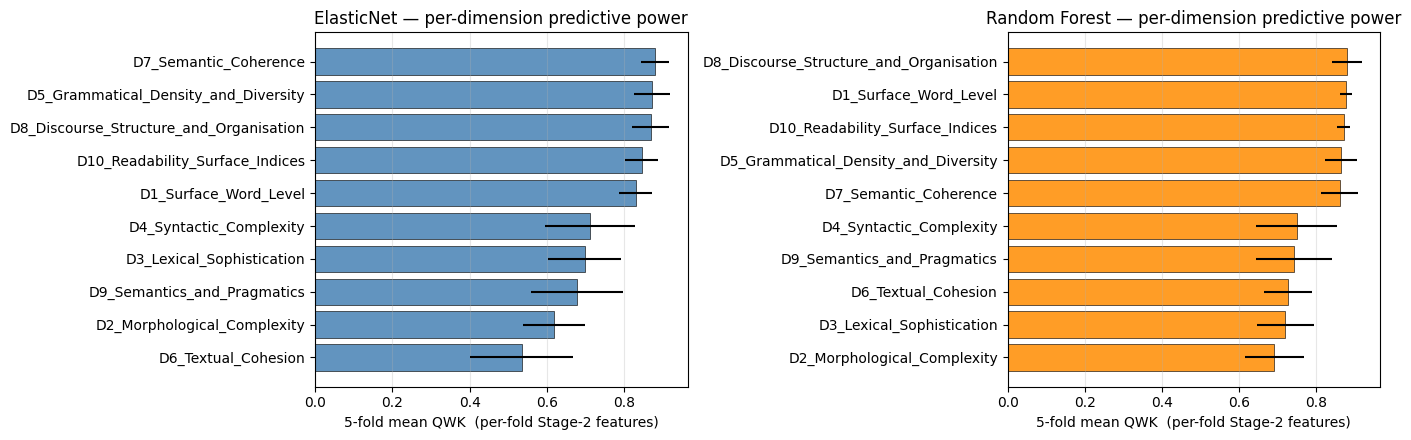


  Saved: /kaggle/working/ckpt/dim_A_per_fold_stage2.png, dim_A_per_fold_stage2.csv, dim_A_summary_stage2.csv
  Exposed: dimA_per_fold, dimA_summary, EN_BASE, RF_BASE, y_int, EN_KEY, RF_KEY


In [68]:
# ============================== DIM-A ==============================
# ─────────────────────────────────────────────────────────────────────────────
# DIM-A — Per-fold dimensional classifiers using Stage-2 features
#
#   For each (fold k, dim D, model M) ∈ {5} × {dims} × {EN, RF}:
#     1. features = fs_results[M][k]['group_results'][D]['s2_features']
#     2. train M with FIXED hyper-params on fold-k train indices
#     3. evaluate on fold-k test indices
#   → produces a 5-fold table per (D, M).  Hyper-tuning skipped on purpose:
#   we want dimensional differences, not tuning luck.
#
#   Leakage-free: Stage-2 selection happened on fold-k train only (you ran
#   the FS pipeline that way), so this is honest per-fold evaluation.
#
#   Prereqs:  fs_results (with 'ElasticNet_Regressor' and 'RF_Classifier'),
#             outer_splits, feature_groups_present, X_df, y_float,
#             GRADE_MIN, GRADE_MAX, N_OUTER_FOLDS, RANDOM_STATE, CKPT_DIR
# ─────────────────────────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score

print('=' * 80)
print('  DIM-A — Per-fold dimensional classifiers from Stage-2 features')
print('=' * 80)

EN_KEY, RF_KEY = 'ElasticNet_Regressor', 'RF_Classifier'
EN_BASE = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000,
                     random_state=RANDOM_STATE)
RF_BASE = RandomForestClassifier(n_estimators=200, max_depth=8,
                                  min_samples_leaf=4, max_features='sqrt',
                                  class_weight='balanced', n_jobs=1,
                                  random_state=RANDOM_STATE)
y_int = np.clip(np.rint(y_float).astype(int), GRADE_MIN, GRADE_MAX)

dims_all = list(feature_groups_present.keys())

def _s2(model_key, dim, k):
    gr = fs_results[model_key][k].get('group_results', {})
    return [f for f in gr.get(dim, {}).get('s2_features', []) or []
            if f in X_df.columns]

def _eval_fold(feats, k, model_kind):
    if not feats:
        return dict(Acc=np.nan, W1=np.nan, QWK=np.nan, F1m=np.nan, n_feat=0)
    tr, te = outer_splits[k]
    Xv = X_df[feats].values
    if model_kind == 'EN':
        pipe = Pipeline([('sc', StandardScaler()), ('clf', clone(EN_BASE))])
        pipe.fit(Xv[tr], y_float[tr])
        yp = np.clip(np.rint(pipe.predict(Xv[te])).astype(int),
                     GRADE_MIN, GRADE_MAX)
    else:
        pipe = Pipeline([('sc', StandardScaler()), ('clf', clone(RF_BASE))])
        pipe.fit(Xv[tr], y_int[tr])
        yp = pipe.predict(Xv[te]).astype(int)
    yt = y_int[te]
    return dict(
        Acc = accuracy_score(yt, yp),
        W1  = float(np.mean(np.abs(yt - yp) <= 1)),
        QWK = cohen_kappa_score(yt, yp, weights='quadratic'),
        F1m = f1_score(yt, yp, average='macro', zero_division=0),
        n_feat = len(feats),
    )

# ── Run per-fold evaluation ────────────────────────────────────────────────
rows = []
for dim in dims_all:
    for k in range(N_OUTER_FOLDS):
        en_m = _eval_fold(_s2(EN_KEY, dim, k), k, 'EN')
        rf_m = _eval_fold(_s2(RF_KEY, dim, k), k, 'RF')
        rows.append({'Dimension': dim, 'Fold': k,
                     'EN_n_feat': en_m['n_feat'], 'RF_n_feat': rf_m['n_feat'],
                     'EN_Acc': en_m['Acc'], 'EN_W1': en_m['W1'],
                     'EN_QWK': en_m['QWK'], 'EN_F1m': en_m['F1m'],
                     'RF_Acc': rf_m['Acc'], 'RF_W1': rf_m['W1'],
                     'RF_QWK': rf_m['QWK'], 'RF_F1m': rf_m['F1m']})
dimA_per_fold = pd.DataFrame(rows)

# ── 5-fold summary (mean ± std) ────────────────────────────────────────────
agg_cols = ['EN_n_feat','EN_Acc','EN_W1','EN_QWK','EN_F1m',
            'RF_n_feat','RF_Acc','RF_W1','RF_QWK','RF_F1m']
dimA_summary = (dimA_per_fold
                .groupby('Dimension')[agg_cols]
                .agg(['mean','std'])
                .round(4))

# ── Print clean tables ─────────────────────────────────────────────────────
def _fmt(m, s, nd=3):
    if np.isnan(m): return '   NaN   '
    return f'{m:>5.{nd}f}±{s:.{nd}f}' if not np.isnan(s) else f'{m:>5.{nd}f}      '

print('\n  ELASTICNET (regressor) — per-dim 5-fold mean ± std')
print('  ' + '-' * 86)
print(f'  {"Dimension":<25}{"n_feat":>14}{"Acc":>13}{"W1":>13}{"QWK":>13}{"F1m":>13}')
en_sorted = dimA_summary.sort_values(('EN_QWK','mean'), ascending=False).index.tolist()
for d in en_sorted:
    r = dimA_summary.loc[d]
    print(f'  {d:<25}'
          f'{_fmt(r[("EN_n_feat","mean")], r[("EN_n_feat","std")], 1):>14}'
          f'{_fmt(r[("EN_Acc","mean")],    r[("EN_Acc","std")]):>13}'
          f'{_fmt(r[("EN_W1","mean")],     r[("EN_W1","std")]):>13}'
          f'{_fmt(r[("EN_QWK","mean")],    r[("EN_QWK","std")]):>13}'
          f'{_fmt(r[("EN_F1m","mean")],    r[("EN_F1m","std")]):>13}')

print('\n  RANDOM FOREST (classifier) — per-dim 5-fold mean ± std')
print('  ' + '-' * 86)
print(f'  {"Dimension":<25}{"n_feat":>14}{"Acc":>13}{"W1":>13}{"QWK":>13}{"F1m":>13}')
rf_sorted = dimA_summary.sort_values(('RF_QWK','mean'), ascending=False).index.tolist()
for d in rf_sorted:
    r = dimA_summary.loc[d]
    print(f'  {d:<25}'
          f'{_fmt(r[("RF_n_feat","mean")], r[("RF_n_feat","std")], 1):>14}'
          f'{_fmt(r[("RF_Acc","mean")],    r[("RF_Acc","std")]):>13}'
          f'{_fmt(r[("RF_W1","mean")],     r[("RF_W1","std")]):>13}'
          f'{_fmt(r[("RF_QWK","mean")],    r[("RF_QWK","std")]):>13}'
          f'{_fmt(r[("RF_F1m","mean")],    r[("RF_F1m","std")]):>13}')

# ── Raw 5-fold values printout ─────────────────────────────────────────────
print('\n  RAW PER-FOLD QWK  (each cell = 5 fold values, EN | RF)')
print('  ' + '-' * 80)
for d in dims_all:
    sub = dimA_per_fold[dimA_per_fold['Dimension'] == d].sort_values('Fold')
    en  = '  '.join(f'{v:.3f}' if not np.isnan(v) else ' NaN ' for v in sub['EN_QWK'])
    rf  = '  '.join(f'{v:.3f}' if not np.isnan(v) else ' NaN ' for v in sub['RF_QWK'])
    print(f'  {d:<24}  EN: [{en}]   RF: [{rf}]')

# ── Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.45 * len(dims_all))))
for ax, sorted_dims, qwk_col, color, title in [
    (axes[0], en_sorted, 'EN_QWK', 'steelblue',  'ElasticNet'),
    (axes[1], rf_sorted, 'RF_QWK', 'darkorange', 'Random Forest'),
]:
    means = [dimA_summary.loc[d, (qwk_col, 'mean')] for d in sorted_dims]
    stds  = [dimA_summary.loc[d, (qwk_col, 'std' )] for d in sorted_dims]
    y = np.arange(len(sorted_dims))
    ax.barh(y, means, xerr=stds, color=color, alpha=0.85,
            edgecolor='black', linewidth=0.5)
    ax.set_yticks(y); ax.set_yticklabels(sorted_dims); ax.invert_yaxis()
    ax.set_xlabel('5-fold mean QWK  (per-fold Stage-2 features)')
    ax.set_title(f'{title} — per-dimension predictive power')
    ax.axvline(0, color='black', linewidth=0.7); ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
out_png = os.path.join(CKPT_DIR, 'dim_A_per_fold_stage2.png')
plt.savefig(out_png, dpi=150, bbox_inches='tight'); plt.show()

dimA_per_fold.to_csv(os.path.join(CKPT_DIR, 'dim_A_per_fold_stage2.csv'),  index=False)
dimA_summary.to_csv (os.path.join(CKPT_DIR, 'dim_A_summary_stage2.csv'))
print(f'\n  Saved: {out_png}, dim_A_per_fold_stage2.csv, dim_A_summary_stage2.csv')
print('  Exposed: dimA_per_fold, dimA_summary, EN_BASE, RF_BASE, y_int, EN_KEY, RF_KEY')

In [69]:
# ── Print clean tables using pandas ────────────────────────────────────────
print('\n  RANDOM FOREST (classifier) — per-dim 5-fold mean ± std')
print('  ' + '-' * 100)

# Create a formatted summary table for RF
rf_print = pd.DataFrame(index=rf_sorted)
rf_print['n_feat'] = [f"{dimA_summary.loc[d, ('RF_n_feat','mean')]:.1f}±{dimA_summary.loc[d, ('RF_n_feat','std')]:.1f}" 
                       for d in rf_sorted]
rf_print['Acc'] = [f"{dimA_summary.loc[d, ('RF_Acc','mean')]:.3f}±{dimA_summary.loc[d, ('RF_Acc','std')]:.3f}" 
                   for d in rf_sorted]
rf_print['W1'] = [f"{dimA_summary.loc[d, ('RF_W1','mean')]:.3f}±{dimA_summary.loc[d, ('RF_W1','std')]:.3f}" 
                  for d in rf_sorted]
rf_print['QWK'] = [f"{dimA_summary.loc[d, ('RF_QWK','mean')]:.3f}±{dimA_summary.loc[d, ('RF_QWK','std')]:.3f}" 
                   for d in rf_sorted]
rf_print['F1m'] = [f"{dimA_summary.loc[d, ('RF_F1m','mean')]:.3f}±{dimA_summary.loc[d, ('RF_F1m','std')]:.3f}" 
                   for d in rf_sorted]

print(rf_print.to_string())

# Same for EN if needed
print('\n  ELASTICNET (regressor) — per-dim 5-fold mean ± std')
print('  ' + '-' * 100)

en_sorted = dimA_summary.sort_values(('EN_QWK','mean'), ascending=False).index.tolist()
en_print = pd.DataFrame(index=en_sorted)
en_print['n_feat'] = [f"{dimA_summary.loc[d, ('EN_n_feat','mean')]:.1f}±{dimA_summary.loc[d, ('EN_n_feat','std')]:.1f}" 
                      for d in en_sorted]
en_print['Acc'] = [f"{dimA_summary.loc[d, ('EN_Acc','mean')]:.3f}±{dimA_summary.loc[d, ('EN_Acc','std')]:.3f}" 
                   for d in en_sorted]
en_print['W1'] = [f"{dimA_summary.loc[d, ('EN_W1','mean')]:.3f}±{dimA_summary.loc[d, ('EN_W1','std')]:.3f}" 
                  for d in en_sorted]
en_print['QWK'] = [f"{dimA_summary.loc[d, ('EN_QWK','mean')]:.3f}±{dimA_summary.loc[d, ('EN_QWK','std')]:.3f}" 
                   for d in en_sorted]
en_print['F1m'] = [f"{dimA_summary.loc[d, ('EN_F1m','mean')]:.3f}±{dimA_summary.loc[d, ('EN_F1m','std')]:.3f}" 
                   for d in en_sorted]

print(en_print.to_string())


  RANDOM FOREST (classifier) — per-dim 5-fold mean ± std
  ----------------------------------------------------------------------------------------------------
                                           n_feat          Acc           W1          QWK          F1m
D8_Discourse_Structure_and_Organisation  12.6±9.2  0.425±0.109  0.890±0.055  0.881±0.040  0.397±0.104
D1_Surface_Word_Level                     8.8±5.0  0.430±0.027  0.889±0.014  0.879±0.016  0.403±0.010
D10_Readability_Surface_Indices           5.6±0.9  0.407±0.082  0.878±0.031  0.872±0.018  0.401±0.069
D5_Grammatical_Density_and_Diversity     24.2±6.7  0.385±0.088  0.861±0.056  0.864±0.042  0.356±0.066
D7_Semantic_Coherence                     5.4±2.9  0.466±0.087  0.860±0.070  0.862±0.048  0.454±0.084
D4_Syntactic_Complexity                  16.8±7.5  0.395±0.097  0.768±0.088  0.750±0.105  0.371±0.093
D9_Semantics_and_Pragmatics              15.0±3.8  0.338±0.104  0.739±0.083  0.744±0.099  0.324±0.091
D6_Textual_Cohesion    

  DIM-B — Dimensional classifiers on consensus Stage-2 features

  Consensus threshold: ≥ 3 of 5 folds

  Dimension                                  EN n_feat  RF n_feat
  ────────────────────────────────────────────────────────────────
  D1_Surface_Word_Level                              5          8
  D2_Morphological_Complexity                        4         12
  D3_Lexical_Sophistication                          4          9
  D4_Syntactic_Complexity                            4         18
  D5_Grammatical_Density_and_Diversity               7         27
  D6_Textual_Cohesion                                3         18
  D7_Semantic_Coherence                              4          5
  D8_Discourse_Structure_and_Organisation            5          9
  D9_Semantics_and_Pragmatics                        5         15
  D10_Readability_Surface_Indices                    3          6
  ────────────────────────────────────────────────────────────────

  ElasticNet — consensus Stage-2 fe

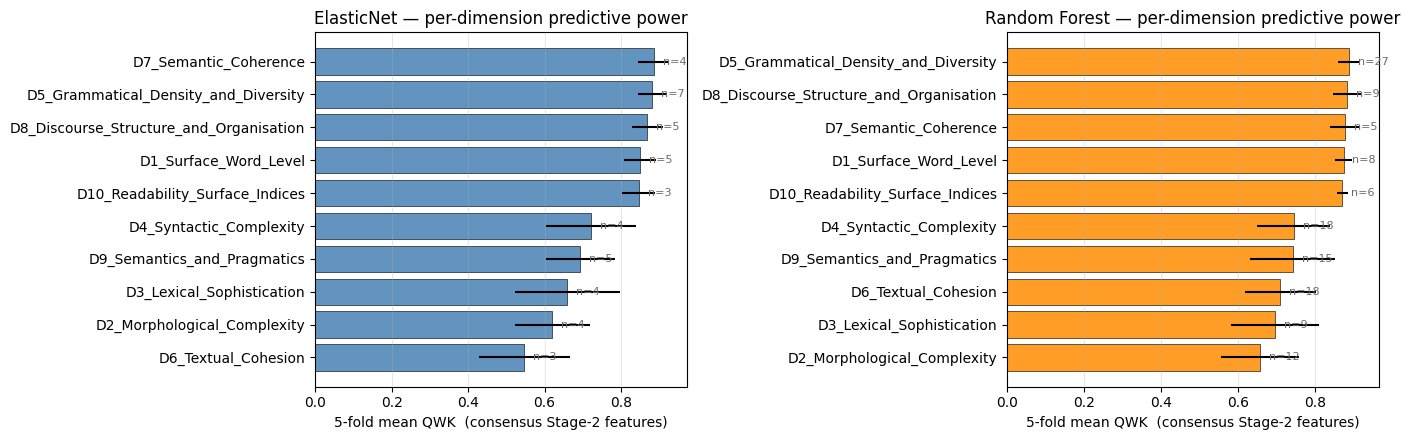


  Saved: /kaggle/working/ckpt/dim_B_consensus_stage2.png, dim_B_consensus_EN.csv, dim_B_consensus_RF.csv
  Exposed: en_consensus, rf_consensus, en_counter, rf_counter,
           dimB_en, dimB_rf, dimB_qwks_en, dimB_qwks_rf


In [70]:
# ============================== DIM-B ==============================
# ─────────────────────────────────────────────────────────────────────────────
# DIM-B — Dimensional classifiers on CONSENSUS Stage-2 features
#
#   For each model M ∈ {EN, RF} independently:
#     consensus(M, D) = features picked by M's Stage-2 in ≥ 3 of 5 folds
#                       for dimension D
#   Then for each (D, M) train one model with FIXED hypers on 5-fold CV using
#   the consensus feature set (same set in every fold) and report mean ± std.
#
#   Difference from DIM-A:
#     DIM-A:  fold-specific features (varies across folds → realistic per-fold)
#     DIM-B:  consensus features    (single stable set per dim → cleaner story)
#
#   Prereqs:  fs_results, outer_splits, feature_groups_present, X_df, y_float,
#             plus DIM-A exposed:  EN_BASE, RF_BASE, y_int, EN_KEY, RF_KEY,
#             plus N_OUTER_FOLDS, RANDOM_STATE, GRADE_MIN, GRADE_MAX, CKPT_DIR
# ─────────────────────────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score

print('=' * 82)
print('  DIM-B — Dimensional classifiers on consensus Stage-2 features')
print('=' * 82)

DIMB_CONSENSUS_THR = 3   # ≥3 of 5 folds, per (model, dim)

dims_all = list(feature_groups_present.keys())

# Dynamic column width based on longest dimension name
COL_W = max(len(d) for d in dims_all) + 2

def _consensus_s2(model_key, dim, thr=DIMB_CONSENSUS_THR):
    c = Counter()
    for k in range(N_OUTER_FOLDS):
        gr = fs_results[model_key][k].get('group_results', {})
        c.update(gr.get(dim, {}).get('s2_features', []) or [])
    return sorted([f for f, n in c.items()
                   if n >= thr and f in X_df.columns]), c

# ── Build consensus sets ───────────────────────────────────────────────────
en_consensus, rf_consensus = {}, {}
en_counter,   rf_counter   = {}, {}

SEP1 = '─' * (COL_W + 23)
print(f'\n  Consensus threshold: ≥ {DIMB_CONSENSUS_THR} of {N_OUTER_FOLDS} folds\n')
print(f'  {"Dimension":<{COL_W}} {"EN n_feat":>10} {"RF n_feat":>10}')
print('  ' + SEP1)
for d in dims_all:
    en_consensus[d], en_counter[d] = _consensus_s2(EN_KEY, d)
    rf_consensus[d], rf_counter[d] = _consensus_s2(RF_KEY, d)
    print(f'  {d:<{COL_W}} {len(en_consensus[d]):>10} {len(rf_consensus[d]):>10}')
print('  ' + SEP1)

# ── Evaluate each (D, M) via 5-fold CV with consensus feats ────────────────
def _cv_eval(feats, model_kind):
    if not feats:
        return dict(Acc_m=np.nan, Acc_s=np.nan, W1_m=np.nan, W1_s=np.nan,
                    QWK_m=np.nan, QWK_s=np.nan, F1m_m=np.nan, F1m_s=np.nan,
                    n_feat=0, qwks=[np.nan]*N_OUTER_FOLDS)
    Xv = X_df[feats].values
    accs, w1s, qwks, f1s = [], [], [], []
    for tr, te in outer_splits:
        if model_kind == 'EN':
            p = Pipeline([('sc', StandardScaler()), ('clf', clone(EN_BASE))])
            p.fit(Xv[tr], y_float[tr])
            yp = np.clip(np.rint(p.predict(Xv[te])).astype(int),
                         GRADE_MIN, GRADE_MAX)
        else:
            p = Pipeline([('sc', StandardScaler()), ('clf', clone(RF_BASE))])
            p.fit(Xv[tr], y_int[tr])
            yp = p.predict(Xv[te]).astype(int)
        yt = y_int[te]
        accs.append(accuracy_score(yt, yp))
        w1s .append(float(np.mean(np.abs(yt - yp) <= 1)))
        qwks.append(cohen_kappa_score(yt, yp, weights='quadratic'))
        f1s .append(f1_score(yt, yp, average='macro', zero_division=0))
    return dict(
        Acc_m=np.mean(accs), Acc_s=np.std(accs, ddof=1),
        W1_m =np.mean(w1s ), W1_s =np.std(w1s , ddof=1),
        QWK_m=np.mean(qwks), QWK_s=np.std(qwks, ddof=1),
        F1m_m=np.mean(f1s ), F1m_s=np.std(f1s , ddof=1),
        n_feat=len(feats), qwks=qwks,
    )

rows_en, rows_rf = [], []
for d in dims_all:
    en_m = _cv_eval(en_consensus[d], 'EN')
    rf_m = _cv_eval(rf_consensus[d], 'RF')
    rows_en.append({'Dimension': d, **en_m})
    rows_rf.append({'Dimension': d, **rf_m})

dimB_en = (pd.DataFrame(rows_en).drop(columns='qwks')
            .sort_values('QWK_m', ascending=False, na_position='last')
            .reset_index(drop=True))
dimB_rf = (pd.DataFrame(rows_rf).drop(columns='qwks')
            .sort_values('QWK_m', ascending=False, na_position='last')
            .reset_index(drop=True))

# Per-fold QWK (kept aside for plotting)
dimB_qwks_en = {r['Dimension']: r['qwks'] for r in rows_en}
dimB_qwks_rf = {r['Dimension']: r['qwks'] for r in rows_rf}

# ── Print tables ───────────────────────────────────────────────────────────
def _fmt(m, s):
    """Always returns a fixed 13-char string so every column stays aligned."""
    if np.isnan(m):
        return f'{"NaN":>13}'
    return f'{m:.3f}±{s:.3f}'.rjust(13)

SEP2 = '─' * (COL_W + 74)

def _print(df, label):
    print(f'\n  {label} — consensus Stage-2 features (5-fold CV, mean ± std)')
    print('  ' + SEP2)
    print(f'  {"Dimension":<{COL_W}} {"n_feat":>6}  {"Acc":>13}  {"W1":>13}  {"QWK":>13}  {"F1m":>13}')
    print('  ' + SEP2)
    for _, r in df.iterrows():
        print(
            f"  {r['Dimension']:<{COL_W}} {int(r['n_feat']):>6}"
            f"  {_fmt(r['Acc_m'], r['Acc_s'])}"
            f"  {_fmt(r['W1_m'],  r['W1_s'])}"
            f"  {_fmt(r['QWK_m'], r['QWK_s'])}"
            f"  {_fmt(r['F1m_m'], r['F1m_s'])}"
        )
    print('  ' + SEP2)

_print(dimB_en, 'ElasticNet')
_print(dimB_rf, 'Random Forest')

# ── Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.45 * len(dims_all))))
for ax, df, label, color in zip(
    axes, [dimB_en, dimB_rf], ['ElasticNet', 'Random Forest'],
    ['steelblue', 'darkorange']
):
    valid = df.dropna(subset=['QWK_m']).copy()
    y = np.arange(len(valid))
    ax.barh(y, valid['QWK_m'], xerr=valid['QWK_s'].fillna(0),
            color=color, alpha=0.85, edgecolor='black', linewidth=0.5)
    for yp, q, n in zip(y, valid['QWK_m'], valid['n_feat']):
        ax.text(max(0, q) + 0.005, yp, f'  n={int(n)}',
                va='center', fontsize=8, color='dimgray')
    ax.set_yticks(y); ax.set_yticklabels(valid['Dimension']); ax.invert_yaxis()
    ax.set_xlabel('5-fold mean QWK  (consensus Stage-2 features)')
    ax.set_title(f'{label} — per-dimension predictive power')
    ax.axvline(0, color='black', linewidth=0.7); ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
out_png = os.path.join(CKPT_DIR, 'dim_B_consensus_stage2.png')
plt.savefig(out_png, dpi=150, bbox_inches='tight'); plt.show()

dimB_en.to_csv(os.path.join(CKPT_DIR, 'dim_B_consensus_EN.csv'), index=False)
dimB_rf.to_csv(os.path.join(CKPT_DIR, 'dim_B_consensus_RF.csv'), index=False)
print(f'\n  Saved: {out_png}, dim_B_consensus_EN.csv, dim_B_consensus_RF.csv')
print('  Exposed: en_consensus, rf_consensus, en_counter, rf_counter,')
print('           dimB_en, dimB_rf, dimB_qwks_en, dimB_qwks_rf')

  DIM-C — Forward cumulative dimensional ablation

  ElasticNet — adding dimensions best-first (cumulative consensus pool)
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────
    #  + Added dimension                         cum_feat            Acc             W1            QWK            F1m       ΔQWK
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────
    1  + D7_Semantic_Coherence                            4    0.420±0.158    0.942±0.049    0.886±0.040    0.398±0.167          —
    2  + D5_Grammatical_Density_and_Diversity            11    0.396±0.100    0.942±0.028    0.885±0.026    0.377±0.116    -0.0011
    3  + D8_Discourse_Structure_and_Organisation         16    0.449±0.149    0.948±0.037    0.900±0.042    0.428±0.169    +0.0150
    4  + D1_Surface_Word_Level                           21    0.454±0.117    0.942±0.040    0.899±0.036    0.435±0.141    -0.0

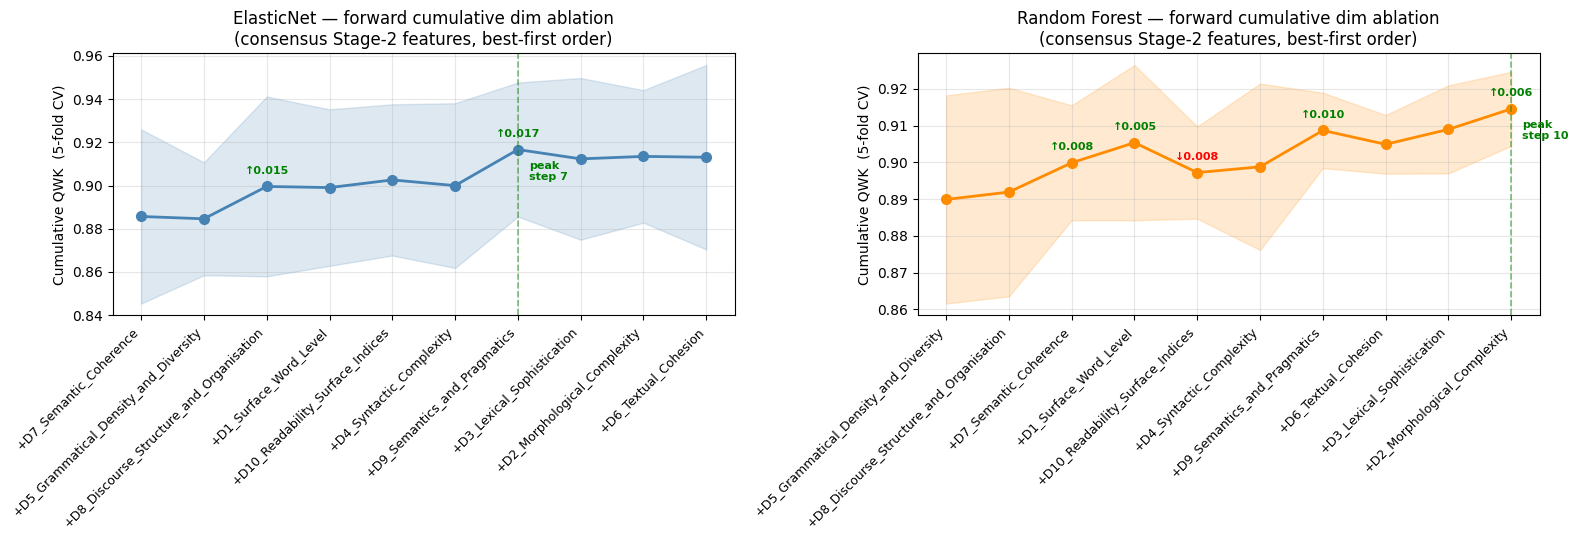


  Saved: /kaggle/working/ckpt/dim_C_forward_cumulative.png, dim_C_cumulative_EN.csv, dim_C_cumulative_RF.csv
  Exposed: dimC_en, dimC_rf


In [71]:
# ============================== DIM-C ==============================
# ─────────────────────────────────────────────────────────────────────────────
# DIM-C — Forward cumulative dimensional ablation  (consensus Stage-2 features)
#
#   For each model M ∈ {EN, RF}:
#     1. Order dimensions by their DIM-B mean QWK (best first).
#     2. Add dimensions one at a time, accumulating consensus features.
#     3. Retrain (fixed hyper) via 5-fold CV at each step.
#     4. Report cumulative QWK and Δ from previous step.
#        Negative Δ ⇒ that dim hurts when added.
#
#   Identifies the "peak set" — minimum dim combo that achieves the model's
#   ceiling — and any harmful additions.
#
#   Prereqs:  DIM-B exposes en_consensus, rf_consensus, dimB_en, dimB_rf
# ─────────────────────────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score

print('=' * 82)
print('  DIM-C — Forward cumulative dimensional ablation')
print('=' * 82)

# Dynamic column width based on longest dimension name
COL_W = max(len(d) for d in dims_all) + 2

def _cv_eval_feats(feats, model_kind):
    if not feats:
        return dict(Acc_m=np.nan, Acc_s=np.nan, W1_m=np.nan, W1_s=np.nan,
                    QWK_m=np.nan, QWK_s=np.nan, F1m_m=np.nan, F1m_s=np.nan)
    Xv = X_df[feats].values
    accs, w1s, qwks, f1s = [], [], [], []
    for tr, te in outer_splits:
        if model_kind == 'EN':
            p = Pipeline([('sc', StandardScaler()), ('clf', clone(EN_BASE))])
            p.fit(Xv[tr], y_float[tr])
            yp = np.clip(np.rint(p.predict(Xv[te])).astype(int),
                         GRADE_MIN, GRADE_MAX)
        else:
            p = Pipeline([('sc', StandardScaler()), ('clf', clone(RF_BASE))])
            p.fit(Xv[tr], y_int[tr])
            yp = p.predict(Xv[te]).astype(int)
        yt = y_int[te]
        accs.append(accuracy_score(yt, yp))
        w1s .append(float(np.mean(np.abs(yt - yp) <= 1)))
        qwks.append(cohen_kappa_score(yt, yp, weights='quadratic'))
        f1s .append(f1_score(yt, yp, average='macro', zero_division=0))
    return dict(
        Acc_m=np.mean(accs), Acc_s=np.std(accs, ddof=1),
        W1_m =np.mean(w1s ), W1_s =np.std(w1s , ddof=1),
        QWK_m=np.mean(qwks), QWK_s=np.std(qwks, ddof=1),
        F1m_m=np.mean(f1s ), F1m_s=np.std(f1s , ddof=1),
    )

def _fmt(m, s):
    """Always returns a fixed 13-char string so every column stays aligned."""
    if np.isnan(m):
        return f'{"NaN":>13}'
    return f'{m:.3f}±{s:.3f}'.rjust(13)

def _forward(order, consensus_map, model_kind, label):
    SEP = '─' * (COL_W + 70)
    print(f'\n  {label} — adding dimensions best-first (cumulative consensus pool)')
    print('  ' + SEP)
    print(f'  {"#":>3}  {"+ Added dimension":<{COL_W}} {"cum_feat":>8}'
          f'  {"Acc":>13}  {"W1":>13}  {"QWK":>13}  {"F1m":>13}  {"ΔQWK":>9}')
    print('  ' + SEP)

    rows = []
    cum_feats, cum_dims, prev_qwk = [], [], None

    for step, d in enumerate(order, 1):
        cum_dims.append(d)
        for f in consensus_map.get(d, []):
            if f not in cum_feats:
                cum_feats.append(f)
        m = _cv_eval_feats(cum_feats, model_kind)
        d_qwk = (
            (m['QWK_m'] - prev_qwk)
            if (prev_qwk is not None
                and not np.isnan(m['QWK_m'])
                and not np.isnan(prev_qwk))
            else 0.0
        )
        if not np.isnan(m['QWK_m']):
            prev_qwk = m['QWK_m']
        rows.append({
            'Step': step, 'Added_dimension': d,
            'Cumulative_dims': ' + '.join(cum_dims),
            'n_feat_cum': len(cum_feats), **m, 'delta_QWK': d_qwk,
        })
        delta_s = f'{"—":>9}' if step == 1 else f'{d_qwk:>+9.4f}'
        print(
            f'  {step:>3}  + {d:<{COL_W}} {len(cum_feats):>8}'
            f'  {_fmt(m["Acc_m"], m["Acc_s"])}'
            f'  {_fmt(m["W1_m"],  m["W1_s"])}'
            f'  {_fmt(m["QWK_m"], m["QWK_s"])}'
            f'  {_fmt(m["F1m_m"], m["F1m_s"])}'
            f'  {delta_s}'
        )

    print('  ' + SEP)
    df = pd.DataFrame(rows)
    df['Role'] = 'neutral'
    df.loc[df['Step'] == 1, 'Role'] = 'baseline'
    df.loc[(df['Step'] > 1) & (df['delta_QWK'] >  0.005), 'Role'] = 'helps'
    df.loc[(df['Step'] > 1) & (df['delta_QWK'] < -0.005), 'Role'] = 'hurts'
    return df

en_order = dimB_en.dropna(subset=['QWK_m'])['Dimension'].tolist()
rf_order = dimB_rf.dropna(subset=['QWK_m'])['Dimension'].tolist()

dimC_en = _forward(en_order, en_consensus, 'EN', 'ElasticNet')
dimC_rf = _forward(rf_order, rf_consensus, 'RF', 'Random Forest')

# ── Peak set + harmful dims ────────────────────────────────────────────────
SEP_PEAK = '─' * 82
print(f'\n  {SEP_PEAK}')
print('  PEAK ANALYSIS')
print(f'  {SEP_PEAK}')
for label, df in [('ElasticNet', dimC_en), ('Random Forest', dimC_rf)]:
    if df['QWK_m'].dropna().empty:
        print(f'  {label}: (no valid runs)')
        continue
    peak_idx = df['QWK_m'].idxmax()
    peak     = df.loc[peak_idx]
    final    = df.iloc[-1]
    print(f'  {label}:')
    print(f"    Peak QWK  : {peak['QWK_m']:.4f}  "
          f"at step {int(peak['Step']):>2}  ({peak['Cumulative_dims']})")
    print(f"    Final QWK : {final['QWK_m']:.4f}  "
          f"at step {int(final['Step']):>2}  (all dims)")
    drop = final['QWK_m'] - peak['QWK_m']
    if drop < -0.005:
        print(f'    → Dimensions added AFTER peak hurt cumulative QWK by {-drop:.4f}')
    hurt = df[df['Role'] == 'hurts']
    if len(hurt):
        print('    Harmful dims (ΔQWK < −0.005):')
        for _, r in hurt.iterrows():
            print(f'      + {r["Added_dimension"]:<{COL_W}}  ΔQWK = {r["delta_QWK"]:+.4f}')
    else:
        print('    No individually harmful additions.')
    print()
print(f'  {SEP_PEAK}')

# ── Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, df, label, color in zip(
    axes, [dimC_en, dimC_rf], ['ElasticNet', 'Random Forest'],
    ['steelblue', 'darkorange']
):
    valid = df.dropna(subset=['QWK_m'])
    ax.plot(valid['Step'], valid['QWK_m'], 'o-', color=color, lw=2, markersize=7)
    ax.fill_between(valid['Step'],
                    valid['QWK_m'] - valid['QWK_s'].fillna(0),
                    valid['QWK_m'] + valid['QWK_s'].fillna(0),
                    alpha=0.18, color=color)
    if not valid.empty:
        peak = valid.loc[valid['QWK_m'].idxmax()]
        ax.axvline(peak['Step'], color='green', linestyle='--', alpha=0.5, lw=1.2)
        ax.annotate(f"peak\nstep {int(peak['Step'])}",
                    xy=(peak['Step'], peak['QWK_m']),
                    xytext=(8, -22), textcoords='offset points',
                    fontsize=8, color='green', fontweight='bold')
    ax.set_xticks(df['Step'])
    ax.set_xticklabels([f"+{d}" for d in df['Added_dimension']],
                       rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('Cumulative QWK  (5-fold CV)')
    ax.set_title(f'{label} — forward cumulative dim ablation\n'
                  '(consensus Stage-2 features, best-first order)')
    ax.grid(True, alpha=0.3)
    for _, r in df.iterrows():
        if r['Step'] == 1 or np.isnan(r['QWK_m']): continue
        if abs(r['delta_QWK']) < 0.005: continue
        arrow = '↑' if r['delta_QWK'] > 0 else '↓'
        col   = 'green' if r['delta_QWK'] > 0 else 'red'
        ax.annotate(f"{arrow}{abs(r['delta_QWK']):.3f}",
                    xy=(r['Step'], r['QWK_m']),
                    xytext=(0, 9), textcoords='offset points',
                    fontsize=8, ha='center', color=col, fontweight='bold')
plt.tight_layout()
out_png = os.path.join(CKPT_DIR, 'dim_C_forward_cumulative.png')
plt.savefig(out_png, dpi=150, bbox_inches='tight'); plt.show()

dimC_en.to_csv(os.path.join(CKPT_DIR, 'dim_C_cumulative_EN.csv'), index=False)
dimC_rf.to_csv(os.path.join(CKPT_DIR, 'dim_C_cumulative_RF.csv'), index=False)
print(f'\n  Saved: {out_png}, dim_C_cumulative_EN.csv, dim_C_cumulative_RF.csv')
print('  Exposed: dimC_en, dimC_rf')

  DIM-D — Stage-3 consensus feature study  (importance + grade signal)

  Stage-3 consensus (≥3/5 folds):
    EN: 13   RF: 65
    EN ∩ RF: 12

  ElasticNet — top 13 Stage-3 consensus features (of 13)
  --------------------------------------------------------------------------------------------------------------
    #  Feature                     Dim      folds  importance      %       ρ   G2    G3    G4    G5    G6    G7    G8  
    1.  metaphor_density            D9          5/5      0.3346  15.7%  +0.716   0.17  0.23  0.28  0.30  0.34  0.35  0.35
    2.  BRich15_S                   D8          4/5      0.3098  14.5%  +0.796   26.94  26.71  33.37  40.12  43.88  49.47  49.16
    3.  BTopc10_S                   D8          5/5      0.2598  12.2%  +0.868   16.19  18.00  22.29  27.41  31.11  36.42  37.58
    4.  DESSLd                      D4          5/5      0.2554  12.0%  +0.766   3.18  4.52  4.70  5.54  6.36  8.15  8.46
    5.  simp_adp_var                D5          4/5      0.2448  

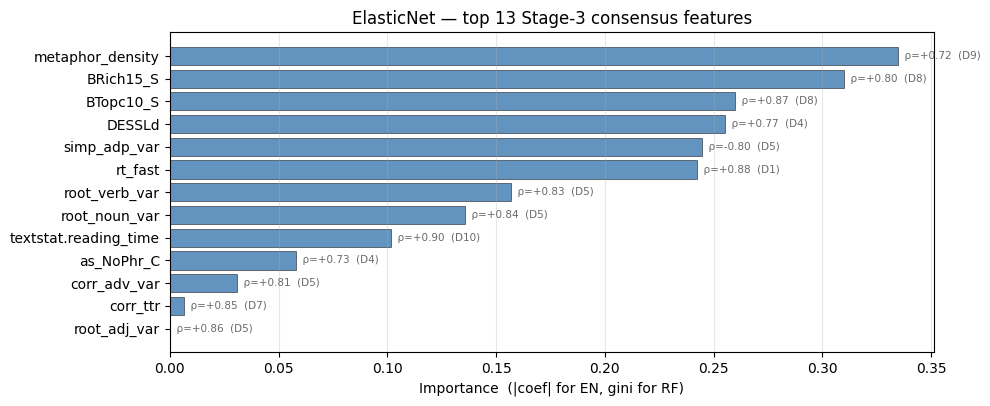

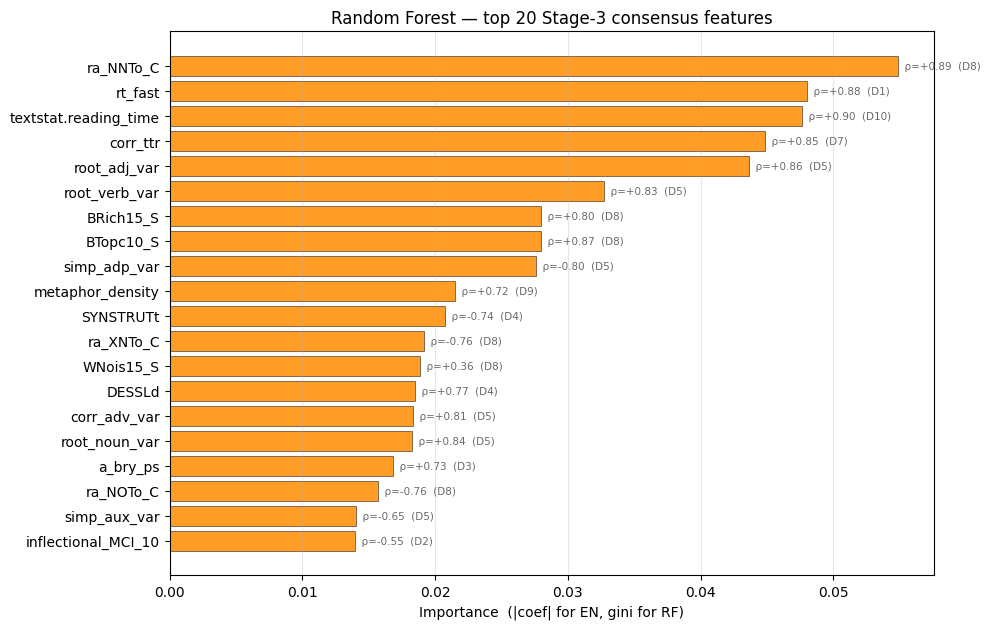

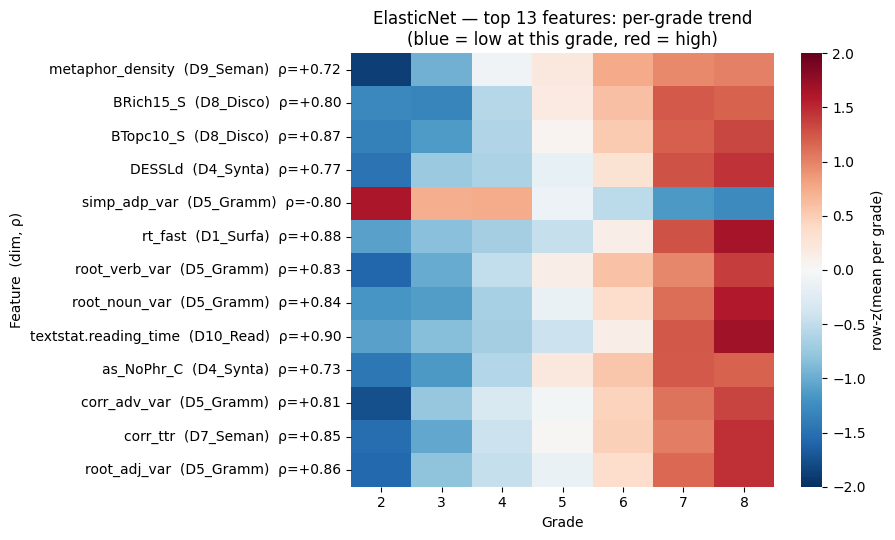

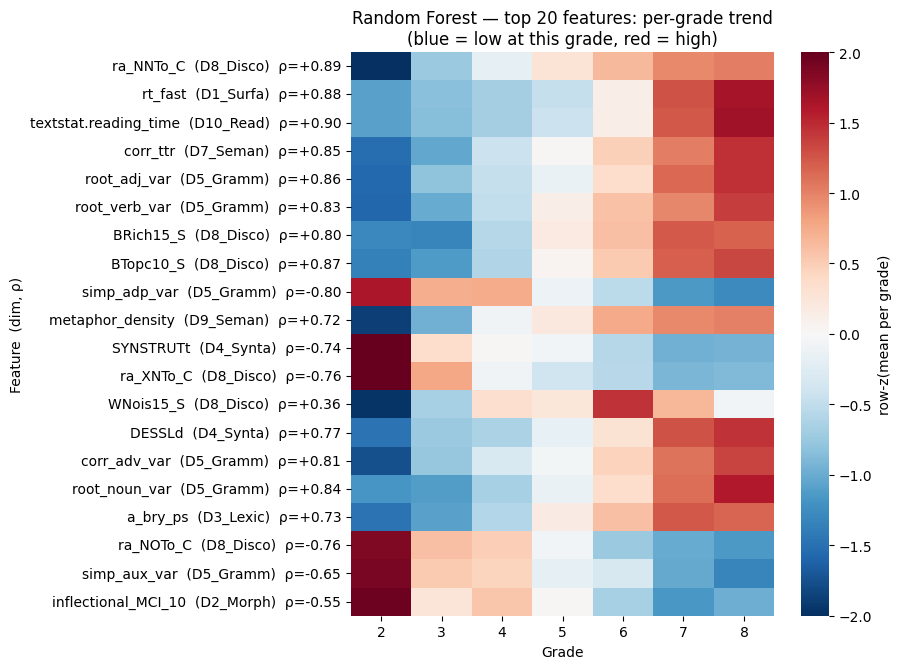


  Saved: dim_D_features_{EN,RF}.csv, dim_D_byDim_{EN,RF}.csv,
         dim_D_top_importance_{EN,RF}.png, dim_D_trend_{EN,RF}.png
  Exposed: dimD_en, dimD_rf, dimD_en_byDim, dimD_rf_byDim,
           en_s3_consensus, rf_s3_consensus, en_s3_counts, rf_s3_counts


In [72]:
# ============================== DIM-D ==============================
# ─────────────────────────────────────────────────────────────────────────────
# DIM-D — Stage-3 feature study  (importance + grade correlation + trends)
#
#   For each model M ∈ {EN, RF} independently:
#     stage3_consensus(M) = features in fs_results[M][k]['final_features']
#                            for ≥ 3 of 5 folds
#     Train M with FIXED hypers on the FULL data using consensus features →
#     extract feature importance (|coef| for EN, feature_importances_ for RF)
#     Pair with:
#       - dimension
#       - Spearman ρ with grade
#       - per-grade mean (to show the trend)
#       - fold-stability count out of 5
#
#   Reports top-N table per model + per-dimension importance breakdown.
#
#   Prereqs:  DIM-A exposes EN_BASE, RF_BASE, y_int, EN_KEY, RF_KEY.
#             Plus fs_results, feature_groups_present, X_df, y_float,
#             GRADE_MIN, GRADE_MAX, N_OUTER_FOLDS, CKPT_DIR.
# ─────────────────────────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print('=' * 80)
print('  DIM-D — Stage-3 consensus feature study  (importance + grade signal)')
print('=' * 80)

DIMD_THR = 3       # consensus = ≥ 3 of 5 folds
TOP_N    = 30      # how many features in the ranked table per model

# ── feature → dimension reverse lookup ─────────────────────────────────────
feat_to_dim = {}
for dim, sgs in feature_groups_present.items():
    for sg in sgs.values():
        for f in sg:
            feat_to_dim.setdefault(f, dim)

# ── Stage-3 fold-occurrence counts per model ───────────────────────────────
def _stage3_counts(model_key):
    c = Counter()
    for k in range(N_OUTER_FOLDS):
        c.update(fs_results[model_key][k].get('final_features', []) or [])
    return c

en_s3_counts = _stage3_counts(EN_KEY)
rf_s3_counts = _stage3_counts(RF_KEY)
en_s3_consensus = sorted([f for f, n in en_s3_counts.items()
                          if n >= DIMD_THR and f in X_df.columns])
rf_s3_consensus = sorted([f for f, n in rf_s3_counts.items()
                          if n >= DIMD_THR and f in X_df.columns])

print(f'\n  Stage-3 consensus (≥{DIMD_THR}/{N_OUTER_FOLDS} folds):')
print(f'    EN: {len(en_s3_consensus)}   RF: {len(rf_s3_consensus)}')
print(f'    EN ∩ RF: {len(set(en_s3_consensus) & set(rf_s3_consensus))}')

# ── Train each model with fixed hypers on FULL data, get importances ──────
grade_arr  = np.arange(GRADE_MIN, GRADE_MAX + 1)
grade_cols = [f'mean_G{g}' for g in grade_arr]

def _per_grade_means(vals):
    out = {}
    for g in grade_arr:
        m = (y_int == g)
        out[f'mean_G{g}'] = float(np.mean(vals[m])) if m.sum() else np.nan
    return out

def _build_table(feats, model_kind, fold_counts):
    if not feats:
        return pd.DataFrame()
    Xv = X_df[feats].values
    pipe = Pipeline([('sc', StandardScaler()),
                     ('clf', clone(EN_BASE if model_kind == 'EN' else RF_BASE))])
    pipe.fit(Xv, y_float if model_kind == 'EN' else y_int)
    clf = pipe.named_steps['clf']
    if model_kind == 'EN':
        imp = np.abs(np.ravel(clf.coef_))
    else:
        imp = clf.feature_importances_
    rows = []
    for i, f in enumerate(feats):
        vals = X_df[f].values.astype(float)
        rho, _ = spearmanr(vals, y_float, nan_policy='omit')
        rows.append({
            'Feature'     : f,
            'Dimension'   : feat_to_dim.get(f, '(unknown)'),
            'importance'  : float(imp[i]),
            'spearman_rho': float(rho) if not np.isnan(rho) else 0.0,
            'n_folds'     : int(fold_counts.get(f, 0)),
            **_per_grade_means(vals),
        })
    df = pd.DataFrame(rows)
    df['imp_norm'] = df['importance'] / df['importance'].sum() \
                     if df['importance'].sum() > 0 else df['importance']
    return df.sort_values('importance', ascending=False).reset_index(drop=True)

dimD_en = _build_table(en_s3_consensus, 'EN', en_s3_counts)
dimD_rf = _build_table(rf_s3_consensus, 'RF', rf_s3_counts)

# ── Print top-N per model ──────────────────────────────────────────────────
def _print_top(df, label, n=TOP_N):
    if df.empty:
        print(f'\n  {label}: no consensus features.'); return
    print(f'\n  {label} — top {min(n, len(df))} Stage-3 consensus features '
          f'(of {len(df)})')
    print('  ' + '-' * 110)
    print(f'  {"#":>3}  {"Feature":<28}{"Dim":<8}{"folds":>6}'
          f'{"importance":>12}{"%":>7}{"ρ":>8}   '
          + '  '.join(f'G{g:<3}' for g in grade_arr))
    cum = 0.0
    for i, r in df.head(n).iterrows():
        cum += r['imp_norm']
        code = r['Dimension'].split('_')[0]
        grades_str = '  '.join(f'{r[f"mean_G{g}"]:>4.2f}' for g in grade_arr)
        print(f"  {i+1:>3}.  {str(r['Feature'])[:27]:<28}{code:<8}"
              f"{r['n_folds']:>5}/5{r['importance']:>12.4f}{r['imp_norm']*100:>6.1f}%"
              f"{r['spearman_rho']:>+8.3f}   {grades_str}")
    print(f'  {"":<3}  cumulative % of total importance in top-{n}: {cum*100:.1f}%')

_print_top(dimD_en, 'ElasticNet')
_print_top(dimD_rf, 'Random Forest')

# ── Per-dimension importance share ─────────────────────────────────────────
def _dim_share(df):
    if df.empty: return pd.DataFrame()
    g = (df.groupby('Dimension')
          .agg(n_features=('Feature','count'),
               imp_sum   =('importance','sum'),
               imp_mean  =('importance','mean'),
               rho_mean  =('spearman_rho', lambda s: float(np.mean(np.abs(s)))))
          .sort_values('imp_sum', ascending=False))
    g['imp_share_%'] = 100 * g['imp_sum'] / g['imp_sum'].sum()
    return g

dimD_en_byDim = _dim_share(dimD_en)
dimD_rf_byDim = _dim_share(dimD_rf)

def _print_byDim(df, label):
    if df.empty: return
    print(f'\n  {label} — per-dimension importance share')
    print('  ' + '-' * 78)
    print(f'  {"Dimension":<25}{"n_feat":>8}{"Σ imp":>11}'
          f'{"share %":>10}{"mean imp":>11}{"mean |ρ|":>11}')
    for d, r in df.iterrows():
        print(f'  {d:<25}{int(r["n_features"]):>8}'
              f'{r["imp_sum"]:>11.4f}{r["imp_share_%"]:>9.1f}%'
              f'{r["imp_mean"]:>11.4f}{r["rho_mean"]:>11.3f}')
_print_byDim(dimD_en_byDim, 'ElasticNet')
_print_byDim(dimD_rf_byDim, 'Random Forest')

# ── Plot 1: top-20 importance bars per model ───────────────────────────────
def _bar_top(df, label, color, fname, n=20):
    if df.empty: return None
    top = df.head(min(n, len(df))).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, max(4, 0.32 * len(top))))
    y = np.arange(len(top))
    ax.barh(y, top['importance'], color=color, alpha=0.85,
            edgecolor='black', linewidth=0.4)
    for yp, (_, r) in zip(y, top.iterrows()):
        ax.text(r['importance'], yp, f'  ρ={r["spearman_rho"]:+.2f}'
                f'  ({r["Dimension"].split("_")[0]})',
                va='center', fontsize=7.5, color='dimgray')
    ax.set_yticks(y); ax.set_yticklabels([f[:32] for f in top['Feature']])
    ax.set_xlabel('Importance  (|coef| for EN, gini for RF)')
    ax.set_title(f'{label} — top {len(top)} Stage-3 consensus features')
    ax.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    out = os.path.join(CKPT_DIR, fname)
    plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
    return out

_bar_top(dimD_en, 'ElasticNet',    'steelblue',  'dim_D_top_importance_EN.png')
_bar_top(dimD_rf, 'Random Forest', 'darkorange', 'dim_D_top_importance_RF.png')

# ── Plot 2: per-grade trend heatmap for top-20 (row-z) ─────────────────────
def _trend_heatmap(df, label, fname, n=20):
    if df.empty: return None
    top = df.head(min(n, len(df))).copy()
    mat = top[grade_cols].values.astype(float)
    rs  = mat.std(axis=1, keepdims=True); rs = np.where(rs == 0, 1, rs)
    z   = (mat - mat.mean(axis=1, keepdims=True)) / rs
    fig, ax = plt.subplots(figsize=(9, max(5.5, 0.34 * len(top))))
    sns.heatmap(z, annot=False, cmap='RdBu_r', center=0, vmin=-2, vmax=2,
                xticklabels=[str(g) for g in grade_arr],
                yticklabels=[f"{r['Feature'][:24]}  ({r['Dimension'][:8]})  "
                              f"ρ={r['spearman_rho']:+.2f}"
                              for _, r in top.iterrows()],
                ax=ax, cbar_kws={'label': 'row-z(mean per grade)'})
    ax.set_xlabel('Grade'); ax.set_ylabel('Feature  (dim, ρ)')
    ax.set_title(f'{label} — top {len(top)} features: per-grade trend\n'
                  '(blue = low at this grade, red = high)')
    plt.tight_layout()
    out = os.path.join(CKPT_DIR, fname)
    plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
    return out

_trend_heatmap(dimD_en, 'ElasticNet',    'dim_D_trend_EN.png')
_trend_heatmap(dimD_rf, 'Random Forest', 'dim_D_trend_RF.png')

# ── Save CSVs ──────────────────────────────────────────────────────────────
dimD_en      .to_csv(os.path.join(CKPT_DIR, 'dim_D_features_EN.csv'),       index=False)
dimD_rf      .to_csv(os.path.join(CKPT_DIR, 'dim_D_features_RF.csv'),       index=False)
dimD_en_byDim.to_csv(os.path.join(CKPT_DIR, 'dim_D_byDim_EN.csv'))
dimD_rf_byDim.to_csv(os.path.join(CKPT_DIR, 'dim_D_byDim_RF.csv'))

print('\n  Saved: dim_D_features_{EN,RF}.csv, dim_D_byDim_{EN,RF}.csv,')
print('         dim_D_top_importance_{EN,RF}.png, dim_D_trend_{EN,RF}.png')
print('  Exposed: dimD_en, dimD_rf, dimD_en_byDim, dimD_rf_byDim,')
print('           en_s3_consensus, rf_s3_consensus, en_s3_counts, rf_s3_counts')